## prepare

In [3]:
# # clear 
# import re
# G = globals()
# todel = []
# for i in G.keys():
#     r = re.match("_i{0,1}\d+",i)
#     if r:
#         todel.append(i)
# for i in todel:
#     del G[i]

In [324]:
## ------- edit params first here --------------

# COSMIC_VER = ['v2','v3']
COSMIC_VER = 'v2'
WES_DB = 'xy-wes'
RNA_DB = 'xy-rna'
WORKER = None

INPUTROOT = 'export_c3'
OUTPUTROOT = 'report_c3'

# ------------------------------------------------

DBLIBPATH = '[GCpytools_path]'
# RPLOTLIB = '[lib_path]/yutils.R'
# RPLOTLIB = '[lib_path]/yplot.R'

# ------------- optional --------------------------
## utils for plotting
# import seaborn as sns
# sns.set(color_codes=True)
# from matplotlib import pyplot as plt
# from glob import glob

# utils for os.path
from os.path import join as J
from os.path import exists as E
from os import listdir as L
print('global L,E,J is defined')

#---------------- setup PATHs -------------------
## setup WORKDIR
import os
# Change WORKDIR working directory depend on your projext location
WORKDIR = os.getcwd()

## setup OUTPUTPATH and WOKER
import sys

# SET OUTPUT DIR
OUTPUTPATH = os.path.join(WORKDIR,OUTPUTROOT)

if DBLIBPATH not in sys.path:
    sys.path.insert(0,DBLIBPATH)

if WORKDIR != '' :
    if  os.path.exists(WORKDIR):
        os.chdir(WORKDIR)
    else:
        raise ValueError(f'WORKDIR path {WORKDIR} do not exist.')


## setup WOKER
# from dalibs import yglobal
# BASE_HTTP = yglobal.conf['META']['BASE_URL']
# if WORKER is not None:
#     WORKER = yglobal.ypull_current_worker()

# def getcwdurl():
#     p = WORKDIR.replace('[JUP_ROOT]/',BASE_HTTP)
#     print(p)
WORKER = None

#---------------- load librarys -------------------



## to reload modules
# import dalibs
# import importlib
# importlib.reload(dalibs)

## set up db
from dblibs import *
db = Database(outputdir = OUTPUTROOT,input_dir = INPUTROOT, set_used_db=WES_DB)
echo.set(6, reset_col=50)
del OUTPUTPATH

#---------------------------------------------------
# getcwdurl()
print(f'[info] Current Worker is >> {WORKER} << working @',os.getcwd())


from tqdm.notebook import tqdm

import re

db

global L,E,J is defined
⚠ set default global used db to [xy-wes]
[info] Current Worker is >> None << working @ [PROJECT_ROOT]/ALLNEW_PLOTS/DATA_AVA


Log_system(outputdir="report_c3",input_dir="export_c3", use_full_path=True)
  cur_db_key = xy-wes
  OUTPUTDIR = report_c3
  INPUTDIR = export_c3
  Verbose = True

In [301]:
# for r python mash up
# import rpy2
import rpy2.robjects as robjects
import rpy2.robjects.lib.ggplot2 as ggplot2
%load_ext rpy2.ipython

renv = robjects.globalenv
# the same as %R -i OUTPUTROOT,OUTPUTPATH
renv['OUTPUTROOT'] = OUTPUTROOT
renv['INPUTROOT'] = INPUTROOT
# renv['OUTPUTPATH']=OUTPUTPATH
renv['COSMIC_VER'] = COSMIC_VER
if WORKER is None:
    renv['WORKER'] = robjects.NULL
else:
    renv['WORKER'] = WORKER
print('🔄 load GCrutils')
robjects.r['library']('GCrutils')

[python_env]/lib/pythonX/site-packages/rpy2/robjects/lib/ggplot2.py:70: UserWarning: This was designed against ggplot2 versions starting with 3.3. but you have 3.4.4
  warnings.warn(
R[write to console]: Loading required package: magrittr

R[write to console]: 
Attaching package: ‘magrittr’


R[write to console]: The following object is masked from ‘package:rlang’:

    set_names


R[write to console]: Loading required package: dplyr

R[write to console]: 
Attaching package: ‘dplyr’


R[write to console]: The following objects are masked from ‘package:stats’:

    filter, lag


R[write to console]: The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


R[write to console]: Loading required package: stringr

R[write to console]: Loading required package: tibble

R[write to console]: Loading required package: ggfortify



🔄 load GCrutils


'GCrutils','ggfortify','tibble',...,'datasets','methods','base'


In [354]:
# write_excel({'patient_info_86':glx},'patient_info_age',outputdir=OUTPUTROOT)
# append #1 Sheet [patient_info_86]
# writing 1 .xls @ report_big/patient_info_age.xlsx

In [351]:
glx = db.importing('export_c3/glx_86.dfx')
glx

[09/06 01:55:34]reading export_c3/glx_86.dfx


,tsb,Group,Response
0,P72,C1,non.pCR
1,P10,C1,non.pCR
2,P14,C1,non.pCR
...,...,...,...
83,P78,pCR,pCR
84,P76,pCR,pCR
85,P79,pCR,pCR


In [353]:
glx['Group'].value_counts().sort_index()

Group
C1     21
C2     22
C3     34
pCR     9
Name: count, dtype: int64

In [359]:
cc = db.importing('data/export_c3/fig1_subtype_column_cluster.dfx')
cc['cc'].value_counts().sort_index()

[09/06 02:01:46]reading data/export_c3/fig1_subtype_column_cluster.dfx


cc
C1     21
C2     22
C3     34
pCR     9
Name: count, dtype: int64

## gen colnames, convert

In [20]:
ob = db.importing('external_info/Glycosylation/Quant.spectra.list',nrows=10)
colnames = pd.Series(ob.columns[ob.columns.str.startswith('ReportIon')])
colnames = {i:i[11:-1] for i in colnames} 
colnames


[01/22 07:14:37]reading external_info/Glycosylation/Quant.spectra.list


{'ReportIon (114.1277)': '114.1277',
 'ReportIon (115.1248)': '115.1248',
 'ReportIon (115.1311)': '115.1311',
 'ReportIon (116.1281)': '116.1281',
 'ReportIon (116.1344)': '116.1344',
 'ReportIon (117.1315)': '117.1315',
 'ReportIon (117.1378)': '117.1378',
 'ReportIon (118.1348)': '118.1348',
 'ReportIon (118.1411)': '118.1411',
 'ReportIon (119.1382)': '119.1382',
 'ReportIon (119.1445)': '119.1445',
 'ReportIon (120.1415)': '120.1415',
 'ReportIon (120.1479)': '120.1479',
 'ReportIon (121.1449)': '121.1449',
 'ReportIon (121.1512)': '121.1512',
 'ReportIon (122.1482)': '122.1482'}

In [ ]:
'external_info/Phosphorylation/'

In [10]:
pho_pro = db.importing('external_info/Phosphorylation/protein_FFPE_phos_msfragger.tsv')
pho_psm = db.importing('external_info/Phosphorylation/psm_FFPE_phos_msfragger.tsv')

[11/28 02:27:08]reading external_info/Phosphorylation/protein_FFPE_phos_msfragger.tsv
[11/28 02:27:08]reading external_info/Phosphorylation/psm_FFPE_phos_msfragger.tsv


In [34]:
pho_psm['Modified Peptide'].str[:6].u()

array(['n[278]', 'n[320]'], dtype=object)

In [30]:
x = pd.Series(pho_psm['Assigned Modifications'].u())
x[x.str.contains('S').fillna(False)]


Series([], dtype: object)

In [11]:
pho_psm

,Spectrum,Spectrum File,Peptide,Modified Peptide,Extended Peptide,Prev AA,Next AA,Peptide Length,Charge,Retention,Observed Mass,Calibrated Observed Mass,Observed M/Z,Calibrated Observed M/Z,Calculated Peptide Mass,Calculated M/Z,Delta Mass,SpectralSim,RTScore,Expectation,Hyperscore,Nextscore,PeptideProphet Probability,Number of Enzymatic Termini,Number of Missed Cleavages,Protein Start,Protein End,Intensity,Assigned Modifications,Observed Modifications,Compensation Voltage,Is Unique,Protein,Protein ID,Entry Name,Gene,Protein Description,Mapped Genes,Mapped Proteins
0,20231011-FangPan-P-PE-1_1.03531.03531.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-PHOS-...,QQSDHDAER,n[278]QQSDHDAER,VQTIEIQR.QQSDHDAER.REAIAEIL,R,L,9,3,793.4156,1361.6458,1361.6431,454.8892,454.8883,1361.6414,454.8877,0.0017,0.8300,-1.0986,2.978516e-02,13.604,0.000,0.8894,2,0,2576,2584,0.0,N-term(277.1881),NaN,-65,True,sp|Q15149|PLEC_HUMAN,Q15149,PLEC_HUMAN,PLEC,Plectin,NaN,NaN
1,20231011-FangPan-P-PE-1_1.03666.03666.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-PHOS-...,QGSGSGQSPGHGQR,n[278]QGSGSGQSPGHGQR,SQSSGYGR.QGSGSGQSPGHGQR.SGSRQSPG,R,G,14,3,818.0372,1615.7948,1615.7896,539.6055,539.6038,1615.7905,539.6041,-0.0009,0.7807,-1.0895,6.799860e-03,10.170,0.000,0.9179,2,0,1118,1131,0.0,N-term(277.1881),NaN,-45,True,sp|Q86YZ3|HORN_HUMAN,Q86YZ3,HORN_HUMAN,HRNR,Hornerin,NaN,NaN
2,20231011-FangPan-P-PE-1_1.04039.04039.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-PHOS-...,HHPEHFSGR,n[278]HHPEHFSGR,TITGYRIR.HHPEHFSGR.REDRVPHP,R,P,9,3,891.3877,1379.6936,1379.6908,460.9051,460.9042,1379.6937,460.9052,-0.0029,0.8050,-1.0356,2.301442e-02,16.052,9.098,0.9114,2,0,1483,1491,0.0,N-term(277.1881),NaN,-65,True,sp|P02751|FINC_HUMAN,P02751,FINC_HUMAN,FN1,Fibronectin,NaN,NaN
3,20231011-FangPan-P-PE-1_1.04731.04731.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-PHOS-...,HHPEHFSGRPR,n[278]HHPEHFSGRPR,TITGYRIR.HHPEHFSGRPR.DRVPHSRE,R,E,11,3,1004.6403,1632.8535,1632.8486,545.2918,545.2901,1632.8475,545.2898,0.0011,0.8704,-1.1597,1.156113e-03,21.248,8.384,0.9931,2,1,1483,1493,0.0,N-term(277.1881),NaN,-45,True,sp|P02751|FINC_HUMAN,P02751,FINC_HUMAN,FN1,Fibronectin,NaN,NaN
4,20231011-FangPan-P-PE-1_1.04912.04912.4,D:\CooperationProject\TangGuyu_FFPE\FFPE-PHOS-...,SHEESHKE,n[278]SHEESHKE,MGVAAHKK.SHEESHKE.,K,-,8,4,1031.3758,1535.7944,1535.7913,384.9559,384.9551,1535.7914,384.9551,-0.0001,0.7295,-0.9927,1.638256e-05,24.196,10.757,0.9986,2,1,86,93,0.0,"7K(277.1881), N-term(277.1881)",NaN,-45,True,sp|P05109|S10A8_HUMAN,P05109,S10A8_HUMAN,S100A8,Protein S100-A8,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
186112,20231011-FangPan-P-PE-6_5.81224.81224.4,D:\CooperationProject\TangGuyu_FFPE\FFPE-PHOS-...,YADFSISPNAVSAEEDGYTLFVAGFEDGGAGDSLSYHSGQK,n[278]YADFSISPNAVSAEEDGYTLFVAGFEDGGAGDSLSYHSGQK,ENNTAYAK.YADFSISPNAVSAEEDGYTLFVAGFEDGGAGDSLSYH...,K,F,41,4,10674.0994,4814.2666,4814.2700,1204.5739,1204.5748,4812.2690,1204.0745,2.0009,0.6166,0.4601,1.607712e-06,19.973,11.305,0.9986,2,0,144,184,0.0,"41K(277.1881), N-term(277.1881)",NaN,-45,True,sp|P55083|MFAP4_HUMAN,P55083,MFAP4_HUMAN,MFAP4,Microfibril-associated glycoprotein 4,NaN,NaN
186113,20231011-FangPan-P-PE-6_5.81410.81410.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-PHOS-...,YGGLHFSDQVEVFSPPGSDR,n[278]YGGLHFSDQVEVFSPPGSDR,DQVAISWR.YGGLHFSDQVEVFSPPGSDR.SFIKNIQA,R,A,20,3,10703.1592,2470.2000,2470.2007,824.4073,824.4075,2470.2007,824.4075,0.0000,0.7143,2.0999,3.013007e-04,22.584,0.000,0.9578,2,0,96,115,0.0,N-term(277.1881),NaN,-65,True,sp|P12110|CO6A2_HUMAN,P12110,CO6A2_HUMAN,COL6A2,Collagen alpha-2(VI) chain,NaN,NaN
186114,20231011-FangPan-P-PE-6_5.81676.81676.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-PHOS-...,SADFVVEAIGDDVGTLGFSVEGPSQAK,n[278]SADFVVEAIGDDVGTLGFSVEGPSQAK,IEGGVVGK.SADFVVEAIGDDVGTLGFSVEGPSQAK.ECDDKGDI,K,I,27,3,10745.4831,3248.6700,3248.6743,1083.8973,1083.8987,3248.6785,1083.9001,-0.0041,0.8094,0.7894,1.280119e-04,26.071,0.000,

In [9]:
gly_pro = db.importing('external_info/Glycosylation/protein-FFPE-Glyco.tsv')
gly_psm = db.importing('external_info/Glycosylation/psm-FFPE-Glyco.tsv')
gly_psm


[11/28 02:27:07]reading external_info/Glycosylation/protein-FFPE-Glyco.tsv
[11/28 02:27:07]reading external_info/Glycosylation/psm-FFPE-Glyco.tsv


,Spectrum,Spectrum File,Peptide,Modified Peptide,Extended Peptide,Prev AA,Next AA,Peptide Length,Charge,Retention,Observed Mass,Calibrated Observed Mass,Observed M/Z,Calibrated Observed M/Z,Calculated Peptide Mass,Calculated M/Z,Delta Mass,Expectation,Hyperscore,Nextscore,PeptideProphet Probability,Number of Enzymatic Termini,Number of Missed Cleavages,Protein Start,Protein End,Intensity,Assigned Modifications,Observed Modifications,Glycan Score,Glycan q-value,MSFragger Localization,Best Score with Delta Mass,Best Score without Delta Mass,Compensation Voltage,Is Unique,Protein,Protein ID,Entry Name,Gene,Protein Description,Mapped Genes,Mapped Proteins
0,20230814-FP-Nglyco-PE-1_1.03293.03293.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-IBT16...,NLHQSNTSR,n[278]NLHQSN[2174]TSR,GVYICTCR.NLHQSNTSR.EIIVTEAA,R,A,9,3,1146.9117,3392.4390,3392.4390,1131.8203,1131.8203,3392.4339,1131.8185,0.0052,6.270414e-03,31.032,17.566,0.9880,2,0,1750,1758,0.0,"N-term(277.1881), 6N(2059.7350)",HexNAc(4)Hex(5)Fuc(1)NeuAc(1) % 2059.7350,-0.85,0.005208,NLHQSNTSR,27.926510,31.032574,-45,True,sp|P98160|PGBM_HUMAN,P98160,PGBM_HUMAN,HSPG2,Basement membrane-specific heparan sulfate pro...,NaN,NaN
1,20230814-FP-Nglyco-PE-1_1.03455.03455.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-IBT16...,NGTDGQK,n[278]N[1493]GTDGQK,GAPGIAGK.NGTDGQK.KIGRIGPG,K,G,7,3,1192.4354,2651.1836,2651.1836,884.7351,884.7351,2651.1765,884.7327,0.0070,9.879842e-04,24.521,13.388,0.9877,2,0,327,333,0.0,"7K(277.1881), N-term(277.1881), 1N(1378.4757)",HexNAc(2)Hex(6) % 1378.4757,4.13,0.000000,nGTDGQK,24.521080,22.407198,-65,True,sp|P12110|CO6A2_HUMAN,P12110,CO6A2_HUMAN,COL6A2,Collagen alpha-2(VI) chain,NaN,NaN
2,20230814-FP-Nglyco-PE-1_1.03477.03477.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-IBT16...,EEQYNSTYR,n[278]EEQYN[1721]STYR,HNAKTKPR.EEQYNSTYR.VSVITVIV,R,V,9,3,1199.2055,3072.2886,3072.2886,1025.1035,1025.1035,3072.2794,1025.1003,0.0091,2.081915e-03,23.677,11.617,0.9896,2,0,176,184,0.0,"N-term(277.1881), 5N(1606.5867)",HexNAc(4)Hex(4)Fuc(1) % 1606.5867,-1.76,0.078351,EEQYNSTYR,22.130035,23.677456,-65,False,sp|P01857|IGHG1_HUMAN,P01857,IGHG1_HUMAN,IGHG1,Immunoglobulin heavy constant gamma 1,NaN,sp|P0DOX5|IGG1_HUMAN
3,20230814-FP-Nglyco-PE-1_1.04078.04078.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-IBT16...,CQNTTSVEK,n[278]CQN[1883]TTSVEK,MKSPFYR.CQNTTSVEK.NSAVMGGG,R,G,9,3,1380.2734,3388.4832,3388.4832,1130.5017,1130.5017,3388.4919,1130.5045,-0.0088,2.420471e-08,16.171,15.716,1.0000,2,0,8,16,0.0,"1C(57.0214), 9K(277.1881), N-term(277.1881), 3...",HexNAc(4)Hex(5)Fuc(1) % 1768.6396,-3.00,0.199446,CQNTTSVEK,13.607430,16.171300,-45,True,sp|Q13258|PD2R_HUMAN,Q13258,PD2R_HUMAN,PTGDR,Prostaglandin D2 receptor,NaN,NaN
4,20230814-FP-Nglyco-PE-1_1.04125.04125.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-IBT16...,THANGSIK,n[278]THAN[1883]GSIK,DFIYWSDR.THANGSIK.GSKDNATR,R,R,8,3,1394.5096,3149.4575,3149.4575,1050.8264,1050.8264,3149.4455,1050.8224,0.0120,1.335712e-04,30.051,15.643,0.9977,2,0,2114,2121,0.0,"8K(277.1881), N-term(277.1881), 4N(1768.6396)",HexNAc(4)Hex(5)Fuc(1) % 1768.6396,-2.56,0.109402,THANGSIK,25.320961,30.051212,-65,True,sp|Q07954|LRP1_HUMAN,Q07954,LRP1_HUMAN,LRP1,Prolow-density lipoprotein receptor-related pr...,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1237,20230814-FP-Nglyco-PE-6_5.39268.39268.3,D:\CooperationProject\TangGuyu_FFPE\FFPE-IBT16...,YLGNATAIFFLPDEGK,n[278]YLGN[2028]ATAIFFLPDEGK,SSWVIIMK.YLGNATAIFFLPDEGK.QHIENEIL,K,L,16,3,9416.3279,4222.9253,4222.9253,1408.6490,1408.6490,4222.9413,1408.6544,-0.0160,8.072960e-09,30.154,11.791,1.0000,2,0,268,283,0.0,"16K(277.1881), N-term(277.1881), 4N(1913.6771)",HexNAc(4)Hex(5)NeuAc(1) % 1913.6771,1.03,0.000000,YLGnATAIFFLPDEGK,30.154438,28.626850,-45,True,sp|P01009|A1AT_HUMAN,P01009,A1AT_HUMAN,SERPINA1,Alpha-1-antitrypsin,NaN,NaN
1238,20230814-FP-Nglyco-PE-6_5.40075.40075.3,D:\CooperationProject\TangGuyu_FF

In [4]:
pt.columns

Index(['Protein', 'Protein ID', 'Entry Name', 'Gene', 'Length', 'Organism',
       'Protein Description', 'Protein Existence', 'Coverage',
       'Protein Probability', 'Top Peptide Probability', 'Total Peptides',
       'Unique Peptides', 'Razor Peptides', 'Total Spectral Count',
       'Unique Spectral Count', 'Razor Spectral Count', 'Total Intensity',
       'Unique Intensity', 'Razor Intensity', 'Razor Assigned Modifications',
       'Razor Observed Modifications', 'Indistinguishable Proteins'],
      dtype='object')

In [7]:
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
glx['uid'] = glx['uid'].astype("str")

convert = db.importing('external_info/Glycosylation/报告离子对应样品编号修改.xlsx')
x = convert['编号'].str.split('-',expand=True)
x.columns = ['batch','x1','x2']
convert = pd.concat([convert, x], axis = 1)

convert['uid'] = convert['uid'].fillna(0).astype('int').astype("str")
convert.loc[convert['uid']=="0",'uid'] = 'p'# + convert.loc[convert['uid']=="0",'batch']
convert['ReporterMass'] = convert['ReporterMass'].astype('str')
convert = pd.merge(convert,glx[['Custom_Label','uid','Protein_Cluster','Response']], on ='uid',how="left")
convert['Custom_Label'] = convert['Custom_Label'].fillna('p')
convert['batch'] = convert['batch'].astype(str)
convert

 

[01/08 05:30:52]reading export_by2_86_pCR_nonpCR/wes_glx.dfx
[01/08 05:30:52]reading external_info/Glycosylation/报告离子对应样品编号修改.xlsx
  read the 0 / 1 sheet named [Sheet1]


,编号,uid,IBT标记试剂,ReporterMass,batch,x1,x2,Custom_Label,Protein_Cluster,Response
0,1-1,1468488,IBT16-114,114.1277,1,1,None,P74,pCR,pCR
1,1-2,1342531,IBT16-115N,115.1248,1,2,None,P52,C1,non.pCR
2,1-3,1413323,IBT16-115C,115.1311,1,3,None,P31,C4,non.pCR
3,1-4,1416254,IBT16-116N,116.1281,1,4,None,P64,pCR,pCR
4,1-5,1446865,IBT16-116C,116.1344,1,5,None,P19,C3,non.pCR
...,...,...,...,...,...,...,...,...,...,...
91,6-12,1416255,IBT16-120N,120.1415,6,12,None,P63,C2,non.pCR
92,6-13,1457065,IBT16-120C,120.1479,6,13,None,P12,C4,non.pCR
93,6-14,1452554,IBT16-121N,121.1449,6,14,None,P14,C1,non.pCR
94,6-15,1366983,IBT16-121C,121.1512,6,15,None,P46,C2,non.pCR


In [4]:
db.exporting(convert,'gly_convert_batch',outputdir='export_big/',index=False)

[11/06 08:43:41] overwritting 1 file with 96 lines at 
	[PROJECT_ROOT]/export_big/gly_convert_batch.dfx


'[PROJECT_ROOT]/export_big/gly_convert_batch.dfx'

,key,value
0,ReportIon (114.1277),114.1277
1,ReportIon (115.1248),115.1248
2,ReportIon (115.1311),115.1311
3,ReportIon (116.1281),116.1281
4,ReportIon (116.1344),116.1344
...,...,...
11,ReportIon (120.1415),120.1415
12,ReportIon (120.1479),120.1479
13,ReportIon (121.1449),121.1449
14,ReportIon (121.1512),121.1512


In [9]:
db.exporting(pd.DataFrame({"key":colnames.keys()
                           , "value":colnames.values()})
             ,'glx_helper_cols_ori',outputdir='export_big/',index=False)

[11/06 08:45:42] writing 1 file with 16 lines at 
	[PROJECT_ROOT]/export_big/glx_helper_cols_ori.dfx


'[PROJECT_ROOT]/export_big/glx_helper_cols_ori.dfx'

In [77]:
import dill

## pivot ob

### 整理蛋白组-蛋白量数据-求和

In [2]:
ob = db.importing('external_info/Glycosylation/Quant.spectra.list',nrows=10)
colnames = pd.Series(ob.columns[ob.columns.str.startswith('ReportIon')])
colnames = {i:i[11:-1] for i in colnames} 
colnames


[03/28 01:14:07]reading external_info/Glycosylation/Quant.spectra.list


{'ReportIon (114.1277)': '114.1277',
 'ReportIon (115.1248)': '115.1248',
 'ReportIon (115.1311)': '115.1311',
 'ReportIon (116.1281)': '116.1281',
 'ReportIon (116.1344)': '116.1344',
 'ReportIon (117.1315)': '117.1315',
 'ReportIon (117.1378)': '117.1378',
 'ReportIon (118.1348)': '118.1348',
 'ReportIon (118.1411)': '118.1411',
 'ReportIon (119.1382)': '119.1382',
 'ReportIon (119.1445)': '119.1445',
 'ReportIon (120.1415)': '120.1415',
 'ReportIon (120.1479)': '120.1479',
 'ReportIon (121.1449)': '121.1449',
 'ReportIon (121.1512)': '121.1512',
 'ReportIon (122.1482)': '122.1482'}

In [3]:
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
glx['uid'] = glx['uid'].astype("str")

convert = db.importing('external_info/Glycosylation/报告离子对应样品编号修改.xlsx')
x = convert['编号'].str.split('-',expand=True)
x.columns = ['batch','x1','x2']
convert = pd.concat([convert, x], axis = 1)

convert['uid'] = convert['uid'].fillna(0).astype('int').astype("str")
convert.loc[convert['uid']=="0",'uid'] = 'p'# + convert.loc[convert['uid']=="0",'batch']
convert['ReporterMass'] = convert['ReporterMass'].astype('str')
convert = pd.merge(convert,glx[['Custom_Label','uid','Protein_Cluster','Response']], on ='uid',how="left")
convert['Custom_Label'] = convert['Custom_Label'].fillna('p')
convert['batch'] = convert['batch'].astype(str)
convert

 

[03/28 01:14:08]reading export_by2_86_pCR_nonpCR/wes_glx.dfx
[03/28 01:14:08]reading external_info/Glycosylation/报告离子对应样品编号修改.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


,编号,uid,IBT标记试剂,ReporterMass,batch,x1,x2,Custom_Label,Protein_Cluster,Response
0,1-1,1468488,IBT16-114,114.1277,1,1,None,P74,pCR,pCR
1,1-2,1342531,IBT16-115N,115.1248,1,2,None,P52,C1,non.pCR
2,1-3,1413323,IBT16-115C,115.1311,1,3,None,P31,C4,non.pCR
...,...,...,...,...,...,...,...,...,...,...
93,6-14,1452554,IBT16-121N,121.1449,6,14,None,P14,C1,non.pCR
94,6-15,1366983,IBT16-121C,121.1512,6,15,None,P46,C2,non.pCR
95,6-p,p,IBT16-122,122.1482,6,p,None,p,NaN,NaN


In [130]:
db.exporting(convert, 'convert_sampling_details', outputdir='./export_big')

[03/12 09:11:40] writing 1 file with 96 lines at 
	[PROJECT_ROOT]/./export_big/convert_sampling_details.dfx


In [3]:
proteom = db.importing('external_info/Glycosylation/Quant.spectra-proteomics.list')


[04/27 12:23:23]reading external_info/Glycosylation/Quant.spectra-proteomics.list


In [4]:
proteom

,File_Name,Scan_No,Exp.MH+,Charge,Q-value,Sequence,Calc.MH+,Mass_Shift(Exp.-Calc.),Raw_Score,Final_Score,Modification,Specificity,Proteins,Positions,Label,Target/Decoy,Miss.Clv.Sites,Avg.Frag.Mass.Shift,Others,Supp_Info,Empty_Separator,ReportIon (114.1277),ReportIon (115.1248),ReportIon (115.1311),ReportIon (116.1281),ReportIon (116.1344),ReportIon (117.1315),ReportIon (117.1378),ReportIon (118.1348),ReportIon (118.1411),ReportIon (119.1382),ReportIon (119.1445),ReportIon (120.1415),ReportIon (120.1479),ReportIon (121.1449),ReportIon (121.1512),ReportIon (122.1482),Unnamed: 37
0,20230813-FP-PRO-P-1.29975.29975.4.3.dta,29975,3379.604073,4,0.000000,FWEVISDEHGIDPTGSYHGDSDLQLER,3379.595542,0.008531,38.166399,3.840030e-08,"0,IBT-16-N-term;",3,sp|Q13885|TBB2A_HUMAN/sp|Q9BVA1|TBB2B_HUMAN/,"19,K,I/19,K,I/",1|0|,target,0,0.469495,36,NaN,NaN,4251.7,2629.3,5126.9,6162.9,4212.3,6741.2,5101.1,4151.8,6708.4,4121.2,4935.8,4185.7,7212.9,4915.1,3961.1,3981.4,NaN
1,20230813-FP-PRO-P-1.48318.48318.3.0.dta,48318,3601.842178,3,0.000000,DLGEELEALKTELEDTLDSTATQQELR,3601.866393,-0.024215,35.400384,7.418530e-08,"0,IBT-16-N-term;10,IBT-16-K;",3,sp|P35749|MYH11_HUMAN/,"1142,R,A/",1|0|0|,target,1,-5.864938,100,NaN,NaN,11534.6,2830.6,29808.2,16455.5,31631.6,26081.6,8413.8,17041.7,11641.8,8150.1,11911.5,14572.7,22357.0,34448.3,7736.3,12825.3,NaN
2,20230813-FP-PRO-P-1.26598.26598.3.1.dta,26598,2865.437593,3,0.000000,SMTEAEQQQLIDDHFLFDK,2865.430863,0.006730,40.691869,1.453240e-07,"0,IBT-16-N-term;2,Oxidation[M];19,IBT-16-K;",3,sp|P12277|KCRB_HUMAN/,"177,K,P/",1|0|0|0|,target,0,2.621046,32,NaN,NaN,26815.0,35862.8,45021.4,62491.5,48594.9,52654.3,31488.7,19381.5,86464.5,63323.0,33858.5,31637.8,43899.1,91525.0,50691.1,42051.3,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71520,20230813-FP-PRO-P-6.5712.5712.3.2.dta,5712,1594.965358,3,0.009904,VKAEGPGLNR,1594.960929,0.004429,6.613598,3.876400e-01,"0,IBT-16-N-term;2,IBT-16-K;",3,sp|Q14315|FLNC_HUMAN/,"869,K,T/",1|0|0|,target,1,0.776336,36,NaN,NaN,13718.1,22871.5,10111.0,15312.7,13269.8,27810.1,16537.9,16030.4,10847.5,12093.7,11385.1,14637.7,17964.8,11077.7,14613.0,16544.3,NaN
71521,20230813-FP-PRO-P-6.45809.45809.4.4.dta,45809,2545.448353,4,0.009904,AIENIDTLTNLESLFLGK,2545.445716,0.002637,7.351075,3.881660e-01,"0,IBT-16-N-term;18,IBT-16-K;",3,sp|Q15435|PP1R7_HUMAN/,"199,R,N/",1|0|0|,target,0,3.499905,36,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
71522,20230813-FP-PRO-P-6.30700.30700.3.2.dta,30700,1709.932610,3,0.009904,FFLDRDGFLFR,1709.925265,0.007345,9.519312,3.883230e-01,"0,IBT-16-N-term;",3,sp|Q96CX2|KCD12_HUMAN/sp|Q68DU8|KCD16_HUMAN/sp...,"79,R,Y/72,R,Y/96,R,Y/",1|0|,target,1,-0.889132,104,NaN,NaN,2325.9,0.0,1477.0,2397.6,2250.6,2853.0,1764.7,1254.9,1593.6,0.0,2329.7,1165.9,2590.7,999.1,1543.8,1409.4,NaN


In [126]:
cols2 = ['Proteins', 'Sequence', 'Charge', 'Modification']

proteom = db.importing('external_info/Glycosylation/Quant.spectra-proteomics.list')

ob = proteom
info1 = ob["File_Name"].str.split('.',expand=True)
info1[0] = info1[0].str.replace('_','-')
info = info1[0].str.split('-',expand=True)
info.columns = ['exp_date','tag1','tag2','tag3','batch']
# info1[[0]]
info = pd.concat([ob[['File_Name']],info],axis = 1)

proteom = pd.concat([info.loc[:,info.columns!='File_Name'],proteom],axis=1)

proteom = proteom.rename(columns = colnames)
proteom['PID'] = proteom[cols2].apply(lambda i:":".join(i.astype(str)), axis=1)
proteom



[03/12 09:08:55]reading external_info/Glycosylation/Quant.spectra-proteomics.list


,exp_date,tag1,tag2,tag3,batch,File_Name,Scan_No,Exp.MH+,Charge,Q-value,Sequence,Calc.MH+,Mass_Shift(Exp.-Calc.),Raw_Score,Final_Score,Modification,Specificity,Proteins,Positions,Label,Target/Decoy,Miss.Clv.Sites,Avg.Frag.Mass.Shift,Others,Supp_Info,Empty_Separator,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482,Unnamed: 37,PID
0,20230813,FP,PRO,P,1,20230813-FP-PRO-P-1.29975.29975.4.3.dta,29975,3379.604073,4,0.000000,FWEVISDEHGIDPTGSYHGDSDLQLER,3379.595542,0.008531,38.166399,3.840030e-08,"0,IBT-16-N-term;",3,sp|Q13885|TBB2A_HUMAN/sp|Q9BVA1|TBB2B_HUMAN/,"19,K,I/19,K,I/",1|0|,target,0,0.469495,36,NaN,NaN,4251.7,2629.3,5126.9,6162.9,4212.3,6741.2,5101.1,4151.8,6708.4,4121.2,4935.8,4185.7,7212.9,4915.1,3961.1,3981.4,NaN,sp|Q13885|TBB2A_HUMAN/sp|Q9BVA1|TBB2B_HUMAN/:F...
1,20230813,FP,PRO,P,1,20230813-FP-PRO-P-1.48318.48318.3.0.dta,48318,3601.842178,3,0.000000,DLGEELEALKTELEDTLDSTATQQELR,3601.866393,-0.024215,35.400384,7.418530e-08,"0,IBT-16-N-term;10,IBT-16-K;",3,sp|P35749|MYH11_HUMAN/,"1142,R,A/",1|0|0|,target,1,-5.864938,100,NaN,NaN,11534.6,2830.6,29808.2,16455.5,31631.6,26081.6,8413.8,17041.7,11641.8,8150.1,11911.5,14572.7,22357.0,34448.3,7736.3,12825.3,NaN,sp|P35749|MYH11_HUMAN/:DLGEELEALKTELEDTLDSTATQ...
2,20230813,FP,PRO,P,1,20230813-FP-PRO-P-1.26598.26598.3.1.dta,26598,2865.437593,3,0.000000,SMTEAEQQQLIDDHFLFDK,2865.430863,0.006730,40.691869,1.453240e-07,"0,IBT-16-N-term;2,Oxidation[M];19,IBT-16-K;",3,sp|P12277|KCRB_HUMAN/,"177,K,P/",1|0|0|0|,target,0,2.621046,32,NaN,NaN,26815.0,35862.8,45021.4,62491.5,48594.9,52654.3,31488.7,19381.5,86464.5,63323.0,33858.5,31637.8,43899.1,91525.0,50691.1,42051.3,NaN,"sp|P12277|KCRB_HUMAN/:SMTEAEQQQLIDDHFLFDK:3:0,..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71520,20230813,FP,PRO,P,6,20230813-FP-PRO-P-6.5712.5712.3.2.dta,5712,1594.965358,3,0.009904,VKAEGPGLNR,1594.960929,0.004429,6.613598,3.876400e-01,"0,IBT-16-N-term;2,IBT-16-K;",3,sp|Q14315|FLNC_HUMAN/,"869,K,T/",1|0|0|,target,1,0.776336,36,NaN,NaN,13718.1,22871.5,10111.0,15312.7,13269.8,27810.1,16537.9,16030.4,10847.5,12093.7,11385.1,14637.7,17964.8,11077.7,14613.0,16544.3,NaN,"sp|Q14315|FLNC_HUMAN/:VKAEGPGLNR:3:0,IBT-16-N-..."
71521,20230813,FP,PRO,P,6,20230813-FP-PRO-P-6.45809.45809.4.4.dta,45809,2545.448353,4,0.009904,AIENIDTLTNLESLFLGK,2545.445716,0.002637,7.351075,3.881660e-01,"0,IBT-16-N-term;18,IBT-16-K;",3,sp|Q15435|PP1R7_HUMAN/,"199,R,N/",1|0|0|,target,0,3.499905,36,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,"sp|Q15435|PP1R7_HUMAN/:AIENIDTLTNLESLFLGK:4:0,..."
71522,20230813,FP,PRO,P,6,20230813-FP-PRO-P-6.30700.30700.3.2.dta,30700,1709.932610,3,0.009904,FFLDRDGFLFR,1709.925265,0.007345,9.519312,3.883230e-01,"0,IBT-16-N-term;",3,sp|Q96CX2|KCD12_HUMAN/sp|Q68DU8|KCD16_HUMAN/sp...,"79,R,Y/72,R,Y/96,R,Y/",1|0|,target,1,-0.889132,104,NaN,NaN,2325.9,0.0,1477.0,2397.6,2250.6,2853.0,1764.7,1254.9,1593.6,0.0,2329.7,1165.9,2590.7,999.1,1543.8,1409.4,NaN,sp|Q96CX2|KCD12_HUMAN/sp|Q68DU8|KCD16_HUMAN/sp...


In [26]:
proteom.groupby('batch')[['PID']].describe()

PID                                                               
       count unique                                                top freq
batch                                                                      
1      12620  10223  sp|P02768|ALBU_HUMAN/:LVAASQAALGL:2:0,IBT-16-N...   37
2      12797  10279  sp|P02768|ALBU_HUMAN/:LVAASQAALGL:2:0,IBT-16-N...   28
3      11423   9116  sp|O60814|H2B1K_HUMAN/sp|P06899|H2B1J_HUMAN/sp...   34
4      12016   9625  sp|P02768|ALBU_HUMAN/:LVAASQAALGL:2:0,IBT-16-N...   31
5      11271   9117  sp|O60814|H2B1K_HUMAN/sp|P06899|H2B1J_HUMAN/sp...   28
6      11396   9209  sp|O60814|H2B1K_HUMAN/sp|P06899|H2B1J_HUMAN/sp...   32

In [27]:
proteom.groupby('batch')[['Proteins']].describe()

Proteins                                    
         count unique                     top freq
batch                                             
1        12620   1996  sp|P12111|CO6A3_HUMAN/  386
2        12797   2025  sp|P12111|CO6A3_HUMAN/  365
3        11423   1856  sp|P12111|CO6A3_HUMAN/  377
4        12016   1953  sp|P12111|CO6A3_HUMAN/  371
5        11271   1784  sp|P12111|CO6A3_HUMAN/  362
6        11396   1846  sp|P12111|CO6A3_HUMAN/  377

In [28]:
proteom.batch.dtype

dtype('O')

In [127]:
total = proteom.groupby('batch')[list(colnames.values())].apply(sum, axis=0)
total

,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482
batch,,,,,,,,,,,,,,,,
1,250199921.7,233017529.1,330837352.2,331542714.6,294764386.1,290434992.2,267923577.4,242831167.9,364794682.5,286340066.1,355433052.8,297970587.7,337483482.8,352902911.8,291602370.1,315602540.1
2,302711301.7,205117346.4,247536716.8,269207908.3,290527289.6,352970681.9,348816501.8,444023277.8,261413850.4,212623158.8,191235816.5,299947262.5,278237614.5,332740446.1,335684027.5,272894388.9
3,96870387.0,92983835.2,130111222.2,132136711.3,119029999.1,135256575.6,134386652.9,195919340.2,139043121.4,102152110.3,122070864.1,123241816.0,142366975.3,117698250.9,127275544.9,107887284.1
4,246829207.1,213320479.7,264132122.5,355860883.5,209653813.3,293429166.3,276298109.5,268301350.3,351213438.6,248264845.9,227101194.1,263139963.6,186700297.4,412945229.1,228025520.2,240253101.6
5,167511805.1,142556723.2,245549490.1,260004431.1,211135123.7,225856654.2,220984202.2,201102713.9,253442858.8,210061661.0,261183389.6,293283230.3,138473833.9,235522553.0,230944843.0,240858997.4
6,261240251.1,262260699.6,210833117.8,250876072.0,222808643.3,353169037.3,230729136.9,223852940.2,223156671.7,212447505.4,205152763.0,240538890.5,279702621.4,193511546.3,259524831.5,252010542.6


In [20]:
db.exporting(total,'gly_total_proteins',outputdir='export_big/',index=True)

[11/06 08:47:07] overwritting 1 file with 6 lines at 
	[PROJECT_ROOT]/export_big/gly_total_proteins.dfx


'[PROJECT_ROOT]/export_big/gly_total_proteins.dfx'

### load 上样总蛋白

In [4]:
total = db.importing('gly_total_proteins',frm='export_big',index_col=0)
total.index = total.index.astype('str')
total

[03/28 01:14:17]reading export_big/gly_total_proteins.dfx


,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482
batch,,,,,,,,,,,,,,,,
1,250199921.7,233017529.1,330837352.2,331542714.6,294764386.1,290434992.2,267923577.4,242831167.9,364794682.5,286340066.1,355433052.8,297970587.7,337483482.8,352902911.8,291602370.1,315602540.1
2,302711301.7,205117346.4,247536716.8,269207908.3,290527289.6,352970681.9,348816501.8,444023277.8,261413850.4,212623158.8,191235816.5,299947262.5,278237614.5,332740446.1,335684027.5,272894388.9
3,96870387.0,92983835.2,130111222.2,132136711.3,119029999.1,135256575.6,134386652.9,195919340.2,139043121.4,102152110.3,122070864.1,123241816.0,142366975.3,117698250.9,127275544.9,107887284.1
4,246829207.1,213320479.7,264132122.5,355860883.5,209653813.3,293429166.3,276298109.5,268301350.3,351213438.6,248264845.9,227101194.1,263139963.6,186700297.4,412945229.1,228025520.2,240253101.6
5,167511805.1,142556723.2,245549490.1,260004431.1,211135123.7,225856654.2,220984202.2,201102713.9,253442858.8,210061661.0,261183389.6,293283230.3,138473833.9,235522553.0,230944843.0,240858997.4
6,261240251.1,262260699.6,210833117.8,250876072.0,222808643.3,353169037.3,230729136.9,223852940.2,223156671.7,212447505.4,205152763.0,240538890.5,279702621.4,193511546.3,259524831.5,252010542.6


In [207]:
convert = db.importing('convert_sampling_details',frm='./export_big/')
convert

[07/26 07:57:35]reading ./export_big/convert_sampling_details.dfx


,Unnamed: 0,编号,uid,IBT标记试剂,ReporterMass,batch,x1,x2,Custom_Label,Protein_Cluster,Response
0,0,1-1,1468488,IBT16-114,114.1277,1,1,NaN,P74,pCR,pCR
1,1,1-2,1342531,IBT16-115N,115.1248,1,2,NaN,P52,C1,non.pCR
2,2,1-3,1413323,IBT16-115C,115.1311,1,3,NaN,P31,C4,non.pCR
...,...,...,...,...,...,...,...,...,...,...,...
93,93,6-14,1452554,IBT16-121N,121.1449,6,14,NaN,P14,C1,non.pCR
94,94,6-15,1366983,IBT16-121C,121.1512,6,15,NaN,P46,C2,non.pCR
95,95,6-p,p,IBT16-122,122.1482,6,p,NaN,p,NaN,NaN


## 糖基化搜库

In [213]:
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
glx['uid'] = glx['uid'].astype("str")
glx


[07/26 07:59:07]reading export_by2_86_pCR_nonpCR/wes_glx.dfx


,Tumor_Sample_Barcode,a,t,p,uid,Custom_Label,ap,PSA,Treat_Res,NEPC,Cribriform,Group,Response,Response2,Clin_classification,RNA_Cluster,Protein_Cluster,Cluster,endocrine_therapy,therapy_month,ARi_type,Thpy_class,PSA_class,tsb,new_tsb
0,P001,K00143,TR22030713,P010143142842401,1428424,P01,K00143P010143142842401,0.019,1,1,0,C4,non.pCR,I,1,C3,C4,C4,戈舍瑞林+阿比特龙+泼尼松,6,2,>3,≤0.2,P01,P001
1,P002,K00144,TR22030669,P010144144820001,1448200,P02,K00144P010144144820001,0.024,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3,≤0.2,P02,P002
2,P003,K00145,TR22030670,P010145141850101,1418501,P03,K00145P010145141850101,0.006,1,0,0,C3,non.pCR,I,1,C3,C3,C3,戈舍瑞林+比卡鲁胺,18,1,>3,≤0.2,P03,P003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,P084,K00267,TR22303734,P010267145448901,1454489,P84,K00267P010267145448901,0.246,1,0,0,C2,non.pCR,I,1,C2,C2,C2,戈舍瑞林+比卡鲁胺,3,1,≤3,>0.2,P84,P084
84,P085,K00268,TR22303735,P010268147734101,1477341,P85,K00268P010268147734101,0.711,2,0,0,C2,non.pCR,II,2,C2,C2,C2,地加瑞克,3,1,≤3,>0.2,P85,P085
85,P086,K00269,TR22303748,P010269148140701,1481407,P86,K00269P010269148140701,0.051,1,0,0,C2,non.pCR,I,1,C4,C2,C2,戈舍瑞林+比卡鲁胺,4,1,>3,≤0.2,P86,P086


In [261]:
total = db.importing('gly_total_proteins',frm='export_big',index_col=0)
# total.index = total.index.astype('str')
total.index = total.index.astype(str)
total


[07/26 08:36:56]reading export_big/gly_total_proteins.dfx


,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482
batch,,,,,,,,,,,,,,,,
1,250199921.7,233017529.1,330837352.2,331542714.6,294764386.1,290434992.2,267923577.4,242831167.9,364794682.5,286340066.1,355433052.8,297970587.7,337483482.8,352902911.8,291602370.1,315602540.1
2,302711301.7,205117346.4,247536716.8,269207908.3,290527289.6,352970681.9,348816501.8,444023277.8,261413850.4,212623158.8,191235816.5,299947262.5,278237614.5,332740446.1,335684027.5,272894388.9
3,96870387.0,92983835.2,130111222.2,132136711.3,119029999.1,135256575.6,134386652.9,195919340.2,139043121.4,102152110.3,122070864.1,123241816.0,142366975.3,117698250.9,127275544.9,107887284.1
4,246829207.1,213320479.7,264132122.5,355860883.5,209653813.3,293429166.3,276298109.5,268301350.3,351213438.6,248264845.9,227101194.1,263139963.6,186700297.4,412945229.1,228025520.2,240253101.6
5,167511805.1,142556723.2,245549490.1,260004431.1,211135123.7,225856654.2,220984202.2,201102713.9,253442858.8,210061661.0,261183389.6,293283230.3,138473833.9,235522553.0,230944843.0,240858997.4
6,261240251.1,262260699.6,210833117.8,250876072.0,222808643.3,353169037.3,230729136.9,223852940.2,223156671.7,212447505.4,205152763.0,240538890.5,279702621.4,193511546.3,259524831.5,252010542.6


In [262]:
convert = db.importing('external_info/Glycosylation/报告离子对应样品编号修改.xlsx')
x = convert['编号'].str.split('-',expand=True)
x.columns = ['batch','x1','x2']
convert = pd.concat([convert, x], axis = 1)

convert['uid'] = convert['uid'].fillna(0).astype('int').astype("str")
convert.loc[convert['uid']=="0",'uid'] = 'p'# + convert.loc[convert['uid']=="0",'batch']
convert['ReporterMass'] = convert['ReporterMass'].astype('str')
convert = pd.merge(convert,glx[['Custom_Label','uid','Protein_Cluster','Response']], on ='uid',how="left")
convert['Custom_Label'] = convert['Custom_Label'].fillna('p')
# convert['repeat'] = convert['x1']
convert



[07/26 08:36:56]reading external_info/Glycosylation/报告离子对应样品编号修改.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


,编号,uid,IBT标记试剂,ReporterMass,batch,x1,x2,Custom_Label,Protein_Cluster,Response
0,1-1,1468488,IBT16-114,114.1277,1,1,None,P74,pCR,pCR
1,1-2,1342531,IBT16-115N,115.1248,1,2,None,P52,C1,non.pCR
2,1-3,1413323,IBT16-115C,115.1311,1,3,None,P31,C4,non.pCR
...,...,...,...,...,...,...,...,...,...,...
93,6-14,1452554,IBT16-121N,121.1449,6,14,None,P14,C1,non.pCR
94,6-15,1366983,IBT16-121C,121.1512,6,15,None,P46,C2,non.pCR
95,6-p,p,IBT16-122,122.1482,6,p,None,p,NaN,NaN


### 糖基化 pGlyco

In [232]:
ob = db.importing('external_info/Glycosylation/Quant.spectra.list')

colnames = pd.Series(ob.columns[ob.columns.str.startswith('ReportIon')])
colnames = {i:i[11:-1] for i in colnames} 
colnames

ob.rename(columns=colnames,inplace=True)
ob


[07/26 08:15:48]reading external_info/Glycosylation/Quant.spectra.list


,GlySpec,PepSpec,RawName,Scan,RT,PrecursorMH,PrecursorMZ,Charge,Rank,Peptide,Mod,PeptideMH,"Glycan(H,N,A,F)",GlycanComposition,PlausibleStruct,GlyID,GlyFrag,GlyMass,GlySite,TotalScore,PepScore,GlyScore,CoreMatched,MassDeviation,PPM,...,PeptidePEP,PeptideFDR,TotalFDR,Proteins,Genes,ProSites,Supp_Info,Empty_Separator,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482,Unnamed: 57
0,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,20230712-SHL-1-P-1-E,27788,5495.40180,3027.41167,1009.80874,3,1,DIYTFDGALJK,"1,IBT16[N-term];11,IBT16[K];",1810.99200,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H)(H))))),2257,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,10,56.27865,83.45758,5.80349,4,-0.00319,-1.05335,...,-1,0.0,1.253530e-23,sp|Q08722|CD47_HUMAN;sp|Q08722-2|CD47_HUMAN;sp...,CD47;CD4;CD4;CD4,73;73;73;73,NaN,NaN,6328.4,5855.7,5993.8,9606.8,8828.8,10270.8,8168.7,7105.4,8386.6,10720.7,8898.5,6564.0,10625.8,8508.0,11454.9,8290.0,NaN
1,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,20230712-SHL-1-P-1-E,26727,5289.04465,3219.54850,1073.85435,3,1,AGPJGTLFVADAYK,"1,IBT16[N-term];14,IBT16[K];",1978.09786,3 3 0 1,H(3)N(3)F(1),(N(N(H(H)(H(N(F)))))),2266,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 3 0 ...,1241.45450,4,23.54750,33.46159,5.13564,4,-0.00386,-1.19780,...,-1,0.0,1.448640e-20,sp|Q9HDC9|APMAP_HUMAN;sp|Q9HDC9-2|APMAP_HUMAN,APMAP;APMA,160;160,NaN,NaN,51712.7,47774.4,45609.0,61181.1,56765.0,61264.4,51804.2,47440.4,60952.3,50516.0,68958.4,45064.4,73249.3,59697.6,56629.7,59655.9,NaN
2,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,20230712-SHL-1-P-1-E,25538,5066.89294,2230.02395,744.01283,3,1,FJGSVSFFR,"1,IBT16[N-term];",1337.70919,3 2 0 0,H(3)N(2),(N(N(H(H)(H)))),2291,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;,892.31722,2,29.18503,31.56191,24.77082,5,-0.00245,-1.10046,...,-1,0.0,2.631315e-111,sp|P55083|MFAP4_HUMAN;sp|P55083-2|MFAP4_HUMAN,MFAP4;MFAP,87;111,NaN,NaN,41316.4,42947.5,54567.9,65016.2,58921.7,56907.2,44084.8,46159.5,55100.8,52964.9,68266.7,54063.8,59939.3,56821.9,54660.9,59390.9,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4099,20230814-FP-Nglyco-PE-6_5.13467.13467.3.0.dta,20230814-FP-Nglyco-PE-6_5.13467.13467.3.0.dta,20230814-FP-Nglyco-PE-6_5,13467,3545.92524,3835.72984,1279.24813,3,1,YLYLASJHSNK,"1,IBT16[N-term];11,IBT16[K];",1864.02977,5 5 0 1,H(5)N(5)F(1),(N(F)(N(H(N)(H(N(H)))(H(N(H)))))),1175,0 1 0 0;0 1 0 1;0 2 0 0;0 2 0 1;1 2 0 0;1 2 0 ...,1971.71889,7,36.54317,28.11994,52.18630,8,-0.01882,-4.90658,...,-1,0.0,5.097584e-29,sp|Q16853|AOC3_HUMAN;sp|Q16853-2|AOC3_HUMAN;sp...,AOC3;AOC;AOC,592;592;49,NaN,NaN,27273.0,15373.6,12946.6,14946.1,13891.7,15005.8,11976.6,14027.7,12970.1,13358.5,14694.2,18827.6,14921.8,12893.1,15226.0,15397.0,NaN
4100,20230814-FP-Nglyco-PE-6_5.27284.27284.4.2.dta,20230814-FP-Nglyco-PE-6_5.27284.27284.4.2.dta,20230814-FP-Nglyco-PE-6_5,27284,6325.17079,3971.98870,993.75263,4,1,VVLHPJYSQVDIGLIK,"1,IBT16[N-term];16,IBT16[K];",2349.38750,5 4 0 0,H(5)N(4),(N(N(H(H)(H(N(H))(N(H)))))),2280,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 4 0 ...,1622.58161,6,23.29396,23.66593,22.60316,5,0.01960,4.93381,...,-1,0.0,6.071394e-13,sp|P00738|HPT_HUMAN;sp|P00738-2|HPT_HUMAN,HP;H,241;182,NaN,NaN,105900.0,69240.2,91165.8,92093.9,98894.9,86857.3,83915.9,70341.1,80537.7,71247.1,75692.2,116279.2,100731.8,73130.7,101355.9,87262.3,NaN
4101,20230814-FP-Nglyco-PE-6_5.29005.29005.3.0.dta,20230814-FP-Nglyco-PE-6_5.29005.29005.3.0.dta,20230814-FP-Nglyco-PE-6_5,29005,6730.28252,3874.67552,1292.23002,3,1,LAJLTQGEDQYYLR,"1,IBT16[N-term];",1961.02179,5 4 1 0,H(5)N(4)A(1),(N(N(H(H(N(H)))(H(N(H(A))))))),2036,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;3 2 0 ...,1913.67702,3,27.50973,24.25276,33.55839,7,-0.

In [233]:
# x = ob['GlySpec'].str.split('.',regex=False, expand=True)

# x[0].drop_duplicates().to_list()

['20230712-SHL-1-P-1-E',
 '20230712-SHL-1-P-E',
 '20230713-SHL-1-P-E',
 '20230813-FP-PRO-P-1',
 '20230813-FP-PRO-P-2',
 '20230813-FP-PRO-P-3',
 '20230813-FP-PRO-P-4',
 '20230813-FP-PRO-P-5',
 '20230813-FP-PRO-P-6',
 '20230814-FP-Nglyco-PE-1_1',
 '20230814-FP-Nglyco-PE-1_2',
 '20230814-FP-Nglyco-PE-1_3',
 '20230814-FP-Nglyco-PE-1_4',
 '20230814-FP-Nglyco-PE-1_5',
 '20230814-FP-Nglyco-PE-2_1',
 '20230814-FP-Nglyco-PE-2_2',
 '20230814-FP-Nglyco-PE-2_3',
 '20230814-FP-Nglyco-PE-2_4',
 '20230814-FP-Nglyco-PE-2_5',
 '20230814-FP-Nglyco-PE-3_1',
 '20230814-FP-Nglyco-PE-3_2',
 '20230814-FP-Nglyco-PE-3_3',
 '20230814-FP-Nglyco-PE-3_4',
 '20230814-FP-Nglyco-PE-3_5',
 '20230814-FP-Nglyco-PE-4_1',
 '20230814-FP-Nglyco-PE-4_2',
 '20230814-FP-Nglyco-PE-4_3',
 '20230814-FP-Nglyco-PE-4_4',
 '20230814-FP-Nglyco-PE-4_5',
 '20230814-FP-Nglyco-PE-5_1',
 '20230814-FP-Nglyco-PE-5_2',
 '20230814-FP-Nglyco-PE-5_3',
 '20230814-FP-Nglyco-PE-5_4',
 '20230814-FP-Nglyco-PE-5_5',
 '20230814-FP-Nglyco-PE-6_1',
 '202

In [234]:
ob.columns

Index(['GlySpec', 'PepSpec', 'RawName', 'Scan', 'RT', 'PrecursorMH',
       'PrecursorMZ', 'Charge', 'Rank', 'Peptide', 'Mod', 'PeptideMH',
       'Glycan(H,N,A,F)', 'GlycanComposition', 'PlausibleStruct', 'GlyID',
       'GlyFrag', 'GlyMass', 'GlySite', 'TotalScore', 'PepScore', 'GlyScore',
       'CoreMatched', 'MassDeviation', 'PPM', 'GlyIonRatio', 'byIonRatio',
       'czIonRatio', 'GlyDecoy', 'PepDecoy', 'IsSmallGlycan', 'GlycanPEP',
       'GlycanFDR', 'PeptidePEP', 'PeptideFDR', 'TotalFDR', 'Proteins',
       'Genes', 'ProSites', 'Supp_Info', 'Empty_Separator', '114.1277',
       '115.1248', '115.1311', '116.1281', '116.1344', '117.1315', '117.1378',
       '118.1348', '118.1411', '119.1382', '119.1445', '120.1415', '120.1479',
       '121.1449', '121.1512', '122.1482', 'Unnamed: 57'],
      dtype='object')

In [235]:


info1 = ob["GlySpec"].str.split('.',expand=True)
info1[0] = info1[0].str.replace('_','-')
info = info1[0].str.split('-',expand=True)
info.columns = ['exp_date','tag1','tag2','tag3','batch','repeat']
# info1[[0]]
info = pd.concat([ob[['GlySpec']],info],axis = 1)


info.loc[info['repeat'].isna() & (info['batch']=='E'),'batch'] = "1"
info.loc[info['repeat'].isna() & (info['batch']=='1'),'repeat'] = "E0"
info.loc[info['repeat'].isna(),'repeat'] = "E"

ob = pd.merge(info[['GlySpec','batch','repeat']],ob, on ='GlySpec', how= 'right',suffixes=['','__xx'])
ob['batch'] = ob['batch'].astype(str)
ob



,GlySpec,batch,repeat,PepSpec,RawName,Scan,RT,PrecursorMH,PrecursorMZ,Charge,Rank,Peptide,Mod,PeptideMH,"Glycan(H,N,A,F)",GlycanComposition,PlausibleStruct,GlyID,GlyFrag,GlyMass,GlySite,TotalScore,PepScore,GlyScore,CoreMatched,...,PeptidePEP,PeptideFDR,TotalFDR,Proteins,Genes,ProSites,Supp_Info,Empty_Separator,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482,Unnamed: 57
0,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,1,E,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,20230712-SHL-1-P-1-E,27788,5495.40180,3027.41167,1009.80874,3,1,DIYTFDGALJK,"1,IBT16[N-term];11,IBT16[K];",1810.99200,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H)(H))))),2257,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,10,56.27865,83.45758,5.80349,4,...,-1,0.0,1.253530e-23,sp|Q08722|CD47_HUMAN;sp|Q08722-2|CD47_HUMAN;sp...,CD47;CD4;CD4;CD4,73;73;73;73,NaN,NaN,6328.4,5855.7,5993.8,9606.8,8828.8,10270.8,8168.7,7105.4,8386.6,10720.7,8898.5,6564.0,10625.8,8508.0,11454.9,8290.0,NaN
1,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,1,E,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,20230712-SHL-1-P-1-E,26727,5289.04465,3219.54850,1073.85435,3,1,AGPJGTLFVADAYK,"1,IBT16[N-term];14,IBT16[K];",1978.09786,3 3 0 1,H(3)N(3)F(1),(N(N(H(H)(H(N(F)))))),2266,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 3 0 ...,1241.45450,4,23.54750,33.46159,5.13564,4,...,-1,0.0,1.448640e-20,sp|Q9HDC9|APMAP_HUMAN;sp|Q9HDC9-2|APMAP_HUMAN,APMAP;APMA,160;160,NaN,NaN,51712.7,47774.4,45609.0,61181.1,56765.0,61264.4,51804.2,47440.4,60952.3,50516.0,68958.4,45064.4,73249.3,59697.6,56629.7,59655.9,NaN
2,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,1,E,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,20230712-SHL-1-P-1-E,25538,5066.89294,2230.02395,744.01283,3,1,FJGSVSFFR,"1,IBT16[N-term];",1337.70919,3 2 0 0,H(3)N(2),(N(N(H(H)(H)))),2291,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;,892.31722,2,29.18503,31.56191,24.77082,5,...,-1,0.0,2.631315e-111,sp|P55083|MFAP4_HUMAN;sp|P55083-2|MFAP4_HUMAN,MFAP4;MFAP,87;111,NaN,NaN,41316.4,42947.5,54567.9,65016.2,58921.7,56907.2,44084.8,46159.5,55100.8,52964.9,68266.7,54063.8,59939.3,56821.9,54660.9,59390.9,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4099,20230814-FP-Nglyco-PE-6_5.13467.13467.3.0.dta,6,5,20230814-FP-Nglyco-PE-6_5.13467.13467.3.0.dta,20230814-FP-Nglyco-PE-6_5,13467,3545.92524,3835.72984,1279.24813,3,1,YLYLASJHSNK,"1,IBT16[N-term];11,IBT16[K];",1864.02977,5 5 0 1,H(5)N(5)F(1),(N(F)(N(H(N)(H(N(H)))(H(N(H)))))),1175,0 1 0 0;0 1 0 1;0 2 0 0;0 2 0 1;1 2 0 0;1 2 0 ...,1971.71889,7,36.54317,28.11994,52.18630,8,...,-1,0.0,5.097584e-29,sp|Q16853|AOC3_HUMAN;sp|Q16853-2|AOC3_HUMAN;sp...,AOC3;AOC;AOC,592;592;49,NaN,NaN,27273.0,15373.6,12946.6,14946.1,13891.7,15005.8,11976.6,14027.7,12970.1,13358.5,14694.2,18827.6,14921.8,12893.1,15226.0,15397.0,NaN
4100,20230814-FP-Nglyco-PE-6_5.27284.27284.4.2.dta,6,5,20230814-FP-Nglyco-PE-6_5.27284.27284.4.2.dta,20230814-FP-Nglyco-PE-6_5,27284,6325.17079,3971.98870,993.75263,4,1,VVLHPJYSQVDIGLIK,"1,IBT16[N-term];16,IBT16[K];",2349.38750,5 4 0 0,H(5)N(4),(N(N(H(H)(H(N(H))(N(H)))))),2280,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 4 0 ...,1622.58161,6,23.29396,23.66593,22.60316,5,...,-1,0.0,6.071394e-13,sp|P00738|HPT_HUMAN;sp|P00738-2|HPT_HUMAN,HP;H,241;182,NaN,NaN,105900.0,69240.2,91165.8,92093.9,98894.9,86857.3,83915.9,70341.1,80537.7,71247.1,75692.2,116279.2,100731.8,73130.7,101355.9,87262.3,NaN
4101,20230814-FP-Nglyco-PE-6_5.29005.29005.3.0.dta,6,5,20230814-FP-Nglyco-PE-6_5.29005.29005.3.0.dta,20230814-FP-Nglyco-PE-6_5,29005,6730.28252,3874.67552,1292.23002,3,1,LAJLTQGEDQYYLR,"1,IBT16[N-term];",1961.02179,5 4 1 0,H(5)N(4)A(1),(N(N(H(H(N(H)))(H(N(H(A))))))),2036,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;3 2 0 ...,1913.67702,3,27.50973,24.25276,33.55839,7,...,-1,0.0,7.007084e-19,sp|P10909|CLUS_HUMAN;sp|P10909-2|CLUS_HUMAN;sp..

In [236]:
a1 = []
a2 = []
a3 = []

for i in ob['Proteins']:
    i = i.split(';')
    # Protein_ID
    xs = set()
    # Protein_Name
    ys = set()
    y_name_s = []
    for j in i:
        j = j[(j.index('sp|')+3):]
        x,y = j[:j.index('_HUMAN')].split('|')
        if '-' in x:
            x = x[:x.index('-')]  
        xs.add(x)
        ys.add(y)
        y_name_s.append(y)
    x = ';'.join(xs)
    y = ';'.join(ys)
    y_name_s = ';'.join(y_name_s)
    a1.append(x)
    a2.append(y)
    a3.append(y_name_s)

ob['Protein_ID'] = a1
ob['Protein_Name'] = a2
ob['Genes'] = a3

a1 = []
for i in ob['Mod']:
    if i[-1] == ';':
        a1.append(i[:-1])
    else:
        a1.append(i)
ob['sMod'] = a1

a1 = []
for i in ob['ProSites']:
    j = i.split(';')
    j = list(set(j))
    a1.append(";".join(j))
ob['sProPos'] = a1



ob['sPeptide'] = ob['Peptide'].str.replace('J','N')
i = ob['GlySpec'].str.split('.',expand=True)
ob['Spectrum_ID'] = [".".join(i.split('.')[1:3]) for i in ob["GlySpec"]]
# ob['Spectrum_ID'] = ob['Scan'].astype(str).str.zfill(5)
ob['Charge'] = ob['Charge'].astype(int)
ob['sCharge'] = ob['Charge'].astype(str)
# ob['sProPos'] = ob['ProPos'].astype(str)


In [237]:

cols = ['Protein_ID','Protein_Name','sProPos','sPeptide','sMod','Glycan(H,N,A,F)','sCharge']

ob['GID'] = ob[cols].apply(lambda i:":".join(i), axis=1)
ob1 = ob
ob



,GlySpec,batch,repeat,PepSpec,RawName,Scan,RT,PrecursorMH,PrecursorMZ,Charge,Rank,Peptide,Mod,PeptideMH,"Glycan(H,N,A,F)",GlycanComposition,PlausibleStruct,GlyID,GlyFrag,GlyMass,GlySite,TotalScore,PepScore,GlyScore,CoreMatched,...,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482,Unnamed: 57,Protein_ID,Protein_Name,sMod,sProPos,sPeptide,Spectrum_ID,sCharge,GID
0,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,1,E,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,20230712-SHL-1-P-1-E,27788,5495.40180,3027.41167,1009.80874,3,1,DIYTFDGALJK,"1,IBT16[N-term];11,IBT16[K];",1810.99200,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H)(H))))),2257,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,10,56.27865,83.45758,5.80349,4,...,6328.4,5855.7,5993.8,9606.8,8828.8,10270.8,8168.7,7105.4,8386.6,10720.7,8898.5,6564.0,10625.8,8508.0,11454.9,8290.0,NaN,Q08722,CD47,"1,IBT16[N-term];11,IBT16[K]",73,DIYTFDGALNK,27788.27788,3,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,..."
1,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,1,E,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,20230712-SHL-1-P-1-E,26727,5289.04465,3219.54850,1073.85435,3,1,AGPJGTLFVADAYK,"1,IBT16[N-term];14,IBT16[K];",1978.09786,3 3 0 1,H(3)N(3)F(1),(N(N(H(H)(H(N(F)))))),2266,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 3 0 ...,1241.45450,4,23.54750,33.46159,5.13564,4,...,51712.7,47774.4,45609.0,61181.1,56765.0,61264.4,51804.2,47440.4,60952.3,50516.0,68958.4,45064.4,73249.3,59697.6,56629.7,59655.9,NaN,Q9HDC9,APMAP,"1,IBT16[N-term];14,IBT16[K]",160,AGPNGTLFVADAYK,26727.26727,3,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term..."
2,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,1,E,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,20230712-SHL-1-P-1-E,25538,5066.89294,2230.02395,744.01283,3,1,FJGSVSFFR,"1,IBT16[N-term];",1337.70919,3 2 0 0,H(3)N(2),(N(N(H(H)(H)))),2291,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;,892.31722,2,29.18503,31.56191,24.77082,5,...,41316.4,42947.5,54567.9,65016.2,58921.7,56907.2,44084.8,46159.5,55100.8,52964.9,68266.7,54063.8,59939.3,56821.9,54660.9,59390.9,NaN,P55083,MFAP4,"1,IBT16[N-term]",87;111,FNGSVSFFR,25538.25538,3,"P55083:MFAP4:87;111:FNGSVSFFR:1,IBT16[N-term]:..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4099,20230814-FP-Nglyco-PE-6_5.13467.13467.3.0.dta,6,5,20230814-FP-Nglyco-PE-6_5.13467.13467.3.0.dta,20230814-FP-Nglyco-PE-6_5,13467,3545.92524,3835.72984,1279.24813,3,1,YLYLASJHSNK,"1,IBT16[N-term];11,IBT16[K];",1864.02977,5 5 0 1,H(5)N(5)F(1),(N(F)(N(H(N)(H(N(H)))(H(N(H)))))),1175,0 1 0 0;0 1 0 1;0 2 0 0;0 2 0 1;1 2 0 0;1 2 0 ...,1971.71889,7,36.54317,28.11994,52.18630,8,...,27273.0,15373.6,12946.6,14946.1,13891.7,15005.8,11976.6,14027.7,12970.1,13358.5,14694.2,18827.6,14921.8,12893.1,15226.0,15397.0,NaN,Q16853,AOC3,"1,IBT16[N-term];11,IBT16[K]",49;592,YLYLASNHSNK,13467.13467,3,"Q16853:AOC3:49;592:YLYLASNHSNK:1,IBT16[N-term]..."
4100,20230814-FP-Nglyco-PE-6_5.27284.27284.4.2.dta,6,5,20230814-FP-Nglyco-PE-6_5.27284.27284.4.2.dta,20230814-FP-Nglyco-PE-6_5,27284,6325.17079,3971.98870,993.75263,4,1,VVLHPJYSQVDIGLIK,"1,IBT16[N-term];16,IBT16[K];",2349.38750,5 4 0 0,H(5)N(4),(N(N(H(H)(H(N(H))(N(H)))))),2280,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 4 0 ...,1622.58161,6,23.29396,23.66593,22.60316,5,...,105900.0,69240.2,91165.8,92093.9,98894.9,86857.3,83915.9,70341.1,80537.7,71247.1,75692.2,116279.2,100731.8,73130.7,101355.9,87262.3,NaN,P00738,HPT,"1,IBT16[N-term];16,IBT16[K]",241;182,VVLHPNYSQVDIGLIK,27284.27284,4,"P00738:HPT:241;182:VVLHPNYSQVDIGLIK:1,IBT16[N-..."
4101,20230814-FP-Nglyco-PE-6_5.29005.29005.3.0.dta,6,5,20230814-FP-Nglyco-PE-6_5.29005.29005.3.0.dta,20230814-FP-Nglyco-PE-6_5,29005,6730.28252,3874.67552,1292.23002,3,1,LAJLTQGEDQYYLR,"1,IBT16[N-term];",1961.02179,5 4 1 0,H(5)N(4)A(1),(N(N(H(H(N(H)))(H(N(H(A))))))),2036,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0

In [238]:
db.exporting(ob1, 'external_info/Glycosylation/pGlyco/pglyco_colname_standard_inputs')

[07/26 08:15:57] overwritting 1 file with 4102 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/pGlyco/pglyco_colname_standard_inputs.dfx


In [239]:
convert

,编号,uid,IBT标记试剂,ReporterMass,batch,x1,x2,Custom_Label,Protein_Cluster,Response
0,1-1,1468488,IBT16-114,114.1277,1,1,None,P74,pCR,pCR
1,1-2,1342531,IBT16-115N,115.1248,1,2,None,P52,C1,non.pCR
2,1-3,1413323,IBT16-115C,115.1311,1,3,None,P31,C4,non.pCR
...,...,...,...,...,...,...,...,...,...,...
93,6-14,1452554,IBT16-121N,121.1449,6,14,None,P14,C1,non.pCR
94,6-15,1366983,IBT16-121C,121.1512,6,15,None,P46,C2,non.pCR
95,6-p,p,IBT16-122,122.1482,6,p,None,p,NaN,NaN


In [251]:
# use ob, convert, total, colnames
res = {}
mats = []
mats2 = []
des = []
pools = {}
for g,df in ob.groupby('batch'):
    
    mp = convert[convert['batch']==g].set_index('ReporterMass')['Custom_Label'].to_dict()
    # 除以每个batch的总蛋白，归一化上样量
    factor = total.loc[g,:]
    normd = df.loc[:,list(mp.keys())].divide(factor)
    
    # 除以每个pool
    pcol = [k for k,v in mp.items() if v=='p'][0]
    pools[g] = normd[pcol].reset_index(drop=True)
    pooled_normd = normd.divide(normd[pcol],axis=0)
    
    # 删除全部是inf或na的行（GID）-> df
    pooled_normd[[~np.isfinite(pooled_normd)]] = np.nan
    mask_keep = pooled_normd.isna().apply(np.mean, 1) != 1
    df = df[mask_keep].reset_index(drop=True).copy()
    df.loc[:,list(mp.keys())] = pooled_normd.loc[mask_keep,:].values
    # 取median，groupby GID, merge repeats and duplicated 捕获 -> df
    x = df.groupby(["GID"])[list(colnames.values())].median().reset_index()
    y = df.loc[:,~df.columns.isin(list(colnames.values()))].drop_duplicates('GID')
    df = pd.merge(y,x,on='GID',how='left')
    
    # 提取数据matrix -> mat,mat_withpool
    mat_withpool = df.set_index('GID')[list(mp.keys())]
    # rename columns
    mat_withpool = mat_withpool.rename(columns = mp)
    # 去除pool列
    mat_withpool = mat_withpool.loc[:,mat_withpool.columns!='p']
    # 消除重复样品
    mat = mat_withpool.groupby(mat_withpool.columns, axis=1).median()
    print('batch',g,':',mat_withpool.shape,'->',mat.shape)
    
    # collect
    mats.append(mat)
    mats2.append(mat_withpool)
    res[g] = df
    # 提取GID相关信息的DataFrame -> des
    des.append(df.loc[:,~df.columns.isin(list(mp.keys()))])
    
    
    
des_dup = pd.concat(des, ignore_index=True)
print('drop duplicates of des',des_dup.shape,'->',end=' ')
des = des_dup.drop_duplicates('GID').reset_index(drop=True)
print(des.shape)
mat = pd.concat(mats,axis=1)
mat_dup_pid = pd.concat(mats2,axis=1)

des['sGlycan'] = des['Glycan(H,N,A,F)']
xd = des['Glycan(H,N,A,F)'].str.split(' ',expand=True)
des['Glytoucan_search'] = xd[0] + ' hex, ' + xd[1] +' hexnac, ' + xd[2] +' neu5ac, ' + xd[3] +' dhex'

des


AssertionError: 

In [ ]:
x = df.groupby(["GID"])[list(colnames.values())].median().reset_index()

<Axes: >

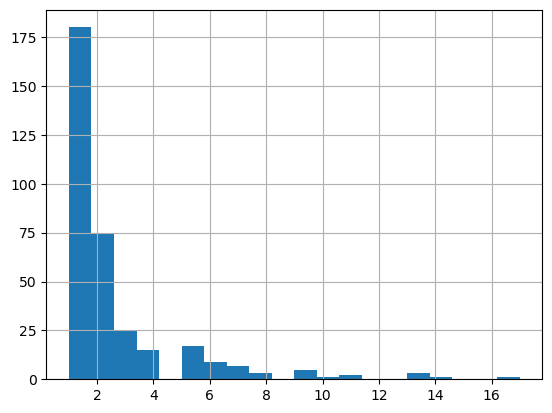

In [260]:
df['GID'].value_counts().hist(bins=20)

In [256]:
echo(df['GID'].value_counts().sort_values(ascending=False).head(10))

GID
P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:5 4 0 1:3                      17
P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:3 3 0 1:2                         14
P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 0 1:3    13
P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-term];14,IBT16[K]:5 4 1 1:3    13
P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 3 0 1:2                         13
P55083:MFAP4:87;111:FNGSVSFFR:1,IBT16[N-term]:8 2 0 0:3                      11
P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:5 4 1 1:3                      11
P12109:CO6A1:212:RNFTAADWGQSR:1,IBT16[N-term]:4 4 0 1:3                      10
P56199:ITA1:460:YNHTGQVIIYR:1,IBT16[N-term]:8 2 0 0:3                         9
P01857;P0DOX5:IGG1;IGHG1:180;299:EEQYNSTYR:1,IBT16[N-term]:3 3 0 1:2          9
Name: count, dtype: int64

In [242]:
db.exporting(des_dup, 'external_info/Glycosylation/pGlyco_dup_des')

[07/26 08:16:32] writing 1 file with 1872 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/pGlyco_dup_des.dfx


In [228]:
echo(des[['GlySpec','batch','repeat']].drop_duplicates(['batch','repeat']))

,GlySpec,batch,repeat
0,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,1,E
15,20230712-SHL-1-P-E.32556.32556.2.0.dta,1,E0
169,20230814-FP-Nglyco-PE-1_1.27724.27724.5.0.dta,1,1
235,20230814-FP-Nglyco-PE-1_2.3883.3883.3.0.dta,1,2
264,20230814-FP-Nglyco-PE-1_3.17184.17184.4.2.dta,1,3
296,20230814-FP-Nglyco-PE-1_4.29729.29729.4.2.dta,1,4
322,20230814-FP-Nglyco-PE-1_5.40282.40282.3.0.dta,1,5
344,20230813-FP-PRO-P-2.18606.18606.3.0.dta,2,E
349,20230814-FP-Nglyco-PE-2_1.40087.40087.4.1.dta,2,1
376,20230814-FP-Nglyco-PE-2_2.26216.26216.3.6.dta,2,2


In [225]:
des.columns

Index(['GlySpec', 'batch', 'repeat', 'PepSpec', 'RawName', 'Scan', 'RT',
       'PrecursorMH', 'PrecursorMZ', 'Charge', 'Rank', 'Peptide', 'Mod',
       'PeptideMH', 'Glycan(H,N,A,F)', 'GlycanComposition', 'PlausibleStruct',
       'GlyID', 'GlyFrag', 'GlyMass', 'GlySite', 'TotalScore', 'PepScore',
       'GlyScore', 'CoreMatched', 'MassDeviation', 'PPM', 'GlyIonRatio',
       'byIonRatio', 'czIonRatio', 'GlyDecoy', 'PepDecoy', 'IsSmallGlycan',
       'GlycanPEP', 'GlycanFDR', 'PeptidePEP', 'PeptideFDR', 'TotalFDR',
       'Proteins', 'Genes', 'ProSites', 'Supp_Info', 'Empty_Separator',
       'Unnamed: 57', 'Protein_ID', 'Protein_Name', 'sMod', 'sProPos',
       'sPeptide', 'Spectrum_ID', 'sCharge', 'GID', 'sGlycan',
       'Glytoucan_search'],
      dtype='object')

In [18]:
mat1 = mat
des1 = des

In [19]:
# PREFIX = 'gly'

# db.exporting(total,PREFIX + '_total',outputdir='export_big/',index=True)

# db.exporting(mat, PREFIX + '_mat_na',outputdir='export_big/')

# db.exporting(mat2, PREFIX + '_mat2_na',outputdir='export_big/')

# db.exporting(des,PREFIX + '_mat_gid_des',outputdir='export_big/',index=False)

# db.exporting(pool, PREFIX + '_pool',outputdir='export_big/',index=False)


base = 'external_info/Glycosylation/pGlyco/'
db.exporting(mat_dup_pid, 'gly_mat2_na' , outputdir=base)
db.exporting(mat, 'gly_mat_na',outputdir=base)
db.exporting(des, 'gly_mat_id_des' , outputdir=base)
None



[01/31 08:16:50] overwritting 1 file with 741 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/pGlyco/gly_mat2_na.dfx
[01/31 08:16:50] overwritting 1 file with 741 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/pGlyco/gly_mat_na.dfx
[01/31 08:16:50] overwritting 1 file with 741 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/pGlyco/gly_mat_id_des.dfx


In [20]:
x = db.importing('gly_mat_na', frm='external_info/Glycosylation/pGlyco/', index_col=0)
xi = x.shape[0] * x.shape[1] - x.isna().sum().sum()
print(f'pGlyco identifed {xi} GIDs')

[03/23 06:33:44]reading external_info/Glycosylation/pGlyco/gly_mat_na.dfx
pGlyco identifed 26824 GIDs


In [21]:
x

,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,P09,P13,P15,P26,P27,P29,P39,P40,P45,P50,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
GID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",1.460434,0.875232,1.140283,1.113961,0.689721,0.917821,0.953114,0.956701,1.160721,1.103126,0.838651,1.346298,0.962926,1.198657,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",0.980364,0.883952,1.018809,1.033549,0.729328,0.894929,1.026400,1.084660,1.022919,0.976259,0.800106,1.115954,1.093445,1.148254,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",1.026541,0.861010,1.106466,1.026120,0.956040,0.817339,1.153881,1.074751,0.882234,1.171168,1.109097,1.281588,0.970713,1.028832,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P02679:FIBG:78:DLQSLEDILHQVENK:1,IBT16[N-term];15,IBT16[K]:6 3 2 2:4",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.886147,0.927590,0.812869,1.007511,0.920701,1.222110,1.080895,0.942415,1.012780,1.166868,0.730571,1.139943,0.710254,0.960181,0.987443
"P08294:SODE:107:LDAFFALEGFPTEPNSSSR:1,IBT16[N-term]:4 3 0 3:3",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.800186,0.706252,0.683931,1.226380,1.054218,0.852241,0.935390,1.036607,1.008018,1.014989,0.942175,1.255005,0.896788,0.871005,0.952879
"P02675:FIBB:394:GTAGNALMDGASQLMGENR:1,IBT16[N-term];8,Oxidation[M]:5 4 1 2:5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.746653,0.683752,0.859644,0.652196,1.243406,1.125690,0.620048,0.642777,0.713698,0.797962,0.679379,0.785837,0.644919,0.673616,0.515291


### 糖基化 byonic


In [263]:
base = 'external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/'

dfs = []
for i in [i for i in L(base) if i[-4:]=='list']:
    df = db.importing(J(base, i))
    batch = i[0]
    repeat = i[2]
    df['batch'] = batch
    df['repeat'] = repeat
    dfs.append(df)

ob = pd.concat(dfs, ignore_index=True)

colnames = pd.Series(ob.columns[ob.columns.str.startswith('ReportIon')])
colnames = {i:i[11:-1] for i in colnames} 
colnames

# ob.rename(columns={'Protein Name':'Proteins','Position':'ProSites'},inplace=True)
ob.rename(columns=colnames,inplace=True)

ob


[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/1_1_pQuant.spectra.list
[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/1_2_pQuant.spectra.list
[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/1_3_pQuant.spectra.list
[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/1_4_pQuant.spectra.list
[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/1_5_pQuant.spectra.list
[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/2_1_pQuant.spectra.list
[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/2_2_pQuant.spectra.list
[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/2_3_pQuant.spectra.list
[07/26 08:39:53]reading external_info/Glycosylation/byonic_FFPE_N_glyco_quant_all_result/2_4_pQu

,Spectrum,Comment,Peptide,Mass (M+H),Observed,One-Off,Err (ppm),Obs m/z,Prot#,Rank,NumUniq,Protein Name,Position,Cleavage,Score,Delta,DeltaMod,Z-score,LogProb,Composition,ScanNumberList,ScanTimeList,Supp_Info,Empty_Separator,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482,Unnamed: 40,batch,repeat
0,00038:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=470.470.2,K.[+277.18814].N[+1378.47569]R.S,1944.8257,1944.8315,,3.0,972.9194,1351,12,52,>sp|P48634|PRC2A_HUMAN Protein PRRC2A OS=Homo ...,1438,Specific,222.24,222.24,222.24,13.04,-4.49,HexNAc(2)Hex(6),controllerType=0 controllerNumber=1 scan=470,3.2121,NaN,NaN,0.0,0.0,0.0,322.0,360.7,0.0,0.0,324.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,1
1,00263:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=1759.1...,R.[+277.18814].GN[+1257.44941]R.S,1880.8209,1880.8219,,0.5,940.9146,7347,13,30,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,531,Specific,258.22,258.22,258.22,13.81,-6.31,HexNAc(3)Hex(4),controllerType=0 controllerNumber=1 scan=1759,11.4112,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,394.4,0.0,0.0,0.0,0.0,NaN,1,1
2,00503:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=2287.2...,R.[+277.18814].GN[+1403.50732]R.S,2026.8788,2026.8871,,4.1,1013.9472,7347,13,30,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,531,Specific,222.40,222.40,222.40,13.27,-4.49,HexNAc(3)Hex(4)Fuc(1),controllerType=0 controllerNumber=1 scan=2287,14.0714,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,445.5,0.0,0.0,0.0,0.0,0.0,NaN,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6631,35376:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42418....,R.[+277.18814].ASLQFLQN[+2043.74002]YTALASAVDA...,6314.8456,6314.8386,,-1.1,1579.4651,21765,3,27,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,309.83,211.28,64.18,14.20,-7.83,HexNAc(4)Hex(4)Fuc(2)NeuAc(1),controllerType=0 controllerNumber=1 scan=42418,171.5748,NaN,NaN,1853.0,1479.0,1465.0,1106.2,1246.8,1861.2,771.2,1331.9,1467.2,1386.0,1582.4,1427.4,1140.9,1016.2,2231.5,1707.2,NaN,6,5
6632,35509:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42575....,R.[+277.18814].ASLQFLQN[+2059.73493]YTALASAVDA...,6330.8406,6330.8114,,-4.6,1583.4583,21765,3,27,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,531.29,416.24,28.46,19.94,-10.48,HexNAc(4)Hex(5)Fuc(1)NeuAc(1),controllerType=0 controllerNumber=1 scan=42575,172.2902,NaN,NaN,2567.6,1411.9,1916.5,2144.7,1226.9,2686.5,1257.4,2114.0,1492.8,1280.7,1250.9,1680.8,2169.6,1343.5,2573.8,2056.0,NaN,6,5
6633,35795:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42923....,R.[+277.18814].ASLQFLQN[+2350.83035]YTALASAVDA...,6637.9309,6638.8846,1,-7.5,1660.4766,21765,3,27,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,364.25,331.47,38.17,19.16,-9.07,HexNAc(4)Hex(5)Fuc(1)NeuAc(2),controllerType=0 controllerNumber=1 scan=42923,174.0203,NaN,NaN,469.3,554.1,0.0,614.6,330.3,379.1,0.0,542.5,0.0,0.0,0.0,0.0,0.0,0.0,540.7,479.1,NaN,6,5


In [264]:
db.exporting(ob, 'external_info/Glycosylation/pQuant.spectra.merged.list')

[07/26 08:40:02] overwritting 1 file with 6634 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/pQuant.spectra.merged.list


In [265]:
import re

ob['Proteins'] = ob['Protein Name']

a1 = []
a2 = []
for i in ob['Proteins']:
    i = i.split(';')
    # Protein_ID
    xs = set()
    # Protein_Name
    ys = set()
    for j in i:
        j = j[(j.index('sp|')+3):]
        x,y = j[:j.index('_HUMAN')].split('|')
        if '-' in x:
            x = x[:x.index('-')]  
        xs.add(x)
        ys.add(y)
    x = ';'.join(xs)
    y = ';'.join(ys)
    a1.append(x)
    a2.append(y)
    
ob['Protein_ID'] = a1
ob['Protein_Name'] = a2

# a1 = []
# for i in ob['Peptide']:
#     i = re.sub('\.','',i)
#     i = re.sub('\[.+?\]','',i)
    
#     a1.append(i)
# ob['sPeptide'] = a1


def find(s, sub:['HexNAc(','Hex(','Fuc(','NeuAc('] = 'HexNAc('):
    m = {"Hex(":"H",
        "HexNAc(":"N",
        "NeuAc(":"A",
        "Fuc(":"F"}
    try:
        i = s.index(sub)
        l = len(sub)
        i = i + l
        s_sub = s[i:]
        j = s_sub.index(')') + i
        
    except ValueError as e:
        return m[sub],0
    
    n = int(s[i:j])
    return m[sub],n

# GlycanComposition
a1 = []
# Glycan(H,N,A,F)
a2 = []
for j in ob['Composition']:
    subst = {}
    for ose in ['Hex(','HexNAc(','NeuAc(','Fuc(']:
        s,n = find(j,ose)
        subst[s] = n
    a2.append(f"{subst['H']} {subst['N']} {subst['A']} {subst['F']}")
    mask = ''
    for i,v in subst.items():
        if v==0:
            continue
        else:
            mask += f"{i}({v})"
    a1.append(mask)
    
# ob['Composition'] = ob['Glycan(H,N,A,F)']
ob['Glycan(H,N,A,F)'] = a2
ob['GlycanComposition'] = a1




# ---- Mod sPeptide ----

r = []
p = []
a1 = []
m = {'[+15.99492]':'Oxidation[M]', 
 '[+277.18814]':'IBT16', 
 '[+42.01056]':'Acetyl[ProteinN-term]', 
 '[+57.02146]':'Carbamidomethy[C]'
}
ma = []

for _,row in ob.iterrows():
    pos,j = row[['Position','Peptide']]
    pos = int(pos)
    # cut pre one aa
    j = re.sub('^[A-Z\-]\.\[\+277.18814\]\.','',j)
    # cut suffix one aa
    j = re.sub('\.[A-Z\-]$',"",j)
    # find N[+mass] position
    i = re.search('N\[\+.+?\]',j)
    s = i.span()[0]
    # cal sProPos
    a1.append(pos + s)
    
    # extract = Glycan mass
    mass = re.findall('N\[\+(.+?)\]',j)
    mass = ':'.join(mass)
    mass = float(mass)
    # rm Glycan mass
    j = re.sub('N\[\+.+?\]','N',j)
    
    tag = ['1,IBT16[N-term]']
    for _,i in enumerate(re.finditer('\[\+[0-9\.]+\]',j)):
        s,e = i.span()
        
        t = m[i.group()]
        if t == 'IBT16':
            tag.append(f"{s},{t}[{i.string[(s-1)]}]")
        else:
            tag.append(f"{s},{t}")
    tag = ";".join(tag)
    r.append(tag)
    # rm all the mass data in []
    j = re.sub('\[\+[0-9\.]+\]',"",j)
    p.append(j)
    ma.append(mass)
    

ob['sMod'] = r 
ob['sPeptide'] = p
ob['ProPos'] = a1
ob['Charge'] = ob['Spectrum'].str.split(':',expand=True)[1].astype(int)
ob['GlyMass'] = ma
# ---- Spectrum_ID ----

ob['Spectrum_ID'] = [".".join(j.split(';')[-1].split('=')[-1].split('.')[:2]) for j in ob['Comment']]
# ob['Spectrum_ID'] = ob['Spectrum'].str.split(':',expand=True).iloc[:,0]

ob['sCharge'] = ob['Charge'].astype(str)
ob['sProPos'] = ob['ProPos'].astype(str)



In [266]:
# cols = ['Proteins','ProSites','Peptide','Mod','Glycan(H,N,A,F)','Charge']
# Peptide = Peptide + Mod
# Glycan(H,N,A,F) ~= Composition
cols = ['Protein_ID','Protein_Name','sProPos','sPeptide','sMod','Glycan(H,N,A,F)','sCharge']

ob['GID'] = ob[cols].apply(lambda i:":".join(i), axis=1)
ob2 = ob
ob



,Spectrum,Comment,Peptide,Mass (M+H),Observed,One-Off,Err (ppm),Obs m/z,Prot#,Rank,NumUniq,Protein Name,Position,Cleavage,Score,Delta,DeltaMod,Z-score,LogProb,Composition,ScanNumberList,ScanTimeList,Supp_Info,Empty_Separator,114.1277,...,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482,Unnamed: 40,batch,repeat,Proteins,Protein_ID,Protein_Name,"Glycan(H,N,A,F)",GlycanComposition,sMod,sPeptide,ProPos,Charge,GlyMass,Spectrum_ID,sCharge,sProPos,GID
0,00038:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=470.470.2,K.[+277.18814].N[+1378.47569]R.S,1944.8257,1944.8315,,3.0,972.9194,1351,12,52,>sp|P48634|PRC2A_HUMAN Protein PRRC2A OS=Homo ...,1438,Specific,222.24,222.24,222.24,13.04,-4.49,HexNAc(2)Hex(6),controllerType=0 controllerNumber=1 scan=470,3.2121,NaN,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,1,>sp|P48634|PRC2A_HUMAN Protein PRRC2A OS=Homo ...,P48634,PRC2A,6 2 0 0,H(6)N(2),"1,IBT16[N-term]",NR,1438,2,1378.47569,470.470,2,1438,"P48634:PRC2A:1438:NR:1,IBT16[N-term]:6 2 0 0:2"
1,00263:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=1759.1...,R.[+277.18814].GN[+1257.44941]R.S,1880.8209,1880.8219,,0.5,940.9146,7347,13,30,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,531,Specific,258.22,258.22,258.22,13.81,-6.31,HexNAc(3)Hex(4),controllerType=0 controllerNumber=1 scan=1759,11.4112,NaN,NaN,0.0,...,0.0,0.0,0.0,394.4,0.0,0.0,0.0,0.0,NaN,1,1,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,P21817,RYR1,4 3 0 0,H(4)N(3),"1,IBT16[N-term]",GNR,532,2,1257.44941,1759.1759,2,532,"P21817:RYR1:532:GNR:1,IBT16[N-term]:4 3 0 0:2"
2,00503:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=2287.2...,R.[+277.18814].GN[+1403.50732]R.S,2026.8788,2026.8871,,4.1,1013.9472,7347,13,30,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,531,Specific,222.40,222.40,222.40,13.27,-4.49,HexNAc(3)Hex(4)Fuc(1),controllerType=0 controllerNumber=1 scan=2287,14.0714,NaN,NaN,0.0,...,0.0,0.0,445.5,0.0,0.0,0.0,0.0,0.0,NaN,1,1,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,P21817,RYR1,4 3 0 1,H(4)N(3)F(1),"1,IBT16[N-term]",GNR,532,2,1403.50732,2287.2287,2,532,"P21817:RYR1:532:GNR:1,IBT16[N-term]:4 3 0 1:2"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6631,35376:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42418....,R.[+277.18814].ASLQFLQN[+2043.74002]YTALASAVDA...,6314.8456,6314.8386,,-1.1,1579.4651,21765,3,27,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,309.83,211.28,64.18,14.20,-7.83,HexNAc(4)Hex(4)Fuc(2)NeuAc(1),controllerType=0 controllerNumber=1 scan=42418,171.5748,NaN,NaN,1853.0,...,1467.2,1386.0,1582.4,1427.4,1140.9,1016.2,2231.5,1707.2,NaN,6,5,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,P12109,CO6A1,4 4 1 2,H(4)N(4)A(1)F(2),"1,IBT16[N-term]",ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,4,2043.74002,42418.42418,4,896,P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVN...
6632,35509:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42575....,R.[+277.18814].ASLQFLQN[+2059.73493]YTALASAVDA...,6330.8406,6330.8114,,-4.6,1583.4583,21765,3,27,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,531.29,416.24,28.46,19.94,-10.48,HexNAc(4)Hex(5)Fuc(1)NeuAc(1),controllerType=0 controllerNumber=1 scan=42575,172.2902,NaN,NaN,2567.6,...,1492.8,1280.7,1250.9,1680.8,2169.6,1343.5,2573.8,2056.0,NaN,6,5,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,P12109,CO6A1,5 4 1 1,H(5)N(4)A(1)F(1),"1,IBT16[N-term]",ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,4,2059.73493,42575.42575,4,896,P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVN...
6633,35795:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42923....,R.[+277.18814].ASLQFLQN[+2350.83035]YTALASAVDA...,6637.9309,6638.8846,1,-7.5,1660.4766,21765,3,27,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,364.25,331.47,38.17,19.16,-9.07,HexNAc(4)Hex(5)Fuc(1)NeuAc(2),controllerType=0 controllerNumber=1 scan=42923,174.0203,NaN,NaN,469.3,...,0.0,0.0,0.

In [267]:

db.exporting(ob, 'external_info/Glycosylation/byonic/byonic_colname_standard_inputs')


[07/26 08:40:07] overwritting 1 file with 6634 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/byonic/byonic_colname_standard_inputs.dfx


In [268]:
# use ob, convert, total, colnames
res = {}
mats = []
mats2 = []
des = []
pools = {}
for g,df in ob.groupby('batch'):
    
    mp = convert[convert['batch']==g].set_index('ReporterMass')['Custom_Label'].to_dict()
    # 除以每个batch的总蛋白，归一化上样量
    factor = total.loc[g,:]
    normd = df.loc[:,list(mp.keys())].divide(factor)
    
    # 除以每个pool
    pcol = [k for k,v in mp.items() if v=='p'][0]
    pools[g] = normd[pcol].reset_index(drop=True)
    pooled_normd = normd.divide(normd[pcol],axis=0)
    
    # 删除全部是inf或na的行（GID）-> df
    pooled_normd[[~np.isfinite(pooled_normd)]] = np.nan
    mask_keep = pooled_normd.isna().apply(np.mean, 1) != 1
    df = df[mask_keep].reset_index(drop=True).copy()
    df.loc[:,list(mp.keys())] = pooled_normd.loc[mask_keep,:].values
    
    # 取median，groupby GID, merge repeats and duplicated 捕获 -> df
    x = df.groupby(["GID"])[list(colnames.values())].median().reset_index()
    y = df.loc[:,~df.columns.isin(list(colnames.values()))].drop_duplicates('GID')
    df = pd.merge(y,x,on='GID',how='left')
    
    # 提取数据matrix -> mat,mat_withpool
    mat_withpool = df.set_index('GID')[list(mp.keys())]
    # rename columns
    mat_withpool = mat_withpool.rename(columns = mp)
    # 去除pool列
    mat_withpool = mat_withpool.loc[:,mat_withpool.columns!='p']
    # 消除重复样品
    mat = mat_withpool.groupby(mat_withpool.columns, axis=1).median()
    print(mat_withpool.shape,'->',mat.shape)
    
    # collect
    mats.append(mat)
    mats2.append(mat_withpool)
    res[g] = df
    # 提取GID相关信息的DataFrame -> des
    des.append(df.loc[:,~df.columns.isin(list(mp.keys()))])
    
    
    
des = pd.concat(des, ignore_index=True)
print('drop duplicates of des',des.shape,'->',end=' ')
des = des.drop_duplicates('GID').reset_index(drop=True)
print(des.shape)
mat = pd.concat(mats,axis=1)
mat_dup_pid = pd.concat(mats2,axis=1)

des['sGlycan'] = des['Glycan(H,N,A,F)']
x = des['Glycan(H,N,A,F)'].str.split(' ',expand=True)
des['Glytoucan_search'] = x[0] + ' hex, ' + x[1] +' hexnac, ' + x[2] +' neu5ac, ' + x[3] +' dhex'


des


(430, 15) -> (430, 14)
(458, 15) -> (458, 14)
(576, 15) -> (576, 14)
(479, 15) -> (479, 14)
(514, 15) -> (514, 15)
(577, 15) -> (577, 15)
drop duplicates of des (3034, 41) -> (1283, 41)


,Spectrum,Comment,Peptide,Mass (M+H),Observed,One-Off,Err (ppm),Obs m/z,Prot#,Rank,NumUniq,Protein Name,Position,Cleavage,Score,Delta,DeltaMod,Z-score,LogProb,Composition,ScanNumberList,ScanTimeList,Supp_Info,Empty_Separator,Unnamed: 40,batch,repeat,Proteins,Protein_ID,Protein_Name,"Glycan(H,N,A,F)",GlycanComposition,sMod,sPeptide,ProPos,Charge,GlyMass,Spectrum_ID,sCharge,sProPos,GID,sGlycan,Glytoucan_search
0,00945:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=2796.2...,R.[+277.18814].GN[+1257.44941]R.S,1880.8209,1880.8281,,3.8,940.9177,7347,13,30,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,531,Specific,294.11,294.11,294.11,13.11,-6.59,HexNAc(3)Hex(4),controllerType=0 controllerNumber=1 scan=2796,16.6249,NaN,NaN,NaN,1,1,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,P21817,RYR1,4 3 0 0,H(4)N(3),"1,IBT16[N-term]",GNR,532,2,1257.44941,2796.2796,2,532,"P21817:RYR1:532:GNR:1,IBT16[N-term]:4 3 0 0:2",4 3 0 0,"4 hex, 3 hexnac, 0 neu5ac, 0 dhex"
1,02334:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=4346.4...,R.[+277.18814].N[+1257.44941]VTR.L,2023.9155,2023.9237,,4.1,1012.4655,34242,38,16,>sp|P05556|ITB1_HUMAN Integrin beta-1 OS=Homo ...,269,Specific,318.33,318.33,318.33,11.77,-6.59,HexNAc(3)Hex(4),controllerType=0 controllerNumber=1 scan=4346,24.3179,NaN,NaN,NaN,1,1,>sp|P05556|ITB1_HUMAN Integrin beta-1 OS=Homo ...,P05556,ITB1,4 3 0 0,H(4)N(3),"1,IBT16[N-term]",NVTR,269,2,1257.44941,4346.4346,2,269,"P05556:ITB1:269:NVTR:1,IBT16[N-term]:4 3 0 0:2",4 3 0 0,"4 hex, 3 hexnac, 0 neu5ac, 0 dhex"
2,00894:3,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=2739.2...,R.[+277.18814].SHN[+1444.53387]K[+277.18814].S,2484.1568,2484.1598,,1.2,828.7248,39585,20,7,>sp|Q86U06|RBM23_HUMAN Probable RNA-binding pr...,66,Specific,273.26,59.82,59.82,11.20,-4.73,HexNAc(4)Hex(3)Fuc(1),controllerType=0 controllerNumber=1 scan=2739,16.3358,NaN,NaN,NaN,1,1,>sp|Q86U06|RBM23_HUMAN Probable RNA-binding pr...,Q86U06,RBM23,3 4 0 1,H(3)N(4)F(1),"1,IBT16[N-term];4,IBT16[K]",SHNK,68,3,1444.53387,2739.2739,3,68,"Q86U06:RBM23:68:SHNK:1,IBT16[N-term];4,IBT16[K...",3 4 0 1,"3 hex, 4 hexnac, 0 neu5ac, 1 dhex"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1280,35215:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42233....,K.[+277.18814].ADTHDEILEGLNFN[+2261.79390]LTEI...,6230.8059,6231.7578,1,-8.3,1558.6949,10190,2,22,>sp|P01009|A1AT_HUMAN Alpha-1-antitrypsin OS=H...,94,Specific,370.55,235.10,235.10,15.27,-8.21,HexNAc(5)Hex(4)NeuAc(1)NeuGc(1),controllerType=0 controllerNumber=1 scan=42233,170.7325,NaN,NaN,NaN,6,5,>sp|P01009|A1AT_HUMAN Alpha-1-antitrypsin OS=H...,P01009,A1AT,4 5 1 0,H(4)N(5)A(1),"1,IBT16[N-term]",ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR,107,4,2261.79390,42233.42233,4,107,P01009:A1AT:107:ADTHDEILEGLNFNLTEIPEAQIHEGFQEL...,4 5 1 0,"4 hex, 5 hexnac, 1 neu5ac, 0 dhex"
1281,35356:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42394....,R.[+277.18814].ASLQFLQN[+2133.77171]YTALASAVDA...,6420.8723,6419.8426,-1,-4.1,1605.7161,21765,3,27,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,298.92,176.69,4.17,12.72,-7.65,HexNAc(5)Hex(6)Fuc(1),controllerType=0 controllerNumber=1 scan=42394,171.4670,NaN,NaN,NaN,6,5,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,P12109,CO6A1,6 5 0 1,H(6)N(5)F(1),"1,IBT16[N-term];19,Oxidation[M]",ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,4,2133.77171,42394.42394,4,896,P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVN...,6 5 0 1,"6 hex, 5 hexnac, 0 neu5ac, 1 dhex"
1282,35795:4,20230814-fp-nglyco-pe-6_5.ScanId;v=1;d1=42923....,R.[+277.18814].ASLQFLQN[+2350.83035]YTALASAVDA...,6637.9309,6638.8846,1,-7.5,1660.4766,21765,3,27,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,364.25,331.47,38.17,19.16,-9.07,HexNAc(4)Hex(5)Fuc(1)NeuAc(2),controllerType=0 controllerNumber=1 scan=42923,174.0203,NaN,NaN,NaN,6,5,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,P12109,CO6A1,5 4 2 1,H(5)N(4)A(2)F(1),"1,IBT16[N-term];19,Oxidati

In [269]:
mat2 = mat
des2 = des

In [270]:
# 可能会导致列 16 -> 14等，因为有重复的PID

In [271]:
base = 'external_info/Glycosylation/byonic/'
db.exporting(mat_dup_pid, 'gly_mat2_na' , outputdir=base)
db.exporting(mat, 'gly_mat_na',outputdir=base)
db.exporting(des, 'gly_mat_id_des' , outputdir=base)
None


[07/26 08:40:13] overwritting 1 file with 1283 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/byonic/gly_mat2_na.dfx
[07/26 08:40:13] overwritting 1 file with 1283 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/byonic/gly_mat_na.dfx
[07/26 08:40:13] overwritting 1 file with 1283 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/byonic/gly_mat_id_des.dfx


In [272]:
x = db.importing('gly_mat_na', frm='external_info/Glycosylation/byonic/', index_col=0)
xi = x.shape[0] * x.shape[1] - x.isna().sum().sum()
print(f'byonic identifed {xi} GIDs')
x

[07/26 08:40:18]reading external_info/Glycosylation/byonic/gly_mat_na.dfx
byonic identifed 43567 GIDs


,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,P09,P13,P15,P26,P27,P29,P39,P40,P45,P50,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
GID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"P21817:RYR1:532:GNR:1,IBT16[N-term]:4 3 0 0:2",0.919816,0.749697,0.511226,1.100278,1.173735,0.658436,0.767808,0.968786,0.913131,1.054101,1.258189,0.691542,0.789227,1.042362,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"P05556:ITB1:269:NVTR:1,IBT16[N-term]:4 3 0 0:2",0.757527,0.775047,0.644047,1.060901,0.797999,0.761444,1.041500,1.043472,0.877670,1.037123,0.779239,0.962565,0.950744,0.842857,0.803273,0.849543,0.76288,0.814892,1.082137,0.924294,0.919259,1.500921,1.00035,1.090769,1.004535,...,1.047183,1.016142,0.719830,0.923111,0.614691,1.543486,0.855624,0.877374,0.667219,0.385778,0.992822,0.730158,0.924680,0.550524,0.864624,0.906163,0.813503,1.174758,0.570569,0.901163,0.938178,1.040672,1.021726,1.022761,0.810862
"Q86U06:RBM23:68:SHNK:1,IBT16[N-term];4,IBT16[K]:3 4 0 1:3",1.297802,1.575891,1.113059,1.759696,1.255773,0.784365,1.515332,1.776362,1.545614,1.221445,0.967099,1.559773,1.526647,1.016164,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.532481,1.198500,0.826184,1.071128,1.108898,0.781943,1.134545,1.085260,0.928962,0.835615,0.873055,0.732764,1.038558,0.467347,1.284102,0.589344,0.596807,0.706195,0.679843,0.717204,0.788538,0.699082,0.808927,1.292543,1.469171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P01009:A1AT:107:ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR:1,IBT16[N-term]:4 5 1 0:4",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.497014,2.094337,1.792850,1.352580,1.207126,1.323882,1.770677,1.342672,1.373282,2.511391,0.800152,2.121435,1.547124,1.163830,2.293039
"P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR:1,IBT16[N-term];19,Oxidation[M]:6 5 0 1:4",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.339338,1.138254,0.774200,1.217434,1.480498,1.523598,1.422789,1.241797,1.031937,1.341247,1.208382,1.030988,1.065181,0.779943,0.650246
"P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR:1,IBT16[N-term];19,Oxidation[M]:5 4 2 1:4",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.274763,0.564630,0.000000,0.000000,0.000000,0.000000,0.000000,0.779775,0.944937,1.095898,0.000000,0.000000,1.111341,0.000000,1.288623


### compare 2 methods overlaps

#### compare Spretra Results

In [150]:
# pGlyco
ob_pglyco = db.importing('external_info/Glycosylation/pGlyco/pglyco_colname_standard_inputs.dfx')
ob_pglyco


[07/26 07:22:06]reading external_info/Glycosylation/pGlyco/colname_standard_inputs.dfx


,GlySpec,batch,repeat,PepSpec,RawName,Scan,RT,PrecursorMH,PrecursorMZ,Charge,Rank,Peptide,Mod,PeptideMH,"Glycan(H,N,A,F)",GlycanComposition,PlausibleStruct,GlyID,GlyFrag,GlyMass,GlySite,TotalScore,PepScore,GlyScore,CoreMatched,...,114.1277,115.1248,115.1311,116.1281,116.1344,117.1315,117.1378,118.1348,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482,Unnamed: 57,Protein_ID,Protein_Name,sMod,sProPos,sPeptide,Spectrum_ID,sCharge,GID
0,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,1,E,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,20230712-SHL-1-P-1-E,27788,5495.40180,3027.41167,1009.80874,3,1,DIYTFDGALJK,"1,IBT16[N-term];11,IBT16[K];",1810.99200,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H)(H))))),2257,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,10,56.27865,83.45758,5.80349,4,...,6328.4,5855.7,5993.8,9606.8,8828.8,10270.8,8168.7,7105.4,8386.6,10720.7,8898.5,6564.0,10625.8,8508.0,11454.9,8290.0,NaN,Q08722,CD47,"1,IBT16[N-term];11,IBT16[K]",73,DIYTFDGALNK,27788.27788,3,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,..."
1,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,1,E,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,20230712-SHL-1-P-1-E,26727,5289.04465,3219.54850,1073.85435,3,1,AGPJGTLFVADAYK,"1,IBT16[N-term];14,IBT16[K];",1978.09786,3 3 0 1,H(3)N(3)F(1),(N(N(H(H)(H(N(F)))))),2266,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 3 0 ...,1241.45450,4,23.54750,33.46159,5.13564,4,...,51712.7,47774.4,45609.0,61181.1,56765.0,61264.4,51804.2,47440.4,60952.3,50516.0,68958.4,45064.4,73249.3,59697.6,56629.7,59655.9,NaN,Q9HDC9,APMAP,"1,IBT16[N-term];14,IBT16[K]",160,AGPNGTLFVADAYK,26727.26727,3,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term..."
2,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,1,E,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,20230712-SHL-1-P-1-E,25538,5066.89294,2230.02395,744.01283,3,1,FJGSVSFFR,"1,IBT16[N-term];",1337.70919,3 2 0 0,H(3)N(2),(N(N(H(H)(H)))),2291,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;,892.31722,2,29.18503,31.56191,24.77082,5,...,41316.4,42947.5,54567.9,65016.2,58921.7,56907.2,44084.8,46159.5,55100.8,52964.9,68266.7,54063.8,59939.3,56821.9,54660.9,59390.9,NaN,P55083,MFAP4,"1,IBT16[N-term]",87;111,FNGSVSFFR,25538.25538,3,"P55083:MFAP4:87;111:FNGSVSFFR:1,IBT16[N-term]:..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4099,20230814-FP-Nglyco-PE-6_5.13467.13467.3.0.dta,6,5,20230814-FP-Nglyco-PE-6_5.13467.13467.3.0.dta,20230814-FP-Nglyco-PE-6_5,13467,3545.92524,3835.72984,1279.24813,3,1,YLYLASJHSNK,"1,IBT16[N-term];11,IBT16[K];",1864.02977,5 5 0 1,H(5)N(5)F(1),(N(F)(N(H(N)(H(N(H)))(H(N(H)))))),1175,0 1 0 0;0 1 0 1;0 2 0 0;0 2 0 1;1 2 0 0;1 2 0 ...,1971.71889,7,36.54317,28.11994,52.18630,8,...,27273.0,15373.6,12946.6,14946.1,13891.7,15005.8,11976.6,14027.7,12970.1,13358.5,14694.2,18827.6,14921.8,12893.1,15226.0,15397.0,NaN,Q16853,AOC3,"1,IBT16[N-term];11,IBT16[K]",49;592,YLYLASNHSNK,13467.13467,3,"Q16853:AOC3:49;592:YLYLASNHSNK:1,IBT16[N-term]..."
4100,20230814-FP-Nglyco-PE-6_5.27284.27284.4.2.dta,6,5,20230814-FP-Nglyco-PE-6_5.27284.27284.4.2.dta,20230814-FP-Nglyco-PE-6_5,27284,6325.17079,3971.98870,993.75263,4,1,VVLHPJYSQVDIGLIK,"1,IBT16[N-term];16,IBT16[K];",2349.38750,5 4 0 0,H(5)N(4),(N(N(H(H)(H(N(H))(N(H)))))),2280,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 4 0 ...,1622.58161,6,23.29396,23.66593,22.60316,5,...,105900.0,69240.2,91165.8,92093.9,98894.9,86857.3,83915.9,70341.1,80537.7,71247.1,75692.2,116279.2,100731.8,73130.7,101355.9,87262.3,NaN,P00738,HPT,"1,IBT16[N-term];16,IBT16[K]",241;182,VVLHPNYSQVDIGLIK,27284.27284,4,"P00738:HPT:241;182:VVLHPNYSQVDIGLIK:1,IBT16[N-..."
4101,20230814-FP-Nglyco-PE-6_5.29005.29005.3.0.dta,6,5,20230814-FP-Nglyco-PE-6_5.29005.29005.3.0.dta,20230814-FP-Nglyco-PE-6_5,29005,6730.28252,3874.67552,1292.23002,3,1,LAJLTQGEDQYYLR,"1,IBT16[N-term];",1961.02179,5 4 1 0,H(5)N(4)A(1),(N(N(H(H(N(H)))(H(N(H(A))))))),2036,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0

In [151]:
# byonic
ob_byonic = db.importing('external_info/Glycosylation/byonic/byonic_colname_standard_inputs.dfx')
ob_byonic


[07/26 07:22:15]reading external_info/Glycosylation/byonic/colname_standard_inputs.dfx


,Spectrum,Comment,Peptide,Mass (M+H),Observed,One-Off,Err (ppm),Obs m/z,Prot#,Rank,NumUniq,Protein Name,Position,Cleavage,Score,Delta,DeltaMod,Z-score,LogProb,Composition,ScanNumberList,ScanTimeList,Supp_Info,Empty_Separator,114.1277,...,118.1411,119.1382,119.1445,120.1415,120.1479,121.1449,121.1512,122.1482,Unnamed: 40,batch,repeat,Proteins,Protein_ID,Protein_Name,"Glycan(H,N,A,F)",GlycanComposition,sMod,sPeptide,ProPos,Charge,GlyMass,Spectrum_ID,sCharge,sProPos,GID
0,00038:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=470.470.2,K.[+277.18814].N[+1378.47569]R.S,1944.8257,1944.8315,,3.0,972.9194,1351,12,52,>sp|P48634|PRC2A_HUMAN Protein PRRC2A OS=Homo ...,1438,Specific,222.24,222.24,222.24,13.04,-4.49,HexNAc(2)Hex(6),controllerType=0 controllerNumber=1 scan=470,3.2121,NaN,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,1,1,>sp|P48634|PRC2A_HUMAN Protein PRRC2A OS=Homo ...,P48634,PRC2A,6 2 0 0,H(6)N(2),"1,IBT16[N-term]",NR,1438,2,1378.47569,470.47000,2,1438,"P48634:PRC2A:1438:NR:1,IBT16[N-term]:6 2 0 0:2"
1,00263:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=1759.1...,R.[+277.18814].GN[+1257.44941]R.S,1880.8209,1880.8219,,0.5,940.9146,7347,13,30,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,531,Specific,258.22,258.22,258.22,13.81,-6.31,HexNAc(3)Hex(4),controllerType=0 controllerNumber=1 scan=1759,11.4112,NaN,NaN,0.0,...,0.0,0.0,0.0,394.4,0.0,0.0,0.0,0.0,NaN,1,1,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,P21817,RYR1,4 3 0 0,H(4)N(3),"1,IBT16[N-term]",GNR,532,2,1257.44941,1759.17590,2,532,"P21817:RYR1:532:GNR:1,IBT16[N-term]:4 3 0 0:2"
2,00503:2,20230814_fp_nglyco_pe_1_1.ScanId;v=1;d1=2287.2...,R.[+277.18814].GN[+1403.50732]R.S,2026.8788,2026.8871,,4.1,1013.9472,7347,13,30,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,531,Specific,222.40,222.40,222.40,13.27,-4.49,HexNAc(3)Hex(4)Fuc(1),controllerType=0 controllerNumber=1 scan=2287,14.0714,NaN,NaN,0.0,...,0.0,0.0,445.5,0.0,0.0,0.0,0.0,0.0,NaN,1,1,>sp|P21817|RYR1_HUMAN Ryanodine receptor 1 OS=...,P21817,RYR1,4 3 0 1,H(4)N(3)F(1),"1,IBT16[N-term]",GNR,532,2,1403.50732,2287.22870,2,532,"P21817:RYR1:532:GNR:1,IBT16[N-term]:4 3 0 1:2"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6372,35058:5,20230814-fp-nglyco-pe-6_4.ScanId;v=1;d1=42078....,K.[+277.18814].ADTHDEILEGLNFN[+2204.77244]LTEI...,6173.7844,6173.7394,,-7.3,1235.5537,10190,1,24,>sp|P01009|A1AT_HUMAN Alpha-1-antitrypsin OS=H...,94,Specific,266.40,50.40,50.40,14.00,-5.65,HexNAc(4)Hex(5)NeuAc(2),controllerType=0 controllerNumber=1 scan=42078,170.0610,NaN,NaN,17143.1,...,9971.9,10724.5,9992.7,9873.7,12094.5,11691.2,16704.7,17362.9,NaN,6,4,>sp|P01009|A1AT_HUMAN Alpha-1-antitrypsin OS=H...,P01009,A1AT,5 4 2 0,H(5)N(4)A(2),"1,IBT16[N-term]",ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR,107,5,2204.77244,42078.42078,5,107,P01009:A1AT:107:ADTHDEILEGLNFNLTEIPEAQIHEGFQEL...
6373,35481:4,20230814-fp-nglyco-pe-6_4.ScanId;v=1;d1=42573....,R.[+277.18814].ASLQFLQN[+2059.73493]YTALASAVDA...,6330.8406,6330.7910,,-7.8,1583.4532,21765,4,29,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,501.42,417.16,50.79,18.46,-9.71,HexNAc(4)Hex(5)Fuc(1)NeuAc(1),controllerType=0 controllerNumber=1 scan=42573,172.3027,NaN,NaN,1186.7,...,1544.8,920.4,896.9,1199.4,2085.7,750.1,1448.4,1235.4,NaN,6,4,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,P12109,CO6A1,5 4 1 1,H(5)N(4)A(1)F(1),"1,IBT16[N-term]",ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,4,2059.73493,42573.42573,4,896,P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVN...
6374,35533:4,20230814-fp-nglyco-pe-6_4.ScanId;v=1;d1=42639....,R.[+277.18814].ASLQFLQN[+2060.75533]YTALASAVDA...,6331.8610,6332.8114,+1,-8.4,1583.9583,21765,4,29,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,889,Specific,359.90,308.91,308.91,16.57,-8.31,HexNAc(4)Hex(5)Fuc(3),controllerType=0 controllerNumber=1 scan=42639,172.6104,NaN,NaN,1014.6,...,768.4,654.9,931.4,710.6,934

In [182]:
ob_pglyco['File_ID'] = ob_pglyco['RawName'].str.replace('-','_').str.lower()
ob_pglyco['Scan_ID'] = ob_pglyco['Scan'].astype(str)

In [174]:
ob_pglyco['Scan_File_ID'] = ob_pglyco['File_ID'] + ':' + ob_pglyco['Scan_ID']
ob_pglyco['Scan_File_ID']


0            20230712_shl_1_p_1_e:27788
1            20230712_shl_1_p_1_e:26727
2            20230712_shl_1_p_1_e:25538
                     ...               
4099    20230814_fp_nglyco_pe_6_5:13467
4100    20230814_fp_nglyco_pe_6_5:27284
4101    20230814_fp_nglyco_pe_6_5:29005
Name: Scan_File_ID, Length: 4102, dtype: object

In [183]:
# extract Spectra file ID
x = ob_byonic['Comment'].str.split(';', expand=True, regex=False)
y = x[2].str.removeprefix('d1=').str.split('.', regex=False, expand=True)[0].astype(str)
x = x[0].str.removesuffix('.ScanId')
x = x.str.replace("-",'_').str.lower()
ob_byonic['File_ID'] = x
ob_byonic['Scan_ID'] = y
ob_byonic['Scan_File_ID'] = ob_byonic['File_ID'] +':'+ ob_byonic['Scan_ID']
ob_byonic['Scan_File_ID']


0         20230814_fp_nglyco_pe_1_1:470
1        20230814_fp_nglyco_pe_1_1:1759
2        20230814_fp_nglyco_pe_1_1:2287
                     ...               
6372    20230814_fp_nglyco_pe_6_4:42078
6373    20230814_fp_nglyco_pe_6_4:42573
6374    20230814_fp_nglyco_pe_6_4:42639
Name: Scan_File_ID, Length: 6375, dtype: object

In [187]:
x1 = set(ob_pglyco['File_ID']) & set(ob_byonic['File_ID'])
len(x1)

29

In [188]:
x2 = set(ob_pglyco['Scan_ID']) & set(ob_byonic['Scan_ID'])
len(x2)

2025

In [176]:
x = set(ob_pglyco['Scan_File_ID']) & set(ob_byonic['Scan_File_ID'])
len(x)

1902

In [189]:

db.exporting(ob_pglyco, 'external_info/Glycosylation/pGlyco/pglyco_ob_scan_file_id')
db.exporting(ob_byonic, 'external_info/Glycosylation/byonic/byonic_ob_scan_file_id')


[07/26 07:40:15] writing 1 file with 4102 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/pGlyco/pglyco_ob_scan_file_id.dfx
[07/26 07:40:15] writing 1 file with 6375 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/byonic/byonic_ob_scan_file_id.dfx


#### compare Quantative Results

In [380]:
os.getcwd()

'[PROJECT_ROOT]/ALLNEW_PLOTS/DATA_AVA'

In [381]:
mat1 = db.importing('external_data/Glycosylation/pGlyco/gly_mat_na.dfx', index_col=0)
mat2 = db.importing('external_data/Glycosylation/byonic/gly_mat_na.dfx', index_col=0)


[09/12 09:37:45]reading external_data/Glycosylation/pGlyco/gly_mat_na.dfx
[09/12 09:37:45]reading external_data/Glycosylation/byonic/gly_mat_na.dfx


In [382]:
has_two = []

if (mat1.columns==mat2.columns).mean():
    x = list(set(mat1.index) & set(mat2.index))

    m = []
    m2 = mat1.loc[x,:]
    cnt = 0
    cnt2 = 0
    for i,j in zip(mat1.loc[x,:].values,mat2.loc[x,:].values):
        v = []
        for ii,jj in zip(i,j):
            ai = pd.isna(ii)
            aj = pd.isna(jj)
            if ai and not aj:
                v.append(jj)
                cnt2 +=1
            elif not ai and aj:
                v.append(ii)
                cnt2 +=1
            elif not ai and not aj:
                cnt += 1
                v.append(max(ii,jj))
                has_two.append([ii,jj])
            else:
                v.append(np.nan)
        v = np.array(v)
        m.append(v)
    m = pd.DataFrame(m,index=m2.index,columns=m2.columns)  

    print('2次都鉴定到值的GID:',cnt,'只有1次有值另一次是NA的GID:',cnt2)
else:
    raise Exception('!')
    

2次都鉴定到值的GID: 7680 只有1次有值另一次是NA的GID: 6692


In [383]:
# pGlyco
x1 = mat1.loc[x,:]
# byonic
x2 = mat2.loc[x,:]

In [385]:
x1long = pd.melt(x1.reset_index(),id_vars=['GID'], var_name='tsb', value_name='Ion')
x2long = pd.melt(x2.reset_index(),id_vars=['GID'], var_name='tsb', value_name='Ion')
x1long = x1long[~x1long['Ion'].isna()]
x2long = x2long[~x2long['Ion'].isna()]

x1long['uid'] = x1long['tsb']+":"+x1long['GID']
x2long['uid'] = x2long['tsb']+":"+x2long['GID']

xset = set(x1long['GID']) & set(x2long['GID'])
x1longx = x1long[x1long['GID'].isin(xset)].set_index('uid')
x2longx = x2long[x2long['GID'].isin(xset)].set_index('uid')

xlongx = pd.merge(x1longx, x2longx[['Ion']], how='outer', left_index=True, right_index=True, suffixes=['_pGlyco','_byonic'])
xlongx

,GID,tsb,Ion_pGlyco,Ion_byonic
uid,,,,
"P01:O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term]:5 4 0 1:3","O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term...",P01,1.047947,1.047970
"P01:O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-term]:5 4 0 1:3","O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...",P01,1.097569,NaN
"P01:O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-term]:5 4 1 1:3","O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...",P01,0.981785,0.981785
...,...,...,...,...
"P86:Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N-term];20,Oxidation[M]:5 2 0 0:3","Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[...",P86,1.065139,1.065139
"P86:Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-term]:9 2 0 0:3","Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-ter...",P86,0.967642,0.967642
"P86:Q96PD5:PGRP2:485:GFGVAIVGNYTAALPTEAALR:1,IBT16[N-term]:5 4 2 0:5",NaN,NaN,NaN,0.705140


In [386]:
xlongx = xlongx[~(xlongx['GID'].isna()|xlongx['tsb'].isna())]
xlongx

,GID,tsb,Ion_pGlyco,Ion_byonic
uid,,,,
"P01:O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term]:5 4 0 1:3","O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term...",P01,1.047947,1.047970
"P01:O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-term]:5 4 0 1:3","O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...",P01,1.097569,NaN
"P01:O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-term]:5 4 1 1:3","O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...",P01,0.981785,0.981785
...,...,...,...,...
"P86:Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N-term]:6 2 0 0:3","Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[...",P86,0.967919,0.810511
"P86:Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N-term];20,Oxidation[M]:5 2 0 0:3","Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[...",P86,1.065139,1.065139
"P86:Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-term]:9 2 0 0:3","Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-ter...",P86,0.967642,0.967642


In [387]:
xlongx['GID'].drop_duplicates()

uid
P01:O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term]:5 4 0 1:3                   O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term...
P01:O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-term]:5 4 0 1:3                 O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...
P01:O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-term]:5 4 1 1:3                 O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...
                                                                                                      ...                        
P10:P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:4 5 0 1:3                        P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:4 5...
P10:Q05707:COEA1:137:VVDRGNGSRPSSPEEVK:1,IBT16[N-term];17,IBT16[K]:5 4 0 3:4    Q05707:COEA1:137:VVDRGNGSRPSSPEEVK:1,IBT16[N-t...
P10:Q15063:POSTN:599:EVNDTLLVNELK:1,IBT16[N-term];12,IBT16[K]:5 4 0 1:4         Q15063:POSTN:599:EVNDTLLVNELK:1,IBT16[N-term];...
Name: GID, Length: 237, dtype: object

In [388]:
xlongx['Ion'] = [f"{i}, {j}" for i,j in zip(xlongx['Ion_pGlyco'],xlongx['Ion_byonic'])]
xlongx

/tmp/ipykernel_9661/2583537869.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  xlongx['Ion'] = [f"{i}, {j}" for i,j in zip(xlongx['Ion_pGlyco'],xlongx['Ion_byonic'])]


,GID,tsb,Ion_pGlyco,Ion_byonic,Ion
uid,,,,,
"P01:O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term]:5 4 0 1:3","O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term...",P01,1.047947,1.047970,"1.0479472180529306, 1.0479701942689503"
"P01:O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-term]:5 4 0 1:3","O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...",P01,1.097569,NaN,"1.097568913000624, nan"
"P01:O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-term]:5 4 1 1:3","O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...",P01,0.981785,0.981785,"0.9817849741659036, 0.9817849741659036"
...,...,...,...,...,...
"P86:Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N-term]:6 2 0 0:3","Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[...",P86,0.967919,0.810511,"0.9679188810647044, 0.8105109444238557"
"P86:Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N-term];20,Oxidation[M]:5 2 0 0:3","Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[...",P86,1.065139,1.065139,"1.065139223844093, 1.065139223844093"
"P86:Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-term]:9 2 0 0:3","Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-ter...",P86,0.967642,0.967642,"0.9676422907244414, 0.9676422907244414"


In [389]:
xlongx[xlongx.duplicated(['GID','tsb'], keep=False)]

,GID,tsb,Ion_pGlyco,Ion_byonic,Ion
uid,,,,,


In [390]:
xwidex = pd.pivot(xlongx, index='GID', columns='tsb', values=['Ion'])
xwidex

Ion  \
tsb                                                                                    P01   
GID                                                                                          
O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term]...  1.0479472180529306, 1.0479701942689503   
O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-ter...                  1.097568913000624, nan   
O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-ter...  0.9817849741659036, 0.9817849741659036   
...                                                                                    ...   
Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N...    0.979887424745923, 0.979887424745923   
Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-term...    1.049788581641808, 1.049788581641808   
Q96PD5:PGRP2:485:GFGVAIVGNYTAALPTEAALR:1,IBT16[...                                     NaN   

                                                                                            \
tsb                                                                                    P02   
GID                                                                                          
O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term]...                                     NaN   
O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-ter...                 0.8299167629319186, nan   
O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-ter...  0.6725022313437673, 0.6725022313437673   
...                                                                                    ...   
Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N...  0.6767552447776201, 0.6972293178591463   
Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-term...  0.7566619943813508, 0.7399519597564727   
Q96PD5:PGRP2:485:GFGVAIVGNYTAALPTEAALR:1,IBT16[...                                     NaN   

                                                                                            \
tsb                                                                                    P03   
GID                                                                                          
O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term]...    0.878122149201146, 0.878122149201146   
O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-ter...  0.9109821590156052, 0.9024840833629314   
O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-ter...  0.9350220102392784, 0.9350220102392784   
...                                                                                    ...   
Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N...   1.183458948099426, 1.0915136723090355   
Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-term...   0.9837033082254084, 1.038930617711995   
Q96PD5:PGRP2:485:GFGVAIVGNYTAALPTEAALR:1,IBT16[...                                     NaN   

                                                                                            \
tsb                                                                                    P04   
GID                                                                                          
O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-term]...   0.733870224865159, 0.7742825590868972   
O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-ter...                 0.7201996945360778, nan   
O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-ter...  0.7055016557726816, 0.7055016557726816   
...                                                                                    ...   
Q16853:AOC3:137:QPQPNVSELVVGPLPHPSYMR:1,IBT16[N...  0.8513591863720313, 0.8942354552151497   
Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-term...  0.7524464469703169, 0.7524464469703169   
Q96PD5:PGRP2:485:GFGVAIVGNYTAALPTEAALR:1,IBT16[...                                     NaN   

                                                                                           \
tsb                                                                                   P05   
GID                                                                                         
O15230:LAMA5:2423:DNATLQATLHAAR:1,IBT16[N-te

In [391]:
import matplotlib.pyplot as plt
import seaborn as sns

##### Architected grouped bar chart with aggregated means and standard deviations


/tmp/ipykernel_9661/401423041.py:27: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  fig.tight_layout()




In [392]:
df = xlongx

# collapse replicates (rows sharing a GID) -> mean & SD
agg = df.groupby('GID')[['Ion_pGlyco', 'Ion_byonic']].agg(['mean', 'std'])

gids = agg.index.to_numpy()
x = np.arange(len(gids))
w = 0.4

mean_p = agg[('Ion_pGlyco', 'mean')].to_numpy()
mean_b = agg[('Ion_byonic', 'mean')].to_numpy()
sd_p   = agg[('Ion_pGlyco', 'std')].fillna(0).to_numpy()   # NaN when n=1
sd_b   = agg[('Ion_byonic', 'std')].fillna(0).to_numpy()

fig, ax = plt.subplots(figsize=(max(6, len(gids) * 0.6), 4))

ax.bar(x - w/2, mean_p, w, yerr=sd_p, capsize=3,
       color='#4C72B0', label='Ion_pGlyco', error_kw=dict(lw=1, ecolor='0.3'))
ax.bar(x + w/2, mean_b, w, yerr=sd_b, capsize=3,
       color='#DD8452', label='Ion_byonic', error_kw=dict(lw=1, ecolor='0.3'))

ax.set_xticks(x)
ax.set_xticklabels(gids, rotation=45, ha='right')
ax.set_xlabel('GID'); ax.set_ylabel('Ion intensity')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

In [ ]:
# p = sub['Ion_pGlyco'].to_numpy()
# b = sub['Ion_byonic'].to_numpy()
# taller_x = np.where(p >= b, x - w/2, x + w/2)
# top = np.maximum(p, b)
# for xi, yi in zip(taller_x, top):
#     ax.text(xi, yi, '*', ha='center', va='bottom', fontsize=9)

##### side by side barplot

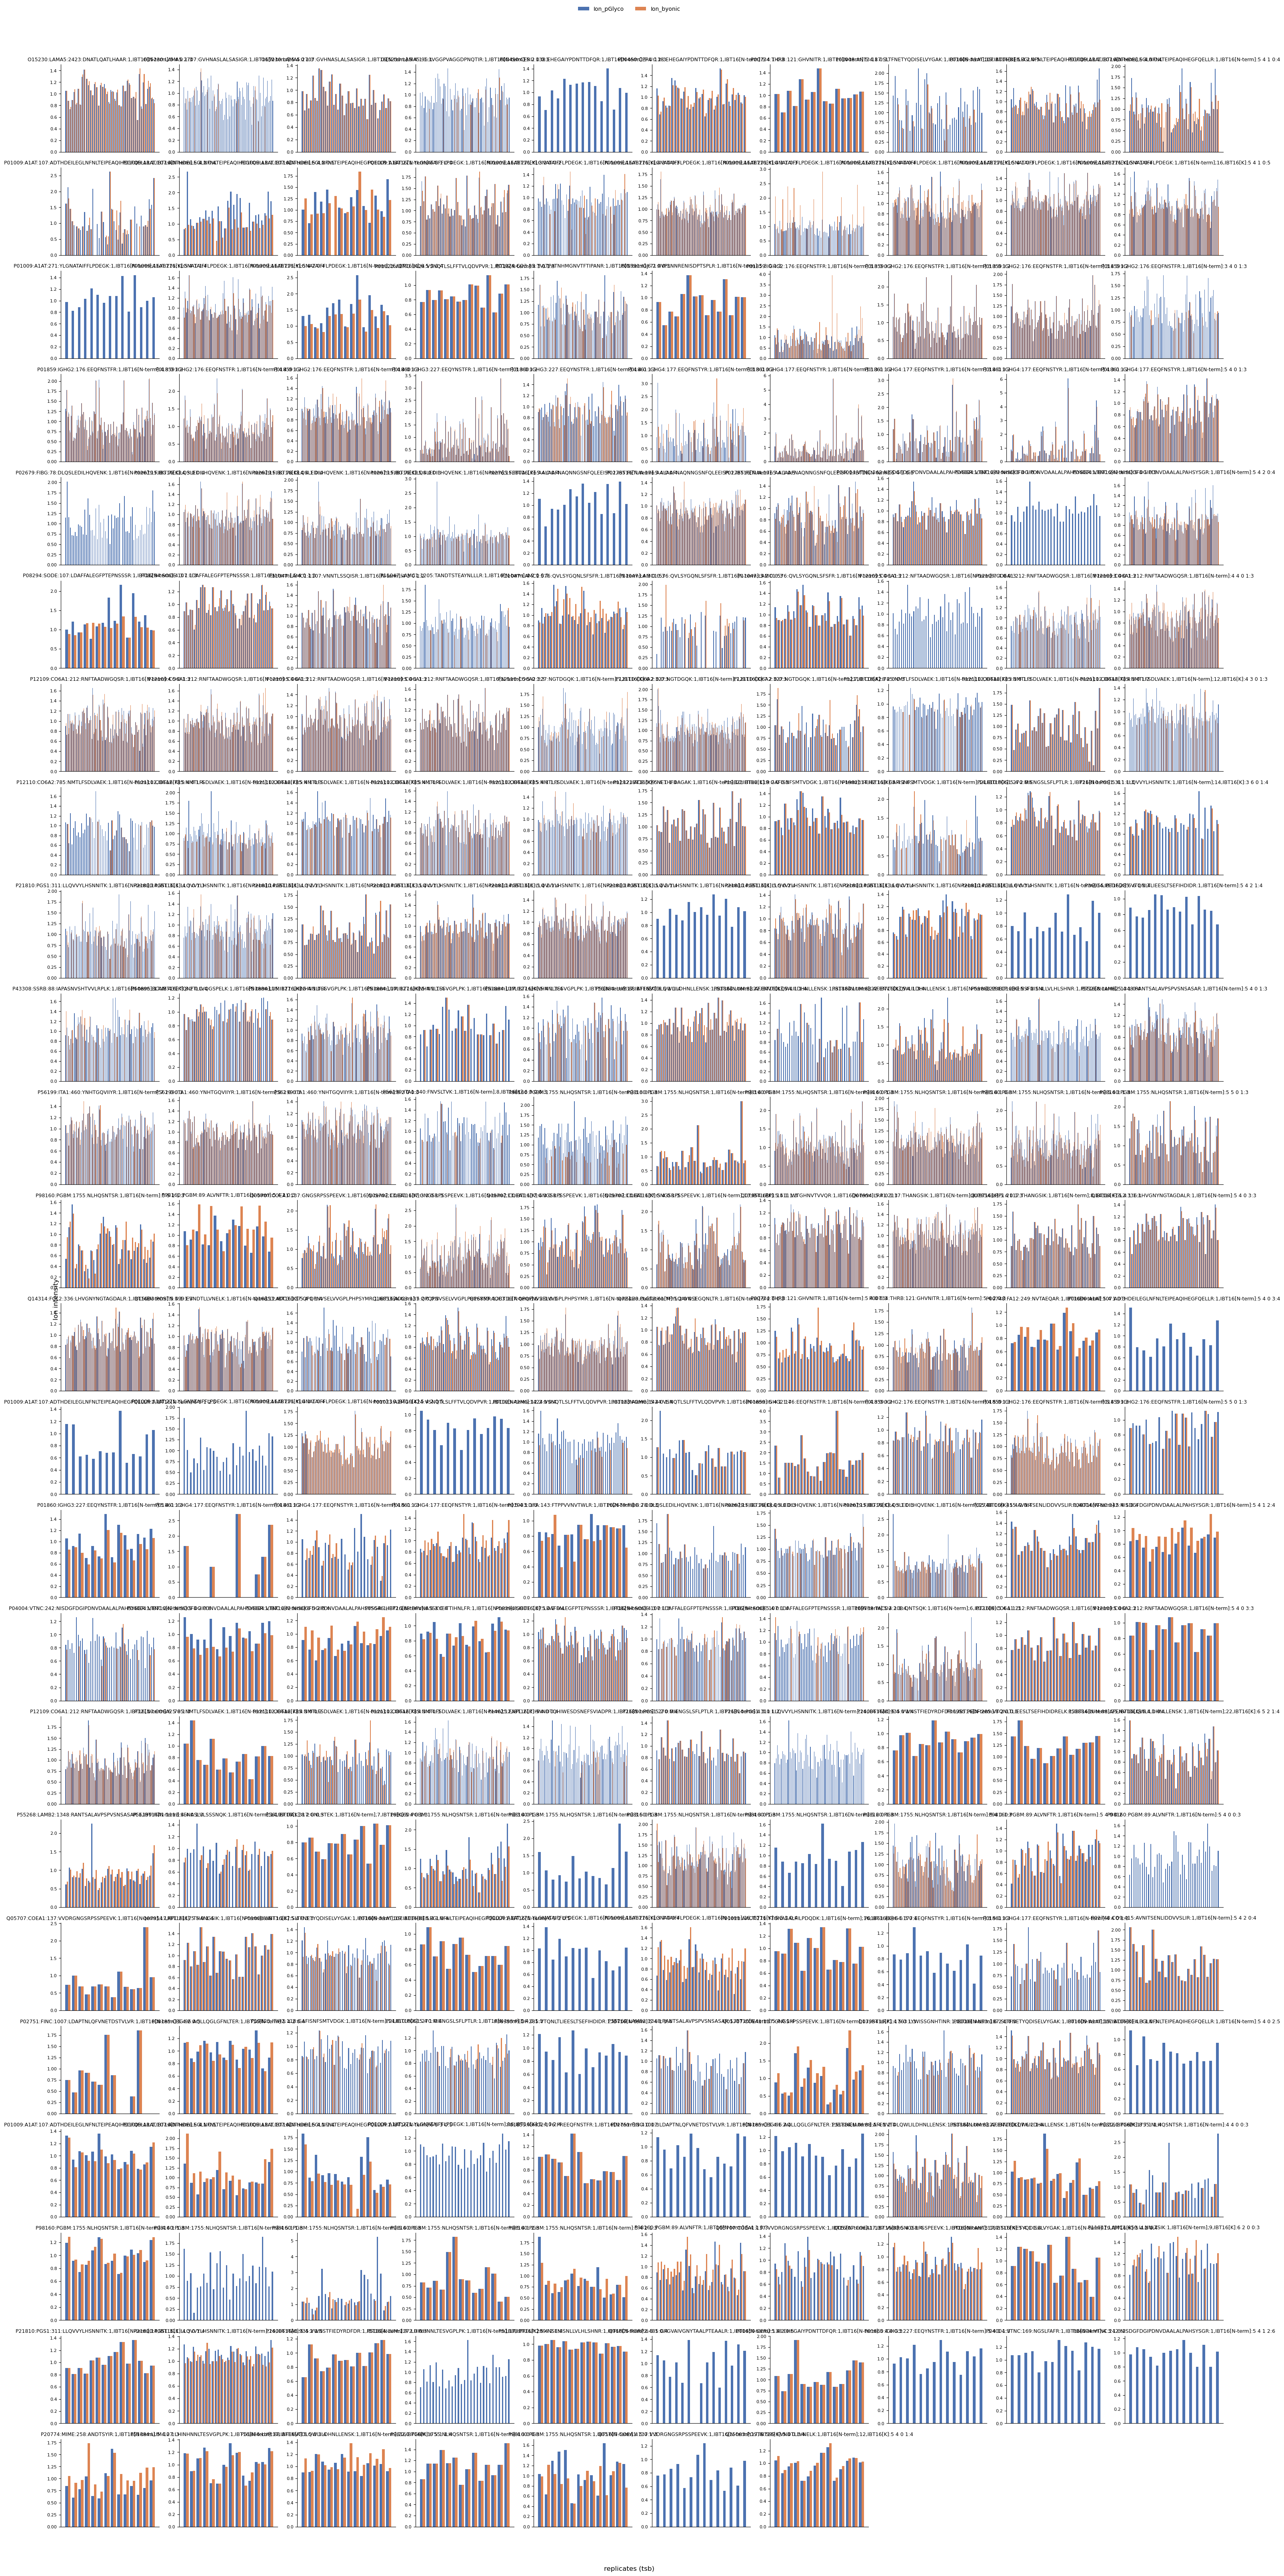

In [398]:
import numpy as np
import matplotlib.pyplot as plt

gids = df['GID'].unique()
n = len(gids)
ncol = min(10, n)
nrow = int(np.ceil(n / ncol))

fig, axes = plt.subplots(nrow, ncol,
                         figsize=(ncol * 3, nrow * 2.6),
                         squeeze=False)
axes_flat = axes.flatten()

w = 0.4
for ax, gid in zip(axes_flat, gids):
    sub = df[df['GID'] == gid]          # keeps row order (each tsb)
    x = np.arange(len(sub))
    ax.bar(x - w/2, sub['Ion_pGlyco'], w, color='#4C72B0', label='Ion_pGlyco')
    ax.bar(x + w/2, sub['Ion_byonic'], w, color='#DD8452', label='Ion_byonic')

    ax.set_title(str(gid), fontsize=9)
    ax.set_xticks([])                   # hide tsb on X
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=8)

# blank out any unused panels
for ax in axes_flat[n:]:
    ax.set_visible(False)

# one shared legend
handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2,
           frameon=False, bbox_to_anchor=(0.5, 1.02))

fig.supxlabel('replicates (tsb)', y=-0.01)
fig.supylabel('Ion intensity')
fig.tight_layout()
fig1 = fig
plt.show()

##### Diff scale across 2 methods

In [393]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

a = df['Ion_pGlyco'].to_numpy(float)
b = df['Ion_byonic'].to_numpy(float)

mask = (a > 0) & (b > 0)          # log ratio 要求两列都 >0
a, b = a[mask], b[mask]

logr = np.log2(a / b)                     # >0: pGlyco 高;<0: byonic 高
A    = 0.5 * (np.log2(a) + np.log2(b))    # 平均 log 强度

In [414]:
len(logr)

7637

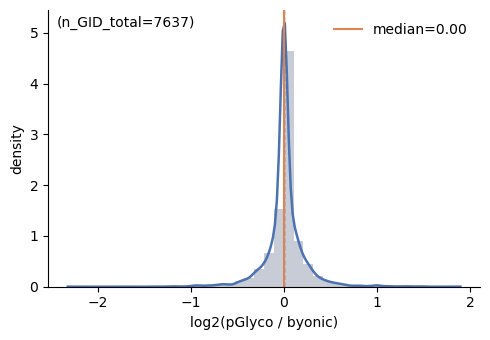

In [415]:
# ① log ratio 分布(直方图 + KDE) — 一眼看整体偏向哪个引擎、离散程度:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(logr, bins=40, density=True, color='#B0B7C6', alpha=.7)
xs = np.linspace(logr.min(), logr.max(), 200)
ax.plot(xs, gaussian_kde(logr)(xs), color='#4C72B0', lw=1.8)
ax.axvline(0, color='0.3', ls='--', lw=1)
ax.axvline(np.median(logr), color='#DD8452', lw=1.5,
           label=f'median={np.median(logr):.2f}')
ax.text(
    0.02, 0.98,
    f"(n_GID_total={len(logr)})", # , dropped={x1.shape[0]-len(per_gid_r)}
    transform=ax.transAxes, va="top"
)
ax.set_xlabel('log2(pGlyco / byonic)'); ax.set_ylabel('density')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig2 = fig
fig.tight_layout()
plt.show()

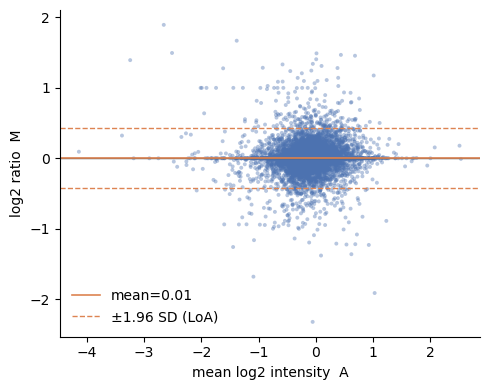

In [395]:
# ② MA / Bland-Altman 图 — 这张最有信息量:x 是平均 log 强度,y 是 log ratio,能看出分歧是否依赖丰度(常见现象:低丰度处两引擎差异大、高丰度处趋同):

fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(A, logr, s=8, alpha=.4, color='#4C72B0', edgecolor='none')
m, sd = logr.mean(), logr.std(ddof=1)
ax.axhline(0, color='0.3', lw=1)
ax.axhline(m, color='#DD8452', lw=1.2, label=f'mean={m:.2f}')
ax.axhline(m + 1.96*sd, color='#DD8452', ls='--', lw=1)
ax.axhline(m - 1.96*sd, color='#DD8452', ls='--', lw=1, label='±1.96 SD (LoA)')
ax.set_xlabel('mean log2 intensity  A'); ax.set_ylabel('log2 ratio  M')
ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig3 = fig
fig.tight_layout(); plt.show()

In [396]:
db.exporting(xlongx, 'export_big/gly_merge_methods_xlongx')

[09/12 09:38:48] writing 1 file with 10473 lines at 
	[PROJECT_ROOT]/export_big/gly_merge_methods_xlongx.dfx


In [399]:
fig1.savefig('export_big/gly_merge_bar_side_by_side.pdf')
fig2.savefig('export_big/gly_merge_log_ratio.pdf')
fig3.savefig("export_big/gly_merge_Bland-Altman.pdf")

##### pearson corr

In [407]:
(x1.columns == x2.columns).all(), (x1.index == x2.index).all()

(True, True)

In [406]:
x1.shape, x2.shape

((237, 86), (237, 86))

In [408]:
# x1, x2: rows = GIDs; columns = patients
# Pearson r for each GID, using matched patient values
per_gid_r = x1.corrwith(x2, axis=1, method="pearson")

# Drop GIDs with insufficient paired values or a constant profile
per_gid_r = per_gid_r.dropna()

print(per_gid_r.head())
print("median:", per_gid_r.median(), "n_GID:", len(per_gid_r))

GID
P01023:A2MG:1424:VSNQTLSLFFTVLQDVPVR:1,IBT16[N-term]:5 4 0 1:4           0.844759
P04004:VTNC:242:NISDGFDGIPDNVDAALALPAHSYSGR:1,IBT16[N-term]:6 5 2 0:4    0.645352
P19823:ITIH2:118:GAFISNFSMTVDGK:1,IBT16[N-term];14,IBT16[K]:5 4 1 0:3    0.884696
P01023:A2MG:1424:VSNQTLSLFFTVLQDVPVR:1,IBT16[N-term]:4 3 0 1:3           1.000000
P21810:PGS1:311:LLQVVYLHSNNITK:1,IBT16[N-term];14,IBT16[K]:5 4 0 1:3     0.982114
dtype: float64
median: 0.933875253519078 n_GID: 206


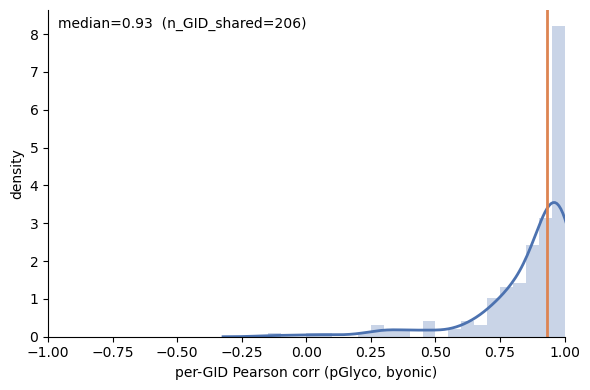

In [416]:
fig, ax = plt.subplots(figsize=(6, 4))

sns.histplot(
    per_gid_r,
    bins=40,
    binrange=(-1, 1),
    stat="density",
    color="#4C72B0",
    alpha=0.30,
    edgecolor=None,
    ax=ax,
)
sns.kdeplot(per_gid_r, color="#4C72B0", linewidth=2, ax=ax)

median_r = per_gid_r.median()
ax.axvline(median_r, color="#DD8452", linewidth=2)

ax.text(
    0.02, 0.98,
    f"median={median_r:.2f}  (n_GID_shared={len(per_gid_r)})", # , dropped={x1.shape[0]-len(per_gid_r)}
    transform=ax.transAxes, va="top"
)

ax.set(
    xlim=(-1, 1),
    xlabel="per-GID Pearson corr (pGlyco, byonic)",
    ylabel="density",
)
sns.despine()
fig4 = fig
plt.tight_layout()
plt.show()

In [419]:
fig4.savefig("export_big/gly_merge_Pearson-corr.pdf")

### 合并2次的结果

In [360]:
def count_substring(string, sub_string):
    count = 0
    for i in range(len(string)):
        if string[i:].startswith(sub_string):
            count += 1
    return count

In [363]:
des1 = db.importing('external_data/Glycosylation/pGlyco/gly_mat_id_des.dfx')
des2 = db.importing('external_data/Glycosylation/byonic/gly_mat_id_des.dfx')

[09/06 02:15:21]reading external_data/Glycosylation/pGlyco/gly_mat_id_des.dfx
[09/06 02:15:21]reading external_data/Glycosylation/byonic/gly_mat_id_des.dfx


In [364]:
for i in des1['Proteins']:
    if count_substring(i,'_HUMAN') > 1:
        print(i)
        break
else:
    print('all one')

sp|Q08722|CD47_HUMAN;sp|Q08722-2|CD47_HUMAN;sp|Q08722-3|CD47_HUMAN;sp|Q08722-4|CD47_HUMAN


In [278]:
'pGlyco','不重复Spectrum_ID数',des1['Spectrum_ID'].un(), '总Spectrum_ID数',des1.shape[0]

('pGlyco', '不重复Spectrum_ID数', 736, '总Spectrum_ID数', 741)

In [279]:
'byonic','不重复Spectrum_ID数', des2['Spectrum_ID'].un(), '总Spectrum_ID数',des2.shape[0]

('byonic', '不重复Spectrum_ID数', 1259, '总Spectrum_ID数', 1283)

In [373]:
b = set(des2['GID'])
p = set(des1['GID'])
u = b | p
x = b & p

b = len(b)
p = len(p)
u = len(u)
x = len(x)
print(f"Byonic = {b}, pGlyco = {p}, intersection = {x}, union = {u}" )
print(f'%pGlyco_only = {(p - x)/u:.2%}\n%Bionic_only = {(b - x)/u:.2%}\n%intersect = {x/u:.2%}' )

Byonic = 1283, pGlyco = 741, intersection = 237, union = 1787
%pGlyco_only = 28.20%
%Bionic_only = 58.53%
%intersect = 13.26%


%pGlyco_only = 28.20%
%Bionic_only = 58.53%
%intersect = 13.26%


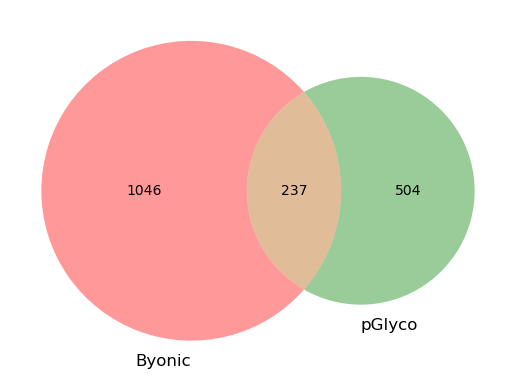

In [367]:
fig = plot_venns(des2['GID'], des1['GID'], labels=['Byonic','pGlyco'], )
fig

In [ ]:
fig.savefig('')

In [280]:
# from Bio import SeqIO
# import pandas as pd

# def read_fastq(file):
#     # Parse the fastq file
#     records = list(SeqIO.parse(file, "fastq"))

#     # Create lists to store the data
#     ids = []
#     seqs = []
#     qualities = []

#     # Loop over the records
#     for record in records:
#         ids.append(record.id)
#         seqs.append(str(record.seq))
#         qualities.append(record.letter_annotations["phred_quality"])

#     # Create a dataframe
#     df = pd.DataFrame({
#         'id': ids,
#         'sequence': seqs,
#         'quality': qualities
#     })

#     return df

# # Use the function
# df = read_fastq("your_file.fastq")
# print(df)

In [281]:
x = set(des2.columns) & set(des1.columns)
# x = [
#     'GID',
#     'Protein_Name',
#     'Protein_ID',
#     'sPeptide',
#     'Glycan(H,N,A,F)',
#     'sMod',
#     'sCharge',
#     'sProSites',
#     'Peptide',
#     'ProSites',
#     'Charge',
#     'Proteins',
#     'Rank',
#     'Spectrum_ID',
#     'Supp_Info',
#     'batch',
#     'repeat',
#     'GlycanComposition' 
#     ]
front = [
    'GID',
    'Protein_Name',
    'Protein_ID',
    'sPeptide',
    'sProPos',
    'sGlycan',
    'sMod',
    'sCharge',
    'Spectrum_ID'
]
x = front + [i for i in x if i not in front]
print(x)

d1 = des1[x].copy()
d2 = des2[x].copy()
d1['tool'] = 'pGlyco'
d2['tool'] = 'byonic'

['GID', 'Protein_Name', 'Protein_ID', 'sPeptide', 'sProPos', 'sGlycan', 'sMod', 'sCharge', 'Spectrum_ID', 'batch', 'Rank', 'Peptide', 'Proteins', 'Charge', 'Glycan(H,N,A,F)', 'Empty_Separator', 'GlyMass', 'Glytoucan_search', 'GlycanComposition', 'Supp_Info', 'repeat']


#### merge 

In [282]:
mat1 = db.importing('external_info/Glycosylation/pGlyco/gly_mat_na.dfx',index_col=0)
mat2 = db.importing('external_info/Glycosylation/byonic/gly_mat_na.dfx',index_col=0)

[07/26 08:44:58]reading external_info/Glycosylation/pGlyco/gly_mat_na.dfx
[07/26 08:44:58]reading external_info/Glycosylation/byonic/gly_mat_na.dfx


In [288]:
has_two = []

if (mat1.columns==mat2.columns).mean():
    x = list(set(mat1.index) & set(mat2.index))

    m = []
    m2 = mat1.loc[x,:]
    cnt = 0
    cnt2 = 0
    for i,j in zip(mat1.loc[x,:].values,mat2.loc[x,:].values):
        v = []
        for ii,jj in zip(i,j):
            ai = pd.isna(ii)
            aj = pd.isna(jj)
            if ai and not aj:
                v.append(jj)
                cnt2 +=1
            elif not ai and aj:
                v.append(ii)
                cnt2 +=1
            elif not ai and not aj:
                cnt += 1
                v.append(ii) # use pGlyco values instead of max(ii,jj)
                has_two.append([ii,jj])
            else:
                v.append(np.nan)
        v = np.array(v)
        m.append(v)
    m = pd.DataFrame(m,index=m2.index,columns=m2.columns)  

    print('2次都鉴定到值的GID:',cnt,'只有1次有值另一次是NA的GID:',cnt2)
else:
    raise Exception('!')

2次都鉴定到值的GID: 7680 只有1次有值另一次是NA的GID: 6692


In [289]:
m

,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,P09,P13,P15,P26,P27,P29,P39,P40,P45,P50,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
GID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"P01009:A1AT:107:ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR:1,IBT16[N-term]:6 5 3 0:5",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.839258,0.865962,1.372499,0.920340,0.965263,0.943917,0.782698,0.871434,0.000000,1.323992,1.762732,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.158511,1.142052,0.731184,1.402421,1.376744,1.321938,1.168810,1.265691,1.203049,1.909198,1.027843,1.288989,1.033029,1.218325,1.053963
"P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:3 3 0 0:2",0.734760,1.069202,0.851987,0.936552,0.818217,0.797288,1.191778,0.869704,0.897958,0.847700,0.488882,1.003221,1.459040,1.070585,0.707399,0.459529,0.800520,1.555047,0.462050,0.818513,1.288334,0.686892,0.288266,0.318738,1.248457,...,0.526383,1.066317,0.689360,1.097564,0.240535,1.159920,1.034319,1.070290,1.217981,0.993724,1.096567,0.299475,0.311799,0.681821,0.515709,1.558621,0.988234,0.871308,0.970583,0.430872,0.776591,0.829186,0.638277,1.518287,0.753705
"P21810:PGS1:311:LLQVVYLHSNNITK:1,IBT16[N-term];14,IBT16[K]:5 4 0 1:4",1.021668,0.861505,1.012026,0.986328,0.679328,0.730703,0.922276,1.340309,1.018588,0.715462,0.861829,0.962353,1.003867,1.069297,1.142005,0.872680,0.949737,0.798039,0.654574,1.374337,1.037656,0.680177,0.676274,0.729314,1.146843,...,1.012626,0.839418,1.138893,1.166788,1.228878,0.944400,1.407036,1.184907,1.096722,0.952598,0.908656,0.673150,1.006232,0.950572,1.414848,1.280911,1.045459,1.167308,0.806745,1.063270,0.774552,1.420553,0.742581,1.245314,0.994668
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.201849,0.583452,0.202225,0.751840,0.814440,0.485693,1.417313,0.957165,0.000000,0.442753,0.000000,0.759853,0.000000,1.756236,0.000000,0.486778,0.000000,2.512637,0.000000,0.000000,1.542686,0.738698,0.000000,0.000000,1.193226,...,0.803126,1.065630,1.428065,0.000000,0.000000,0.651113,0.856608,1.761038,0.789802,0.561838,0.862527,0.228025,0.107083,0.592512,0.554057,1.291385,0.669410,0.411127,0.797667,0.294745,0.723860,0.933419,0.617389,0.600713,0.548645
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",0.903577,0.882709,1.298107,1.536045,1.124223,1.067574,1.123155,1.193156,0.987149,0.854540,1.466271,1.236390,1.610913,1.716895,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.103381,1.403024,1.690810,1.283767,1.354312,1.128060,1.290634,1.061423,0.815495,1.039241,1.182622,1.526242,1.011812,0.926396,0.616189,1.094275,0.903657,1.188033,0.822451,1.144987,1.242215,0.961175,1.133595,1.282109,1.503111
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",0.813822,1.074543,1.054827,0.973909,0.928979,0.718204,0.930361,1.348061,1.521240,1.175710,0.863623,1.148037,1.887907,0.875182,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.184195,0.000000,0.498035,0.662351,0.752241,0.000000,0.000000,0.000000,0.000000,0.742010,0.000000,1.008248,0.000000,0.826555,0.000000


In [290]:
mat_all = pd.concat([mat1.loc[~mat1.index.isin(m.index),:],
                     mat2.loc[~mat2.index.isin(m.index),:],
                     m
                    ])
mat_all

des_all = pd.concat([des1,des2]).drop_duplicates('GID').set_index('GID').loc[mat_all.index,:].reset_index()

desx = pd.concat([d1,d2],axis=0,ignore_index=True).drop_duplicates('GID',keep='first')
desx


,GID,Protein_Name,Protein_ID,sPeptide,sProPos,sGlycan,sMod,sCharge,Spectrum_ID,batch,Rank,Peptide,Proteins,Charge,"Glycan(H,N,A,F)",Empty_Separator,GlyMass,Glytoucan_search,GlycanComposition,Supp_Info,repeat,tool
0,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,...",CD47,Q08722,DIYTFDGALNK,73,5 2 0 0,"1,IBT16[N-term];11,IBT16[K]",3,27788.27788,1,1,DIYTFDGALJK,sp|Q08722|CD47_HUMAN;sp|Q08722-2|CD47_HUMAN;sp...,3,5 2 0 0,NaN,1216.42286,"5 hex, 2 hexnac, 0 neu5ac, 0 dhex",H(5)N(2),NaN,E,pGlyco
1,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term...",APMAP,Q9HDC9,AGPNGTLFVADAYK,160,3 3 0 1,"1,IBT16[N-term];14,IBT16[K]",3,26727.26727,1,1,AGPJGTLFVADAYK,sp|Q9HDC9|APMAP_HUMAN;sp|Q9HDC9-2|APMAP_HUMAN,3,3 3 0 1,NaN,1241.45450,"3 hex, 3 hexnac, 0 neu5ac, 1 dhex",H(3)N(3)F(1),NaN,E,pGlyco
2,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",MFAP4,P55083,FNGSVSFFR,111;87,3 2 0 0,"1,IBT16[N-term]",3,25538.25538,1,1,FJGSVSFFR,sp|P55083|MFAP4_HUMAN;sp|P55083-2|MFAP4_HUMAN,3,3 2 0 0,NaN,892.31722,"3 hex, 2 hexnac, 0 neu5ac, 0 dhex",H(3)N(2),NaN,E,pGlyco
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021,P01009:A1AT:107:ADTHDEILEGLNFNLTEIPEAQIHEGFQEL...,A1AT,P01009,ADTHDEILEGLNFNLTEIPEAQIHEGFQELLR,107,4 5 1 0,"1,IBT16[N-term]",4,42233.42233,6,2,K.[+277.18814].ADTHDEILEGLNFN[+2261.79390]LTEI...,>sp|P01009|A1AT_HUMAN Alpha-1-antitrypsin OS=H...,4,4 5 1 0,NaN,2261.79390,"4 hex, 5 hexnac, 1 neu5ac, 0 dhex",H(4)N(5)A(1),NaN,5,byonic
2022,P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVN...,CO6A1,P12109,ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,6 5 0 1,"1,IBT16[N-term];19,Oxidation[M]",4,42394.42394,6,3,R.[+277.18814].ASLQFLQN[+2133.77171]YTALASAVDA...,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,4,6 5 0 1,NaN,2133.77171,"6 hex, 5 hexnac, 0 neu5ac, 1 dhex",H(6)N(5)F(1),NaN,5,byonic
2023,P12109:CO6A1:896:ASLQFLQNYTALASAVDAMDFINDATDVN...,CO6A1,P12109,ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,896,5 4 2 1,"1,IBT16[N-term];19,Oxidation[M]",4,42923.42923,6,3,R.[+277.18814].ASLQFLQN[+2350.83035]YTALASAVDA...,>sp|P12109|CO6A1_HUMAN Collagen alpha-1(VI) ch...,4,5 4 2 1,NaN,2350.83035,"5 hex, 4 hexnac, 2 neu5ac, 1 dhex",H(5)N(4)A(2)F(1),NaN,5,byonic


In [291]:
x = set(des1.columns) & set(des2.columns)

base = 'external_info/Glycosylation/merged/'
db.exporting(mat_all, 'gly_mat_na',outputdir=base)
db.exporting(des_all, 'gly_mat_id_des_ori' , outputdir=base)
db.exporting(desx, 'gly_mat_id_des_x' , outputdir=base)

None



[07/26 08:59:16] overwritting 1 file with 1787 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/merged/gly_mat_na.dfx
[07/26 08:59:17] overwritting 1 file with 1787 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/merged/gly_mat_id_des_ori.dfx
[07/26 08:59:17] overwritting 1 file with 1787 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/merged/gly_mat_id_des_x.dfx


#### 糖型分类

In [294]:
des = db.importing('external_info/Glycosylation/merged/gly_mat_id_des_ori.dfx')
anno = des['sGlycan'].str.split(' ',regex=False,expand=True).apply(lambda i:i.astype(int),0)
anno.columns = ['H','N',"A",'F']

des = pd.concat([anno,des],axis=1)
des['GlycanType'] = ""
des


[07/26 09:01:31]reading external_info/Glycosylation/merged/gly_mat_id_des_ori.dfx


,H,N,A,F,GID,GlySpec,batch,repeat,PepSpec,RawName,Scan,RT,PrecursorMH,PrecursorMZ,Charge,Rank,Peptide,Mod,PeptideMH,"Glycan(H,N,A,F)",GlycanComposition,PlausibleStruct,GlyID,GlyFrag,GlyMass,...,sGlycan,Glytoucan_search,Spectrum,Comment,Mass (M+H),Observed,One-Off,Err (ppm),Obs m/z,Prot#,NumUniq,Protein Name,Position,Cleavage,Score,Delta,DeltaMod,Z-score,LogProb,Composition,ScanNumberList,ScanTimeList,Unnamed: 40,ProPos,GlycanType
0,5,2,0,0,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,...",20230712-SHL-1-P-1-E.27788.27788.3.0.dta,1,E,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,20230712-SHL-1-P-1-E,27788.0,5495.40180,3027.41167,1009.80874,3,1,DIYTFDGALJK,"1,IBT16[N-term];11,IBT16[K];",1810.99200,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H)(H))))),2257.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,...,5 2 0 0,"5 hex, 2 hexnac, 0 neu5ac, 0 dhex",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1,3,3,0,1,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term...",20230712-SHL-1-P-1-E.26727.26727.3.0.dta,1,E,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,20230712-SHL-1-P-1-E,26727.0,5289.04465,3219.54850,1073.85435,3,1,AGPJGTLFVADAYK,"1,IBT16[N-term];14,IBT16[K];",1978.09786,3 3 0 1,H(3)N(3)F(1),(N(N(H(H)(H(N(F)))))),2266.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 3 0 ...,1241.45450,...,3 3 0 1,"3 hex, 3 hexnac, 0 neu5ac, 1 dhex",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
2,3,2,0,0,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",20230712-SHL-1-P-1-E.25538.25538.3.2.dta,1,E,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,20230712-SHL-1-P-1-E,25538.0,5066.89294,2230.02395,744.01283,3,1,FJGSVSFFR,"1,IBT16[N-term];",1337.70919,3 2 0 0,H(3)N(2),(N(N(H(H)(H)))),2291.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;,892.31722,...,3 2 0 0,"3 hex, 2 hexnac, 0 neu5ac, 0 dhex",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1784,4,3,0,1,"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3...",20230712-SHL-1-P-E.6499.6499.2.0.dta,1,E0,20230712-SHL-1-P-E.6499.6499.2.0.dta,20230712-SHL-1-P-E,6499.0,1644.24889,2854.20670,1427.60699,2,1,EEQFJSTYR,"1,IBT16[N-term];",1450.70521,4 3 0 1,H(4)N(3)F(1),(N(N(H(H)(H(N(H(F))))))),2271.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;3 2 0 ...,1403.50732,...,4 3 0 1,"4 hex, 3 hexnac, 0 neu5ac, 1 dhex",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1785,3,3,0,1,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3...",20230713-SHL-1-P-E.1947.1947.3.1.dta,1,E0,20230713-SHL-1-P-E.1947.1947.3.1.dta,20230713-SHL-1-P-E,1947.0,684.51278,2575.15452,859.05636,3,1,NLHQSJTSR,"1,IBT16[N-term];",1333.70623,3 3 0 1,H(3)N(3)F(1),(N(F)(N(H(H)(H(N))))),720.0,0 1 0 0;0 1 0 1;0 2 0 0;0 2 0 1;1 2 0 0;1 2 0 ...,1241.45450,...,3 3 0 1,"3 hex, 3 hexnac, 0 neu5ac, 1 dhex",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,
1786,5,2,0,0,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2...",20230814-FP-Nglyco-PE-3_4.2386.2386.3.0.dta,3,4,20230814-FP-Nglyco-PE-3_4.2386.2386.3.0.dta,20230814-FP-Nglyco-PE-3_4,2386.0,986.98322,2550.11567,850.71007,3,1,NLHQSJTSR,"1,IBT16[N-term];",1333.70623,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H)(H))))),2257.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,...,5 2 0 0,"5 hex, 2 hexnac, 0 neu5ac, 0 dhex",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,


In [295]:

# mannose
mask = (des['N']==2)
des['HighMannose'] = ""
des.loc[mask & (des['H']<=3),'HighMannose'] = 'PauciMan'
des.loc[mask & (des['H']>3),'HighMannose'] = 'HighMan'
des.loc[mask & (des['F']==2),"HighMannose"] = ""

# fucose
des['Fucose'] = ""
des.loc[des['F']>=1,'Fucose'] = 'FUC'
# des.loc[(des['F']==1) & (fu['GlyFrag'].str.contains('0 1 0 1').fillna(False)),'Fucose'] = 'CoreFUC'

# sialic acid
des['Sialic Acid'] = ""
des.loc[des['A']>=1,'Sialic Acid'] = 'SIA'

# bisect, enzyme GnT-III
des['Bisect'] = ""
des.loc[(des['GlyFrag'].str.contains('1 3 0 0').fillna(False)) |\
        (des['GlyFrag'].str.contains('1 3 0 1').fillna(False)), 'Bisect'] = 'Bisect'


In [296]:
db.exporting(des, 'external_info/Glycosylation/merged/gly_mat_id_des_+class.dfx')

[07/26 09:03:49] overwritting 1 file with 1787 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/merged/gly_mat_id_des_+class.dfx


#### Fill NA

In [305]:
%%R

base = 'external_info/Glycosylation/merged/'

gly_raw = db.importing(file.path(base, 'gly_mat_na.dfx'), row.names=1)
# filter out pCR

gly = SeqKnn::SeqKNN(gly_raw, k = 12)

gly %>% ydumpto('gly_mat_filled',outputdir = base)



[1] "[ 2026-07-26 09:16:54 ]  read [ gly_mat_na.dfx ] as ' gly_mat_na ' from >  external_info/Glycosylation/merged"
1607
[1] "[ 2026-07-26 09:16:57 ]  write 1 < dfx > at external_info/Glycosylation/merged/gly_mat_filled.dfx"
[1] "external_info/Glycosylation/merged/gly_mat_filled.dfx"


#### 合并层次

In [317]:
des = db.importing('external_info/Glycosylation/merged/gly_mat_id_des_+class.dfx')
des

[07/26 09:27:19]reading external_info/Glycosylation/merged/gly_mat_id_des_+class.dfx


,H,N,A,F,GID,GlySpec,batch,repeat,PepSpec,RawName,Scan,RT,PrecursorMH,PrecursorMZ,Charge,Rank,Peptide,Mod,PeptideMH,"Glycan(H,N,A,F)",GlycanComposition,PlausibleStruct,GlyID,GlyFrag,GlyMass,...,Mass (M+H),Observed,One-Off,Err (ppm),Obs m/z,Prot#,NumUniq,Protein Name,Position,Cleavage,Score,Delta,DeltaMod,Z-score,LogProb,Composition,ScanNumberList,ScanTimeList,Unnamed: 40,ProPos,GlycanType,HighMannose,Fucose,Sialic Acid,Bisect
0,5,2,0,0,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,...",20230712-SHL-1-P-1-E.27788.27788.3.0.dta,1,E,20230712-SHL-1-P-1-E.27788.27788.3.0.dta,20230712-SHL-1-P-1-E,27788.0,5495.40180,3027.41167,1009.80874,3,1,DIYTFDGALJK,"1,IBT16[N-term];11,IBT16[K];",1810.99200,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H)(H))))),2257.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HighMan,NaN,NaN,NaN
1,3,3,0,1,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term...",20230712-SHL-1-P-1-E.26727.26727.3.0.dta,1,E,20230712-SHL-1-P-1-E.26727.26727.3.0.dta,20230712-SHL-1-P-1-E,26727.0,5289.04465,3219.54850,1073.85435,3,1,AGPJGTLFVADAYK,"1,IBT16[N-term];14,IBT16[K];",1978.09786,3 3 0 1,H(3)N(3)F(1),(N(N(H(H)(H(N(F)))))),2266.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;2 3 0 ...,1241.45450,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FUC,NaN,NaN
2,3,2,0,0,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",20230712-SHL-1-P-1-E.25538.25538.3.2.dta,1,E,20230712-SHL-1-P-1-E.25538.25538.3.2.dta,20230712-SHL-1-P-1-E,25538.0,5066.89294,2230.02395,744.01283,3,1,FJGSVSFFR,"1,IBT16[N-term];",1337.70919,3 2 0 0,H(3)N(2),(N(N(H(H)(H)))),2291.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;,892.31722,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PauciMan,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1784,4,3,0,1,"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3...",20230712-SHL-1-P-E.6499.6499.2.0.dta,1,E0,20230712-SHL-1-P-E.6499.6499.2.0.dta,20230712-SHL-1-P-E,6499.0,1644.24889,2854.20670,1427.60699,2,1,EEQFJSTYR,"1,IBT16[N-term];",1450.70521,4 3 0 1,H(4)N(3)F(1),(N(N(H(H)(H(N(H(F))))))),2271.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;3 2 0 ...,1403.50732,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FUC,NaN,NaN
1785,3,3,0,1,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3...",20230713-SHL-1-P-E.1947.1947.3.1.dta,1,E0,20230713-SHL-1-P-E.1947.1947.3.1.dta,20230713-SHL-1-P-E,1947.0,684.51278,2575.15452,859.05636,3,1,NLHQSJTSR,"1,IBT16[N-term];",1333.70623,3 3 0 1,H(3)N(3)F(1),(N(F)(N(H(H)(H(N))))),720.0,0 1 0 0;0 1 0 1;0 2 0 0;0 2 0 1;1 2 0 0;1 2 0 ...,1241.45450,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FUC,NaN,NaN
1786,5,2,0,0,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2...",20230814-FP-Nglyco-PE-3_4.2386.2386.3.0.dta,3,4,20230814-FP-Nglyco-PE-3_4.2386.2386.3.0.dta,20230814-FP-Nglyco-PE-3_4,2386.0,986.98322,2550.11567,850.71007,3,1,NLHQSJTSR,"1,IBT16[N-term];",1333.70623,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H)(H))))),2257.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HighMan,NaN,NaN,NaN


In [318]:
mat = db.importing('external_info/Glycosylation/merged/gly_mat_filled.dfx')
num_cols = mat.columns

sel_cols = ['GID','H','N','A','F','sPeptide','GlycanComposition','sGlycan','Protein_Name','sProPos','Protein_ID','sCharge','HighMannose','Fucose','Sialic Acid','Bisect']

anno = des[sel_cols].copy()
anno['sProteinNameID'] = anno['Protein_ID'] + '_' + anno['Protein_Name']
anno['Glycosite'] = anno['sProteinNameID'] + ":" + anno['sProPos']
str_cols = anno.columns


df = pd.merge(anno,mat,left_on='GID',right_index=True,how='right')
df


[07/26 09:27:22]reading external_info/Glycosylation/merged/gly_mat_filled.dfx


,GID,H,N,A,F,sPeptide,GlycanComposition,sGlycan,Protein_Name,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite,P10,P16,P19,P25,P31,P36,P42,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
0,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,...",5,2,0,0,DIYTFDGALNK,H(5)N(2),5 2 0 0,CD47,73,Q08722,3,HighMan,NaN,NaN,NaN,Q08722_CD47,Q08722_CD47:73,1.460434,0.875232,1.140283,1.113961,0.689721,0.917821,0.953114,...,0.918028,0.862356,0.967913,1.022054,1.245253,1.005627,1.135797,1.104426,0.953120,0.921059,1.011358,0.750338,1.012668,0.911247,1.159548,1.384214,1.124929,1.230361,1.077634,1.137196,0.953815,1.224469,0.829180,1.159720,1.056966
1,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term...",3,3,0,1,AGPNGTLFVADAYK,H(3)N(3)F(1),3 3 0 1,APMAP,160,Q9HDC9,3,NaN,FUC,NaN,NaN,Q9HDC9_APMAP,Q9HDC9_APMAP:160,0.980364,0.883952,1.018809,1.033549,0.729328,0.894929,1.026400,...,0.914192,0.937314,0.993747,1.121365,1.122648,0.962733,1.178666,1.270963,1.117420,0.980111,0.956066,0.724706,1.031129,0.835977,1.268521,1.226571,0.929988,1.121186,0.929619,1.010970,0.943118,1.189545,0.862723,1.106126,1.045284
2,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",3,2,0,0,FNGSVSFFR,H(3)N(2),3 2 0 0,MFAP4,111;87,P55083,3,PauciMan,NaN,NaN,NaN,P55083_MFAP4,P55083_MFAP4:111;87,1.026541,0.861010,1.106466,1.026120,0.956040,0.817339,1.153881,...,0.894343,1.001520,0.980018,1.051546,1.198574,0.941860,0.991076,1.024260,0.971090,0.915412,0.875925,0.785796,0.919750,0.821351,1.108068,1.367655,1.011750,1.127344,1.160709,1.082432,0.955380,1.111752,0.963339,0.972280,1.191983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1784,"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3...",4,3,0,1,EEQFNSTYR,H(4)N(3)F(1),4 3 0 1,IGHG4,177,P01861,2,NaN,FUC,NaN,NaN,P01861_IGHG4,P01861_IGHG4:177,0.201849,0.583452,0.202225,0.751840,0.814440,0.485693,1.417313,...,0.803126,1.065630,1.428065,0.000000,0.000000,0.651113,0.856608,1.761038,0.789802,0.561838,0.862527,0.228025,0.107083,0.592512,0.554057,1.291385,0.669410,0.411127,0.797667,0.294745,0.723860,0.933419,0.617389,0.600713,0.548645
1785,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3...",3,3,0,1,NLHQSNTSR,H(3)N(3)F(1),3 3 0 1,PGBM,1755,P98160,3,NaN,FUC,NaN,NaN,P98160_PGBM,P98160_PGBM:1755,0.903577,0.882709,1.298107,1.536045,1.124223,1.067574,1.123155,...,2.103381,1.403024,1.690810,1.283767,1.354312,1.128060,1.290634,1.061423,0.815495,1.039241,1.182622,1.526242,1.011812,0.926396,0.616189,1.094275,0.903657,1.188033,0.822451,1.144987,1.242215,0.961175,1.133595,1.282109,1.503111
1786,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2...",5,2,0,0,NLHQSNTSR,H(5)N(2),5 2 0 0,PGBM,1755,P98160,3,HighMan,NaN,NaN,NaN,P98160_PGBM,P98160_PGBM:1755,0.813822,1.074543,1.054827,0.973909,0.928979,0.718204,0.930361,...,1.009765,0.950672,0.931961,0.969536,1.004889,0.983432,1.100677,1.110683,1.034620,1.023753,1.184195,0.000000,0.498035,0.662351,0.752241,0.000000,0.000000,0.000000,0.000000,0.742010,0.000000,1.008248,0.000000,0.826555,0.000000


In [319]:
DATA = {}
def my_drop(s):
    t = s.dtype
    if t=='object':
        r = s.sort_values().iloc[0]
    elif t=='float64':
        r = sum(s)
    else:
        r = s.iloc[0]
    return r
for vname, colname in [('Glycoprotein1','Protein_Name'),
                       ('Glycosite2','Glycosite'),
                       ('Glycans3','sGlycan'),
                       ('Glycopiptides4','GID'),
                      ]:
    matvname = 'mat'+vname
    desvname = 'des'+vname
    DATA[matvname] = df.groupby(colname,sort=False)[num_cols].agg("sum").copy()
    DATA[desvname] = df[str_cols].copy().groupby(colname,sort=False).agg(my_drop)
    display(DATA[matvname])
    display(DATA[desvname])
    
    db.exporting(DATA[matvname],matvname,outputdir='external_info/Glycosylation/washed/')
    db.exporting(DATA[desvname],desvname,outputdir='external_info/Glycosylation/washed/')
    
    

,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,P09,P13,P15,P26,P27,P29,P39,P40,P45,P50,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
Protein_Name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CD47,4.441858,3.779819,4.371516,4.048996,3.234434,3.542588,4.097416,4.629300,4.277776,3.886557,3.712699,4.524473,4.133570,4.538775,4.062991,3.761759,4.164687,4.009382,3.188949,5.801257,4.160625,3.433180,3.154056,3.514198,4.467424,...,4.152792,3.606734,4.125667,3.998986,4.699297,3.790648,4.905587,4.235637,3.645527,4.377990,4.002324,3.315825,3.966572,3.740521,4.390171,5.155426,4.278212,4.770528,4.479848,4.701738,3.703450,4.978838,3.459271,4.715326,4.304763
APMAP,0.980364,0.883952,1.018809,1.033549,0.729328,0.894929,1.026400,1.084660,1.022919,0.976259,0.800106,1.115954,1.093445,1.148254,1.132967,0.908379,0.911321,0.818591,0.757842,1.415306,0.972631,0.729582,0.730898,0.693676,0.896096,...,0.914192,0.937314,0.993747,1.121365,1.122648,0.962733,1.178666,1.270963,1.117420,0.980111,0.956066,0.724706,1.031129,0.835977,1.268521,1.226571,0.929988,1.121186,0.929619,1.010970,0.943118,1.189545,0.862723,1.106126,1.045284
MFAP4,115.596894,103.216628,124.580244,108.290633,95.411568,89.997471,120.375427,123.080065,109.740567,121.715541,124.802839,131.736983,114.130006,111.102080,135.939353,91.653153,98.149934,88.888299,77.892195,158.256362,103.201614,89.757937,84.491729,82.730002,107.930846,...,107.699510,112.000306,110.632764,121.717873,145.985178,106.309949,119.882424,121.621700,113.537413,110.481865,101.045897,90.452282,107.359319,95.961221,122.023435,155.575757,116.247406,132.352167,128.563569,127.592357,109.901927,129.191645,101.524351,115.358447,133.432458
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ACE,0.948125,0.905334,1.021342,0.874567,0.869191,0.913245,0.957084,1.147509,0.996376,0.915647,0.859100,1.036365,1.086783,0.958699,1.421277,0.660634,1.003894,0.700911,0.731636,0.986948,1.060836,0.663779,0.566220,0.759796,0.785853,...,1.009790,0.959177,0.939591,0.971430,1.074791,0.843695,1.031934,1.095458,1.089937,1.007734,1.032712,0.884219,1.344123,1.142872,1.176928,1.328039,0.920169,1.003955,1.251361,1.496975,0.978505,0.892061,1.094269,1.586524,1.005421
ITA3,2.027701,1.895685,2.027156,2.033360,1.589058,1.784089,1.952119,2.379879,2.196781,1.921998,1.691838,2.247210,2.107095,2.188300,2.363032,1.863280,1.862410,1.651717,1.494295,2.915245,1.971325,1.451775,1.516244,1.405688,1.843801,...,2.017635,1.893242,1.767837,1.954514,2.169850,1.892982,2.401217,2.642168,2.437683,2.060027,1.992631,1.489115,2.049575,1.780688,2.419868,2.697282,2.110206,2.302707,1.975667,2.309086,1.823140,2.540371,1.696129,2.234850,2.141948
PLGT3,1.046691,0.964266,1.070112,1.036470,0.828224,0.904069,1.025748,1.253081,1.107486,1.042580,0.895170,1.189240,1.078153,1.178421,1.167562,0.892804,0.948398,0.798038,0.721042,1.454144,0.977789,0.705068,0.690881,0.675149,0.899130,...,0.915182,0.938241,1.033259,0.935491,1.214011,0.911107,1.202114,1.448888,1.140477,0.939752,1.049789,0.752446,1.057639,0.928258,1.102002,1.366597,1.071865,1.016390,0.889579,1.040947,0.979479,1.046363,0.984115,1.011711,0.967642


,GID,H,N,A,F,sPeptide,GlycanComposition,sGlycan,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite
Protein_Name,,,,,,,,,,,,,,,,,
CD47,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,...",5,2,0,0,DIYTFDGALNK,H(5)N(2),5 2 0 0,73,Q08722,3,HighMan,FUC,SIA,NaN,Q08722_CD47,Q08722_CD47:73
APMAP,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term...",3,3,0,1,AGPNGTLFVADAYK,H(3)N(3)F(1),3 3 0 1,160,Q9HDC9,3,NaN,FUC,NaN,NaN,Q9HDC9_APMAP,Q9HDC9_APMAP:160
MFAP4,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",3,2,0,0,FNGSVSFFR,H(1)N(2),0 1 0 0,111;87,P55083,3,HighMan,FUC,SIA,Bisect,P55083_MFAP4,P55083_MFAP4:111;87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ACE,"P12821:ACE:509:NETHFDAGAK:1,IBT16[N-term];10,I...",9,2,0,0,NETHFDAGAK,H(9)N(2),9 2 0 0,509,P12821,3,HighMan,NaN,NaN,NaN,P12821_ACE,P12821_ACE:509
ITA3,"P26006:ITA3:935:VWNSTFIEDYRDFDR:1,IBT16[N-term...",8,2,0,0,VWNSTFIEDYRDFDR,H(8)N(2),8 2 0 0,935,P26006,3,HighMan,NaN,NaN,NaN,P26006_ITA3,P26006_ITA3:935
PLGT3,"Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-ter...",9,2,0,0,YFYLQAVNSEGQNLTR,H(9)N(2),9 2 0 0,61,Q7Z4H8,3,HighMan,NaN,NaN,NaN,Q7Z4H8_PLGT3,Q7Z4H8_PLGT3:61


[07/26 09:27:23] overwritting 1 file with 257 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/matGlycoprotein1.dfx
[07/26 09:27:23] overwritting 1 file with 257 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/desGlycoprotein1.dfx


,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,P09,P13,P15,P26,P27,P29,P39,P40,P45,P50,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
Glycosite,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Q08722_CD47:73,4.441858,3.779819,4.371516,4.048996,3.234434,3.542588,4.097416,4.629300,4.277776,3.886557,3.712699,4.524473,4.133570,4.538775,4.062991,3.761759,4.164687,4.009382,3.188949,5.801257,4.160625,3.433180,3.154056,3.514198,4.467424,...,4.152792,3.606734,4.125667,3.998986,4.699297,3.790648,4.905587,4.235637,3.645527,4.377990,4.002324,3.315825,3.966572,3.740521,4.390171,5.155426,4.278212,4.770528,4.479848,4.701738,3.703450,4.978838,3.459271,4.715326,4.304763
Q9HDC9_APMAP:160,0.980364,0.883952,1.018809,1.033549,0.729328,0.894929,1.026400,1.084660,1.022919,0.976259,0.800106,1.115954,1.093445,1.148254,1.132967,0.908379,0.911321,0.818591,0.757842,1.415306,0.972631,0.729582,0.730898,0.693676,0.896096,...,0.914192,0.937314,0.993747,1.121365,1.122648,0.962733,1.178666,1.270963,1.117420,0.980111,0.956066,0.724706,1.031129,0.835977,1.268521,1.226571,0.929988,1.121186,0.929619,1.010970,0.943118,1.189545,0.862723,1.106126,1.045284
P55083_MFAP4:111;87,16.005390,13.297964,17.312219,14.938572,12.572344,10.543357,16.027359,18.270684,15.002241,15.336916,16.871697,17.717592,14.209216,15.064364,17.306561,11.798426,12.660317,11.369872,10.235295,21.558324,13.532046,11.605216,11.303749,10.564715,14.226139,...,15.272429,14.687405,14.926668,17.874466,20.671403,15.590651,16.458696,15.351045,13.250994,14.837387,14.417408,12.537590,14.865742,13.069741,16.245203,21.651883,16.415885,18.510415,17.573284,15.806806,15.823392,18.131997,13.243776,17.489161,18.414402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P01011_AACT:271,0.918315,0.945551,1.007582,0.968587,0.922338,0.898008,1.121345,1.141570,1.024307,0.956308,0.949274,0.998435,1.195092,1.165104,1.340950,0.861208,0.831457,1.009638,0.928616,1.195181,1.006849,0.917038,0.723765,0.882029,0.959556,...,1.070472,0.956600,0.836872,0.894377,1.069459,0.827267,0.981890,1.075847,0.819141,1.027468,1.015639,0.895537,0.849156,0.952888,1.070161,1.138190,1.077526,0.990965,1.060572,1.243171,0.904784,1.246804,0.871410,1.036922,1.046755
P56199_ITA1:317,0.987808,0.925156,1.000149,1.073793,0.766237,0.876349,0.961555,1.257307,1.090776,0.927783,0.818157,1.095405,1.054701,1.154799,1.155431,0.942358,0.966933,0.813812,0.751953,1.439318,1.026288,0.678419,0.709873,0.672059,0.905864,...,1.061829,0.888903,1.030753,1.085143,1.198455,1.016858,1.311928,1.298361,1.111411,0.986682,0.956656,0.721344,0.994253,0.878654,1.247160,1.291509,1.048759,1.189400,0.958143,1.098872,0.912772,1.312416,0.856018,1.158748,1.006176
O15230_LAMA5:95,0.976327,0.910712,0.999772,0.989324,0.750470,0.862160,0.926047,1.189874,1.034782,0.918283,0.808681,1.094006,1.026069,1.112051,0.969907,0.864667,0.857430,0.874687,0.713152,1.461390,1.104857,0.726648,0.755945,0.645654,0.937874,...,1.114818,1.007288,0.867699,1.039490,1.148642,0.942766,1.117613,1.449047,1.158631,0.953822,1.036236,0.767492,0.919855,0.745158,1.298267,1.278764,1.145436,1.158243,0.958436,1.125046,0.867455,1.291837,1.012640,1.051220,0.955165


,GID,H,N,A,F,sPeptide,GlycanComposition,sGlycan,Protein_Name,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID
Glycosite,,,,,,,,,,,,,,,,,
Q08722_CD47:73,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,...",5,2,0,0,DIYTFDGALNK,H(5)N(2),5 2 0 0,CD47,73,Q08722,3,HighMan,FUC,SIA,NaN,Q08722_CD47
Q9HDC9_APMAP:160,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term...",3,3,0,1,AGPNGTLFVADAYK,H(3)N(3)F(1),3 3 0 1,APMAP,160,Q9HDC9,3,NaN,FUC,NaN,NaN,Q9HDC9_APMAP
P55083_MFAP4:111;87,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",3,2,0,0,FNGSVSFFR,H(3)N(2),3 2 0 0,MFAP4,111;87,P55083,3,HighMan,NaN,NaN,NaN,P55083_MFAP4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P01011_AACT:271,"P01011:AACT:271:YTGNASALFILPDQDK:1,IBT16[N-ter...",6,5,3,0,YTGNASALFILPDQDK,H(6)N(5)A(3),6 5 3 0,AACT,271,P01011,4,NaN,NaN,SIA,NaN,P01011_AACT
P56199_ITA1:317,"P56199:ITA1:317:GNLSTEK:1,IBT16[N-term];7,IBT1...",5,4,0,1,GNLSTEK,H(5)N(4)F(1),5 4 0 1,ITA1,317,P56199,3,NaN,FUC,NaN,NaN,P56199_ITA1
O15230_LAMA5:95,"O15230:LAMA5:95:LVGGPVAGGDPNQTIR:1,IBT16[N-ter...",5,2,0,0,LVGGPVAGGDPNQTIR,H(5)N(2),5 2 0 0,LAMA5,95,O15230,3,HighMan,NaN,NaN,NaN,O15230_LAMA5


[07/26 09:27:24] overwritting 1 file with 387 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/matGlycosite2.dfx
[07/26 09:27:24] overwritting 1 file with 387 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/desGlycosite2.dfx


,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,P09,P13,P15,P26,P27,P29,P39,P40,P45,P50,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
sGlycan,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
5 2 0 0,40.550614,38.553220,41.789472,43.729297,36.231197,37.134195,43.527392,50.003313,43.862691,40.801452,38.871189,45.832608,44.172546,46.254924,49.382423,36.689804,35.248398,33.737419,31.835071,55.169127,39.203042,35.101377,31.745697,29.825462,38.191447,...,42.374296,39.408290,42.050253,44.797702,48.209097,43.125026,46.263176,44.261712,39.388969,40.310225,40.122829,33.892653,41.695991,36.757696,43.600654,48.942413,39.594316,44.898811,41.261388,49.222170,38.245458,46.771740,35.760250,46.389292,46.988955
3 3 0 1,25.638675,24.918504,24.961594,28.833374,21.296106,21.908089,29.023863,28.266126,25.989804,23.120388,23.423064,24.811006,27.229816,29.390384,32.503856,21.075259,27.129070,25.636567,20.381137,35.174951,29.941778,23.684554,19.248910,21.789449,25.157613,...,29.110203,25.425439,23.205753,29.102797,29.405838,25.598535,31.334350,29.777078,29.512856,24.613552,31.380670,22.832814,24.257792,25.347058,27.004761,38.074287,33.754401,32.480063,30.242918,26.475756,27.607923,28.622781,21.642838,30.627508,33.121251
3 2 0 0,9.082392,8.783190,9.469340,8.725974,7.709566,8.250046,9.965065,10.527145,9.476151,8.778440,8.746669,9.282688,10.668962,10.200742,12.653584,8.071835,9.720623,8.885976,7.812571,12.682027,9.730482,8.941255,6.744365,7.299996,9.336075,...,9.331088,9.460235,8.893692,9.332150,10.138176,8.638827,10.548994,11.124855,10.244173,9.509442,9.782933,9.709281,9.890012,9.770195,9.772477,11.498718,10.956307,12.273322,12.264944,12.279585,8.753938,11.778354,7.587204,11.619881,11.527715
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11 11 1 0,0.930694,0.909386,1.060677,0.937285,0.926475,0.873416,1.022183,1.050940,0.975397,0.974271,1.017431,1.035799,1.072508,1.050361,1.374262,0.945038,0.921312,0.993305,0.928806,1.314730,0.959022,0.979496,0.734852,0.870203,1.122529,...,1.211283,0.890610,1.050917,0.933160,1.141966,0.977852,0.912360,1.007253,1.068390,1.131962,1.026615,1.113449,0.756421,0.858477,0.931892,1.094756,0.831107,1.278415,1.239864,1.117910,0.993489,1.140638,1.014108,1.037124,1.011468
6 6 0 3,2.169174,1.931046,2.166004,2.042980,1.556252,1.508989,2.059217,2.593387,2.312432,1.659157,2.093806,2.100364,2.188823,2.004545,2.424685,1.816888,1.806003,1.719386,1.543374,2.810679,1.840600,1.537746,1.408913,1.428279,1.993674,...,1.967163,1.778304,1.931605,1.943657,2.240715,1.787383,2.232589,2.120949,1.967250,1.922126,1.739517,1.791475,2.250950,1.539321,1.833060,1.873327,1.739969,2.083055,1.651114,3.028825,1.244528,1.929928,1.406340,2.334225,2.070052
7 4 0 0,0.966325,0.930970,1.019758,1.085994,0.767915,0.846795,0.931081,1.229461,1.108736,0.956491,0.795652,1.130522,1.086013,1.165634,1.116412,0.997854,1.023045,0.838082,0.777366,1.444679,1.060878,0.658749,0.700033,0.687658,0.880938,...,1.278240,0.884855,1.136644,1.365597,1.270158,0.822708,1.403333,1.488851,1.126316,1.019139,1.009173,0.621546,0.854787,0.822192,1.009039,1.534484,1.004005,1.138794,0.958197,0.979684,1.025179,1.194691,0.829877,1.011089,1.109287


,GID,H,N,A,F,sPeptide,GlycanComposition,Protein_Name,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite
sGlycan,,,,,,,,,,,,,,,,,
5 2 0 0,"A8MVM7:YD021:66:NK:1,IBT16[N-term];2,IBT16[K]:...",5,2,0,0,ALSPNSTISSAPK,H(5)N(2),ADCY9,1018,A8MVM7,3,HighMan,NaN,NaN,NaN,A8MVM7_YD021,A8MVM7_YD021:66
3 3 0 1,"P01023:A2MG:1424:VSNQTLSLFFTVLQDVPVR:1,IBT16[N...",3,3,0,1,AGPNGTLFVADAYK,H(3)N(3)F(1),A2MG,1165,P01023,3,NaN,FUC,NaN,Bisect,P01023_A2MG,P01023_A2MG:1424
3 2 0 0,"P01009:A1AT:271:YLGNATAIFFLPDEGK:1,IBT16[N-ter...",3,2,0,0,EEQYNSTYR,H(3)N(2),A1AT,111;87,P01009,3,PauciMan,NaN,NaN,NaN,P01009_A1AT,P01009_A1AT:271
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11 11 1 0,P56199:ITA1:780:ITLDFNLTDPENGPVLDDSLPNSVHEYIPF...,11,11,1,0,ITLDFNLTDPENGPVLDDSLPNSVHEYIPFAK,H(11)N(11)A(1),ITA1,780,P56199,9,NaN,NaN,SIA,NaN,P56199_ITA1,P56199_ITA1:780
6 6 0 3,"P12111:CO6A3:2558:QLINALQINNTAVGHALVLPAGR:1,IB...",6,6,0,3,LLQVVYLHSNNITK,H(6)N(6)F(3),CO6A3,2558,P12111,4,NaN,FUC,NaN,NaN,P12111_CO6A3,P12111_CO6A3:2558
7 4 0 0,"P12109:CO6A1:212:NFTAADWGQSR:1,IBT16[N-term]:7...",7,4,0,0,NFTAADWGQSR,H(7)N(4),CO6A1,212,P12109,3,NaN,NaN,NaN,NaN,P12109_CO6A1,P12109_CO6A1:212


[07/26 09:27:24] overwritting 1 file with 170 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/matGlycans3.dfx
[07/26 09:27:24] overwritting 1 file with 170 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/desGlycans3.dfx


,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,P09,P13,P15,P26,P27,P29,P39,P40,P45,P50,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
GID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",1.460434,0.875232,1.140283,1.113961,0.689721,0.917821,0.953114,0.956701,1.160721,1.103126,0.838651,1.346298,0.962926,1.198657,1.182978,0.909196,0.926962,0.825902,0.724680,1.449749,0.974440,0.741991,0.767832,0.715312,0.905622,...,0.918028,0.862356,0.967913,1.022054,1.245253,1.005627,1.135797,1.104426,0.953120,0.921059,1.011358,0.750338,1.012668,0.911247,1.159548,1.384214,1.124929,1.230361,1.077634,1.137196,0.953815,1.224469,0.829180,1.159720,1.056966
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",0.980364,0.883952,1.018809,1.033549,0.729328,0.894929,1.026400,1.084660,1.022919,0.976259,0.800106,1.115954,1.093445,1.148254,1.132967,0.908379,0.911321,0.818591,0.757842,1.415306,0.972631,0.729582,0.730898,0.693676,0.896096,...,0.914192,0.937314,0.993747,1.121365,1.122648,0.962733,1.178666,1.270963,1.117420,0.980111,0.956066,0.724706,1.031129,0.835977,1.268521,1.226571,0.929988,1.121186,0.929619,1.010970,0.943118,1.189545,0.862723,1.106126,1.045284
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",1.026541,0.861010,1.106466,1.026120,0.956040,0.817339,1.153881,1.074751,0.882234,1.171168,1.109097,1.281588,0.970713,1.028832,1.164441,0.780047,0.797364,0.725044,0.656136,1.342132,0.888427,0.818890,0.731131,0.743145,0.954061,...,0.894343,1.001520,0.980018,1.051546,1.198574,0.941860,0.991076,1.024260,0.971090,0.915412,0.875925,0.785796,0.919750,0.821351,1.108068,1.367655,1.011750,1.127344,1.160709,1.082432,0.955380,1.111752,0.963339,0.972280,1.191983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.201849,0.583452,0.202225,0.751840,0.814440,0.485693,1.417313,0.957165,0.000000,0.442753,0.000000,0.759853,0.000000,1.756236,0.000000,0.486778,0.000000,2.512637,0.000000,0.000000,1.542686,0.738698,0.000000,0.000000,1.193226,...,0.803126,1.065630,1.428065,0.000000,0.000000,0.651113,0.856608,1.761038,0.789802,0.561838,0.862527,0.228025,0.107083,0.592512,0.554057,1.291385,0.669410,0.411127,0.797667,0.294745,0.723860,0.933419,0.617389,0.600713,0.548645
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",0.903577,0.882709,1.298107,1.536045,1.124223,1.067574,1.123155,1.193156,0.987149,0.854540,1.466271,1.236390,1.610913,1.716895,1.347381,0.854727,0.736951,0.875901,1.034130,1.258430,1.040266,0.937770,0.768644,0.952034,1.061958,...,2.103381,1.403024,1.690810,1.283767,1.354312,1.128060,1.290634,1.061423,0.815495,1.039241,1.182622,1.526242,1.011812,0.926396,0.616189,1.094275,0.903657,1.188033,0.822451,1.144987,1.242215,0.961175,1.133595,1.282109,1.503111
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",0.813822,1.074543,1.054827,0.973909,0.928979,0.718204,0.930361,1.348061,1.521240,1.175710,0.863623,1.148037,1.887907,0.875182,1.109611,0.856187,0.840205,0.826015,0.695239,1.326189,0.922129,0.771122,0.708802,0.679479,0.912354,...,1.009765,0.950672,0.931961,0.969536,1.004889,0.983432,1.100677,1.110683,1.034620,1.023753,1.184195,0.000000,0.498035,0.662351,0.752241,0.000000,0.000000,0.000000,0.000000,0.742010,0.000000,1.008248,0.000000,0.826555,0.000000


,H,N,A,F,sPeptide,GlycanComposition,sGlycan,Protein_Name,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite
GID,,,,,,,,,,,,,,,,,
"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,IBT16[K]:5 2 0 0:3",5,2,0,0,DIYTFDGALNK,H(5)N(2),5 2 0 0,CD47,73,Q08722,3,HighMan,NaN,NaN,NaN,Q08722_CD47,Q08722_CD47:73
"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term];14,IBT16[K]:3 3 0 1:3",3,3,0,1,AGPNGTLFVADAYK,H(3)N(3)F(1),3 3 0 1,APMAP,160,Q9HDC9,3,NaN,FUC,NaN,NaN,Q9HDC9_APMAP,Q9HDC9_APMAP:160
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:3 2 0 0:3",3,2,0,0,FNGSVSFFR,H(3)N(2),3 2 0 0,MFAP4,111;87,P55083,3,PauciMan,NaN,NaN,NaN,P55083_MFAP4,P55083_MFAP4:111;87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",4,3,0,1,EEQFNSTYR,H(4)N(3)F(1),4 3 0 1,IGHG4,177,P01861,2,NaN,FUC,NaN,NaN,P01861_IGHG4,P01861_IGHG4:177
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 3 0 1:3",3,3,0,1,NLHQSNTSR,H(3)N(3)F(1),3 3 0 1,PGBM,1755,P98160,3,NaN,FUC,NaN,NaN,P98160_PGBM,P98160_PGBM:1755
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:5 2 0 0:3",5,2,0,0,NLHQSNTSR,H(5)N(2),5 2 0 0,PGBM,1755,P98160,3,HighMan,NaN,NaN,NaN,P98160_PGBM,P98160_PGBM:1755


[07/26 09:27:26] overwritting 1 file with 1787 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/matGlycopiptides4.dfx
[07/26 09:27:26] overwritting 1 file with 1787 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/desGlycopiptides4.dfx


In [1268]:
DATA.keys()

dict_keys(['matGlycoprotein1', 'desGlycoprotein1', 'matGlycosite2', 'desGlycosite2', 'matGlycans3', 'desGlycans3', 'matGlycopiptides4', 'desGlycopiptides4'])

In [887]:
# g = des[des['HighMannose']==""]
# g = g['sGlycan'].u()
# g

array(['3 3 0 1', '5 4 0 1', '4 3 0 1', '5 4 1 0', '5 4 1 1', '7 4 0 2',
       '5 4 2 0', '5 5 0 1', '4 5 0 1', '3 4 0 1', '4 4 0 0', '4 4 0 1',
       '4 4 1 1', '5 4 0 0', '6 5 0 0', '5 4 0 3', '6 5 1 1', '4 3 0 0',
       '6 5 1 0', '6 3 0 0', '4 3 1 1', '4 3 1 0', '4 4 0 2', '6 5 2 0',
       '7 6 0 0', '5 4 1 2', '3 4 0 0', '5 4 0 2', '6 5 1 4', '3 5 0 1',
       '5 4 1 3', '3 3 0 0', '6 5 0 3', '4 3 0 3', '4 4 2 0', '4 4 0 4',
       '5 3 0 0', '6 7 0 4', '6 3 1 0', '5 4 3 1', '4 3 0 2', '6 5 0 1',
       '6 4 0 2', '4 4 1 2', '6 5 2 3', '8 5 0 1', '6 5 2 2', '4 4 1 0',
       '6 7 0 0', '7 4 0 3', '5 7 0 0', '6 5 2 1', '3 7 0 2', '5 3 1 0',
       '5 4 2 1', '6 5 3 1', '8 7 0 3', '9 7 0 1', '5 3 0 2', '5 3 0 1',
       '4 5 2 1', '6 5 3 0', '8 4 1 0', '4 5 0 0', '5 6 1 0', '4 4 0 3',
       '4 6 0 0', '6 5 0 4', '6 4 1 1', '9 4 0 1', '6 4 0 1', '7 6 1 3',
       '6 3 0 1', '7 4 0 1', '5 5 0 2', '3 7 0 1', '7 4 1 1', '5 5 0 0',
       '4 6 0 4', '4 4 2 2', '5 4 0 4', '4 5 2 0', 

In [310]:
# mat_all = db.importing('external_info/Glycosylation/merged/gly_mat_na.dfx')
# mat_all

#### 合并层次 重新过滤NA后

In [312]:
des = db.importing('external_info/Glycosylation/merged/gly_mat_id_des_+class.dfx')


[07/26 09:25:58]reading external_info/Glycosylation/merged/gly_mat_id_des_+class.dfx


In [313]:
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
glx = glx[glx['Response']=='non.pCR']

mat = db.importing('external_info/Glycosylation/merged/gly_mat_na.dfx')
mat = mat[['GID'] + glx['Custom_Label'].to_list()].set_index('GID')

x = mat.apply(lambda c:c.isna().sum(),1)
mat2 = mat.loc[x < 77*0.25]
display(mat2)

## fill NAs in mat2 with SeqKNN

mat2.to_csv('tmp/mat.csv')

%R mat = read.csv('tmp/mat.csv') %>% column_to_rownames("GID") %>% as.matrix

%R v = SeqKnn::SeqKNN(mat, k = 12)
%R stopifnot(sum(is.infinite(v))==0)
%R write.csv(v,'tmp/mat.csv')

mat2 = db.importing('tmp/mat.csv',sep=',',index_col=0)
os.remove('tmp/mat.csv')
# mat2 = mat2.reset_index().rename(columns={'index':'GID'})
mat2

[07/26 09:26:03]reading export_by2_86_pCR_nonpCR/wes_glx.dfx
[07/26 09:26:03]reading external_info/Glycosylation/merged/gly_mat_na.dfx


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,...,P54,P55,P56,P57,P58,P59,P60,P61,P62,P63,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
GID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3",1.162863,1.335638,1.559879,0.805695,NaN,1.302477,0.879206,1.124454,NaN,0.966873,0.851902,1.029876,NaN,0.929780,NaN,0.899422,1.094358,1.230871,1.108489,0.960450,1.425281,0.837764,0.766495,0.794285,0.862772,...,1.833183,1.101052,1.542698,1.669397,1.586462,1.029542,1.340731,0.940411,0.804289,1.057636,1.146604,NaN,1.001812,1.207435,1.078203,0.979903,1.092230,0.884449,0.876014,1.096415,2.229304,0.854225,1.648684,0.924208,1.149221
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",0.967023,0.965425,1.236233,0.711982,0.924427,1.314195,0.860236,0.820758,0.712153,0.930166,0.903522,0.836365,0.816147,0.998271,0.830315,0.875443,1.180190,1.004046,1.000241,0.944502,0.816570,0.720216,0.912333,0.879498,0.859994,...,0.749122,0.943619,0.736436,1.068257,0.873452,0.948975,0.569489,0.868854,0.876651,1.084502,1.034128,0.662249,0.888564,0.965957,0.963939,0.896744,1.030556,0.741615,0.964167,0.823502,1.108802,1.011194,1.042167,1.037997,1.060910
"P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",0.974944,0.602819,1.698518,0.984663,NaN,1.046835,0.780091,1.809486,NaN,1.022053,0.767404,1.103382,NaN,1.106412,NaN,0.772243,0.792593,2.127837,1.274577,1.377366,1.027795,1.783127,0.959732,1.868713,1.159614,...,0.784113,2.331273,0.461574,1.294439,0.653103,1.589172,0.593973,2.732866,0.980130,1.290557,1.170890,NaN,0.503114,1.276239,0.489673,2.021742,0.706761,0.593883,0.883635,1.386063,1.116398,1.366128,1.003852,0.900504,1.358129
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3",0.483708,1.249750,NaN,0.939015,0.997431,NaN,0.760123,0.811418,0.679458,0.770684,NaN,0.735784,0.739896,0.571603,0.605524,0.880898,NaN,1.383021,1.252879,0.689677,0.992811,0.980007,NaN,0.501023,1.356936,...,0.992500,0.492547,1.810276,0.945786,0.863883,1.228196,0.380585,0.971134,0.861012,0.853643,1.014968,0.648432,NaN,1.403094,NaN,1.303960,0.855245,NaN,0.852991,0.720725,1.689354,0.604574,1.255142,2.153526,1.049612
"P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3",1.103124,0.837477,0.976679,0.710972,1.209971,0.847845,1.149251,0.932261,1.015233,0.839821,0.885941,1.053362,1.067910,1.309005,0.814872,0.888064,1.273555,1.401593,0.941668,1.006400,0.860218,1.220853,0.812766,1.215299,1.040794,...,1.071284,1.063570,0.657959,1.022368,0.837090,1.016296,0.639793,1.244769,1.028766,1.188510,0.699607,0.582934,0.776757,0.873766,1.006161,0.990198,0.810399,0.569360,1.457789,1.207594,0.701824,0.933564,0.966022,1.162214,1.383766
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.862527,1.919171,0.000000,0.228025,0.000000,0.684949,0.107083,0.000000,0.486778,0.201849,1.165506,0.592512,0.000000,0.554057,2.512637,0.583452,1.562315,1.291385,0.202225,0.669410,0.418109,0.000000,0.000000,0.411127,0.751840,...,1.519263,0.000000,0.298064,6.061302,0.000000,0.723860,1.537142,0.000000,0.000000,0.933419,0.000000,1.605936,0.367437,0.759853,2.245315,0.651113,0.789164,0.000000,0.856608,0.600713,2.679163,0.561838,4.452031,1.756236,0.548645


140
[07/26 09:26:04]reading tmp/mat.csv


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,...,P54,P55,P56,P57,P58,P59,P60,P61,P62,P63,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3",1.162863,1.335638,1.559879,0.805695,1.298411,1.302477,0.879206,1.124454,0.922801,0.966873,0.851902,1.029876,0.845613,0.929780,0.916433,0.899422,1.094358,1.230871,1.108489,0.960450,1.425281,0.837764,0.766495,0.794285,0.862772,...,1.833183,1.101052,1.542698,1.669397,1.586462,1.029542,1.340731,0.940411,0.804289,1.057636,1.146604,0.841293,1.001812,1.207435,1.078203,0.979903,1.092230,0.884449,0.876014,1.096415,2.229304,0.854225,1.648684,0.924208,1.149221
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",0.967023,0.965425,1.236233,0.711982,0.924427,1.314195,0.860236,0.820758,0.712153,0.930166,0.903522,0.836365,0.816147,0.998271,0.830315,0.875443,1.180190,1.004046,1.000241,0.944502,0.816570,0.720216,0.912333,0.879498,0.859994,...,0.749122,0.943619,0.736436,1.068257,0.873452,0.948975,0.569489,0.868854,0.876651,1.084502,1.034128,0.662249,0.888564,0.965957,0.963939,0.896744,1.030556,0.741615,0.964167,0.823502,1.108802,1.011194,1.042167,1.037997,1.060910
"P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",0.974944,0.602819,1.698518,0.984663,1.102027,1.046835,0.780091,1.809486,0.946303,1.022053,0.767404,1.103382,0.883097,1.106412,0.818537,0.772243,0.792593,2.127837,1.274577,1.377366,1.027795,1.783127,0.959732,1.868713,1.159614,...,0.784113,2.331273,0.461574,1.294439,0.653103,1.589172,0.593973,2.732866,0.980130,1.290557,1.170890,0.577071,0.503114,1.276239,0.489673,2.021742,0.706761,0.593883,0.883635,1.386063,1.116398,1.366128,1.003852,0.900504,1.358129
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3",0.483708,1.249750,1.037346,0.939015,0.997431,1.233093,0.760123,0.811418,0.679458,0.770684,1.121987,0.735784,0.739896,0.571603,0.605524,0.880898,1.332970,1.383021,1.252879,0.689677,0.992811,0.980007,1.055593,0.501023,1.356936,...,0.992500,0.492547,1.810276,0.945786,0.863883,1.228196,0.380585,0.971134,0.861012,0.853643,1.014968,0.648432,0.934063,1.403094,1.078358,1.303960,0.855245,0.741802,0.852991,0.720725,1.689354,0.604574,1.255142,2.153526,1.049612
"P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3",1.103124,0.837477,0.976679,0.710972,1.209971,0.847845,1.149251,0.932261,1.015233,0.839821,0.885941,1.053362,1.067910,1.309005,0.814872,0.888064,1.273555,1.401593,0.941668,1.006400,0.860218,1.220853,0.812766,1.215299,1.040794,...,1.071284,1.063570,0.657959,1.022368,0.837090,1.016296,0.639793,1.244769,1.028766,1.188510,0.699607,0.582934,0.776757,0.873766,1.006161,0.990198,0.810399,0.569360,1.457789,1.207594,0.701824,0.933564,0.966022,1.162214,1.383766
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.862527,1.919171,0.000000,0.228025,0.000000,0.684949,0.107083,0.000000,0.486778,0.201849,1.165506,0.592512,0.000000,0.554057,2.512637,0.583452,1.562315,1.291385,0.202225,0.669410,0.418109,0.000000,0.000000,0.411127,0.751840,...,1.519263,0.000000,0.298064,6.061302,0.000000,0.723860,1.537142,0.000000,0.000000,0.933419,0.000000,1.605936,0.367437,0.759853,2.245315,0.651113,0.789164,0.000000,0.856608,0.600713,2.679163,0.561838,4.452031,1.756236,0.548645


In [314]:
des2 = des.set_index("GID").loc[mat2.index].reset_index().rename(columns={'index':'GID'})
des2

,GID,H,N,A,F,GlySpec,batch,repeat,PepSpec,RawName,Scan,RT,PrecursorMH,PrecursorMZ,Charge,Rank,Peptide,Mod,PeptideMH,"Glycan(H,N,A,F)",GlycanComposition,PlausibleStruct,GlyID,GlyFrag,GlyMass,...,Mass (M+H),Observed,One-Off,Err (ppm),Obs m/z,Prot#,NumUniq,Protein Name,Position,Cleavage,Score,Delta,DeltaMod,Z-score,LogProb,Composition,ScanNumberList,ScanTimeList,Unnamed: 40,ProPos,GlycanType,HighMannose,Fucose,Sialic Acid,Bisect
0,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",4,2,0,0,20230712-SHL-1-P-1-E.25527.25527.3.2.dta,1,E,20230712-SHL-1-P-1-E.25527.25527.3.2.dta,20230712-SHL-1-P-1-E,25527.0,5064.75944,2392.07530,798.02995,3,1,FJGSVSFFR,"1,IBT16[N-term];",1337.70919,4 2 0 0,H(4)N(2),(N(N(H(H)(H)(H)))),2289.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;,1054.37004,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HighMan,NaN,NaN,NaN
1,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",5,2,0,0,20230712-SHL-1-P-1-E.25447.25447.3.4.dta,1,E,20230712-SHL-1-P-1-E.25447.25447.3.4.dta,20230712-SHL-1-P-1-E,25447.0,5049.67237,2554.12821,852.04759,3,1,FJGSVSFFR,"1,IBT16[N-term];",1337.70919,5 2 0 0,H(5)N(2),(N(N(H(H(H))(H(H))))),1637.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HighMan,NaN,NaN,NaN
2,"P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]...",5,2,0,0,20230712-SHL-1-P-1-E.14512.14512.3.0.dta,1,E,20230712-SHL-1-P-1-E.14512.14512.3.0.dta,20230712-SHL-1-P-1-E,14512.0,3218.51572,2710.22754,904.08070,3,1,RFJGSVSFFR,"1,IBT16[N-term];",1493.81030,5 2 0 0,H(5)N(2),(N(N(H(H)(H(H(H)))))),2249.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;3 2 0 0;4 2 0 0;,1216.42286,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HighMan,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4...",3,4,0,1,20230814-FP-Nglyco-PE-1_1.2954.2954.3.0.dta,1,1,20230814-FP-Nglyco-PE-1_1.2954.2954.3.0.dta,20230814-FP-Nglyco-PE-1_1,2954.0,1045.84021,2778.24300,926.75252,3,1,NLHQSJTSR,"1,IBT16[N-term];",1333.70623,3 4 0 1,H(3)N(4)F(1),(N(F)(N(H(H(N))(H(N))))),679.0,0 1 0 0;0 1 0 1;0 2 0 0;0 2 0 1;1 2 0 0;1 2 0 ...,1444.53387,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FUC,NaN,NaN
318,"P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5...",4,5,0,1,20230713-SHL-1-P-E.8257.8257.3.0.dta,1,E0,20230713-SHL-1-P-E.8257.8257.3.0.dta,20230713-SHL-1-P-E,8257.0,1767.01346,3244.36565,1082.12673,3,1,EEQFJSTFR,"1,IBT16[N-term];",1434.71031,4 5 0 1,H(4)N(5)F(1),(N(F)(N(H(H(N)(N))(H(N(H)))))),635.0,0 1 0 0;0 1 0 1;0 2 0 0;0 2 0 1;1 2 0 0;1 2 0 ...,1809.66607,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FUC,NaN,NaN
319,"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3...",4,3,0,1,20230712-SHL-1-P-E.6499.6499.2.0.dta,1,E0,20230712-SHL-1-P-E.6499.6499.2.0.dta,20230712-SHL-1-P-E,6499.0,1644.24889,2854.20670,1427.60699,2,1,EEQFJSTYR,"1,IBT16[N-term];",1450.70521,4 3 0 1,H(4)N(3)F(1),(N(N(H(H)(H(N(H(F))))))),2271.0,0 1 0 0;0 2 0 0;1 2 0 0;2 2 0 0;2 3 0 0;3 2 0 ...,1403.50732,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FUC,NaN,NaN


In [315]:
num_cols = mat2.columns

sel_cols = ['GID','H','N','A','F','sPeptide','GlycanComposition','sGlycan','Protein_Name','sProPos','Protein_ID','sCharge','HighMannose','Fucose','Sialic Acid','Bisect']

anno = des2[sel_cols].copy()
anno['sProteinNameID'] = anno['Protein_ID'] + '_' + anno['Protein_Name']
anno['Glycosite'] = anno['sProteinNameID'] + ":" + anno['sProPos']
str_cols = anno.columns


df = pd.merge(anno,mat2,left_on='GID',right_index=True,how='right')
df


,GID,H,N,A,F,sPeptide,GlycanComposition,sGlycan,Protein_Name,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite,P01,P02,P03,P04,P05,P06,P07,...,P54,P55,P56,P57,P58,P59,P60,P61,P62,P63,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
0,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",4,2,0,0,FNGSVSFFR,H(4)N(2),4 2 0 0,MFAP4,111;87,P55083,3,HighMan,NaN,NaN,NaN,P55083_MFAP4,P55083_MFAP4:111;87,1.162863,1.335638,1.559879,0.805695,1.298411,1.302477,0.879206,...,1.833183,1.101052,1.542698,1.669397,1.586462,1.029542,1.340731,0.940411,0.804289,1.057636,1.146604,0.841293,1.001812,1.207435,1.078203,0.979903,1.092230,0.884449,0.876014,1.096415,2.229304,0.854225,1.648684,0.924208,1.149221
1,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",5,2,0,0,FNGSVSFFR,H(5)N(2),5 2 0 0,MFAP4,111;87,P55083,3,HighMan,NaN,NaN,NaN,P55083_MFAP4,P55083_MFAP4:111;87,0.967023,0.965425,1.236233,0.711982,0.924427,1.314195,0.860236,...,0.749122,0.943619,0.736436,1.068257,0.873452,0.948975,0.569489,0.868854,0.876651,1.084502,1.034128,0.662249,0.888564,0.965957,0.963939,0.896744,1.030556,0.741615,0.964167,0.823502,1.108802,1.011194,1.042167,1.037997,1.060910
2,"P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]...",5,2,0,0,RFNGSVSFFR,H(5)N(2),5 2 0 0,MFAP4,111;87,P55083,3,HighMan,NaN,NaN,NaN,P55083_MFAP4,P55083_MFAP4:111;87,0.974944,0.602819,1.698518,0.984663,1.102027,1.046835,0.780091,...,0.784113,2.331273,0.461574,1.294439,0.653103,1.589172,0.593973,2.732866,0.980130,1.290557,1.170890,0.577071,0.503114,1.276239,0.489673,2.021742,0.706761,0.593883,0.883635,1.386063,1.116398,1.366128,1.003852,0.900504,1.358129
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
317,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4...",3,4,0,1,NLHQSNTSR,H(3)N(4)F(1),3 4 0 1,PGBM,1755,P98160,3,NaN,FUC,NaN,NaN,P98160_PGBM,P98160_PGBM:1755,0.483708,1.249750,1.037346,0.939015,0.997431,1.233093,0.760123,...,0.992500,0.492547,1.810276,0.945786,0.863883,1.228196,0.380585,0.971134,0.861012,0.853643,1.014968,0.648432,0.934063,1.403094,1.078358,1.303960,0.855245,0.741802,0.852991,0.720725,1.689354,0.604574,1.255142,2.153526,1.049612
318,"P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5...",4,5,0,1,EEQFNSTFR,H(4)N(5)F(1),4 5 0 1,IGHG2,176,P01859,3,NaN,FUC,NaN,NaN,P01859_IGHG2,P01859_IGHG2:176,1.103124,0.837477,0.976679,0.710972,1.209971,0.847845,1.149251,...,1.071284,1.063570,0.657959,1.022368,0.837090,1.016296,0.639793,1.244769,1.028766,1.188510,0.699607,0.582934,0.776757,0.873766,1.006161,0.990198,0.810399,0.569360,1.457789,1.207594,0.701824,0.933564,0.966022,1.162214,1.383766
319,"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3...",4,3,0,1,EEQFNSTYR,H(4)N(3)F(1),4 3 0 1,IGHG4,177,P01861,2,NaN,FUC,NaN,NaN,P01861_IGHG4,P01861_IGHG4:177,0.862527,1.919171,0.000000,0.228025,0.000000,0.684949,0.107083,...,1.519263,0.000000,0.298064,6.061302,0.000000,0.723860,1.537142,0.000000,0.000000,0.933419,0.000000,1.605936,0.367437,0.759853,2.245315,0.651113,0.789164,0.000000,0.856608,0.600713,2.679163,0.561838,4.452031,1.756236,0.548645


In [316]:
DATA = {}
def my_drop(s):
    t = s.dtype
    if t=='object':
        r = s.sort_values().iloc[0]
    elif t=='float64':
        r = sum(s)
    else:
        r = s.iloc[0]
    return r
for vname, colname in [('Glycoprotein1','Protein_Name'),
                       ('Glycosite2','Glycosite'),
                       ('Glycans3','sGlycan'),
                       ('Glycopiptides4','GID'),
                      ]:
    matvname = 'mat'+vname
    desvname = 'des'+vname
    DATA[matvname] = df.groupby(colname,sort=False)[num_cols].agg("sum").copy()
    DATA[desvname] = df[str_cols].copy().groupby(colname,sort=False).agg(my_drop)
    display(DATA[matvname])
    display(DATA[desvname])
    
    db.exporting(DATA[matvname],matvname,outputdir='external_info/Glycosylation/washed/')
    db.exporting(DATA[desvname],desvname,outputdir='external_info/Glycosylation/washed/')
    

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,...,P54,P55,P56,P57,P58,P59,P60,P61,P62,P63,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
Protein_Name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
MFAP4,23.511485,22.589202,28.468196,21.048525,30.382421,30.210011,24.563038,24.034807,20.699137,26.668704,22.439229,22.090167,21.950232,27.935582,20.230200,24.133085,33.966356,35.798126,29.006232,26.969283,23.126926,27.337933,21.586085,30.187308,24.477585,...,25.299956,27.820182,17.745791,27.686682,20.273138,25.416229,16.549006,34.934195,25.018096,29.589668,28.561722,14.368409,21.693354,30.272328,25.335041,24.931413,21.508793,16.653958,26.331487,26.558542,28.734830,26.024550,25.910768,24.907136,30.656436
PGS1,10.250179,10.030173,10.184314,8.687300,12.968089,10.675737,11.610534,9.871386,9.807070,11.255253,10.457681,9.889005,9.543137,11.111590,9.244513,9.765514,15.760583,12.172560,10.772574,11.230067,9.376201,12.501579,9.938479,13.670936,10.136357,...,11.823920,12.183676,7.792049,10.861712,9.272763,10.137104,7.411798,15.740659,12.012767,15.651365,10.085431,6.736013,9.630797,12.135902,9.881528,10.430429,10.733053,6.944133,13.047896,13.578915,9.837678,10.772218,10.948937,11.012992,12.469471
ENPL,2.024620,1.552116,1.821229,1.591055,2.533112,1.817356,2.019720,1.679160,1.730573,2.421777,1.725363,1.850973,1.874453,2.565497,1.609113,2.633369,2.845760,2.715193,2.572994,2.008115,1.388735,1.980381,1.672884,2.339045,2.380081,...,2.263862,2.145610,1.560887,2.089041,1.387019,1.981062,1.765321,2.105047,2.780122,2.310059,2.125288,1.541180,1.654279,2.790977,2.304474,1.832100,1.946011,1.475108,2.100082,2.269246,1.892579,1.939464,1.638795,2.820858,2.048583
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CO3,1.171497,1.600888,0.700837,1.138497,1.150015,0.700782,1.094127,0.841645,0.879933,0.946836,0.825080,1.341497,0.816449,1.381882,0.892476,0.929911,1.214251,1.696367,1.069351,1.367040,1.305561,1.097050,0.745397,1.198240,0.943216,...,1.019945,1.018531,0.898551,1.281648,0.756014,0.925795,0.441910,1.023346,1.033827,1.817644,0.881639,0.524233,0.814929,1.049269,0.932717,0.898600,1.015720,0.548024,1.447708,1.465529,1.346229,1.027866,1.193624,1.128866,1.179806
LAMC1,1.997724,1.859891,1.608883,1.775259,2.165069,2.808129,2.188279,1.771899,1.754271,1.601198,2.032592,1.632226,1.720521,2.256172,1.610328,1.719847,2.438165,2.696130,1.732384,2.298878,1.889688,2.242967,1.683056,2.530073,1.663046,...,2.151665,2.312463,1.708541,2.108297,1.703841,2.004995,1.453891,2.208762,2.120180,2.346395,1.536237,1.367384,1.939471,1.671649,2.080136,1.931395,1.830926,1.376296,1.991053,2.141853,2.061713,1.637650,2.226838,2.288101,2.087782
LAMA5,2.133805,1.640021,1.960479,1.487691,2.007849,1.541996,1.832888,1.741467,1.793385,1.924376,2.023933,1.530831,1.964216,2.341413,1.676402,1.791441,2.725672,2.491991,2.001551,2.266555,1.799067,1.919103,2.217818,2.405988,2.076521,...,2.031927,2.074264,1.487683,2.025328,1.890060,1.760977,1.008017,2.329019,2.177579,2.468284,1.598364,0.985308,1.602096,2.231292,2.175670,1.842614,1.701655,1.147080,2.411955,1.986348,1.660882,1.825038,1.874602,2.341387,1.826565


,GID,H,N,A,F,sPeptide,GlycanComposition,sGlycan,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite
Protein_Name,,,,,,,,,,,,,,,,,
MFAP4,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",4,2,0,0,FNGSVSFFR,H(12)N(2),0 1 0 0,111;87,P55083,3,HighMan,FUC,SIA,NaN,P55083_MFAP4,P55083_MFAP4:111;87
PGS1,"P21810:PGS1:270:MIENGSLSFLPTLR:1,IBT16[N-term]...",4,3,0,1,LLQVVYLHSNNITK,H(4)N(3)A(1)F(1),4 3 0 1,270,P21810,2,NaN,FUC,SIA,NaN,P21810_PGS1,P21810_PGS1:270
ENPL,"P14625:ENPL:217:HNNDTQHIWESDSNEFSVIADPR:1,IBT1...",3,3,0,1,HNNDTQHIWESDSNEFSVIADPR,H(3)N(3)F(1),3 3 0 1,217,P14625,4,HighMan,FUC,NaN,NaN,P14625_ENPL,P14625_ENPL:217
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CO3,"P01024:CO3:85:TVLTPATNHMGNVTFTIPANR:1,IBT16[N-...",6,2,0,0,TVLTPATNHMGNVTFTIPANR,H(6)N(2),6 2 0 0,85,P01024,3,HighMan,NaN,NaN,NaN,P01024_CO3,P01024_CO3:85
LAMC1,"P11047:LAMC1:1107:VNNTLSSQISR:1,IBT16[N-term]:...",4,3,0,1,TANDTSTEAYNLLLR,H(4)N(2),4 2 0 0,1107,P11047,2,HighMan,FUC,NaN,NaN,P11047_LAMC1,P11047_LAMC1:1107
LAMA5,"O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...",5,4,0,1,GVHNASLALSASIGR,H(5)N(2),5 2 0 0,2707,O15230,3,HighMan,FUC,NaN,NaN,O15230_LAMA5,O15230_LAMA5:2707


[07/26 09:26:30] overwritting 1 file with 60 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/matGlycoprotein1.dfx
[07/26 09:26:30] overwritting 1 file with 60 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/desGlycoprotein1.dfx


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,...,P54,P55,P56,P57,P58,P59,P60,P61,P62,P63,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
Glycosite,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P55083_MFAP4:111;87,6.115344,4.882474,7.845841,5.274783,6.467592,6.822919,6.301033,6.593194,4.924432,6.397013,5.078462,5.482110,5.222829,6.505493,4.795837,5.275327,7.273629,9.082742,7.117588,7.015904,5.888928,6.991654,5.640374,7.934889,5.928650,...,7.088599,8.081165,4.239056,6.806436,4.829953,7.019352,3.800729,9.890658,5.691496,7.477753,6.914254,3.404285,4.539061,6.882132,5.381000,6.968311,4.986556,3.867499,6.334113,7.518036,7.223213,6.119976,6.739711,6.017392,7.868416
P55083_MFAP4:161;137,9.406928,9.557482,11.656357,8.640556,13.244699,13.635334,9.898591,9.383811,8.519720,11.728756,9.659528,8.753664,8.959105,11.537098,8.168867,10.321416,15.575722,15.259331,12.862817,11.152891,9.169943,11.434412,9.336259,12.539874,10.752904,...,9.930661,11.295271,6.893459,11.399900,8.373716,10.254691,6.771215,14.604947,10.562572,11.714104,12.907970,5.677616,9.584169,12.888792,11.076978,10.107696,8.575040,7.278099,10.968108,10.444069,11.543529,10.849874,10.738350,10.606855,13.410191
P21810_PGS1:270,3.829695,3.481582,4.182014,3.273557,4.473597,4.090899,4.133135,3.497025,3.325901,3.694871,3.947595,3.702327,3.441669,3.504374,3.268788,3.314790,5.799956,4.223245,3.466244,3.952027,3.535191,4.586339,3.925953,5.520894,2.865781,...,4.659814,4.494749,2.601860,3.988114,3.767229,3.968310,2.995538,6.535356,4.274288,6.175045,3.205196,2.549189,3.860131,4.361207,3.361283,4.014031,4.104881,2.375477,4.841263,5.206963,3.402046,3.867762,4.043806,3.422880,4.384552
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P51884_LUM:127,1.791572,1.361375,1.765499,1.237859,2.443568,1.585071,2.054271,1.512583,1.925264,2.134813,1.729303,1.626729,1.908213,2.625520,1.753404,1.822943,3.070278,2.449621,2.275460,1.977637,1.627750,1.764420,1.746144,2.414582,2.518986,...,1.951569,1.936310,1.494464,2.019637,1.447258,1.609936,1.000913,2.242128,2.178183,2.680987,2.072766,1.150603,1.585756,2.449562,1.862175,1.765464,1.608890,1.199217,2.844974,2.509040,1.570208,1.730174,1.781280,2.519405,2.022453
O15230_LAMA5:95,1.036236,0.810105,1.049497,0.767492,0.969907,0.689910,0.919855,0.892728,0.864667,0.967744,0.979143,0.745158,0.857430,1.298267,0.874687,0.922295,1.369387,1.278764,0.992635,1.145436,0.848798,0.940093,1.197649,1.158243,0.977214,...,0.944363,1.039490,0.685684,0.933488,0.954927,0.867455,0.461974,1.148642,1.045512,1.291837,0.833770,0.524579,0.780790,1.110040,1.127971,0.942766,0.819559,0.621413,1.117613,1.051220,0.821031,0.953822,0.925954,1.113337,0.955165
P11047_LAMC1:1205,0.937541,0.893402,0.829726,0.897589,1.026496,1.858503,1.077206,0.940860,0.844503,0.851023,0.976326,0.913112,0.763423,1.141598,0.805378,0.872520,1.540369,1.222736,1.063792,0.996721,0.880036,1.080241,1.018494,1.248952,0.880728,...,0.936351,0.963077,0.797671,1.026950,0.842644,0.886448,0.644916,1.169394,1.075848,1.158907,0.773876,0.723877,0.855102,1.016870,1.106545,0.914361,0.892803,0.888540,1.045278,1.146206,1.029734,0.951617,0.960490,1.287533,0.924731


,GID,H,N,A,F,sPeptide,GlycanComposition,sGlycan,Protein_Name,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID
Glycosite,,,,,,,,,,,,,,,,,
P55083_MFAP4:111;87,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",4,2,0,0,FNGSVSFFR,H(4)N(2),4 2 0 0,MFAP4,111;87,P55083,3,HighMan,NaN,NaN,NaN,P55083_MFAP4
P55083_MFAP4:161;137,"P55083:MFAP4:161;137:VDLEDFENNTAYAK:1,IBT16[N-...",5,4,0,1,VDLEDFENNTAYAK,H(12)N(2),12 2 0 0,MFAP4,161;137,P55083,3,HighMan,FUC,SIA,NaN,P55083_MFAP4
P21810_PGS1:270,"P21810:PGS1:270:MIENGSLSFLPTLR:1,IBT16[N-term]...",4,3,0,1,MIENGSLSFLPTLR,H(4)N(3)F(1),4 3 0 1,PGS1,270,P21810,2,NaN,FUC,NaN,NaN,P21810_PGS1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P51884_LUM:127,"P51884:LUM:127:LHINHNNLTESVGPLPK:1,IBT16[N-ter...",5,4,2,1,LHINHNNLTESVGPLPK,H(5)N(4)A(1)F(1),5 4 1 1,LUM,127,P51884,4,NaN,FUC,SIA,NaN,P51884_LUM
O15230_LAMA5:95,"O15230:LAMA5:95:LVGGPVAGGDPNQTIR:1,IBT16[N-ter...",5,2,0,0,LVGGPVAGGDPNQTIR,H(5)N(2),5 2 0 0,LAMA5,95,O15230,3,HighMan,NaN,NaN,NaN,O15230_LAMA5
P11047_LAMC1:1205,"P11047:LAMC1:1205:TANDTSTEAYNLLLR:1,IBT16[N-te...",4,2,0,0,TANDTSTEAYNLLLR,H(4)N(2),4 2 0 0,LAMC1,1205,P11047,3,HighMan,NaN,NaN,NaN,P11047_LAMC1


[07/26 09:26:31] overwritting 1 file with 92 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/matGlycosite2.dfx
[07/26 09:26:31] overwritting 1 file with 92 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/desGlycosite2.dfx


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,...,P54,P55,P56,P57,P58,P59,P60,P61,P62,P63,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
sGlycan,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
4 2 0 0,3.075363,4.668041,3.104120,2.157484,3.645719,3.779520,2.434318,2.432618,2.147893,2.653383,2.857170,2.643079,2.787610,2.849888,2.835271,2.443253,4.277377,3.109441,2.519798,3.344636,2.823720,2.740011,2.046783,3.251746,2.431591,...,4.795060,2.976851,3.669147,4.213627,3.302841,2.853648,4.629969,2.493744,2.532359,2.953453,2.580979,3.266606,2.895822,2.576583,3.202375,2.653245,2.812067,3.030632,3.086194,3.054891,4.461398,2.500193,3.824647,3.180102,2.849677
5 2 0 0,7.046150,5.496996,8.037755,5.671066,7.349301,6.574030,7.160905,7.016059,6.465561,6.815124,6.334753,6.463161,6.233776,7.895744,5.581921,6.608316,8.206678,9.518211,7.541178,7.573725,6.096680,7.587216,6.918843,8.591705,7.012417,...,6.507764,8.599930,5.047482,7.218715,5.533967,7.190079,4.496301,9.257527,7.093036,8.438198,6.273576,4.673376,5.620751,8.038497,6.975528,7.681808,5.793866,4.454935,7.391345,7.522479,6.605479,7.071575,6.275045,7.302811,7.679449
5 4 0 1,44.579763,37.608853,40.961173,33.109121,46.916550,43.782326,41.208079,37.445922,35.815532,39.000629,42.627838,36.986498,37.691793,43.136614,32.861373,39.202968,49.512001,55.595240,39.030229,42.358417,36.877439,40.837099,40.227970,45.549612,42.118968,...,41.521107,45.886387,31.638808,44.852120,34.701976,40.468154,26.885375,45.882204,44.084237,49.110862,38.072796,26.971525,42.542211,42.302381,44.016168,39.691225,36.285825,25.573428,47.389833,43.444843,41.225875,39.711159,40.234572,41.825561,44.257614
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6 5 3 0,1.994030,1.990022,2.075184,1.985925,2.529797,2.449316,1.660219,1.641727,1.541328,2.067558,1.945737,2.007326,1.601374,2.601714,1.722151,2.151816,2.140959,2.705361,2.181707,2.534204,1.883221,1.534297,1.398303,1.746066,1.493207,...,1.918687,1.767786,1.710302,2.352940,1.564696,1.841830,1.526888,1.873692,1.562627,3.065317,1.420649,1.539528,1.913454,2.727043,1.969489,1.437864,1.689960,1.026955,1.682159,2.349894,2.190109,1.851414,1.895467,2.892049,2.021723
4 4 1 1,0.859511,1.204215,1.773424,0.898167,1.192975,3.678922,0.671359,1.124471,0.916668,0.797122,2.889291,0.566638,0.745288,0.933358,0.855935,1.109661,1.922825,1.317286,0.831307,0.623330,0.799643,1.160377,2.079469,0.820105,1.180773,...,1.030773,1.227287,1.022602,0.866849,1.056309,1.006760,0.755981,0.717595,0.935019,0.899842,0.799733,1.034582,1.565277,1.065436,2.035750,0.779604,0.710644,1.355991,1.026095,0.730570,1.333854,0.885847,0.993209,1.094785,0.969555
4 5 1 1,1.629417,1.972236,1.878142,2.629914,1.616897,2.477496,0.663013,1.805307,0.896045,1.061401,2.397628,1.066745,0.168466,0.000000,0.738309,0.766553,1.603496,0.666197,1.054053,0.874679,0.674613,1.284360,1.988883,1.298849,0.847528,...,0.838438,0.613154,0.737112,0.000000,0.626365,1.055432,0.000000,0.931739,0.887654,1.137126,1.233371,0.841288,1.772953,1.207183,2.199422,0.675139,0.648468,0.000000,1.139462,0.779000,1.185815,1.157757,1.292966,1.101814,1.021308


,GID,H,N,A,F,sPeptide,GlycanComposition,Protein_Name,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite
sGlycan,,,,,,,,,,,,,,,,,
4 2 0 0,"P01860:IGHG3:227:EEQYNSTFR:1,IBT16[N-term]:4 2...",4,2,0,0,EEQYNSTFR,H(4)N(2),IGHG3,111;87,P01860,3,HighMan,NaN,NaN,NaN,P01860_IGHG3,P01860_IGHG3:227
5 2 0 0,"O15230:LAMA5:95:LVGGPVAGGDPNQTIR:1,IBT16[N-ter...",5,2,0,0,ALSPNSTISSAPK,H(5)N(2),AOC3,111;87,O15230,3,HighMan,NaN,NaN,NaN,O15230_LAMA5,O15230_LAMA5:95
5 4 0 1,"O15230:LAMA5:2707:GVHNASLALSASIGR:1,IBT16[N-te...",5,4,0,1,ASLQFLQNYTALASAVDAMDFINDATDVNDALGYVTR,H(5)N(4)F(1),AOC3,107,O15230,3,NaN,FUC,NaN,NaN,O15230_LAMA5,O15230_LAMA5:2707
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6 5 3 0,"P01009:A1AT:271:YLGNATAIFFLPDEGK:1,IBT16[N-ter...",6,5,3,0,NISDGFDGIPDNVDAALALPAHSYSGR,H(6)N(5)A(3),A1AT,242,P01009,4,NaN,NaN,SIA,NaN,P01009_A1AT,P01009_A1AT:271
4 4 1 1,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:4 4...",4,4,1,1,NLHQSNTSR,H(4)N(4)A(1)F(1),PGBM,1755,P98160,3,NaN,FUC,SIA,NaN,P98160_PGBM,P98160_PGBM:1755
4 5 1 1,"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:4 5...",4,5,1,1,NLHQSNTSR,H(4)N(5)A(1)F(1),PGBM,1755,P98160,3,NaN,FUC,SIA,Bisect,P98160_PGBM,P98160_PGBM:1755


[07/26 09:26:31] overwritting 1 file with 57 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/matGlycans3.dfx
[07/26 09:26:31] overwritting 1 file with 57 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/desGlycans3.dfx


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,...,P54,P55,P56,P57,P58,P59,P60,P61,P62,P63,P65,P66,P67,P68,P69,P70,P71,P72,P73,P80,P82,P83,P84,P85,P86
GID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3",1.162863,1.335638,1.559879,0.805695,1.298411,1.302477,0.879206,1.124454,0.922801,0.966873,0.851902,1.029876,0.845613,0.929780,0.916433,0.899422,1.094358,1.230871,1.108489,0.960450,1.425281,0.837764,0.766495,0.794285,0.862772,...,1.833183,1.101052,1.542698,1.669397,1.586462,1.029542,1.340731,0.940411,0.804289,1.057636,1.146604,0.841293,1.001812,1.207435,1.078203,0.979903,1.092230,0.884449,0.876014,1.096415,2.229304,0.854225,1.648684,0.924208,1.149221
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",0.967023,0.965425,1.236233,0.711982,0.924427,1.314195,0.860236,0.820758,0.712153,0.930166,0.903522,0.836365,0.816147,0.998271,0.830315,0.875443,1.180190,1.004046,1.000241,0.944502,0.816570,0.720216,0.912333,0.879498,0.859994,...,0.749122,0.943619,0.736436,1.068257,0.873452,0.948975,0.569489,0.868854,0.876651,1.084502,1.034128,0.662249,0.888564,0.965957,0.963939,0.896744,1.030556,0.741615,0.964167,0.823502,1.108802,1.011194,1.042167,1.037997,1.060910
"P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",0.974944,0.602819,1.698518,0.984663,1.102027,1.046835,0.780091,1.809486,0.946303,1.022053,0.767404,1.103382,0.883097,1.106412,0.818537,0.772243,0.792593,2.127837,1.274577,1.377366,1.027795,1.783127,0.959732,1.868713,1.159614,...,0.784113,2.331273,0.461574,1.294439,0.653103,1.589172,0.593973,2.732866,0.980130,1.290557,1.170890,0.577071,0.503114,1.276239,0.489673,2.021742,0.706761,0.593883,0.883635,1.386063,1.116398,1.366128,1.003852,0.900504,1.358129
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3",0.483708,1.249750,1.037346,0.939015,0.997431,1.233093,0.760123,0.811418,0.679458,0.770684,1.121987,0.735784,0.739896,0.571603,0.605524,0.880898,1.332970,1.383021,1.252879,0.689677,0.992811,0.980007,1.055593,0.501023,1.356936,...,0.992500,0.492547,1.810276,0.945786,0.863883,1.228196,0.380585,0.971134,0.861012,0.853643,1.014968,0.648432,0.934063,1.403094,1.078358,1.303960,0.855245,0.741802,0.852991,0.720725,1.689354,0.604574,1.255142,2.153526,1.049612
"P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3",1.103124,0.837477,0.976679,0.710972,1.209971,0.847845,1.149251,0.932261,1.015233,0.839821,0.885941,1.053362,1.067910,1.309005,0.814872,0.888064,1.273555,1.401593,0.941668,1.006400,0.860218,1.220853,0.812766,1.215299,1.040794,...,1.071284,1.063570,0.657959,1.022368,0.837090,1.016296,0.639793,1.244769,1.028766,1.188510,0.699607,0.582934,0.776757,0.873766,1.006161,0.990198,0.810399,0.569360,1.457789,1.207594,0.701824,0.933564,0.966022,1.162214,1.383766
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",0.862527,1.919171,0.000000,0.228025,0.000000,0.684949,0.107083,0.000000,0.486778,0.201849,1.165506,0.592512,0.000000,0.554057,2.512637,0.583452,1.562315,1.291385,0.202225,0.669410,0.418109,0.000000,0.000000,0.411127,0.751840,...,1.519263,0.000000,0.298064,6.061302,0.000000,0.723860,1.537142,0.000000,0.000000,0.933419,0.000000,1.605936,0.367437,0.759853,2.245315,0.651113,0.789164,0.000000,0.856608,0.600713,2.679163,0.561838,4.452031,1.756236,0.548645


,H,N,A,F,sPeptide,GlycanComposition,sGlycan,Protein_Name,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite
GID,,,,,,,,,,,,,,,,,
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:4 2 0 0:3",4,2,0,0,FNGSVSFFR,H(4)N(2),4 2 0 0,MFAP4,111;87,P55083,3,HighMan,NaN,NaN,NaN,P55083_MFAP4,P55083_MFAP4:111;87
"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",5,2,0,0,FNGSVSFFR,H(5)N(2),5 2 0 0,MFAP4,111;87,P55083,3,HighMan,NaN,NaN,NaN,P55083_MFAP4,P55083_MFAP4:111;87
"P55083:MFAP4:111;87:RFNGSVSFFR:1,IBT16[N-term]:5 2 0 0:3",5,2,0,0,RFNGSVSFFR,H(5)N(2),5 2 0 0,MFAP4,111;87,P55083,3,HighMan,NaN,NaN,NaN,P55083_MFAP4,P55083_MFAP4:111;87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"P98160:PGBM:1755:NLHQSNTSR:1,IBT16[N-term]:3 4 0 1:3",3,4,0,1,NLHQSNTSR,H(3)N(4)F(1),3 4 0 1,PGBM,1755,P98160,3,NaN,FUC,NaN,NaN,P98160_PGBM,P98160_PGBM:1755
"P01859:IGHG2:176:EEQFNSTFR:1,IBT16[N-term]:4 5 0 1:3",4,5,0,1,EEQFNSTFR,H(4)N(5)F(1),4 5 0 1,IGHG2,176,P01859,3,NaN,FUC,NaN,NaN,P01859_IGHG2,P01859_IGHG2:176
"P01861:IGHG4:177:EEQFNSTYR:1,IBT16[N-term]:4 3 0 1:2",4,3,0,1,EEQFNSTYR,H(4)N(3)F(1),4 3 0 1,IGHG4,177,P01861,2,NaN,FUC,NaN,NaN,P01861_IGHG4,P01861_IGHG4:177


[07/26 09:26:31] overwritting 1 file with 320 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/matGlycopiptides4.dfx
[07/26 09:26:31] overwritting 1 file with 320 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/washed/desGlycopiptides4.dfx


###  糖基转移酶GT 

In [1196]:
ng = db.importing('external_info/Glycosylation/N-糖苷酶.xlsx')
ng['stage'] = ng['stage'].str.capitalize()
ng

[06/27 10:04:58]reading external_info/Glycosylation/N-糖苷酶.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


,protein name,Uniprot-ID,Family,GeneBank ID,Gene,Amino acids,function,stage
0,Histo-blood group ABO system transferase,P16442 · BGAT_HUMAN,NaN,UXL78651.1,ABO,354,This protein is the basis of the ABO blood gro...,Capping
1,Chitobiosyldiphosphodolichol beta-mannosyltran...,Q9BT22 · ALG1_HUMAN,GT33,BAA90748.1,ALG1,464,Mannosyltransferase that operates in the biosy...,Precursor
2,Dol-P-Glc:Glc(2)Man(9)GlcNAc(2)-PP-Dol alpha-1...,Q5BKT4 · AG10A_HUMAN,NaN,AAH90948.1,ALG10,473,"Dol-P-Glc:Glc2Man9GlcNAc2-PP-Dol alpha-1,2-glu...",Precursor
...,...,...,...,...,...,...,...,...
101,"Beta-1,3-N-acetylglucosaminyltransferase radic...",Q9Y644 · RFNG_HUMAN,NaN,Q9Y644.3,RFNG,331,Glycosyltransferase that initiates the elongat...,NaN
102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,Signal peptide peptidase-like 3,Q8TCT6 · SPPL3_HUMAN,NaN,NP_620584.2,SPPL3,384,Acts like a sheddase by mediating the proteoly...,NaN


In [1427]:
ng[~ng['stage'].isna()]

,protein name,Uniprot-ID,Family,GeneBank ID,Gene,Amino acids,function,stage
0,Histo-blood group ABO system transferase,P16442 · BGAT_HUMAN,NaN,UXL78651.1,ABO,354,This protein is the basis of the ABO blood gro...,Capping
1,Chitobiosyldiphosphodolichol beta-mannosyltran...,Q9BT22 · ALG1_HUMAN,GT33,BAA90748.1,ALG1,464,Mannosyltransferase that operates in the biosy...,Precursor
2,Dol-P-Glc:Glc(2)Man(9)GlcNAc(2)-PP-Dol alpha-1...,Q5BKT4 · AG10A_HUMAN,NaN,AAH90948.1,ALG10,473,"Dol-P-Glc:Glc2Man9GlcNAc2-PP-Dol alpha-1,2-glu...",Precursor
...,...,...,...,...,...,...,...,...
86,UDP-glucose:glycoprotein glucosyltransferase 2,Q9NYU1 · UGGG2_HUMAN,NaN,NP_064506.3,UGGT2,1516,Recognizes glycoproteins with minor folding de...,Trim/branch
87,"Beta-galactoside alpha-2,6-sialyltransferase 2",Q96JF0 · SIAT2_HUMAN,NaN,NP_115917.1,ST6GAL2,529,Transfers sialic acid from the donor of substr...,Capping
88,"Alpha-N-acetylgalactosaminide alpha-2,6-sialyl...",Q9UJ37 · SIA7B_HUMAN,NaN,NP_006447.2,ST6GALNAC2,374,Catalyzes the transfer of N-acetylneuraminyl g...,Capping


In [1197]:
ng['Family'].u()

array([nan, 'GT33', 'GT4', 'GT22', 'GT1', 'GT58', 'GT2', 'GT57', 'GT31',
       'GT7', 'GT10', 'GT11', 'GT23', 'GH31', 'GH47', 'GH38', 'GH99',
       'GT13', 'GT16', 'GT17', 'GT54,CBM94', 'GT18', 'GT29', 'GT66',
       'GT65', 'GT68'], dtype=object)

### 糖基转移酶GT mannual

In [670]:
cazy = db.importing('external_info/Glycosylation/anno_cazy_data_actual_gene.txt')
cazy = cazy[cazy['taxid'] == 9606.]
cazy

[06/01 02:40:30]reading external_info/Glycosylation/anno_cazy_data_actual_gene.txt


,Unnamed: 0,uid,term,caption,title,extra,gi,createdate,updatedate,flags,taxid,slen,biomol,moltype,topology,sourcedb,segsetsize,projectid,genome,subtype,subname,assemblygi,assemblyacc,tech,completeness,...,GenBank_Id,biosample,comment,status,idgiclass,replacedby,Gene_ID,name,description,currentid,chromosome,geneticsource,maplocation,otheraliases,otherdesignations,nomenclaturesymbol,nomenclaturename,nomenclaturestatus,mim,genomicinfo,geneweight,summary,chrsort,chrstart,locationhist
0,0,4240243,4240243,BAA74900,"KIAA0877 protein, partial [Homo sapiens]",gi|4240243|dbj|BAA74900.1|,4240243,1999/02/08,2016/07/26,NaN,9606.0,580,NaN,aa,linear,insd,NaN,0.0,NaN,clone|sex|tissue_type|clone_lib|dev_stage,hk07357|male|brain|pBluescriptII SK plus|adult,NaN,NaN,NaN,no-left,...,BAA74900.1,NaN,NaN,NaN,NaN,NaN,23333,DPY19L1,dpy-19 like C-mannosyltransferase 1,NaN,7,genomic,7p14.2,NaN,probable C-mannosyltransferase DPY19L1|DPY-19-...,DPY19L1,dpy-19 like C-mannosyltransferase 1,Official,['613892'],"[{'chrloc': '7', 'chraccver': 'NC_000007.14', ...",837,Predicted to enable mannosyltransferase activi...,07,34928880,"[{'annotationrelease': 'RS_2023_10', 'assembly..."
1,3,93277105,93277105,NP_776173,probable C-mannosyltransferase DPY19L2 [Homo s...,gi|93277105|ref|NP_776173.3|,93277105,2003/01/23,2022/12/25,512.0,9606.0,758,NaN,aa,linear,refseq,NaN,0.0,genomic,chromosome|map,12|12q14.2,NaN,NaN,NaN,NaN,...,NP_776173.3,NaN,NaN,NaN,NaN,NaN,283417,DPY19L2,dpy-19 like 2,NaN,12,genomic,12q14.2,"SPATA34, SPGF9",probable C-mannosyltransferase DPY19L2|protein...,DPY19L2,dpy-19 like 2,Official,['613893'],"[{'chrloc': '12', 'chraccver': 'NC_000012.12',...",1910,The protein encoded by this gene belongs to th...,12,63558912,"[{'annotationrelease': 'RS_2023_10', 'assembly..."
2,4,162416266,162416266,Q6NUT2,RecName: Full=Probable C-mannosyltransferase D...,gi|162416266|sp|Q6NUT2.2|D19L2_HUMAN,162416266,2007/12/04,2023/11/08,NaN,9606.0,758,NaN,aa,linear,swiss_prot,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,complete,...,Q6NUT2.2,NaN,NaN,NaN,NaN,NaN,283417,DPY19L2,dpy-19 like 2,NaN,12,genomic,12q14.2,"SPATA34, SPGF9",probable C-mannosyltransferase DPY19L2|protein...,DPY19L2,dpy-19 like 2,Official,['613893'],"[{'chrloc': '12', 'chraccver': 'NC_000012.12',...",1910,The protein encoded by this gene belongs to th...,12,63558912,"[{'annotationrelease': 'RS_2023_10', 'assembly..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2564,4307,221043822,221043822,BAH13588,unnamed protein product [Homo sapiens],gi|221043822|dbj|BAH13588.1|,221043822,2009/01/21,2009/01/21,NaN,9606.0,517,NaN,aa,linear,insd,NaN,0.0,NaN,clone|tissue_type|clone_lib|note,TESTI2015731|testis|TESTI2|cloning vector: pME...,NaN,NaN,NaN,NaN,...,BAH13588.1,NaN,NaN,NaN,NaN,NaN,55624,POMGNT1,protein O-linked mannose N-acetylglucosaminylt...,NaN,1,genomic,1p34.1,"GNTI.2, GnT I.2, LGMD2O, LGMDR15, MEB, MGAT1.2...","protein O-linked-mannose beta-1,2-N-acetylgluc...",POMGNT1,protein O-linked mannose N-acetylglucosaminylt...,Official,['606822'],"[{'chrloc': '1', 'chraccver': 'NC_000001.11', ...",4416,This gene encodes a type II transmembrane prot...,01,46188682,"[{'annotationrelease': 'RS_2023_10', 'assembly..."
2565,4308,221044026,221044026,BAH13690,unnamed protein product [Homo sapiens],gi|221044026|dbj|BAH13690.1|,221044026,2009/01/21,2009/01/21,NaN,9606.0,638,NaN,aa,linear,insd,NaN,0.0,NaN,clone|tissue_type|clone_lib|note,TESTI2053359|testis|TESTI2|cloning vector: pME...,NaN,NaN,NaN,NaN,...,BAH13690.1,NaN,NaN,NaN,NaN,NaN,55624,POMGNT1,protein O-linked mannose N-acetylglucosaminylt...,NaN,1,genomic,1p34.1,"GNTI.2, GnT I.2, LGMD2O, LGMDR15, MEB, MGAT1.2...","protein O-linked-mannose beta-1,2-N-acetylgluc...",POMGNT1,protein O-linked mannose N-acetylglucosaminylt...,Official,['606822'],"[{'chrloc': '1', 'chraccver': 'NC_000001.11', ...",4416,This gene encodes a type II

In [649]:
gt = db.importing('external_info/Glycosylation/human glycosyltransferase.xlsx')
gt
    

[06/01 01:53:11]reading external_info/Glycosylation/human glycosyltransferase.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


,protein name,family,GenBank
0,α-mannosyltransferase (TMTC3; SMILE),GT105,CAD98046.1
1,α-mannosyltransferase (TMTC4; Tmtc4),GT105,BAF83034.1
2,Dol-P-Man: Man3-GlcNAc-phosphatidylinositol α-...,GT22,BAB14263.1
...,...,...,...
342,unnamed protein product (fragment),GTnc,BAG58125.1
343,UNQ842,GT1,AAQ88782.1
344,XP_055779 (PPP1R3C),CBM21,AAH12625.1


In [741]:
ex_cols = ['Unnamed: 0','createdate','taxid','subtype','strain','strand'
           ,'geneticcode','subname','projectid','updatedate','gi','term'
           ,'segsetsize','moltype','','topology','biomol','flags','accessionversion'
           ,'nomenclaturestatus','geneticsource','assemblyacc','genome','assemblygi'
           ,'completeness','biosample','status','comment','idgiclass','replacedby'
           ,'currentid','locationhist']
cols = ['caption','name','description','summary','organism','otheraliases']
r = cazy.copy()
# r = cazy[cazy['GenBank_Id'].isin(gt['GenBank'])]
r = r.loc[:,~r.columns.isin(ex_cols)]
r = r[cols + list(r.columns[~r.columns.isin(cols)])]
r = r.sort_values(['name','sourcedb']).drop_duplicates(['name'],keep='first')
r

,caption,name,description,summary,organism,otheraliases,uid,title,extra,slen,sourcedb,tech,GenBank_Id,Gene_ID,chromosome,maplocation,otherdesignations,nomenclaturesymbol,nomenclaturename,mim,genomicinfo,geneweight,chrsort,chrstart
752,NP_001073907,A3GALT2,"alpha 1,3-galactosyltransferase 2",Predicted to enable N-acetyllactosaminide 3-al...,Homo sapiens,"A3GALT2P, IGB3S, IGBS3S",122937275,"alpha-1,3-galactosyltransferase 2 [Homo sapiens]",gi|122937275|ref|NP_001073907.1|,340,refseq,NaN,NP_001073907.1,127550,1,1p35.1,"alpha-1,3-galactosyltransferase 2|alpha 1,3-ga...",A3GALT2,"alpha 1,3-galactosyltransferase 2",['619850'],"[{'chrloc': '1', 'chraccver': 'NC_000001.11', ...",604,01,33306765
2094,AAH17068,A4GALT,"alpha 1,4-galactosyltransferase (P1PK blood gr...",The protein encoded by this gene catalyzes the...,Homo sapiens,"A14GALT, A4GALT1, Gb3S, P(k), P1, P1PK, PK",16877647,"Alpha 1,4-galactosyltransferase [Homo sapiens]",gi|16877647|gb|AAH17068.1|,353,insd,concept-trans,AAH17068.1,53947,22,22q13.2,lactosylceramide 4-alpha-galactosyltransferase...,A4GALT,"alpha 1,4-galactosyltransferase (P1PK blood gr...",['607922'],"[{'chrloc': '22', 'chraccver': 'NC_000022.11',...",4817,22,42692120
2089,AAD48406,A4GNT,"alpha-1,4-N-acetylglucosaminyltransferase",This gene encodes a protein from the glycosylt...,Homo sapiens,alpha4GnT,5726306,"alpha-1,4-N-acetylglucosaminyltransferase [Hom...",gi|5726306|gb|AAD48406.1|AF141315_1,340,insd,concept-trans-a,AAD48406.1,51146,3,3q22.3,"alpha-1,4-N-acetylglucosaminyltransferase",A4GNT,"alpha-1,4-N-acetylglucosaminyltransferase",['616709'],"[{'chrloc': '3', 'chraccver': 'NC_000003.12', ...",979,03,138123712
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
455,AAH19036,XXYLT1,xyloside xylosyltransferase 1,Enables magnesium ion binding activity; mangan...,Homo sapiens,C3orf21,17512112,Chromosome 3 open reading frame 21 [Homo sapiens],gi|17512112|gb|AAH19036.1|,380,insd,concept-trans,AAH19036.1,152002,3,3q29,xyloside xylosyltransferase 1|UDP-xylose:alpha...,XXYLT1,xyloside xylosyltransferase 1,['614552'],"[{'chrloc': '3', 'chraccver': 'NC_000003.12', ...",1298,03,195068283
2165,CAC16787,XYLT1,xylosyltransferase 1,This locus encodes a xylosyltransferase enzyme...,Homo sapiens,"DBQD2, PXYLT1, XT-I, XT1, XTI, XYLTI, xylT-I",11322268,"xylosyltransferase I, partial [Homo sapiens]",gi|11322268|emb|CAC16787.1|,827,insd,NaN,CAC16787.1,64131,16,16p12.3,xylosyltransferase 1|beta-D-xylosyltransferase...,XYLT1,xylosyltransferase 1,['608124'],"[{'chrloc': '16', 'chraccver': 'NC_000016.10',...",4506,16,17101768
2168,AAH52262,XYLT2,xylosyltransferase 2,The protein encoded by this gene is an isoform...,Homo sapiens,"PXYLT2, SOS, XT-II, XT2, xylT-II",127798045,Xylosyltransferase II [Homo sapiens],gi|127798045|gb|AAH52262.2|,865,insd,concept-trans,AAH52262.2,64132,17,17q21.33,xylosyltransferase 2|UDP-D-xylose:proteoglycan...,XYLT2,xylosyltransferase 2,['608125'],"[{'chrloc': '17', 'chraccver': 'NC_000017.11',...",3029,17,50346125


In [768]:
r[r['name']=='ALG11']['summary'].iloc[0]

'This gene encodes a GDP-Man:Man3GlcNAc2-PP-dolichol-alpha1,2-mannosyltransferase which is localized to the cytosolic side of the endoplasmic reticulum (ER) and catalyzes the transfer of the fourth and fifth mannose residue from GDP-mannose (GDP-Man) to Man3GlcNAc2-PP-dolichol and Man4GlcNAc2-PP-dolichol resulting in the production of Man5GlcNAc2-PP-dolichol. Mutations in this gene are associated with congenital disorder of glycosylation type Ip (CDGIP). This gene overlaps but is distinct from the UTP14, U3 small nucleolar ribonucleoprotein, homolog C (yeast) gene. A pseudogene of the GDP-Man:Man3GlcNAc2-PP-dolichol-alpha1,2-mannosyltransferase has been identified on chromosome 19. [provided by RefSeq, Aug 2010]'

In [760]:
echo(r[r['description'].str.contains('')])

,caption,name,description,summary,organism,otheraliases,uid,title,extra,slen,sourcedb,tech,GenBank_Id,Gene_ID,chromosome,maplocation,otherdesignations,nomenclaturesymbol,nomenclaturename,mim,genomicinfo,geneweight,chrsort,chrstart


In [759]:
r.loc[741,'summary']


'The enzyme encoded by this gene catalyzes the first mannosylation step in the biosynthesis of lipid-linked oligosaccharides. This gene is mutated in congenital disorder of glycosylation type Ik. [provided by RefSeq, Dec 2008]'

In [767]:
r[r['summary'].str.contains('mannose').fillna(False)]

/tmp/ipykernel_1820/2702708797.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  r[r['summary'].str.contains('mannose').fillna(False)]


,caption,name,description,summary,organism,otheraliases,uid,title,extra,slen,sourcedb,tech,GenBank_Id,Gene_ID,chromosome,maplocation,otherdesignations,nomenclaturesymbol,nomenclaturename,mim,genomicinfo,geneweight,chrsort,chrstart
200,AAH10857,ALG11,"ALG11 alpha-1,2-mannosyltransferase",This gene encodes a GDP-Man:Man3GlcNAc2-PP-dol...,Homo sapiens,"CDG1P, GT8",48775019,"ALG11 protein, partial [Homo sapiens]",gi|48775019|gb|AAH10857.3|,363,insd,concept-trans,AAH10857.3,440138,13,13q14.3,"GDP-Man:Man(3)GlcNAc(2)-PP-Dol alpha-1,2-manno...",ALG11,"ALG11 alpha-1,2-mannosyltransferase",['613666'],"[{'chrloc': '13', 'chraccver': 'NC_000013.11',...",1022,13,52012397
1178,AAH01729,ALG12,"ALG12 alpha-1,6-mannosyltransferase",This gene encodes a member of the glycosyltran...,Homo sapiens,"CDG1G, ECM39, PP14673, hALG12",12804615,"Asparagine-linked glycosylation 12, alpha-1,6-...",gi|12804615|gb|AAH01729.1|,488,insd,concept-trans,AAH01729.1,79087,22,22q13.33,"dol-P-Man:Man(7)GlcNAc(2)-PP-Dol alpha-1,6-man...",ALG12,"ALG12 alpha-1,6-mannosyltransferase",['607144'],"[{'chrloc': '22', 'chraccver': 'NC_000022.11',...",1556,22,49859310
261,AAH02839,ALG3,"ALG3 alpha-1,3- mannosyltransferase",This gene encodes a member of the ALG3 family....,Homo sapiens,"CDG1D, CDGS4, CDGS6, D16Ertd36e, NOT56L, Not56...",12803981,"Asparagine-linked glycosylation 3, alpha-1,3- ...",gi|12803981|gb|AAH02839.1|,438,insd,concept-trans,AAH02839.1,10195,3,3q27.1,"dol-P-Man:Man(5)GlcNAc(2)-PP-Dol alpha-1,3-man...",ALG3,"ALG3 alpha-1,3- mannosyltransferase",['608750'],"[{'chrloc': '3', 'chraccver': 'NC_000003.12', ...",2661,03,184242300
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
443,AAH13568,PIGV,phosphatidylinositol glycan anchor biosynthesi...,This gene encodes a mannosyltransferase enzyme...,Homo sapiens,"GPI-MT-II, HPMRS1, PIG-V",15488876,Phosphatidylinositol glycan anchor biosynthesi...,gi|15488876|gb|AAH13568.1|,493,insd,concept-trans,AAH13568.1,55650,1,1p36.11,GPI mannosyltransferase 2|GPI mannosyltransfer...,PIGV,phosphatidylinositol glycan anchor biosynthesi...,['610274'],"[{'chrloc': '1', 'chraccver': 'NC_000001.11', ...",1111,01,26787053
1191,AAH44640,PIGZ,phosphatidylinositol glycan anchor biosynthesi...,The glycosylphosphatidylinositol (GPI) anchor ...,Homo sapiens,"GPI-MT-IV, PIG-Z, SMP3",27881689,Phosphatidylinositol glycan anchor biosynthesi...,gi|27881689|gb|AAH44640.1|,579,insd,concept-trans,AAH44640.1,80235,3,3q29,GPI mannosyltransferase 4|GPI mannosyltransfer...,PIGZ,phosphatidylinositol glycan anchor biosynthesi...,['611671'],"[{'chrloc': '3', 'chraccver': 'NC_000003.12', ...",653,03,196946355
2558,AAF71270,POMGNT1,protein O-linked mannose N-acetylglucosaminylt...,This gene encodes a type II transmembrane prot...,Homo sapiens,"GNTI.2, GnT I.2, LGMD2O, LGMDR15, MEB, MGAT1.2...",14389448,"UDP-GlcNAc:a-3-D-mannoside b1,2-N-acetylglucos...",gi|14389448|gb|AAF71270.2|AF250859_1,577,insd,concept-trans-a,AAF71270.2,55624,1,1p34.1,"protein O-linked-mannose beta-1,2-N-acetylgluc...",POMGNT1,protein O-linked mannose N-acetylglucosaminylt...,['606822'],"[{'chrloc': '1', 'chraccver': 'NC_000001.11', ...",4416,01,46188682


In [739]:
for i in r[r['description'].str.contains('')]['name']:
    print(i)

GXYLT1
GXYLT2
LARGE1
LARGE2
RXYLT1
XXYLT1
XYLT1
XYLT2


In [770]:
r = r.reset_index(drop=True)
r

,caption,name,description,summary,organism,otheraliases,uid,title,extra,slen,sourcedb,tech,GenBank_Id,Gene_ID,chromosome,maplocation,otherdesignations,nomenclaturesymbol,nomenclaturename,mim,genomicinfo,geneweight,chrsort,chrstart
0,NP_001073907,A3GALT2,"alpha 1,3-galactosyltransferase 2",Predicted to enable N-acetyllactosaminide 3-al...,Homo sapiens,"A3GALT2P, IGB3S, IGBS3S",122937275,"alpha-1,3-galactosyltransferase 2 [Homo sapiens]",gi|122937275|ref|NP_001073907.1|,340,refseq,NaN,NP_001073907.1,127550,1,1p35.1,"alpha-1,3-galactosyltransferase 2|alpha 1,3-ga...",A3GALT2,"alpha 1,3-galactosyltransferase 2",['619850'],"[{'chrloc': '1', 'chraccver': 'NC_000001.11', ...",604,01,33306765
1,AAH17068,A4GALT,"alpha 1,4-galactosyltransferase (P1PK blood gr...",The protein encoded by this gene catalyzes the...,Homo sapiens,"A14GALT, A4GALT1, Gb3S, P(k), P1, P1PK, PK",16877647,"Alpha 1,4-galactosyltransferase [Homo sapiens]",gi|16877647|gb|AAH17068.1|,353,insd,concept-trans,AAH17068.1,53947,22,22q13.2,lactosylceramide 4-alpha-galactosyltransferase...,A4GALT,"alpha 1,4-galactosyltransferase (P1PK blood gr...",['607922'],"[{'chrloc': '22', 'chraccver': 'NC_000022.11',...",4817,22,42692120
2,AAD48406,A4GNT,"alpha-1,4-N-acetylglucosaminyltransferase",This gene encodes a protein from the glycosylt...,Homo sapiens,alpha4GnT,5726306,"alpha-1,4-N-acetylglucosaminyltransferase [Hom...",gi|5726306|gb|AAD48406.1|AF141315_1,340,insd,concept-trans-a,AAD48406.1,51146,3,3q22.3,"alpha-1,4-N-acetylglucosaminyltransferase",A4GNT,"alpha-1,4-N-acetylglucosaminyltransferase",['616709'],"[{'chrloc': '3', 'chraccver': 'NC_000003.12', ...",979,03,138123712
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,AAH19036,XXYLT1,xyloside xylosyltransferase 1,Enables magnesium ion binding activity; mangan...,Homo sapiens,C3orf21,17512112,Chromosome 3 open reading frame 21 [Homo sapiens],gi|17512112|gb|AAH19036.1|,380,insd,concept-trans,AAH19036.1,152002,3,3q29,xyloside xylosyltransferase 1|UDP-xylose:alpha...,XXYLT1,xyloside xylosyltransferase 1,['614552'],"[{'chrloc': '3', 'chraccver': 'NC_000003.12', ...",1298,03,195068283
213,CAC16787,XYLT1,xylosyltransferase 1,This locus encodes a xylosyltransferase enzyme...,Homo sapiens,"DBQD2, PXYLT1, XT-I, XT1, XTI, XYLTI, xylT-I",11322268,"xylosyltransferase I, partial [Homo sapiens]",gi|11322268|emb|CAC16787.1|,827,insd,NaN,CAC16787.1,64131,16,16p12.3,xylosyltransferase 1|beta-D-xylosyltransferase...,XYLT1,xylosyltransferase 1,['608124'],"[{'chrloc': '16', 'chraccver': 'NC_000016.10',...",4506,16,17101768
214,AAH52262,XYLT2,xylosyltransferase 2,The protein encoded by this gene is an isoform...,Homo sapiens,"PXYLT2, SOS, XT-II, XT2, xylT-II",127798045,Xylosyltransferase II [Homo sapiens],gi|127798045|gb|AAH52262.2|,865,insd,concept-trans,AAH52262.2,64132,17,17q21.33,xylosyltransferase 2|UDP-D-xylose:proteoglycan...,XYLT2,xylosyltransferase 2,['608125'],"[{'chrloc': '17', 'chraccver': 'NC_000017.11',...",3029,17,50346125


In [781]:
sort = db.importing('external_info/Glycosylation/N糖基化酶-整理.xlsx')
sort

[06/01 05:07:27]reading external_info/Glycosylation/N糖基化酶-整理.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


,stage,GT_name,substrate,anno
0,Precusor,ALG7,GlcNAc,NaN
1,Precusor,ALG13,GlcNAc,NaN
2,Precusor,ALG14,GlcNAc,NaN
...,...,...,...,...
75,Capping,POFUT1,Fucose,NaN
76,Capping,POFUT2,Fucose,NaN
77,Capping,RFNG,Fucose,NaN


In [782]:
sort[sort['GT_name']=='GANAB']

,stage,GT_name,substrate,anno
27,Trim/Branch,GANAB,NaN,NaN


In [786]:
li = pd.merge(sort,r, how='outer',left_on='GT_name',right_on='name').sort_values(['stage','name']).drop_index()
li

,stage,GT_name,substrate,anno,caption,name,description,summary,organism,otheraliases,uid,title,extra,slen,sourcedb,tech,GenBank_Id,Gene_ID,chromosome,maplocation,otherdesignations,nomenclaturesymbol,nomenclaturename,mim,genomicinfo,geneweight,chrsort,chrstart
0,Asistant,DPM1,NaN,NaN,AAC98797,DPM1,dolichyl-phosphate mannosyltransferase subunit...,Dolichol-phosphate mannose (Dol-P-Man) serves ...,Homo sapiens,"CDGIE, MPDS",2258418.0,"dolichol monophosphate mannose synthase, parti...",gi|2258418|gb|AAC98797.1|,253.0,insd,concept-trans-a,AAC98797.1,8813.0,20,20q13.13,dolichol-phosphate mannosyltransferase subunit...,DPM1,dolichyl-phosphate mannosyltransferase subunit...,['603503'],"[{'chrloc': '20', 'chraccver': 'NC_000020.11',...",3302.0,20,50934854.0
1,Asistant,STT3A,NaN,STT Complex,AAB05994,STT3A,STT3 oligosaccharyltransferase complex catalyt...,The protein encoded by this gene is a catalyti...,Homo sapiens,"CDG1WAD, CDG1WAR, ITM1, STT3-A, TMC",624704.0,putative transmembrane protein precursor [Homo...,gi|624704|gb|AAB05994.1|,705.0,insd,NaN,AAB05994.1,3703.0,11,11q24.2,dolichyl-diphosphooligosaccharide--protein gly...,STT3A,STT3 oligosaccharyltransferase complex catalyt...,['601134'],"[{'chrloc': '11', 'chraccver': 'NC_000011.10',...",4146.0,11,125591768.0
2,Asistant,STT3B,NaN,STT Complex,AAH15880,STT3B,STT3 oligosaccharyltransferase complex catalyt...,The protein encoded by this gene is a catalyti...,Homo sapiens,"CDG1X, SIMP, STT3-B",16198423.0,STT3B protein [Homo sapiens],gi|16198423|gb|AAH15880.1|,225.0,insd,concept-trans,AAH15880.1,201595.0,3,3p23,dolichyl-diphosphooligosaccharide--protein gly...,STT3B,STT3 oligosaccharyltransferase complex catalyt...,['608605'],"[{'chrloc': '3', 'chraccver': 'NC_000003.12', ...",3306.0,03,31532924.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
232,NaN,NaN,NaN,NaN,AAH19036,XXYLT1,xyloside xylosyltransferase 1,Enables magnesium ion binding activity; mangan...,Homo sapiens,C3orf21,17512112.0,Chromosome 3 open reading frame 21 [Homo sapiens],gi|17512112|gb|AAH19036.1|,380.0,insd,concept-trans,AAH19036.1,152002.0,3,3q29,xyloside xylosyltransferase 1|UDP-xylose:alpha...,XXYLT1,xyloside xylosyltransferase 1,['614552'],"[{'chrloc': '3', 'chraccver': 'NC_000003.12', ...",1298.0,03,195068283.0
233,NaN,NaN,NaN,NaN,CAC16787,XYLT1,xylosyltransferase 1,This locus encodes a xylosyltransferase enzyme...,Homo sapiens,"DBQD2, PXYLT1, XT-I, XT1, XTI, XYLTI, xylT-I",11322268.0,"xylosyltransferase I, partial [Homo sapiens]",gi|11322268|emb|CAC16787.1|,827.0,insd,NaN,CAC16787.1,64131.0,16,16p12.3,xylosyltransferase 1|beta-D-xylosyltransferase...,XYLT1,xylosyltransferase 1,['608124'],"[{'chrloc': '16', 'chraccver': 'NC_000016.10',...",4506.0,16,17101768.0
234,NaN,NaN,NaN,NaN,AAH52262,XYLT2,xylosyltransferase 2,The protein encoded by this gene is an isoform...,Homo sapiens,"PXYLT2, SOS, XT-II, XT2, xylT-II",127798045.0,Xylosyltransferase II [Homo sapiens],gi|127798045|gb|AAH52262.2|,865.0,insd,concept-trans,AAH52262.2,64132.0,17,17q21.33,xylosyltransferase 2|UDP-D-xylose:proteoglycan...,XYLT2,xylosyltransferase 2,['608125'],"[{'chrloc': '17', 'chraccver': 'NC_000017.11',...",3029.0,17,50346125.0


In [787]:
db.exporting(li, 'external_info/Glycosylation/N_Gly合并整理.xlsx',index=False)

[06/01 05:09:40] overwritting 1 file with 235 lines at 
	[PROJECT_ROOT]/external_info/Glycosylation/N_Gly合并整理.xlsx


[GCpytools_path]/log_system.py:374: UserWarning: Pandas requires version '3.0.5' or newer of 'xlsxwriter' (version '3.0.2' currently installed).
  method(out_full_path, **kwargs)


### 糖基转移酶GT cazy

In [3]:
cazy = db.importing('external_info/Glycosylation/cazy_data.txt',header=None, names=['Group','Kindom','Species','GenBank_Id','source'])
cazy = cazy[cazy['Kindom']=='Eukaryota']
cazy = cazy[cazy['Species'].str.contains('Homo sapiens',regex=False)]
cazy


[02/19 07:30:56]reading external_info/Glycosylation/cazy_data.txt


,Group,Kindom,Species,GenBank_Id,source
78297,GH23,Eukaryota,Homo sapiens,AAH29126.1,ncbi
78298,GH23,Eukaryota,Homo sapiens,AAQ89347.1,ncbi
78299,GH23,Eukaryota,Homo sapiens,AAR81314.1,ncbi
...,...,...,...,...,...
4298126,GH39,Eukaryota,Homo sapiens,BAG54168.1,ncbi
4298127,GH39,Eukaryota,Homo sapiens,NP_000194.1,ncbi
4298128,GH39,Eukaryota,Homo sapiens,XP_042678.2,ncbi


In [4]:
gt = cazy[cazy['Group'].str.startswith('GT')]
gt


,Group,Kindom,Species,GenBank_Id,source
285343,GT98,Eukaryota,Homo sapiens,BAA74900.1,ncbi
285344,GT98,Eukaryota,Homo sapiens,EAW94041.1,ncbi
285345,GT98,Eukaryota,Homo sapiens,EAW94047.1,ncbi
...,...,...,...,...,...
4241637,GT13,Eukaryota,Homo sapiens,CAH72469.1,ncbi
4241638,GT13,Eukaryota,Homo sapiens,CAH72470.1,ncbi
4241639,GT13,Eukaryota,Homo sapiens,NP_060209.2,ncbi


In [ ]:
from jinja2 import Template
import requests
import yaml

In [ ]:
# https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=gene&id=129530&format=json
api_search = Template('https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esearch.fcgi?db=protein&format=json&term={{q}}')
api_summary = Template('https://eutils.ncbi.nlm.nih.gov/entrez/eutils/esummary.fcgi?db=protein&format=json&id={{id}}')


In [ ]:
cols = ['uid','term','caption','title','extra','gi','organism']
res = []
dup = []
err = []
x = 1648
gtused = gt.iloc[x:,:]
for _,row in tqdm(gtused.iterrows(),total=len(gtused)):
    q = row['GenBank_Id']
    r = requests.get(api_search.render({'q':q}))
    if r.ok:
        r = yaml.safe_load(r.text)['esearchresult']
        if 'ERROR' in r:
            r = requests.get(api_search.render({'q':q}))
            if r.ok:
                r = yaml.safe_load(r.text)['esearchresult']
                if 'ERROR' in r:
                    err.append(q)
                    print(f'query {q} response ERROR, {r["ERROR"]}' )
                    continue
        c = int(r['count'])
        if c == 1:
            li = r['idlist']
            i = li[0]
            r2 = requests.get(api_summary.render({'id':str(i)}))
            if r2.ok:
                r2 = r2.json()['result']
                for uid in r2['uids']:
                    f = r2[uid]
                    del f['statistics']
                    del f['properties']
                    del f['oslt']
                    f['GenBank_Id'] = q
                    res.append(f)
        elif c > 1:
            dup.append(r['idlist'])
            pass
        else:
            err.append(q)
            pass

res = pd.DataFrame(res)


In [ ]:
res = pd.DataFrame(res)
res

In [ ]:
res2 = pd.concat([res2,res],ignore_index=True)
res2
dd

In [ ]:
gt.reset_index(drop=True)[(gt['GenBank_Id']==res2['GenBank_Id'].iloc[-1]).values]


In [ ]:
res2

In [ ]:
db.exporting(res2,'anno_cazy_data.txt',outputdir='external_info/Glycosylation/')

In [5]:
res2 = db.importing('external_info/Glycosylation/anno_cazy_data.txt',index_col=0)
res2

[02/19 07:31:11]reading external_info/Glycosylation/anno_cazy_data.txt


,uid,term,caption,title,extra,gi,createdate,updatedate,flags,taxid,slen,biomol,moltype,topology,sourcedb,segsetsize,projectid,genome,subtype,subname,assemblygi,assemblyacc,tech,completeness,geneticcode,...,GenBank_Id,biosample,comment,status,idgiclass,replacedby,Gene_ID,name,description,currentid,chromosome,geneticsource,maplocation,otheraliases,otherdesignations,nomenclaturesymbol,nomenclaturename,nomenclaturestatus,mim,genomicinfo,geneweight,summary,chrsort,chrstart,locationhist
0,4240243,4240243,BAA74900,"KIAA0877 protein, partial [Homo sapiens]",gi|4240243|dbj|BAA74900.1|,4240243,1999/02/08,2016/07/26,NaN,9606.0,580,NaN,aa,linear,insd,NaN,0.0,NaN,clone|sex|tissue_type|clone_lib|dev_stage,hk07357|male|brain|pBluescriptII SK plus|adult,NaN,NaN,NaN,no-left,1.0,...,BAA74900.1,NaN,NaN,NaN,NaN,NaN,23333,DPY19L1,dpy-19 like C-mannosyltransferase 1,NaN,7,genomic,7p14.2,NaN,probable C-mannosyltransferase DPY19L1|DPY-19-...,DPY19L1,dpy-19 like C-mannosyltransferase 1,Official,['613892'],"[{'chrloc': '7', 'chraccver': 'NC_000007.14', ...",837.0,Predicted to enable mannosyltransferase activi...,07,34928880.0,"[{'annotationrelease': 'RS_2023_10', 'assembly..."
1,119614447,119614447,EAW94041,"hCG2040530, isoform CRA_b, partial [Homo sapiens]",gi|119614447|gb|EAW94041.1||gnl|WGS:AADB|hCP19...,119614447,2006/12/18,2015/03/23,NaN,9606.0,527,NaN,aa,linear,insd,NaN,1431.0,genomic,chromosome,7,NaN,NaN,concept-trans,no-left,1.0,...,EAW94041.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,119614453,119614453,EAW94047,"hCG2040530, isoform CRA_g [Homo sapiens]",gi|119614453|gb|EAW94047.1||gnl|WGS:AADB|hCP19...,119614453,2006/12/18,2015/03/23,NaN,9606.0,482,NaN,aa,linear,insd,NaN,1431.0,genomic,chromosome,7,NaN,NaN,concept-trans,NaN,1.0,...,EAW94047.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4318,15296542,15296542,XP_050344,hypothetical protein XP_050344 [Homo sapiens],gi|15296542|ref|XP_050344.2|,15296542,2001/07/16,2001/10/16,512.0,9606.0,280,peptide,aa,linear,refseq,NaN,NaN,genomic,chromosome,4,NaN,NaN,NaN,NaN,1.0,...,XP_050344.2,NaN,This record was removed as a result of standar...,suppressed,"{'mol': '3', 'repr': '2', 'gi_state': '10', 's...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4319,68534051,68534051,AAH98432,"CEECAM1 protein, partial [Homo sapiens]",gi|68534051|gb|AAH98432.1|,68534051,2005/07/02,2006/08/11,NaN,9606.0,593,peptide,aa,linear,insd,NaN,NaN,NaN,clone|tissue_type|clone_lib|lab_host|note,"IMAGE:6672104|Ovary, teratocarcinoma|NIH_MGC_1...",NaN,NaN,concept-trans,no-left,1.0,...,AAH98432.1,NaN,This sequence has been updated.,replaced,"{'mol': '3', 'repr': '2', 'gi_state': '0', 'sa...",AAH98432.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4320,55960747,55960747,CAI14722,glycosyltransferase 25 domain containing 2 [Ho...,gi|55960747|emb|CAI14722.1|,55960747,2001/06/28,2009/01/13,NaN,9606.0,626,peptide,aa,linear,insd,NaN,NaN,NaN,chromosome|clone|clone_lib,1|RP11-498P10|RPCI-11.2,NaN,NaN,NaN,NaN,1.0,...,CAI14722.1,NaN,Record removed.,dead,"{'mol': '3', 'repr': '2', 'gi_state': '0', 'sa...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
gc = db.get_the_gene_set_by_tagname('gc_gene')
gc

[02/19 08:02:38]NCBI_GENE_INFO df['hgnc_id', 'symbol', 'name', 'locus_group', 'locus_type', 'status',
'location', 'location_sortable', 'alias_symbol', 'alias_name',
'prev_symbol', 'prev_name', 'gene_group', 'gene_group_id',
'date_approved_reserved', 'date_symbol_changed', 'date_name_changed',
'date_modified', 'entrez_id', 'ensembl_gene_id', 'vega_id', 'ucsc_id',
'ena', 'refseq_accession', 'ccds_id', 'uniprot_ids', 'pubmed_id',
'mgd_id', 'rgd_id', 'lsdb', 'cosmic', 'omim_id', 'homeodb',
'bioparadigms_slc', 'orphanet', 'pseudogene.org', 'horde_id', 'merops',
'iuphar', 'cd', 'lncrnadb', 'enzyme_id', 'intermediate_filament_db',
'lncipedia', 'agr', 'mane_select', 'gencc'] loaded. Please set_index on your useful columns for indexing, recommonding 'symbol' 


/tmp/ipykernel_18844/640518599.py:1: DtypeWarning: Columns (31,36,40,43) have mixed types.Specify dtype option on import or set low_memory=False.
  gc = db.get_the_gene_set_by_tagname('gc_gene')


,hgnc_id,symbol,name,locus_group,locus_type,status,location,location_sortable,alias_symbol,alias_name,prev_symbol,prev_name,gene_group,gene_group_id,date_approved_reserved,date_symbol_changed,date_name_changed,date_modified,entrez_id,ensembl_gene_id,vega_id,ucsc_id,ena,refseq_accession,ccds_id,uniprot_ids,pubmed_id,mgd_id,rgd_id,lsdb,cosmic,omim_id,homeodb,bioparadigms_slc,orphanet,pseudogene.org,horde_id,merops,iuphar,cd,lncrnadb,enzyme_id,intermediate_filament_db,lncipedia,agr,mane_select,gencc
0,HGNC:5,A1BG,alpha-1-B glycoprotein,protein-coding gene,gene with protein product,Approved,19q13.43,19q13.43,NaN,NaN,NaN,NaN,Immunoglobulin like domain containing,594,1989-06-30,NaN,NaN,2020-09-17,1.0,ENSG00000121410,OTTHUMG00000183507,uc002qsd.5,NaN,NM_130786,CCDS12976,P04217,2591067,MGI:2152878,RGD:69417,NaN,NaN,138670,NaN,NaN,NaN,NaN,NaN,I43.950,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:5,ENST00000263100.8|NM_130786.4,NaN
1,HGNC:24086,A1CF,APOBEC1 complementation factor,protein-coding gene,gene with protein product,Approved,10q11.23,10q11.23,ACF|ASP|ACF64|ACF65|APOBEC1CF,NaN,NaN,NaN,RNA binding motif containing,725,2007-11-23,NaN,NaN,2016-10-05,29974.0,ENSG00000148584,OTTHUMG00000018240,uc057tgv.1,AF271790,NM_014576,CCDS73133|CCDS7243|CCDS7242|CCDS7241,Q9NQ94,11815617|11072063,MGI:1917115,RGD:619834,NaN,NaN,618199,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:24086,ENST00000373997.8|NM_014576.4,NaN
2,HGNC:7,A2M,alpha-2-macroglobulin,protein-coding gene,gene with protein product,Approved,12p13.31,12p13.31,FWP007|S863-7|CPAMD5,NaN,NaN,NaN,Alpha-2-macroglobulin family,2148,1986-01-01,NaN,NaN,2021-04-13,2.0,ENSG00000175899,OTTHUMG00000150267,uc001qvk.2,BX647329|X68728|M11313,NM_000014,CCDS44827,P01023,2408344|9697696,MGI:2449119,RGD:2004,LRG_591|http://ftp.ebi.ac.uk/pub/databases/lrg...,NaN,103950,NaN,NaN,NaN,NaN,NaN,I39.001,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:7,ENST00000318602.12|NM_000014.6,HGNC:7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18719,HGNC:13200,ZYX,zyxin,protein-coding gene,gene with protein product,Approved,7q34,07q34,NaN,NaN,NaN,NaN,Zyxin family|MicroRNA protein coding host genes,1402|1691,1997-10-16,NaN,NaN,2016-10-05,7791.0,ENSG00000159840,OTTHUMG00000023822,uc003wcx.5,X95735,NM_003461,CCDS5883,Q15942,8917469|8940160,MGI:103072,RGD:620698,NaN,NaN,602002.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:13200,ENST00000322764.10|NM_003461.5,NaN
18720,HGNC:29027,ZZEF1,zinc finger ZZ-type and EF-hand domain contain...,protein-coding gene,gene with protein product,Approved,17p13.2,17p13.2,KIAA0399|ZZZ4|FLJ10821,NaN,NaN,"zinc finger, ZZ-type with EF hand domain 1",Zinc fingers ZZ-type|EF-hand domain containing,91|863,2004-02-27,NaN,2016-02-12,2016-10-05,23140.0,ENSG00000074755,OTTHUMG00000090741,uc002fxe.4,BC035319,NM_015113,CCDS11043,O43149,9455477,MGI:2444286,RGD:1311189,NaN,NaN,619459.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:29027,ENST00000381638.7|NM_015113.4,NaN
18721,HGNC:24523,ZZZ3,zinc finger ZZ-type containing 3,protein-coding gene,gene with protein product,Approved,1p31.1,01p31.1,DKFZP564I052|ATAC1,ATAC component 1 homolog (Drosophila),NaN,NaN,Zinc fingers ZZ-type|Myb/SANT domain containin...,91|532|1058,2004-01-13,NaN,2016-02-12,2016-02-12,26009.0,ENSG00000036549,OTTHUMG00000009652,uc001dhq.4,AL080063,NM_015534,CCDS677|CCDS76172,Q8IYH5,16428443|21304275,MGI:1920453,RGD:1565468,NaN,NaN,619892.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:24523,ENST00000370801.8|NM_015534.6,NaN


In [20]:
r = gc[gc['symbol'].isin(['MOGS',"GANAB",'MAN2A1','MAN2A2','FUT8','MGAT1','MGAT2'])]
echo(r)

,hgnc_id,symbol,name,locus_group,locus_type,status,location,location_sortable,alias_symbol,alias_name,prev_symbol,prev_name,gene_group,gene_group_id,date_approved_reserved,date_symbol_changed,date_name_changed,date_modified,entrez_id,ensembl_gene_id,vega_id,ucsc_id,ena,refseq_accession,ccds_id,uniprot_ids,pubmed_id,mgd_id,rgd_id,lsdb,cosmic,omim_id,homeodb,bioparadigms_slc,orphanet,pseudogene.org,horde_id,merops,iuphar,cd,lncrnadb,enzyme_id,intermediate_filament_db,lncipedia,agr,mane_select,gencc
5781,HGNC:4019,FUT8,fucosyltransferase 8,protein-coding gene,gene with protein product,Approved,14q23.3,14q23.3,NaN,"alpha (1,6) fucosyltransferase",NaN,"fucosyltransferase 8 (alpha (1,6) fucosyltrans...",Fucosyltransferases|MicroRNA protein coding ho...,434|1691,1997-12-23,NaN,2016-04-05,2021-05-26,2530.0,ENSG00000033170,OTTHUMG00000142818,uc001xin.3,AB049740,NM_004480,CCDS9776|CCDS9775,Q9BYC5,9368041,MGI:1858901,RGD:1303096,NaN,NaN,602589,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:4019,ENST00000673929.1|NM_001371533.1,HGNC:4019
5909,HGNC:4138,GANAB,glucosidase II alpha subunit,protein-coding gene,gene with protein product,Approved,11q12.3,11q12.3,GluII|G2AN|KIAA0088|GIIA,neutral alpha-glucosidase AB,NaN,"glucosidase, alpha; neutral AB",Glycoside hydrolase family 31,1413,2001-06-22,NaN,2016-03-10,2016-03-10,23193.0,ENSG00000089597,OTTHUMG00000167696,uc001nub.5,AF144074,NM_198334,CCDS8026|CCDS60818|CCDS41656|CCDS60817,Q14697,6342981|3881423|10764838,MGI:1097667,RGD:1309775,NaN,NaN,104160,NaN,NaN,461381.0,NaN,NaN,NaN,NaN,NaN,NaN,3.2.1.84,NaN,NaN,HGNC:4138,ENST00000356638.8|NM_198334.3,HGNC:4138
8868,HGNC:6824,MAN2A1,mannosidase alpha class 2A member 1,protein-coding gene,gene with protein product,Approved,5q21.3,05q21.3,GOLIM7,golgi integral membrane protein 7,MANA2,"mannosidase, alpha, class 2A, member 1",Mannosidases alpha class 2,1194,1993-11-01,NaN,2016-01-22,2016-01-22,4124.0,ENSG00000112893,OTTHUMG00000162834,uc003kou.3,NaN,NM_002372,CCDS34209,Q16706,1757461|15004235,MGI:104669,RGD:3038,NaN,NaN,154582,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.2.1.114,NaN,NaN,HGNC:6824,ENST00000261483.5|NM_002372.4,NaN
8869,HGNC:6825,MAN2A2,mannosidase alpha class 2A member 2,protein-coding gene,gene with protein product,Approved,15q25,15q25,MANA2X|HsT19662,NaN,NaN,"mannosidase, alpha, class 2A, member 2",Mannosidases alpha class 2,1194,1997-07-01,NaN,2016-01-22,2016-01-22,4122.0,ENSG00000196547,OTTHUMG00000172385,uc010bnz.3,L28821,NM_006122,CCDS32332,P49641,8524845,MGI:2150656,RGD:1310238,NaN,NaN,600988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:6825,ENST00000559717.6|NM_006122.4,NaN
9224,HGNC:7044,MGAT1,"alpha-1,3-mannosyl-glycoprotein 2-beta-N-acety...",protein-coding gene,gene with protein product,Approved,5q35.3,05q35.3,GNT-1|GLCNAC-TI|GnTI,NaN,MGAT|GLYT1,"mannosyl (alpha-1,3-)-glycoprotein beta-1,2-N-...",Mannosyl-glycoprotein N-acetylglucosaminyltran...,435,1991-09-12,NaN,2019-08-27,2019-08-27,4245.0,ENSG00000131446,OTTHUMG00000130937,uc003mmi.5,M61829,NM_001114618,CCDS4458,P26572,1827260,MGI:96973,RGD:620097,NaN,NaN,160995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.4.1.101,NaN,NaN,HGNC:7044,ENST00000307826.5|NM_002406.4,NaN
9225,HGNC:7045,MGAT2,"alpha-1,6-mannosyl-glycoprotein 2-beta-N-acety...",protein-coding gene,gene with protein product,Approved,14q21.3,14q21.3,GNT-II,NaN,NaN,"mannosyl (alpha-1,6-)-glycoprotein beta-1,2-N-...",Mannosyl-glycoprotein N-acetylglucosaminyltran...,435,1993-02-16,NaN,2019-08-27,2019-08-27,4247.0,ENSG00000168282,OTTHUMG00000140271,uc001wwr.4,U15128,NM_002408,CCDS9690,Q10469,7635144,MGI:2384966,RGD:620098,Congenital Disorder of Glycosylation pages|htt...,NaN,602616,NaN,NaN,123216.0,NaN,NaN,NaN,NaN,NaN,NaN,2.4.1.143,NaN,NaN,HGNC:7045,ENST00000305386.4|NM_002408.4,HGNC:7045
9391,HGNC:24862,MOGS,mannosyl-oligosaccharide glucosidase,protein-coding gene,gene with protein product,Approved,2p13.1,02p13.1,GCS1|CWH41|DER7,glucosidase I|processing A-glucosidase I,NaN,NaN,Glycoside hydrolases,1650,2009-03-24,N

## 蛋白组pQuant 前瞻+类器官

### √ msfragger

 -- Python --
 
 ob = external_info/Proteomics52/abundance_gene_MD.tsv
 
 info = external_info/Proteomics52/match.xlsx
 
 
 ob -> df_all  + info -> mat_raw => external_info/Proteomics52/washed/prt_mat_na_raw.dfx
                         des_raw => external_info/Proteomics52/washed/prt_des_raw.dfx
                         mat2 => external_info/Proteomics52/washed/prt_mat2_na_raw.dfx

 prt_raw = external_info/Proteomics52/washed/prt_mat_na.dfx (mat_raw)
 
 -- R --
 
 prt_raw --(SeqKNN)--> prt => external_info/Proteomics52/washed/prt_mat_49.dfx
 
 prt ->  prt_ssgsea_hm
         prt_ssgsea_kegg
         prt_ssgsea_im

#### load and check

In [6]:
channels = db.importing('external_info/Proteomics52/match.xlsx',sheet_name=1)
channels['ch'] = channels.index.astype(str)
info = db.importing('external_info/Proteomics52/match.xlsx',sheet_name=0)

info = pd.merge(info, channels, on='channel_name',how='left')
# info['Group'] = 'organoid'
# info.loc[info['file_path'].str.startswith('46+6'),'Group'] = 'valid46'
# info.loc[info['file_path']=='46+6/6_TMT16_1','Group'] = 'valid6sel'
info['uid2'] = info['uid'].astype(str)
info['uuid'] = info['uid2'].str.replace('REP-','')
info["uid"] = info['uid2'].str.replace('[0-9]{1,2}-','',regex=True)
info['prefix'] = info['uid'].str.replace("[0-9]+$|^POOL$","",regex=True)
# info['ch_uid'] = info['uid']
info['pure_uid'] = info['uid'].str.replace('REP-','')
# info = info[info['Group'] == 'valid52'].copy().drop_index()
info['file_path'] = info['file_path'].str[-1]
info

[03/28 11:12:07]reading external_info/Proteomics52/match.xlsx
  Sheets list: ['Sheet2', 'Sheet3', 'ori']
  Read the 2 / 3 sheet named <Sheet3>
[03/28 11:12:07]reading external_info/Proteomics52/match.xlsx
  Sheets list: ['Sheet2', 'Sheet3', 'ori']
  Read the 1 / 3 sheet named <Sheet2>


,uid,channel_name,file_path,Group,tag_mass,channel_label,ch,uid2,uuid,prefix,pure_uid
0,1554631,128N,1,valid52,128.1281,ReportIon (128.1281),3,14-1554631,14-1554631,,1554631
1,1538224,129N,1,valid52,129.1314,ReportIon (129.1315),5,18-1538224,18-1538224,,1538224
2,1557024,129C,1,valid52,129.1377,ReportIon (129.1378),6,22-1557024,22-1557024,,1557024
...,...,...,...,...,...,...,...,...,...,...,...
71,1528731,131C,1,organoid,131.1445,ReportIon (131.1445),10,27-1528731,27-1528731,,1528731
72,1528735,132N,1,organoid,132.1415,ReportIon (132.1415),11,31-1528735,31-1528735,,1528735
73,POOL,132C,1,organoid,132.1478,ReportIon (132.1479),12,POOL,POOL,,POOL


In [7]:
# mapp => uid:1554631 -> Custom_Label:P087
glx = info[info['Group']=='valid52'][['uid']].drop_duplicates()
glx = glx[(glx['uid']!='POOL')&(~glx['uid'].str.startswith('REP-'))].reset_index(drop=True).copy()
glx['Custom_Label'] = "P" + pd.Series(range(87,87+len(glx))).astype(str).str.zfill(3)
glx_valid = glx
mapp = glx.set_index("uid")['Custom_Label'].to_dict()
del glx
mapp['POOL'] = "p"

info = info[info['Group']=='valid52']
info = info.sort_values(["file_path","tag_mass"])
info['new_tsb'] = "sample-" + ((info['file_path'].astype(int)-1)*16 + (info['ch'].astype(int)+1)).astype(str).str.zfill(2)
info['Custom_Label'] =  [mapp[i] for i in info['pure_uid']]
info['batch'] = info['file_path']
info

,uid,channel_name,file_path,Group,tag_mass,channel_label,ch,uid2,uuid,prefix,pure_uid,new_tsb,Custom_Label,batch
0,1554631,128N,1,valid52,128.1281,ReportIon (128.1281),3,14-1554631,14-1554631,,1554631,sample-04,P087,1
1,1538224,129N,1,valid52,129.1314,ReportIon (129.1315),5,18-1538224,18-1538224,,1538224,sample-06,P088,1
2,1557024,129C,1,valid52,129.1377,ReportIon (129.1378),6,22-1557024,22-1557024,,1557024,sample-07,P089,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,1567947,129N,5,valid52,129.1314,ReportIon (129.1315),5,42-1567947,42-1567947,,1567947,sample-70,P138,5
59,REP-1566005,130N,5,valid52,130.1348,ReportIon (130.1348),7,REP-1566005,1566005,REP-,1566005,sample-72,P136,5
60,POOL,131N,5,valid52,131.1381,ReportIon (131.1382),9,POOL,POOL,,POOL,sample-74,p,5


In [499]:
# # # # wash glx for Proteinomics52
# glx = info.copy()
# glx = glx[['Custom_Label','Group','pure_uid']].drop_duplicates().rename(columns = {'pure_uid':'uid'})
# glx['uid'] = glx['uid'].astype(str)
# glx = glx[glx['Custom_Label']!='p'].reset_index(drop=True)

# clin = db.importing('external_info/Organoids/organoid_and_verification/前瞻性队列临床病理信息总结20240504_v3.0（完善病理信息）.xlsx')
# clin['uid'] = clin['病理号'].astype(str)
# clin['pCR'] = clin['pT stage']
# clin['Group'] = 'non.pCR'
# clin.loc[clin['pCR'] == 'pCR','Group'] = 'pCR'
# glx_1 = clin[['uid','Group']]

# glx['source'] = 'valid52'
# glx = glx.drop_columns(['Group'])
# glx = pd.merge(glx,glx_1,on='uid',suffixes=['','__xx'])

# db.exporting(glx,'prt_glx',outputdir='external_info/Proteomics52/washed/',quotechar='\'')


[07/27 09:13:31]reading external_info/Organoids/organoid_and_verification/前瞻性队列临床病理信息总结20240504_v3.0（完善病理信息）.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>
[07/27 09:13:31] overwritting 1 file with 52 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_glx.dfx


In [498]:
glx

,Custom_Label,uid,source,Group
0,P087,1554631,valid52,non.pCR
1,P088,1538224,valid52,non.pCR
2,P089,1557024,valid52,non.pCR
...,...,...,...,...
49,P136,1566005,valid52,pCR
50,P137,1567143,valid52,non.pCR
51,P138,1567947,valid52,non.pCR


In [56]:
# info['pure_uid'] = info['uid'].str.lstrip('REP-')
# convert = pd.merge(info, glx, left_on='pure_uid',right_on='uid',how='left',suffixes=['','__xx']).\
#     rename(columns = {'file_path':'batch','tag_mass':'ReporterMass'})
# # convert['uid'] = convert['uid'].fillna(0).astype('int').astype("str")
# # convert.loc[convert['uid']=="0",'uid'] = 'p'# + convert.loc[convert['uid']=="0",'batch']
# convert['ReporterMass'] = convert['ReporterMass'].astype('str')
# # convert = pd.merge(convert,glx[['Custom_Label','uid','Protein_Cluster','Response']], on ='uid',how="left")
# convert['Custom_Label'] = convert['Custom_Label'].fillna('p')
# convert

,uid,channel_name,batch,Group,ReporterMass,channel_label,ch,uid2,uuid,new_tsb,pure_uid,uid__xx,Custom_Label
0,1554631,128N,1,valid52,128.1281,ReportIon (128.1281),3,14-1554631,14-1554631,sample-04,1554631,1554631,P087
1,1538224,129N,1,valid52,129.1314,ReportIon (129.1315),5,18-1538224,18-1538224,sample-06,1538224,1538224,P088
2,1557024,129C,1,valid52,129.1377,ReportIon (129.1378),6,22-1557024,22-1557024,sample-07,1557024,1557024,P089
...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,1567947,129N,5,valid52,129.1314,ReportIon (129.1315),5,42-1567947,42-1567947,sample-70,1567947,1567947,P138
59,REP-1566005,130N,5,valid52,130.1348,ReportIon (130.1348),7,REP-1566005,1566005,sample-72,1566005,1566005,P136
60,POOL,131N,5,valid52,131.1381,ReportIon (131.1382),9,POOL,POOL,sample-74,OOL,NaN,p


In [8]:
ob = db.importing('external_info/Proteomics52/abundance_gene_MD.tsv')
# ob = ob[['Index','NumberPSM','ProteinID','MaxPepProb','ReferenceIntensity']+list(info['new_tsb'])]
ob

[03/28 11:12:33]reading external_info/Proteomics52/abundance_gene_MD.tsv


,Index,NumberPSM,ProteinID,MaxPepProb,ReferenceIntensity,sample-01,sample-02,sample-03,sample-04,sample-05,sample-06,sample-07,sample-08,sample-09,sample-10,sample-11,sample-12,sample-13,sample-14,sample-15,sample-16,sample-17,sample-18,sample-19,sample-20,...,sample-56,sample-57,sample-58,sample-59,sample-60,sample-61,sample-62,sample-63,sample-64,sample-65,sample-66,sample-67,sample-68,sample-69,sample-70,sample-71,sample-72,sample-73,sample-74,sample-75,sample-76,sample-77,sample-78,sample-79,sample-80
0,A1BG,72,P04217,1.0,26.287471,26.564011,NaN,26.207687,26.300170,26.099956,26.501634,NaN,26.208299,26.474470,26.463169,26.168811,26.217926,25.976394,26.496171,26.478154,26.190808,26.454839,26.065257,26.029112,26.143406,...,26.061613,25.892025,26.713919,26.132202,26.246787,26.524935,26.414803,26.048775,26.262611,26.904461,26.054938,26.138245,26.779284,NaN,26.592323,NaN,26.061688,NaN,26.426137,NaN,NaN,NaN,NaN,NaN,NaN
1,A2M,258,P01023,1.0,26.966880,27.063097,27.344628,26.854730,26.720017,26.992722,27.120819,26.898554,27.056363,27.172583,27.552261,26.644555,27.584675,27.303677,27.017884,27.359842,27.041378,26.899721,26.666102,26.748220,26.883709,...,26.814452,27.189313,27.717604,26.752635,26.767701,26.839257,27.376199,26.639099,27.026108,26.944354,26.654830,26.545148,27.259640,NaN,27.181204,NaN,26.674154,NaN,27.183920,NaN,NaN,NaN,NaN,NaN,NaN
2,AAAS,2,Q9NRG9,1.0,17.645608,16.834441,NaN,17.541328,18.025024,NaN,17.462955,NaN,17.671292,17.842527,17.621779,17.457558,17.593142,17.556908,NaN,17.967520,17.410772,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.163843,17.495589,NaN,18.139993,NaN,17.731837,NaN,17.759258,NaN,17.526877,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5612,ZW10,1,O43264,1.0,17.432052,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5613,ZYX,96,Q15942,1.0,26.829676,26.256987,27.057045,26.599356,27.029967,27.181138,26.963864,NaN,26.700957,26.984713,26.904080,26.396096,27.248207,26.893521,26.624237,27.533896,26.651840,26.919173,26.797500,26.552469,26.661815,...,26.730841,26.590176,26.857598,26.931443,26.578372,26.868820,26.747365,26.914940,26.841491,26.583006,26.656032,25.978794,27.209483,NaN,26.996368,NaN,26.670305,NaN,26.903966,NaN,NaN,NaN,NaN,NaN,NaN
5614,ZZEF1,12,O43149,1.0,25.744342,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25.853739,25.860333,25.825836,25.848351,...,25.889366,25.239054,25.362227,26.263782,25.865599,26.135916,25.382524,25.798534,25.749665,24.853129,25.795814,NaN,25.453685,NaN,25.987089,NaN,25.752304,NaN,25.755190,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
ob.columns

Index(['Index', 'NumberPSM', 'ProteinID', 'MaxPepProb', 'ReferenceIntensity',
       'sample-01', 'sample-02', 'sample-03', 'sample-04', 'sample-05',
       'sample-06', 'sample-07', 'sample-08', 'sample-09', 'sample-10',
       'sample-11', 'sample-12', 'sample-13', 'sample-14', 'sample-15',
       'sample-16', 'sample-17', 'sample-18', 'sample-19', 'sample-20',
       'sample-21', 'sample-22', 'sample-23', 'sample-24', 'sample-25',
       'sample-26', 'sample-27', 'sample-28', 'sample-29', 'sample-30',
       'sample-31', 'sample-32', 'sample-33', 'sample-34', 'sample-35',
       'sample-36', 'sample-37', 'sample-38', 'sample-39', 'sample-40',
       'sample-41', 'sample-42', 'sample-43', 'sample-44', 'sample-45',
       'sample-46', 'sample-47', 'sample-48', 'sample-49', 'sample-50',
       'sample-51', 'sample-52', 'sample-53', 'sample-54', 'sample-55',
       'sample-56', 'sample-57', 'sample-58', 'sample-59', 'sample-60',
       'sample-61', 'sample-62', 'sample-63', 'sample-64',

In [82]:
## 生成回顾性86例蛋白组的des
# matp = db.importing('export_by2_86_pCR_nonpCR/prt_ori_7717.dfx').iloc[:,0]
# matp = matp.str.split('_',regex=False,expand=True)
# matp = matp.loc[:,[0,1]]
# matp.columns = ['Protein_ID','Protein_Name']
# db.exporting(matp, 'prt_ori_7177_des',outputdir='export_by2_86_pCR_nonpCR/')

[07/27 01:54:45]reading export_by2_86_pCR_nonpCR/prt_ori_7717.dfx
[07/27 01:54:45] writing 1 file with 7717 lines at 
	[PROJECT_ROOT]/export_by2_86_pCR_nonpCR/prt_ori_7177_des.dfx


In [97]:
# def plot_venns(*args, labels = None, export=False,outputdir='report/',ret=False, **kwargs):
#     """
#     :*args: arg list of plotting array/set/Series, like glx.G1,glx.G2, etc, max number of args is 5
#     :lables: plotting label of each arg, ordered
#     :export: whether output plot fig, if True use default out name, if str, use str.pdf as out name
#     """
#     import matplotlib.pyplot as plt
#     fig, ax = plt.subplots(1, 1)
#     l = len(args)
#     if l == 2:
#         from matplotlib_venn import venn2 as venn
#     elif l == 3:
#         from matplotlib_venn import venn3 as venn
#     elif l == 4:
#         from matplotlib_venn import venn4 as venn
#     elif l == 5:
#         from matplotlib_venn import venn5 as venn
#     else:
#         raise ValueError('args length must <= 5')
#     sets = []
#     for i in args:
#         sets.append(set(i))

#     venn(subsets=sets,
#          set_labels=labels,
#          **kwargs
#          )
#     if export == True:
#         export = f'default_venn{l}'
#     if type(export) == str and export!="":
#         if export[-4:] != '.pdf':
#             export += '.pdf'
#         out = J(outputdir,export)
#         print("put one pdf at ", out)
#         fig.savefig(out)
        
#     if ret == True:
#         return fig

put one pdf at  report_reply/venn_prt_86_52.pdf
put one pdf at  report_reply/venn_prt_86_52_sel46.pdf
  append #1 Sheet [venn]
writing 1 .xls @ report_big/fig_S6_venn_prt_86_52_sel46_data.xlsx


,train86,test52,sel46
A0A075B6H7,√,NaN,NaN
A0A075B6H9,√,√,NaN
A0A075B6I0,√,√,NaN
...,...,...,...
Q96H86,NaN,√,NaN
P35789,NaN,√,NaN
Q9BRT8,NaN,√,NaN


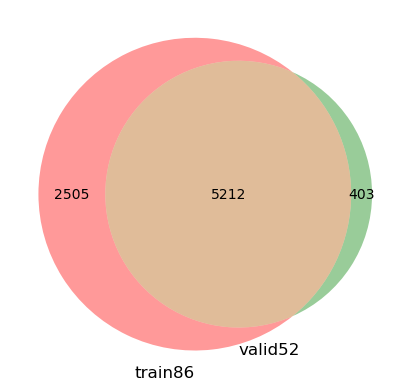

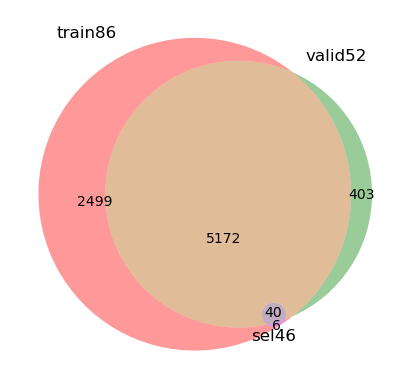

In [111]:
plot_venns(prt86['Protein_ID'],ob['ProteinID'],
           labels=['train86','valid52'],
           export='venn_prt_86_52',
           outputdir='report_reply')
plot_venns(prt86['Protein_ID'],ob['ProteinID'],
           sel46['Protein_ID'],labels=['train86','valid52','sel46'],
           export='venn_prt_86_52_sel46',
           outputdir='report_reply')
a = pd.Series('√',index = prt86['Protein_ID'],name = 'train86')
b = pd.Series('√',index = ob['ProteinID'],name = 'test52')
c = pd.Series('√',index = sel46['Protein_ID'],name = 'sel46')
venn_df = pd.concat([a,b,c],axis=1)
write_excel({'venn':venn_df},'venn_prt_86_52_sel46_data',outputdir='report_reply/')
venn_df

In [177]:
echo(info)

,uid,channel_name,file_path,Group,tag_mass,channel_label,ch,uid2,uuid,prefix,pure_uid,new_tsb,Custom_Label,batch
0,1554631,128N,1,valid52,128.1281,ReportIon (128.1281),3,14-1554631,14-1554631,,1554631,sample-04,P087,1
1,1538224,129N,1,valid52,129.1314,ReportIon (129.1315),5,18-1538224,18-1538224,,1538224,sample-06,P088,1
2,1557024,129C,1,valid52,129.1377,ReportIon (129.1378),6,22-1557024,22-1557024,,1557024,sample-07,P089,1
3,1555314,130C,1,valid52,130.1411,ReportIon (130.1411),8,26-1555314,26-1555314,,1555314,sample-09,P090,1
4,1535920,131N,1,valid52,131.1381,ReportIon (131.1382),9,26-1535920,26-1535920,,1535920,sample-10,P091,1
5,1528731,131C,1,valid52,131.1445,ReportIon (131.1445),10,27-1528731,27-1528731,,1528731,sample-11,P092,1
6,POOL,132C,1,valid52,132.1478,ReportIon (132.1479),12,POOL,POOL,,POOL,sample-13,p,1
7,1491165,126,2,valid52,126.1277,ReportIon (126.1277),0,30-1491165,30-1491165,,1491165,sample-17,P093,2
8,1494425,127N,2,valid52,127.1247,ReportIon (127.1248),1,22-1494425,22-1494425,,1494425,sample-18,P094,2
9,1494688,127C,2,valid52,127.1310,ReportIon (127.1311),2,18-1494688,18-1494688,,1494688,sample-19,P095,2


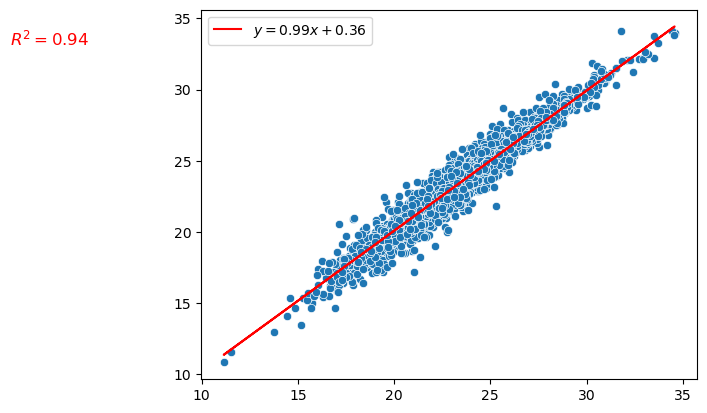

In [300]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Example data
np.random.seed(0)
y = ob['sample-13'].values
mask = np.isnan(y)
y = y[~mask]
x = ob['ReferenceIntensity'].values[~mask]


# Create scatter plot
sns.scatterplot(x=x, y=y)

# Reshape the data for sklearn
x_reshape = pd.DataFrame(x).values

# Fit linear regression model
model = LinearRegression().fit(x_reshape, y)

# Predict y values for the regression line
y_pred = model.predict(x_reshape)

# Calculate R²
r2 = r2_score(y, y_pred)

# Get the coefficients of the line
slope = model.coef_[0]
intercept = model.intercept_

# Plot the regression line
plt.plot(x, y_pred, color='red', label=f'$y = {slope:.2f}x + {intercept:.2f}$')

# Annotate the R² value on the plot
plt.text(0.05, max(y)-1, f'$R^2 = {r2:.2f}$', fontsize=12, color='red')

# Show the formula and R² in the legend
plt.legend()

# Show plot
plt.show()


#### wash

In [11]:
info.columns

Index(['uid', 'channel_name', 'file_path', 'Group', 'tag_mass',
       'channel_label', 'ch', 'uid2', 'uuid', 'prefix', 'pure_uid', 'new_tsb',
       'Custom_Label', 'batch'],
      dtype='object')

In [453]:
# 标准化处理质谱搜库定量数据
# only for msfragger protein 
#   ------------------
# for proteinMax + maxQuant results

# pools = {}
df_all = ob.copy()

mats = []
mats2 = []
res = {}
desx = []
mask = df_all.columns.str.startswith('sample-')
leading_columns = ["Index","NumberPSM","ProteinID"]
col_pool_fill = 'ReferenceIntensity'
number_columns = list(df_all.columns[mask])
IDNAME = "ProteinID"


# g in ['1', '2', '3', '4', '5']
for g in info['batch'].unique():
#   mp = {'sample-04': 'P087',
#  'sample-06': 'P088',
#  'sample-07': 'P089',
#  'sample-09': 'P090',
#  'sample-10': 'P091',
#  'sample-11': 'P092',
#  'sample-13': 'POOL'}
    mp = info[info['batch']==g].set_index('new_tsb')['Custom_Label'].to_dict()
    colnames = list(mp.keys())
# normd:DataFrame = 	sample-04	sample-06	sample-07	sample-09	sample-10	sample-11	sample-13
                    # 0	26.300170	26.501634	NaN	26.474470	26.463169	26.168811	25.976394
                    # 1	26.720017	27.120819	26.898554	27.172583	27.552261	26.644555	27.303677
                    # 2	18.025024	17.462955	NaN	17.842527	17.621779	17.457558	17.556908
                    # ...	...	...	...	...	...	...	...
                    # 5612	NaN	NaN	NaN	NaN	NaN	NaN	NaN
                    # 5613	27.029967	26.963864	NaN	26.984713	26.904080	26.396096	26.893521
                    # 5614	NaN	NaN	NaN	NaN	NaN	NaN	NaN
    normd = df_all.loc[:,[col_pool_fill] + colnames]
    df = df_all.loc[:,leading_columns + colnames]
    ## 除以每个pool
    # pcol = ['sample-13'][0], g中 pool的那一列
    pcol = [k for k,v in mp.items() if v=='p'][0]
    ## pools[g]:Series
    # pools[g] = normd[pcol].reset_index(drop=True)
    
    # pool 列空值用 normd['ReferenceIntensity']: normd[add_columns] 填充
    mask_na = normd[pcol].isna()
    normd.loc[mask_na,pcol] = normd.loc[mask_na,col_pool_fill]
    
    # devide by pool
    pooled_normd = normd.divide(normd[pcol],axis=0)[colnames]
    df.loc[:,colnames] = pooled_normd
    
    #     mpp = info[info['batch']==g].set_index('new_tsb')['pure_id'].to_dict()
    # 取median，groupby  IDNAME , merge repeats and duplicated 捕获
    x = df.groupby([IDNAME])[colnames].median().reset_index()
    y = df.loc[:,~df.columns.isin(colnames)].drop_duplicates(IDNAME)
    df = pd.merge(y,x,on=IDNAME,how='left')
    
    # rename columns
    df = df.rename(columns = mp)
    mat2 = df.set_index(IDNAME)
    mat2 = mat2.loc[:,~mat2.columns.isin(leading_columns)]
    
    # 去除pool列
    mat2 = mat2.loc[:,mat2.columns!='p']

    # collect
    mats2.append(mat2)
    res[g] = df
    des = df.loc[:,~df.columns.isin(list(mp.values()))]
    desx.append(des)
    print('batch',g,'is done!')
    
    
mat2 = pd.concat(mats2,axis=1)
# 去除重复REP-的列
mat = mat2.groupby(level=0, axis=1).agg(lambda df:df.median(axis=1,skipna=True))
def q(s):
    s = s.unique()
    if len(s) == 1:
        return s[0]
    return list(s)
des = pd.concat(desx,axis=1).groupby(level=0, axis=1).agg(lambda df:df.agg(q, axis=1))
mat_raw = mat
des_raw = des
des_raw

batch 1 is done!
batch 2 is done!
batch 3 is done!
batch 4 is done!
batch 5 is done!


,Index,NumberPSM,ProteinID
0,A1BG,72,P04217
1,A2M,258,P01023
2,AAAS,2,Q9NRG9
...,...,...,...
5612,ZW10,1,O43264
5613,ZYX,96,Q15942
5614,ZZEF1,12,O43149


In [454]:
mat_raw

,P087,P088,P089,P090,P091,P092,P093,P094,P095,P096,P097,P098,P099,P100,P101,P102,P103,P104,P105,P106,P107,P108,P109,P110,P111,...,P114,P115,P116,P117,P118,P119,P120,P121,P122,P123,P124,P125,P126,P127,P128,P129,P130,P131,P132,P133,P134,P135,P136,P137,P138
ProteinID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P04217,1.012464,1.020220,NaN,1.019174,1.018739,1.007407,1.007048,0.991375,0.990000,0.994347,1.002483,1.009723,0.985473,1.004149,1.001134,1.022254,0.996206,1.005566,0.985194,0.996077,1.003857,0.998488,0.997998,1.000088,1.001154,...,1.005225,0.988018,0.999276,1.001654,1.013448,0.992438,0.997590,0.996149,0.993647,1.018555,1.003126,0.998225,0.998749,1.003609,0.992347,0.985889,1.017184,0.995034,0.999397,1.009988,1.005795,1.018100,0.986081,1.013364,1.006289
P01023,0.978623,0.993303,0.985162,0.995199,1.009104,0.975860,0.999195,0.989340,0.992387,0.997414,0.998211,1.010879,0.984237,1.009226,1.005749,1.006823,1.013310,1.008053,1.001170,0.997714,1.001287,0.998359,1.006062,1.001647,0.991545,...,0.997279,0.998781,0.994832,0.990724,1.010326,0.995958,1.001424,0.987985,0.987382,1.006528,0.996732,1.004803,0.997554,0.994025,0.992168,1.006039,1.025586,0.989881,0.990439,0.993086,1.012954,0.991187,0.980892,1.002785,0.999900
Q9NRG9,1.026663,0.994649,NaN,1.016268,1.003695,0.994341,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.922232,1.005737,1.034981,1.011694
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
O43264,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.014428,1.048884,1.001883,0.986085,1.018769,1.002731,...,1.016073,0.993596,1.011328,1.021885,1.020798,1.006482,1.015092,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Q15942,1.005074,1.002616,NaN,1.003391,1.000393,0.981504,1.002135,0.997730,0.988607,0.992678,1.007461,0.999598,1.001494,1.000127,1.000641,1.011054,0.994919,1.005648,0.997624,1.004854,0.998963,0.999853,0.995562,0.992010,0.979690,...,0.996659,0.980718,0.999788,1.003223,0.989418,1.007877,0.991065,0.995831,1.000797,1.010320,1.003666,1.004077,1.011131,1.001495,0.995878,0.990637,1.000600,1.003351,0.990197,1.001018,0.996493,0.988070,0.991050,1.011356,1.003434
O43149,NaN,NaN,NaN,NaN,NaN,NaN,1.001909,1.006233,1.004890,1.005766,0.989329,0.992349,1.015484,1.003555,0.994002,0.995587,0.997725,0.997878,1.006946,1.001514,0.921932,1.001102,0.997633,0.998573,1.028356,...,0.997876,1.007817,1.010041,1.003430,0.984275,1.020044,0.989752,0.999784,1.002741,0.989513,0.980946,1.000202,0.993009,1.002529,1.005425,0.980170,0.984954,1.019966,1.004502,1.015000,0.985742,0.964976,1.000733,0.988293,1.009004


#### dump

In [451]:
db.exporting(mat_raw,'prt_mat_na_raw',outputdir='external_info/Proteomics52/washed/',index=True)
db.exporting(des_raw,'prt_des_raw',outputdir='external_info/Proteomics52/washed/',index=True)
db.exporting(mat2,'prt_mat2_na_raw',outputdir='external_info/Proteomics52/washed/',index=True)

[07/27 08:49:14] overwritting 1 file with 5615 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_mat_na_raw.dfx
[07/27 08:49:14] writing 1 file with 5615 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_des_raw.dfx
[07/27 08:49:14] overwritting 1 file with 5615 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_mat2_na_raw.dfx


In [446]:
x = mat_raw.isna()
x = mat_raw.loc[x.apply(sum,1) < 52*.6,:]
x

,P087,P088,P089,P090,P091,P092,P093,P094,P095,P096,P097,P098,P099,P100,P101,P102,P103,P104,P105,P106,P107,P108,P109,P110,P111,...,P114,P115,P116,P117,P118,P119,P120,P121,P122,P123,P124,P125,P126,P127,P128,P129,P130,P131,P132,P133,P134,P135,P136,P137,P138
ProteinID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P04217,1.012464,1.020220,NaN,1.019174,1.018739,1.007407,1.007048,0.991375,0.990000,0.994347,1.002483,1.009723,0.985473,1.004149,1.001134,1.022254,0.996206,1.005566,0.985194,0.996077,1.003857,0.998488,0.997998,1.000088,1.001154,...,1.005225,0.988018,0.999276,1.001654,1.013448,0.992438,0.997590,0.996149,0.993647,1.018555,1.003126,0.998225,0.998749,1.003609,0.992347,0.985889,1.017184,0.995034,0.999397,1.009988,1.005795,1.018100,0.986081,1.013364,1.006289
P01023,0.978623,0.993303,0.985162,0.995199,1.009104,0.975860,0.999195,0.989340,0.992387,0.997414,0.998211,1.010879,0.984237,1.009226,1.005749,1.006823,1.013310,1.008053,1.001170,0.997714,1.001287,0.998359,1.006062,1.001647,0.991545,...,0.997279,0.998781,0.994832,0.990724,1.010326,0.995958,1.001424,0.987985,0.987382,1.006528,0.996732,1.004803,0.997554,0.994025,0.992168,1.006039,1.025586,0.989881,0.990439,0.993086,1.012954,0.991187,0.980892,1.002785,0.999900
Q86V21,NaN,NaN,NaN,NaN,NaN,NaN,0.992694,0.999254,0.996521,1.000174,0.998899,0.990129,1.015639,1.068495,1.036241,1.038589,0.977883,0.997653,1.012088,1.008414,1.031118,1.001693,1.001750,1.010160,0.994015,...,1.007597,1.006937,1.002823,1.010501,0.990904,0.999374,0.997101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q8TBC5,NaN,NaN,NaN,NaN,NaN,NaN,1.005908,1.012966,1.000536,0.991698,0.983236,0.993632,0.960887,0.981449,0.969395,0.977741,0.987247,1.007715,1.024045,0.991407,0.992647,0.996417,0.980633,0.986729,0.959163,...,1.000779,0.967068,0.996688,0.999883,0.995066,0.962036,0.975617,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.037543,0.998052,1.040031,1.037015
Q15942,1.005074,1.002616,NaN,1.003391,1.000393,0.981504,1.002135,0.997730,0.988607,0.992678,1.007461,0.999598,1.001494,1.000127,1.000641,1.011054,0.994919,1.005648,0.997624,1.004854,0.998963,0.999853,0.995562,0.992010,0.979690,...,0.996659,0.980718,0.999788,1.003223,0.989418,1.007877,0.991065,0.995831,1.000797,1.010320,1.003666,1.004077,1.011131,1.001495,0.995878,0.990637,1.000600,1.003351,0.990197,1.001018,0.996493,0.988070,0.991050,1.011356,1.003434
O43149,NaN,NaN,NaN,NaN,NaN,NaN,1.001909,1.006233,1.004890,1.005766,0.989329,0.992349,1.015484,1.003555,0.994002,0.995587,0.997725,0.997878,1.006946,1.001514,0.921932,1.001102,0.997633,0.998573,1.028356,...,0.997876,1.007817,1.010041,1.003430,0.984275,1.020044,0.989752,0.999784,1.002741,0.989513,0.980946,1.000202,0.993009,1.002529,1.005425,0.980170,0.984954,1.019966,1.004502,1.015000,0.985742,0.964976,1.000733,0.988293,1.009004


In [443]:
mat_raw.loc[['Q8WVQ1','P01732'],:].isna().apply(sum,1)

ProteinID
Q8WVQ1    29
P01732    23
dtype: int64

In [447]:
d = des_raw[des_raw['ProteinID'].isin(x.index)]
echo(sel46[~sel46['Protein_ID'].isin(d['ProteinID'])])

,Protein_ID,Protein_Name,IN4
6,Q13439,GOLGA4,
23,O15021,MAST4,
26,O60443,GSDME,
35,P15169,CPN1,
36,O15182,CETN3,
37,O95297,MPZL1,
39,P06239,LCK,
40,P12544,GZMA,
44,Q96EU7,C1GALT1C1,


In [455]:
x = mat_raw.isna()
mat = mat_raw.loc[x.apply(sum,1) < 52*.6,:] # < 31.5
mat

,P087,P088,P089,P090,P091,P092,P093,P094,P095,P096,P097,P098,P099,P100,P101,P102,P103,P104,P105,P106,P107,P108,P109,P110,P111,...,P114,P115,P116,P117,P118,P119,P120,P121,P122,P123,P124,P125,P126,P127,P128,P129,P130,P131,P132,P133,P134,P135,P136,P137,P138
ProteinID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
P04217,1.012464,1.020220,NaN,1.019174,1.018739,1.007407,1.007048,0.991375,0.990000,0.994347,1.002483,1.009723,0.985473,1.004149,1.001134,1.022254,0.996206,1.005566,0.985194,0.996077,1.003857,0.998488,0.997998,1.000088,1.001154,...,1.005225,0.988018,0.999276,1.001654,1.013448,0.992438,0.997590,0.996149,0.993647,1.018555,1.003126,0.998225,0.998749,1.003609,0.992347,0.985889,1.017184,0.995034,0.999397,1.009988,1.005795,1.018100,0.986081,1.013364,1.006289
P01023,0.978623,0.993303,0.985162,0.995199,1.009104,0.975860,0.999195,0.989340,0.992387,0.997414,0.998211,1.010879,0.984237,1.009226,1.005749,1.006823,1.013310,1.008053,1.001170,0.997714,1.001287,0.998359,1.006062,1.001647,0.991545,...,0.997279,0.998781,0.994832,0.990724,1.010326,0.995958,1.001424,0.987985,0.987382,1.006528,0.996732,1.004803,0.997554,0.994025,0.992168,1.006039,1.025586,0.989881,0.990439,0.993086,1.012954,0.991187,0.980892,1.002785,0.999900
Q86V21,NaN,NaN,NaN,NaN,NaN,NaN,0.992694,0.999254,0.996521,1.000174,0.998899,0.990129,1.015639,1.068495,1.036241,1.038589,0.977883,0.997653,1.012088,1.008414,1.031118,1.001693,1.001750,1.010160,0.994015,...,1.007597,1.006937,1.002823,1.010501,0.990904,0.999374,0.997101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q8TBC5,NaN,NaN,NaN,NaN,NaN,NaN,1.005908,1.012966,1.000536,0.991698,0.983236,0.993632,0.960887,0.981449,0.969395,0.977741,0.987247,1.007715,1.024045,0.991407,0.992647,0.996417,0.980633,0.986729,0.959163,...,1.000779,0.967068,0.996688,0.999883,0.995066,0.962036,0.975617,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.037543,0.998052,1.040031,1.037015
Q15942,1.005074,1.002616,NaN,1.003391,1.000393,0.981504,1.002135,0.997730,0.988607,0.992678,1.007461,0.999598,1.001494,1.000127,1.000641,1.011054,0.994919,1.005648,0.997624,1.004854,0.998963,0.999853,0.995562,0.992010,0.979690,...,0.996659,0.980718,0.999788,1.003223,0.989418,1.007877,0.991065,0.995831,1.000797,1.010320,1.003666,1.004077,1.011131,1.001495,0.995878,0.990637,1.000600,1.003351,0.990197,1.001018,0.996493,0.988070,0.991050,1.011356,1.003434
O43149,NaN,NaN,NaN,NaN,NaN,NaN,1.001909,1.006233,1.004890,1.005766,0.989329,0.992349,1.015484,1.003555,0.994002,0.995587,0.997725,0.997878,1.006946,1.001514,0.921932,1.001102,0.997633,0.998573,1.028356,...,0.997876,1.007817,1.010041,1.003430,0.984275,1.020044,0.989752,0.999784,1.002741,0.989513,0.980946,1.000202,0.993009,1.002529,1.005425,0.980170,0.984954,1.019966,1.004502,1.015000,0.985742,0.964976,1.000733,0.988293,1.009004


,Protein_Name,NumberPSM,Protein_ID


In [460]:
des = des_raw[des_raw['ProteinID'].isin(mat.index)]
des = des.rename(columns={'ProteinID':'Protein_ID','Index':"Protein_Name"})
assert (des['Protein_ID']==mat.index).all()
assert len(des[des['Protein_Name'].duplicated(keep=False)]) == 0
mat.index = des['Protein_Name']
mat

,P087,P088,P089,P090,P091,P092,P093,P094,P095,P096,P097,P098,P099,P100,P101,P102,P103,P104,P105,P106,P107,P108,P109,P110,P111,...,P114,P115,P116,P117,P118,P119,P120,P121,P122,P123,P124,P125,P126,P127,P128,P129,P130,P131,P132,P133,P134,P135,P136,P137,P138
Protein_Name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A1BG,1.012464,1.020220,NaN,1.019174,1.018739,1.007407,1.007048,0.991375,0.990000,0.994347,1.002483,1.009723,0.985473,1.004149,1.001134,1.022254,0.996206,1.005566,0.985194,0.996077,1.003857,0.998488,0.997998,1.000088,1.001154,...,1.005225,0.988018,0.999276,1.001654,1.013448,0.992438,0.997590,0.996149,0.993647,1.018555,1.003126,0.998225,0.998749,1.003609,0.992347,0.985889,1.017184,0.995034,0.999397,1.009988,1.005795,1.018100,0.986081,1.013364,1.006289
A2M,0.978623,0.993303,0.985162,0.995199,1.009104,0.975860,0.999195,0.989340,0.992387,0.997414,0.998211,1.010879,0.984237,1.009226,1.005749,1.006823,1.013310,1.008053,1.001170,0.997714,1.001287,0.998359,1.006062,1.001647,0.991545,...,0.997279,0.998781,0.994832,0.990724,1.010326,0.995958,1.001424,0.987985,0.987382,1.006528,0.996732,1.004803,0.997554,0.994025,0.992168,1.006039,1.025586,0.989881,0.990439,0.993086,1.012954,0.991187,0.980892,1.002785,0.999900
AACS,NaN,NaN,NaN,NaN,NaN,NaN,0.992694,0.999254,0.996521,1.000174,0.998899,0.990129,1.015639,1.068495,1.036241,1.038589,0.977883,0.997653,1.012088,1.008414,1.031118,1.001693,1.001750,1.010160,0.994015,...,1.007597,1.006937,1.002823,1.010501,0.990904,0.999374,0.997101,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN18,NaN,NaN,NaN,NaN,NaN,NaN,1.005908,1.012966,1.000536,0.991698,0.983236,0.993632,0.960887,0.981449,0.969395,0.977741,0.987247,1.007715,1.024045,0.991407,0.992647,0.996417,0.980633,0.986729,0.959163,...,1.000779,0.967068,0.996688,0.999883,0.995066,0.962036,0.975617,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.037543,0.998052,1.040031,1.037015
ZYX,1.005074,1.002616,NaN,1.003391,1.000393,0.981504,1.002135,0.997730,0.988607,0.992678,1.007461,0.999598,1.001494,1.000127,1.000641,1.011054,0.994919,1.005648,0.997624,1.004854,0.998963,0.999853,0.995562,0.992010,0.979690,...,0.996659,0.980718,0.999788,1.003223,0.989418,1.007877,0.991065,0.995831,1.000797,1.010320,1.003666,1.004077,1.011131,1.001495,0.995878,0.990637,1.000600,1.003351,0.990197,1.001018,0.996493,0.988070,0.991050,1.011356,1.003434
ZZEF1,NaN,NaN,NaN,NaN,NaN,NaN,1.001909,1.006233,1.004890,1.005766,0.989329,0.992349,1.015484,1.003555,0.994002,0.995587,0.997725,0.997878,1.006946,1.001514,0.921932,1.001102,0.997633,0.998573,1.028356,...,0.997876,1.007817,1.010041,1.003430,0.984275,1.020044,0.989752,0.999784,1.002741,0.989513,0.980946,1.000202,0.993009,1.002529,1.005425,0.980170,0.984954,1.019966,1.004502,1.015000,0.985742,0.964976,1.000733,0.988293,1.009004


In [461]:
des

,Protein_Name,NumberPSM,Protein_ID
0,A1BG,72,P04217
1,A2M,258,P01023
3,AACS,3,Q86V21
...,...,...,...
5611,ZSCAN18,5,Q8TBC5
5613,ZYX,96,Q15942
5614,ZZEF1,12,O43149


In [462]:
db.exporting(mat,'prt_mat_na',outputdir='external_info/Proteomics52/washed/',index=True)
db.exporting(des,'prt_des_na',outputdir='external_info/Proteomics52/washed/',index=True)


[07/27 08:53:12] writing 1 file with 4594 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_mat_na.dfx
[07/27 08:53:12] writing 1 file with 4594 lines at 
	[PROJECT_ROOT]/external_info/Proteomics52/washed/prt_des_na.dfx


In [ ]:
%%R

base = 'external_info/Proteomics52/washed/'
glx = db.importing(file.path(base,'prt_glx'))
prt_raw = db.importing('external_info/Proteomics52/washed/prt_mat_na.dfx') %>% 
    column_to_rownames('Protein_Name') %>% as.matrix
# filter out pCR
sel = glx %>% filter(Group=='non.pCR') %>% pull(Custom_Label)
prt_raw = prt_raw[,sel]

prt_raw

prt = SeqKnn::SeqKNN(prt_raw, k = 12)

prt %>% ydumpto('prt_mat_49',outputdir = base)





In [ ]:
%%R

base = 'external_info/Proteomics52/washed/'
prt = db.importing(file.path(base, 'prt_mat_49'),row.names=1)  %>% as.matrix
prt = prt %>% yscale_rows()

res = ydo_ssGSEA(prt)

res$hm %>% ydumpto('prt_ssgsea_hm',outputdir = base)
res$kegg %>% ydumpto('prt_ssgsea_kegg',outputdir = base)
res$im %>% ydumpto('prt_ssgsea_immune',outputdir = base)




In [ ]:
%%R
base = 'external_info/Proteomics52/washed/'
glx = db.importing(file.path(base,'prt_glx'))
prt_raw = db.importing('external_info/Proteomics52/washed/prt_mat_na.dfx') %>% column_to_rownames('Protein_Name') %>% as.matrix

prt = SeqKnn::SeqKNN(prt_raw, k = 12)

prt %>% ydumpto('prt_mat_52',outputdir = base)


存在的问题

In [188]:
# 通道值不是NA，但对应的POOL是NA
mp = info[info['batch']=='1'].set_index('new_tsb')['Custom_Label'].to_dict()
normd = df.loc[:,list(mp.keys())]
pcol = [k for k,v in mp.items() if v=='p'][0]
x = normd.loc[normd[pcol].isna(),:]
normd.loc[x.index,:].loc[(x.isna().apply(np.mean,1) != 1).values,:]


,sample-04,sample-06,sample-07,sample-09,sample-10,sample-11,sample-13
40,25.174034,24.977819,NaN,25.523063,NaN,24.825421,NaN
75,17.792651,17.279559,NaN,17.170318,15.999898,17.419859,NaN
93,21.678094,20.572441,NaN,20.664594,20.038358,19.452717,NaN
...,...,...,...,...,...,...,...
5477,19.701276,19.688369,NaN,19.381075,NaN,18.860008,NaN
5500,20.530942,20.195183,NaN,20.638902,NaN,20.874185,NaN
5565,20.541846,20.364954,NaN,20.513790,18.777192,19.719713,NaN


#### wash glx of valid set

In [39]:
glx = info[info['Group']=='valid52'][['uid']].drop_duplicates()
glx = glx[(glx['uid']!='POOL')&(~glx['uid'].str.startswith('REP-'))].reset_index(drop=True).copy()
glx['Custom_Label'] = "P" + pd.Series(range(87,87+len(glx))).astype(str).str.zfill(3)
glx_valid = glx
glx_valid

,uid,Custom_Label
0,1554631,P087
1,1538224,P088
2,1557024,P089
...,...,...
49,1566005,P136
50,1567143,P137
51,1567947,P138


In [1463]:
db.exporting(glx_valid,'prt_glx_valid','external_info/Cohort_Prospective/data_washed/')

[07/07 08:57:01] writing 1 file with 52 lines at 
	[PROJECT_ROOT]/external_info/Cohort_Prospective/data_washed/prt_glx_valid.dfx


#### rewash glx of train test set

In [1516]:
# 将P01等改为zfill==3,的编号 done @ 2024年7月7日17:38:24
# files = !ls ./*/*glx*.dfx
# print(files)

# res = {}
# for file in files:
#     if file != './export_old/PRAD_CA_glx.dfx':
#         df = db.importing(file)
#         cols = [i for i in df.columns if df[i].dtype == np.dtype('O') and \
#                 df[i].str.startswith('P').all() and \
#                 df[i].str.len().max() <= 5]
#         j = 0
#         for i in cols:
#             if i!='sort_col':
#                 if df[i].str.match('^P\d{,2}').all():
#                     df[i] = df[i].str.replace('P','P0',regex=False)
#                     j+=1
#         res[file] = df
#         print(file,j,'of',cols,'changed')


# for i,df in res.items():
#     db.exporting(df,i,outputdir='./')
    

[07/07 09:37:45] overwritting 1 file with 93 lines at 
	[PROJECT_ROOT]/./export_86_7/rna_glx.dfx
[07/07 09:37:45] overwritting 1 file with 86 lines at 
	[PROJECT_ROOT]/./export_86_7/wes_glx.dfx
[07/07 09:37:45] overwritting 1 file with 16 lines at 
	[PROJECT_ROOT]/./export_big/glx_helper_cols_ori.dfx
[07/07 09:37:45] overwritting 1 file with 96 lines at 
	[PROJECT_ROOT]/./export_big/glx_helper_ori.dfx
[07/07 09:37:45] overwritting 1 file with 86 lines at 
	[PROJECT_ROOT]/./export_by2_86_pCR_nonpCR/rna_glx.dfx
[07/07 09:37:45] overwritting 1 file with 86 lines at 
	[PROJECT_ROOT]/./export_by2_86_pCR_nonpCR/wes_glx.dfx
[07/07 09:37:45] overwritting 1 file with 86 lines at 
	[PROJECT_ROOT]/./export_nonpCR/rna_glx.dfx
[07/07 09:37:45] overwritting 1 file with 86 lines at 
	[PROJECT_ROOT]/./export_nonpCR/wes_glx.dfx
[07/07 09:37:45] overwritting 1 file with 86 lines at 
	[PROJECT_ROOT]/./export_Prt_cluster_1vs2/rna_glx.dfx
[07/07 09:37:45] overwritting 1 file with 86 lines at 
	[PROJECT_ROO

In [1431]:
# ob = db.importing('external_info/Phosphorylation/Quant.spectra.list')
# ob

# ob = ob[ob['Modification'].str.contains('Phospho').fillna(False)].drop_index()
# ob = ob[(ob['Modification'].str.contains(",Phospho[S]",regex=False) | \
#         ob['Modification'].str.contains(",Phospho[T]",regex=False) | \
#         ob['Modification'].str.contains(",Phospho[Y]",regex=False)).fillna(False)]

# i =ob['File_Name'].str.index('_')
# assert (i==23).mean() == 1
    
# ob['batch'] = ob['File_Name'].str[22:23].astype(int)
# ob['repeat'] = ob['File_Name'].str[24:25].astype(int)

# res = []
# res_len = []
# for term in ob['Modification']:
#     i = term.split(';')
#     r = []
#     for j in i:
#         if "Phospho" in j:
#             r.append(j)
#     res.append(';'.join(r))
#     res_len.append(len(r))
# ob['Mod'] = res
# ob['Mod_site_number'] = res_len
# ob


[07/07 05:21:33]reading external_info/Phosphorylation/Quant.spectra.list


,File_Name,Scan_No,Exp.MH+,Charge,Q-value,Sequence,Calc.MH+,Mass_Shift(Exp.-Calc.),Raw_Score,Final_Score,Modification,Specificity,Proteins,Positions,Label,Target/Decoy,Miss.Clv.Sites,Avg.Frag.Mass.Shift,Others,Supp_Info,Empty_Separator,ReportIon (114.1277),ReportIon (115.1248),ReportIon (115.1311),ReportIon (116.1281),ReportIon (116.1344),ReportIon (117.1315),ReportIon (117.1378),ReportIon (118.1348),ReportIon (118.1411),ReportIon (119.1382),ReportIon (119.1445),ReportIon (120.1415),ReportIon (120.1479),ReportIon (121.1449),ReportIon (121.1512),ReportIon (122.1482),Unnamed: 37
0,20231011-FangPan-P-PE-1_1.35490.35490.4.0.dta,35490,3459.653969,4,0.000000,VPFDAATLHTSTAMAAQHGMDDDGTGQK,3459.648843,0.005126,39.918208,1.981380e-07,"0,IBT-16-N-term;14,Oxidation[M];20,Oxidation[M...",3,sp|P06396|GELS_HUMAN/,"419,R,Q/",1|0|0|0|0|,target,0,0.243487,36,NaN,NaN,53499.8,40519.3,67811.7,95149.6,76455.2,94987.7,42455.0,60212.7,77690.2,55391.1,71200.9,53977.7,83398.0,102731.8,45213.9,56286.3,NaN
1,20231011-FangPan-P-PE-1_1.22143.22143.4.2.dta,22143,3777.659071,4,0.000000,GGSGGSHGGGSGFGGESGGSYGGGEEASGSGGGYGGGSGK,3777.657693,0.001378,30.230761,3.255990e-07,"0,IBT-16-N-term;40,IBT-16-K;",3,sp|P35527|K1C9_HUMAN/,"579,R,S/",1|0|0|,target,0,-0.927396,36,NaN,NaN,4749.9,17107.9,4357.3,7616.5,3791.4,5622.1,5212.6,4551.6,7763.7,4676.7,6655.2,4837.7,4138.8,4082.2,5018.1,5344.6,NaN
2,20231011-FangPan-P-PE-1_1.36146.36146.4.1.dta,36146,3459.650046,4,0.000000,VPFDAATLHTSTAMAAQHGMDDDGTGQK,3459.648843,0.001203,33.131148,2.004730e-06,"0,IBT-16-N-term;14,Oxidation[M];20,Oxidation[M...",3,sp|P06396|GELS_HUMAN/,"419,R,Q/",1|0|0|0|0|,target,0,-1.098924,36,NaN,NaN,23656.3,23836.2,35621.0,45795.4,33183.8,39807.3,31022.8,33528.3,36614.1,30407.3,38484.4,29079.9,38727.3,41308.2,24906.5,30624.8,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
223638,20231011-FangPan-P-PE-6_5.191.191.2.0.dta,191,811.405063,2,0.009907,GPPGPAGSR,811.405655,-0.000592,6.718969,2.796900e-01,"3,Oxidation[P];",3,sp|P08123|CO1A2_HUMAN/sp|Q02388|CO7A1_HUMAN/,"768,N,G/1497,R,G/",1|0|,target,0,-1.881020,32,NaN,NaN,0.0,3048.9,3048.9,3683.1,3683.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN
223639,20231011-FangPan-P-PE-6_5.29341.29341.3.0.dta,29341,2101.179143,3,0.009907,EGRNIIGLQMGTNK,2101.176789,0.002354,8.225865,2.798790e-01,"0,IBT-16-N-term;10,Oxidation[M];14,IBT-16-K;",3,sp|P51911|CNN1_HUMAN/,"158,R,F/",1|0|0|0|,target,1,-0.894751,36,NaN,NaN,49035.5,60531.6,39391.0,59843.5,48696.4,51643.7,49159.4,35466.6,50801.7,44856.6,64486.3,53296.9,54707.5,47757.2,46851.2,39834.1,NaN
223640,20231011-FangPan-P-PE-6_5.62529.62529.4.3.dta,62529,2332.382613,4,0.009907,EIRPALELLEPIEQK,2332.382002,0.000611,7.743520,2.799180e-01,"0,IBT-16-N-term;15,IBT-16-K;",3,sp|P50395|GDIB_HUMAN/,"364,K,F/",1|0|0|,target,1,-0.402548,36,NaN,NaN,14734.8,13431.0,9351.5,12061.0,8173.6,17314.6,10700.2,12645.3,10393.8,8785.7,10350.9,10745.9,15862.0,9077.4,12152.1,12170.2,NaN


### Others

In [100]:
# 标准化处理质谱搜库定量数据
# only for proteinMax + maxQuant results
#   ------------------
base = 'external_info/Cohort_Prospective/msfragger'
g = 'valid52'
refg = info[info['Group']==g]
x = []
# for proteinMax + maxQuant results
leading_columns = ['Spectrum','Peptide','Modified Peptide','Charge','Protein Start','Protein End','Assigned Modifications','Protein ID','Gene','Protein Description']
PRE_WASHED_DATADIR = 'external_info/Cohort_Prospective/data_washed/'


In [101]:
pre = []
for p, ref in refg.groupby('file_path'):
    print(f' ------- handling {p} ------- ')
    
    ## 获取map（colnames）数据，colnames是ReportIon (127.1248) -> uid的映射map
    colnames = ref.set_index('tag_mass')['uid'].to_dict()
    
    ## 读取一个ITB标记下的所有分馏的数据
    data = db.importing(J(base,f"psm-TMT-{p}.xlsx"))
    
    
    ##
    ##  --- 筛选列  --- ##
    ##
    ## num_cols是数值矩阵mat的列， 其余leading_columns是des的列
    ## 筛选出只在map（colnames）中的数据列
    data = data[leading_columns + list(colnames.keys())]

    # 去掉REV_sp*蛋白，反库蛋白是搜库时假设的
#     data = data[~data['ProteinName'].str.startswith('REV_')].drop_index()
    
    ##
    ##  --- 修饰整理信息列，保持对应信息存在 --- ##
    ##
    # 拆解ID信息
    data = data.rename(columns={'Protein ID':'Protein_ID','Gene':'Protein_Name'})
#     sp = data['GroupID'].str.split('|',expand=True)

#     data.insert(0,'Group_Name',sp[2].str[:-6])
#     data.insert(0,'Group_ID',sp[1])

#     sp = data['ProteinName'].str.split('|',expand=True)
#     data.insert(0,'Protein_Name', sp[2].str[:-6])
#     data.insert(0,'Protein_ID', sp[1])

    data.insert(0,'PID',data['Protein_ID']+"_"+data['Protein_Name'].fillna(''))
    
    num_cols = [*colnames.keys()]
    
    ##
    ## --- 处理数值列 --- ##
    ## 
    ## 标记归一化
    x = data.loc[:,num_cols]
    x = x.divide(x.apply(np.sum,0),axis=1)
    data.loc[:,num_cols] = x.values

    ## 除以各自的POOL
    x = data[num_cols].rename(columns=colnames)
    x[np.isinf(x)] = np.nan
    x = x.divide(x['POOL'],axis=0)
    data.loc[:,num_cols] = x.values
    
#     ## 合并馏份 median法
#     # gen relative des columns info
#     des = data.loc[:,~data.columns.isin(num_cols)].drop_duplicates(['ProteinName'])
#     des.index = des['ProteinName'].values
#     des['source'] = data.groupby('ProteinName')['source'].count()
#     # gen median
#     x = data.groupby('ProteinName')[num_cols].median()
#     # merge
#     data = pd.merge(des,x,left_index=True,right_index=True).drop_index()
   
    ## rename
    data = data.rename(columns = colnames)
    assert (data['POOL'].fillna(1) == 1).all(), "not correctly pooled, some row's POOL!=1"

    pre.append(data)
    db.exporting(data,fname = f'washed-psm-TMT-{p}'
                 ,outputdir=PRE_WASHED_DATADIR)
    
'Job Done!'

 ------- handling 1 ------- 
[07/20 13:31:38]reading external_info/Cohort_Prospective/msfragger/psm-TMT-1.xlsx
  Sheets list: ['psm-Organoid']
  Read the 1 / 1 sheet named <psm-Organoid>
[07/20 13:31:46] overwritting 1 file with 14362 lines at 
	[PROJECT_ROOT]/external_info/Cohort_Prospective/data_washed/washed-psm-TMT-1.dfx
 ------- handling 2 ------- 
[07/20 13:31:46]reading external_info/Cohort_Prospective/msfragger/psm-TMT-2.xlsx
  Sheets list: ['psm-vaild-1']
  Read the 1 / 1 sheet named <psm-vaild-1>
[07/20 13:31:57] overwritting 1 file with 16981 lines at 
	[PROJECT_ROOT]/external_info/Cohort_Prospective/data_washed/washed-psm-TMT-2.dfx
 ------- handling 3 ------- 
[07/20 13:31:57]reading external_info/Cohort_Prospective/msfragger/psm-TMT-3.xlsx
  Sheets list: ['psm-vaild-2']
  Read the 1 / 1 sheet named <psm-vaild-2>
[07/20 13:32:06] overwritting 1 file with 13976 lines at 
	[PROJECT_ROOT]/external_info/Cohort_Prospective/data_washed/washed-psm-TMT-3.dfx
 ------- handling 4 ---

'Job Done!'

In [102]:
mats = []
desx = []
anno_cols = ['Protein_ID','Protein_Name'] + leading_columns

for f in pre:
    f = f.loc[:,f.columns!='POOL']
    mat = f.loc[:,~f.columns.isin(anno_cols)]
    des = f.loc[:,f.columns.isin(['PID'] + anno_cols)]
    
    mat = mat.groupby("PID").agg('mean').sort_index()
    des = des.drop_duplicates('PID').sort_values('PID').drop_index()
    
    mats.append(mat)
    desx.append(des)
    

In [103]:
mat = pd.concat(mats,axis = 1)
print(mat.shape)
des = pd.concat(desx,axis = 0)


x = des.groupby("PID")['Spectrum'].agg(lambda x:list(x))
des = des.drop_duplicates('PID') 
des = des.set_index('PID')
des['Spectrum'] = x
des.insert(0,'#Spe',x.str.len())

assert (des.index==mat.index).all(), "des index and mat index order do not match"

# 合并REP-id与id的列
# 取mean
mask_rep = mat.columns.str.startswith("REP-")
rep = mat.loc[:,mask_rep].copy()

mat = mat.loc[:,~mask_rep].copy()

rep.columns = rep.columns.str[4:]

print('rep shape',rep.shape)

for i in rep.columns:
    df = np.array([mat[i].values,rep[i].values])
    x = np.mean(df,axis=0)
    mat[i] = x
mat


(3098, 56)
rep shape (3098, 4)


,1554631,1538224,1557024,1555314,1535920,1528731,1491165,1494425,1494688,1498899,1499496,1499777,1504457,1507100,1509204,1509451,1510339,1510436,1510834,1511128,1511292,1511700,1512209,1513118,1515049,...,1516112,1516992,1517415,1518995,1519279,1519610,1522368,1524487,1524521,1526829,1530827,1537976,1540897,1544807,1545989,1549428,1550185,1552417,1553097,1556913,1563173,1563492,1566005,1567143,1567947
PID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A0A0B4J2D5_GATD3B,1.167584,1.250591,0.0,0.994762,0.606653,1.423277,0.926284,0.866890,1.059703,1.050116,1.001343,1.174528,0.697487,0.998742,0.868973,1.060080,1.030002,0.817445,1.086855,1.121863,0.772661,1.026540,1.057693,0.844551,0.784708,...,0.931979,0.974367,0.971127,1.079812,0.833004,0.978380,0.975189,0.882232,0.899196,1.004992,1.072594,0.835076,1.023187,1.085096,1.384125,0.976813,0.962133,1.169219,1.054437,0.927761,0.981178,1.630801,1.198490,0.957260,0.900670
A0A0C4DH29_IGHV1-3,0.167214,0.262607,0.0,0.165825,1.633708,0.262387,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
A0A0U1RRE5_NBDY,0.293033,0.697968,0.0,0.370368,1.168321,0.974152,0.771603,0.805707,1.009250,0.946217,1.053766,0.899933,0.936736,0.820020,0.714565,0.986352,0.754518,1.310918,0.962398,0.880960,0.871372,1.136415,0.839409,0.767494,1.198448,...,1.055165,0.995292,0.858274,1.045961,0.695810,0.912718,0.866808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.105379,1.068335,0.924704,0.923633
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q9Y5V0_ZNF706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.746649,0.932715,1.022423,1.068598
Q9Y6D5_ARFGEF2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.881703,1.867887,1.107821,0.994207
Q9Y6X5_ENPP4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.175052,0.989361,0.716411,0.545344


In [104]:
des

,#Spe,Spectrum,Peptide,Modified Peptide,Charge,Protein Start,Protein End,Assigned Modifications,Protein_ID,Protein_Name,Protein Description
PID,,,,,,,,,,,
A0A0B4J2D5_GATD3B,5,"[20240319_DaiJiawei_TMT_1_1.21720.21720.3, 202...",EVVEAHVDQK,EVVEAHVDQK,3,224,233,10K(304.2071),A0A0B4J2D5,GATD3B,Putative glutamine amidotransferase-like class...
A0A0C4DH29_IGHV1-3,1,[20240319_DaiJiawei_TMT_1_5.15555.15555.3],KPGASVK,KPGASVK,3,32,38,"1K(304.2071), 7K(304.2071)",A0A0C4DH29,IGHV1-3,Immunoglobulin heavy variable 1-3
A0A0U1RRE5_NBDY,4,"[20240319_DaiJiawei_TMT_1_4.18051.18051.3, 202...",SHPPPPEK,n[305]SHPPPPEK,3,61,68,"8K(304.2071), N-term(304.2071)",A0A0U1RRE5,NBDY,Negative regulator of P-body association
...,...,...,...,...,...,...,...,...,...,...,...
Q9Y5V0_ZNF706,1,[20240319_DaiJiawei_TMT_5_3.54233.54233.2],TPLPPELADVQA,n[305]TPLPPELADVQA,2,65,76,N-term(304.2071),Q9Y5V0,ZNF706,Zinc finger protein 706
Q9Y6D5_ARFGEF2,1,[20240319_DaiJiawei_TMT_5_1.24218.24218.2],MQESQTK,n[43]MQESQTK,2,1,7,"7K(304.2071), N-term(42.0106)",Q9Y6D5,ARFGEF2,Brefeldin A-inhibited guanine nucleotide-excha...
Q9Y6X5_ENPP4,1,[20240319_DaiJiawei_TMT_5_4.37894.37894.3],EGVLVEHVK,n[305]EGVLVEHVK,3,55,63,"9K(304.2071), N-term(304.2071)",Q9Y6X5,ENPP4,Bis(5'-adenosyl)-triphosphatase ENPP4


In [105]:
print('msfragger',len(des),'PIDs','lack of')
x_ = check(des, 'Protein_ID')
echo(x_)

msfragger 3098 PIDs lack of


,Protein_ID,Protein_Name,IN4
0,P11498,PC,
1,Q96EC8,YIPF6,
2,Q13439,GOLGA4,
3,P42126,ECI1,
4,P19838,NFKB1,
5,P00740,F9,
6,O15021,MAST4,
7,Q13361,MFAP5,
8,O60443,GSDME,
9,Q6ZMP0,THSD4,


In [1437]:
PRE_WASHED_DATADIR

'external_info/Cohort_Prospective/data_washed/'

In [1153]:
db.exporting(mat,export='prt_valid52_mat_NA',outputdir=PRE_WASHED_DATADIR,index=True)
db.exporting(des,export='prt_valid52_des',outputdir=PRE_WASHED_DATADIR,index=True)

[06/10 09:45:23] overwritting 1 file with 3098 lines at 
	[PROJECT_ROOT]/external_info/Cohort_Prospective/data_washed/prt_valid52_mat_NA.dfx
[06/10 09:45:23] overwritting 1 file with 3098 lines at 
	[PROJECT_ROOT]/external_info/Cohort_Prospective/data_washed/prt_valid52_des.dfx


In [1154]:
des[des['Protein_Name']=='CANT1']

,#Spe,Spectrum,Peptide,Modified Peptide,Charge,Protein Start,Protein End,Assigned Modifications,Protein_ID,Protein_Name,Protein Description
PID,,,,,,,,,,,
Q8WVQ1_CANT1,1,[20240319_DaiJiawei_TMT_5_5.63556.63556.3],IGSVKYEGIEFI,n[305]IGSVKYEGIEFI,3,390,401,"5K(304.2071), N-term(304.2071)",Q8WVQ1,CANT1,Soluble calcium-activated nucleotidase 1


In [1439]:
%%R
mat = db.importing('external_info/Cohort_Prospective/data_washed/prt_valid52_mat_NA.dfx',row.names=1) %>% as.matrix
cat('dim(mat) =',dim(mat),'\n')
v = mat
v[v==0] = NA
# v = v[!is.na(v) %>% apply(MARGIN = 1, FUN = sum) > 71,]
v = v %>% as.matrix
dim(v)

v = SeqKnn::SeqKNN(v, k = 10)
m = max(v[mat %>% is.finite()])


mask = !is.finite(v)

gly.mat = v[mask %>% apply(1,mean)==0,]
rn = rownames(gly.mat) %>% str_split(fixed('_'),simplify = TRUE)
rownames(gly.mat) = rn[,2]

gly.mat %>% ydumpto('prt_valid52_mat_seqknn_filled.dfx',outputdir='external_info/Cohort_Prospective/data_washed/')
cat('dim(gly.mat) =',dim(gly.mat),'\n')
gly.mat[1:5,c(1:3,(ncol(gly.mat)-3):ncol(gly.mat))]


[1] "[ 2024-07-07 05:25:09 ]  read [ prt_valid52_mat_NA.dfx ] as ' prt_valid52_mat_NA ' from >  external_info/Cohort_Prospective/data_washed"
dim(mat) =  3098 52 
2917
[1] "[ 2024-07-07 05:25:16 ]  write 1 < dfx > at external_info/Cohort_Prospective/data_washed/prt_valid52_mat_seqknn_filled.dfx"
dim(gly.mat) =  1309 52 
            1554631   1538224  1557024  1563492   1566005   1567143   1567947
GATD3B    1.1675843 1.2505911 3.993105 1.630801 1.1984904 0.9572605 0.9006698
IGHV1-3   0.1672136 0.2626066 3.394079 1.732812 1.1097657 1.1157632 1.0297230
NBDY      0.2930326 0.6979676 3.482971 1.105379 1.0683350 0.9247037 0.9236330
HNRNPA1L3 0.8393667 1.7135273 8.361306 1.066832 0.7170992 0.9731142 1.3348290
UBA6      1.3834887 1.3597258 2.994650 1.502824 0.9371696 1.0363547 0.9284381


In [ ]:
%%R
# gsea = ydo_ssGSEA(v)
gly.mat = db.importing('prt_valid52_mat_seqknn_filled.dfx' 
                       ,frm='external_info/Cohort_Prospective/data_washed/',row.names=1) %>% as.matrix

z = yscale_rows(gly.mat)

gsea = ydo_ssGSEA(z)

en = rbind(gsea$hm,gsea$im)

en %>% ydumpto('prt_ssgsea_mat',outputdir='external_info/Cohort_Prospective/data_washed/')

en[1:5,c(1:3,(ncol(en)-3):ncol(en))] 

In [1178]:
%%R
x = z[1:5,]
x %>% apply(1,sd)
# x %>% apply(2,mean)

   GATD3B   IGHV1-3      NBDY HNRNPA1L3      UBA6 
        1         1         1         1         1 


## QC_糖基化+蛋白组QC

### wash mat prt 86

In [36]:
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
glx['uid'] = glx['uid'].astype("str")

convert = db.importing('external_data/Glycosylation/报告离子对应样品编号修改.xlsx')
x = convert['编号'].str.split('-',expand=True)
x.columns = ['batch','x1','x2']
convert = pd.concat([convert, x], axis = 1)

convert['uid'] = convert['uid'].fillna(0).astype('int').astype("str")
convert.loc[convert['uid']=="0",'uid'] = 'p'# + convert.loc[convert['uid']=="0",'batch']
convert['ReporterMass'] = convert['ReporterMass'].astype('str')
convert = pd.merge(convert,glx[['Custom_Label','uid','Protein_Cluster','Response']], on ='uid',how="left")
convert['Custom_Label'] = convert['Custom_Label'].fillna('p')
convert['batch'] = convert['batch'].astype(str)
convert = convert[convert['uid']!='p'].drop_duplicates('uid')
convert

[08/16 03:12:08]reading export_by2_86_pCR_nonpCR/wes_glx.dfx
[08/16 03:12:08]reading external_data/Glycosylation/报告离子对应样品编号修改.xlsx
  Sheets list: ['Sheet1']
  Read the 1 / 1 sheet named <Sheet1>


,编号,uid,IBT标记试剂,ReporterMass,batch,x1,x2,Custom_Label,Protein_Cluster,Response
0,1-1,1468488,IBT16-114,114.1277,1,1,None,P74,pCR,pCR
1,1-2,1342531,IBT16-115N,115.1248,1,2,None,P52,C1,non.pCR
2,1-3,1413323,IBT16-115C,115.1311,1,3,None,P31,C4,non.pCR
...,...,...,...,...,...,...,...,...,...,...
92,6-13,1457065,IBT16-120C,120.1479,6,13,None,P12,C4,non.pCR
93,6-14,1452554,IBT16-121N,121.1449,6,14,None,P14,C1,non.pCR
94,6-15,1366983,IBT16-121C,121.1512,6,15,None,P46,C2,non.pCR


In [53]:
p86_ini = pd.read_excel('external_data/Proteomics86/SI-Table2-回顾性队列蛋白质组样品-原始数据.xlsx',sheet_name='Sheet1', skiprows=1)
p86_ini = p86_ini.rename(columns={'Unnamed: 0':'batch','Patient ID':'uid'})
p86_ini = p86_ini[~p86_ini['uid'].isna()]
p86_ini['batch'] = p86_ini['batch'].ffill()
p86_ini['No'] = p86_ini['batch'].str[-1]
p86_ini['id'] = "F"+p86_ini['No']+'_'+p86_ini['isobaric labeling reagents'].astype(str)
p86_ini['id'] = p86_ini['id'].str.strip()
p86_ini = p86_ini[(p86_ini['uid']!='pool')&(p86_ini['uid']!='Pool')]
p86_ini['uid'] = p86_ini['uid'].astype(str)
p86_ini['uid'] = p86_ini['uid'].str.removesuffix('-rep')
p86_ini

,batch,Number,uid,isobaric labeling reagents,Reporter ion Mass,Unnamed: 5,The name of the raw data,Unnamed: 7,No,id
0,Batch 1,1-1,1468488,127N,127.124761,The pooled peptides were subjected to fraction...,A20230114chaihz_wosp22070_TMT_90min_B1_1.raw,A20230114chaihz_wosp22070_TMT_90min_B1_16.raw,1,F1_127N
1,Batch 1,1-2,1342531,127C,127.131081,NaN,A20230114chaihz_wosp22070_TMT_90min_B1_2.raw,A20230114chaihz_wosp22070_TMT_90min_B1_17.raw,1,F1_127C
2,Batch 1,1-3,1413323,128N,128.128116,NaN,A20230114chaihz_wosp22070_TMT_90min_B1_3.raw,A20230114chaihz_wosp22070_TMT_90min_B1_18.raw,1,F1_128N
...,...,...,...,...,...,...,...,...,...,...
97,Batch 6,1-13,1457065,133N,133.144890,NaN,A20230123chaihz_wosp22070_TMT_90min_B6_13.raw,A20230123chaihz_wosp22070_TMT_90min_B6_28.raw,6,F6_133N
98,Batch 6,1-14,1452554,133C,133.151210,NaN,A20230123chaihz_wosp22070_TMT_90min_B6_14.raw,A20230123chaihz_wosp22070_TMT_90min_B6_29.raw,6,F6_133C
99,Batch 6,1-15,1366983,134N,134.148245,NaN,A20230123chaihz_wosp22070_TMT_90min_B6_15.raw,A20230123chaihz_wosp22070_TMT_90min_B6_30.raw,6,F6_134N


In [54]:
infop86 = pd.merge(p86_ini[['id','uid','Number','isobaric labeling reagents']],convert, on='uid',how='left', suffixes=['__xx',''])
infop86

,id,uid,Number,isobaric labeling reagents,编号,IBT标记试剂,ReporterMass,batch,x1,x2,Custom_Label,Protein_Cluster,Response
0,F1_127N,1468488,1-1,127N,1-1,IBT16-114,114.1277,1,1,None,P74,pCR,pCR
1,F1_127C,1342531,1-2,127C,1-2,IBT16-115N,115.1248,1,2,None,P52,C1,non.pCR
2,F1_128N,1413323,1-3,128N,1-3,IBT16-115C,115.1311,1,3,None,P31,C4,non.pCR
...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,F6_133N,1457065,1-13,133N,6-13,IBT16-120C,120.1479,6,13,None,P12,C4,non.pCR
88,F6_133C,1452554,1-14,133C,6-14,IBT16-121N,121.1449,6,14,None,P14,C1,non.pCR
89,F6_134N,1366983,1-15,134N,6-15,IBT16-121C,121.1512,6,15,None,P46,C2,non.pCR


In [75]:
m = infop86.set_index('id')['Custom_Label'].to_dict()
len(m)

90

In [76]:
matp86 = pd.read_csv('external_data/Proteomics86/Protein_Matrix.csv',index_col=0)
colnames = pd.Series([m[i] for i in matp86.columns])
colnames[colnames.duplicated(keep='first')] = colnames[colnames.duplicated(keep='first')] + '-rep'
print(len(colnames))
matp86.columns = colnames
# 因为-rep都是同一批次上样, 所以NA分布情况一样, 故, 在计算NA distribution时 可以直接舍去-rep
matp86 = matp86.loc[:,~matp86.columns.str.endswith('-rep')]
matp86


90


,P74,P52,P31,P64,P19,P68,P62,P25,P16,P10,P42,P65,P85,P36,P75,P81,P05,P50,P40,P66,P45,P26,P13,P29,P27,...,P08,P61,P33,P22,P73,P83,P37,P55,P70,P49,P38,P76,P80,P86,P24,P04,P59,P01,P20,P07,P18,P63,P12,P14,P46
A0A075B6H7_IGKV3-7,-0.550682,-1.118993,-0.489500,-0.572223,-0.509794,-0.395122,-0.739574,0.058839,-0.510259,-0.448499,-0.298865,-0.531669,0.030761,-0.725818,0.030856,0.360047,0.066035,0.014304,-0.061687,0.142235,-0.139335,0.130681,0.199460,0.375933,0.410975,...,-0.115027,-0.164193,-0.030793,-0.129852,0.079839,0.007969,-0.318110,-0.014484,-0.051318,-0.181488,-0.101808,-0.233584,-0.147335,0.127819,-0.009204,-0.158574,-0.180019,0.124513,-0.023497,-0.164309,0.167977,0.635542,0.076327,-0.156220,0.070668
A0A075B6H9_IGLV4-69,1.140741,-0.198117,-0.059772,-0.735843,-0.912182,-0.184676,-0.378177,0.507747,0.316915,0.295960,0.164737,-0.112328,-0.183875,-0.529638,-0.303917,0.630554,0.075625,0.093637,-0.369507,-0.045209,-0.364027,-0.391471,0.003483,0.786354,0.757733,...,-0.482158,-0.330458,-0.058774,0.255839,0.153819,0.323596,-0.784237,0.398783,0.087473,-0.184706,-0.908461,-0.605045,0.948922,-0.215283,0.578468,-0.003141,-0.574287,-0.067086,0.041790,-0.534640,0.367270,0.178261,0.177381,0.378894,-0.600846
A0A075B6I0_IGLV8-61,0.756370,-0.379155,0.119890,-0.877034,0.214271,-1.000968,0.009081,0.276996,0.328283,0.277649,-0.227101,0.033882,-0.727248,0.271770,-0.101471,0.555015,-0.087821,-0.002705,-0.223887,0.857010,-0.705011,-0.268283,0.081374,0.835710,0.588273,...,0.525070,-1.618541,-0.294895,-0.410623,-1.253269,0.693239,-0.771859,0.036431,-1.375063,-1.524198,-0.230834,0.442665,0.429199,0.067900,0.078321,0.363313,-0.315456,0.521985,1.116649,-0.219703,1.214077,0.226139,0.223553,-0.405782,-1.045215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Q9Y6X8_ZHX2,-0.138630,0.072315,0.076756,-0.021099,-0.159940,0.214618,-0.441905,-0.306264,-0.223918,-0.329060,-0.195233,0.077670,-0.227857,-0.280088,0.031025,-0.004120,-0.055505,0.107059,0.049350,0.073251,0.048159,0.187000,0.044220,-0.146692,-0.019961,...,0.198726,0.112958,-0.057004,-0.022592,-0.156827,0.020172,0.068394,-0.037898,-0.065597,-0.064699,0.123810,-0.065812,-0.190917,-0.203928,-0.064316,-0.175633,-0.018780,-0.092894,-0.206794,0.049012,-0.048237,-0.144563,0.104510,-0.005092,0.070142
Q9Y6X9_MORC2,0.020966,0.152094,-0.261722,0.008748,-0.086497,0.055149,-0.068701,-0.025901,-0.096932,0.139769,0.025786,-0.021254,0.115824,-0.181504,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.109140,0.004298,-0.198962,0.184558,-0.001447,-0.068489,-0.174480,0.012432,-0.128644,0.124521,-0.227527,-0.075369,-0.162955,0.060437,0.077623
Q9Y6Y8_SEC23IP,-0.077563,0.320117,0.101210,0.030110,0.028147,-0.026971,-0.035761,-0.054098,0.099044,0.190994,-0.096172,0.082954,-0.014320,-0.030146,-0.000262,-0.026360,-0.012085,-0.019311,0.112273,0.010640,0.072853,0.020512,0.021569,-0.111254,-0.069365,...,0.099022,-0.052862,-0.030181,0.000008,-0.012328,-0.026539,0.036496,0.066623,0.235953,0.215486,-0.079075,0.037981,-0.018844,-0.042149,-0.080673,-0.044270,-0.037128,-0.086806,0.028901,-0.097943,-0.001481,-0.135619,0.027243,-0.020346,-0.009249


In [74]:
db.exporting(matp86, 'prt_mat_na_86','external_data/Proteomics86/washed/')


[08/16 03:28:52] writing 1 file with 7717 lines at 
	[PROJECT_ROOT]/external_data/Proteomics86/washed/prt_mat_na_86.dfx


### stat Raw 

In [290]:
import seaborn as sns
import matplotlib.pyplot as plt

In [291]:
glx86 = db.importing('./export_c3/wes_glx.dfx')
glx86.columns = ['tsb','Group']
glx86['set'] = 'retrospective'
glx52 = db.importing('./external_data/Proteomics52/washed/prt_glx_with_predict.dfx')[['Custom_Label','Cluster']]
glx52.columns = ['tsb','Group']
glx52['set'] = 'prospective'
glx52.loc[glx52['Group']=='Others','Group'] = 'C3'
glx52

[08/23 02:38:40]reading ./export_c3/wes_glx.dfx
[08/23 02:38:40]reading ./external_data/Proteomics52/washed/prt_glx_with_predict.dfx


,tsb,Group,set
0,P087,C1,prospective
1,P088,C3,prospective
2,P089,C1,prospective
...,...,...,...
49,P136,pCR,prospective
50,P137,C3,prospective
51,P138,C3,prospective


In [292]:
glx86

,tsb,Group,set
0,P72,C1,retrospective
1,P10,C1,retrospective
2,P14,C1,retrospective
...,...,...,...
83,P78,pCR,retrospective
84,P76,pCR,retrospective
85,P79,pCR,retrospective


In [326]:
mat86_na = db.importing('external_data/Proteomics86/washed/prt_mat_na_86.dfx', index_col=0)
mat86_na.index.name = 'id'
mat52_na = db.importing('external_data/Proteomics52/washed/prt_mat_na_raw.dfx', index_col=0)
mat52_na.index.name = 'id'

matgly_na = db.importing('external_data/Glycosylation/merged/gly_mat_na.dfx', index_col=0)
matgly_na.index.name = 'id'


[09/06 00:35:25]reading external_data/Proteomics86/washed/prt_mat_na_86.dfx
[09/06 00:35:25]reading external_data/Proteomics52/washed/prt_mat_na_raw.dfx
[09/06 00:35:25]reading external_data/Glycosylation/merged/gly_mat_na.dfx


In [323]:
x = mat52_na['P089']
x[~x.isna()]


id
P01023    0.985162
P53396    0.943536
Q9NUB1    1.089041
            ...   
P63104    0.970258
Q86VM9    1.051346
Q7Z2W4    0.989694
Name: P089, Length: 468, dtype: float64

In [ ]:
# extract glycan levels from raw mat
matgly_na = db.importing('external_data/Glycosylation/merged/gly_mat_na.dfx', index_col=0)
desgly_na = db.importing('external_data/Glycosylation/merged/gly_mat_id_des_ori.dfx')
assert (desgly_na['GID'] == matgly_na.index).all()
matglycan_na = matgly_na.copy()
matglycan_na.index = desgly_na['GlycanComposition']
matglycan_na = matglycan_na.reset_index()
glycan_na_long = pd.melt(matglycan_na, id_vars='GlycanComposition', var_name='tsb', value_name='abundance')
glycan_na_long = glycan_na_long[~glycan_na_long['abundance'].isna()].drop_duplicates(['GlycanComposition','tsb']).reset_index(drop=True)

glycan_na_mat = pd.pivot_table(glycan_na_long, index='GlycanComposition', columns='tsb', values='abundance')
glycan_na_mat.index.name = 'id'
glycan_na_mat.columns.name = None
glycan_na_mat


Prt_retrospective: 663662 => 553160 (83.35%)
Prt_prospective: 291980 => 225397 (77.20%)
Glycosylation: 153682 => 62711 (40.81%)
Glycans: 14620 => 9387 (64.21%)


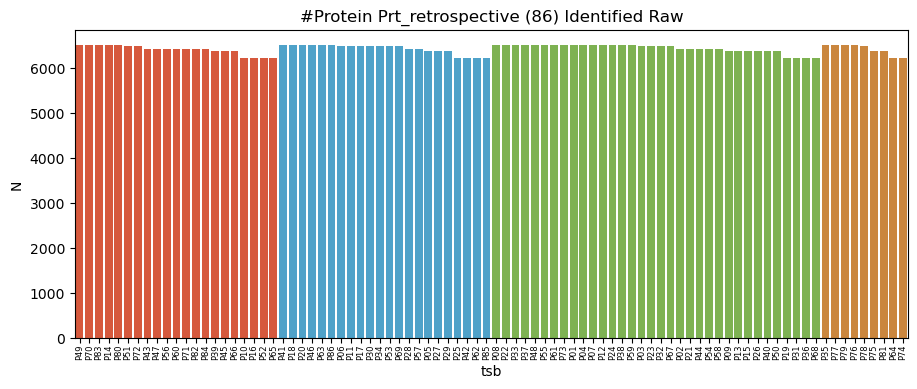

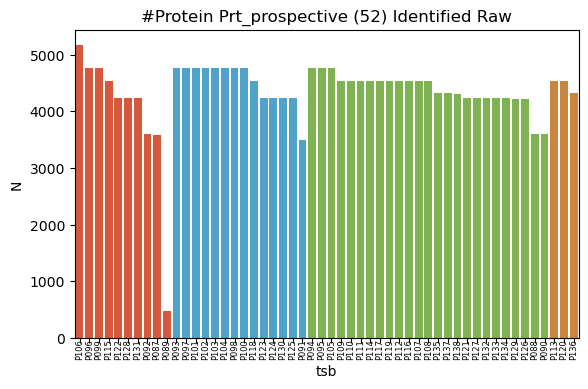

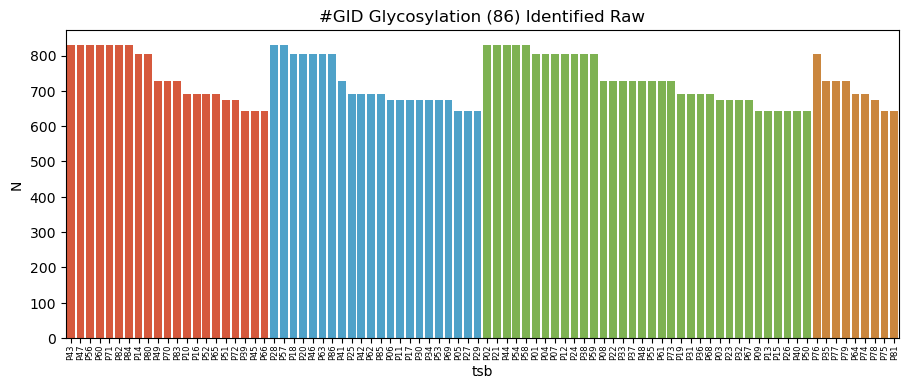

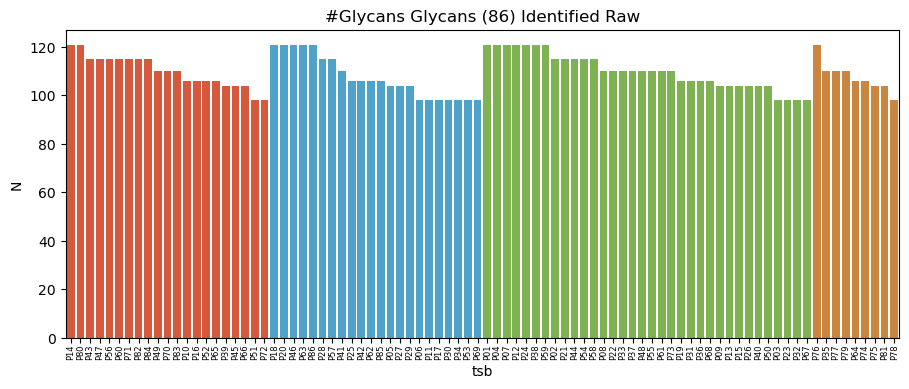

In [459]:
todo = {
    'Prt_retrospective':(mat86_na,glx86,'Protein'),
    'Prt_prospective':(mat52_na,glx52,'Protein'),
    'Glycosylation':(matgly_na,glx86,'GID'),
    'Glycans':(glycan_na_mat,glx86,'Glycans'),
}

color_map = dict(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727')

stats = {}
figs = {}
for k, (mat, glx, title) in todo.items():
    print(k, end=': ')
    df = pd.melt(mat.reset_index(),id_vars='id', value_name='N',var_name='tsb')
    la = len(df)
    df = df[~df['N'].isna()]
    lb = len(df)
    print(f"{la} => {lb} ({lb/la:.2%})")
    stat = df.groupby('tsb')[['N']].count().reset_index()
    stat = pd.merge(stat, glx, on='tsb', how='left')
    stat = stat.sort_values(['Group','N'], ascending=[True, False])   
    
    fig, ax = plt.subplots(1,1,figsize=(0.125*len(stat),4))
    sns.barplot(stat, x='tsb',y='N', ax=ax, hue='Group', palette=color_map, dodge=False)
    ax.legend_.remove()
    plt.xticks(rotation=90, ha="center", va='bottom', fontsize=6)
    plt.tick_params(axis="x", pad=12)
    plt.title(f"#{title} {k} ({len(stat)}) Identified Raw")
    figs[k] = fig
    stats[k] = stat
stats_raw = stats

In [462]:
for k,fig in figs.items():
    # article panels: S2H (retrospective proteins), S2I (prospective proteins); S2J is drawn in Fig3_S4_xR_PLOT.ipynb; Glycopeptide/Glycans plots here are not used in the article
    lab = {'Prt_retrospective':'report_c3/fig.S2H.ID_Identifed_Raw',
           'Prt_prospective':'report_c3/fig.S2I.ID_Identifed_Raw',
           'Glycosylation':'export_big/ID_Identifed_Raw',
           'Glycans':'export_big/ID_Identifed_Raw'}[k]
    out = f'{lab}.{k}.pdf'
    print(out)
    fig.savefig(out)


report_c3/fig.S2H.ID_Identifed_Raw.Prt_retrospective.pdf
report_c3/fig.S2I.ID_Identifed_Raw.Prt_prospective.pdf
export_big/ID_Identifed_Raw.Glycosylation.pdf
export_big/ID_Identifed_Raw.Glycans.pdf


In [187]:
# write_excel(stats_raw, 'fig.S2H.S2I.ID_Identifed_Raw.Statistics.xlsx', outputdir='report_c3',index=False)

  append #1 Sheet [Prt_retrospective]
  append #2 Sheet [Prt_prospective]
  append #3 Sheet [Glycosylation]
writing 1 .xls @ report_c3/fig.S2H.S2I.ID_Identifed_Raw.Statistics.xlsx


### stat filled

In [325]:
mat86 = db.importing('export_by2_86_pCR_nonpCR/prt_ori_7717.dfx', index_col=0)
mat86.index.name = 'id'
mat52 = db.importing('external_data/Proteomics52/washed/prt_mat_52.dfx', index_col=0)
mat52.index.name = 'id'

matgly = db.importing('external_data/Glycosylation/merged/gly_mat_filled.dfx', index_col=0)
matgly.index.name = 'id'


[09/06 00:35:18]reading export_by2_86_pCR_nonpCR/prt_ori_7717.dfx
[09/06 00:35:18]reading external_data/Proteomics52/washed/prt_mat_52.dfx
[09/06 00:35:18]reading external_data/Glycosylation/merged/gly_mat_filled.dfx


In [461]:
# extract glycan levels from filled mat
desgly = db.importing('external_data/Glycosylation/merged/gly_mat_id_des_ori.dfx')

assert (desgly['GID'] == matgly.index).all()
matglycan = matgly.copy()
matglycan.index = desgly['GlycanComposition']
matglycan = matglycan.reset_index()
glycan_long = pd.melt(matglycan, id_vars='GlycanComposition', var_name='tsb', value_name='abundance')
glycan_long = glycan_long[~glycan_long['abundance'].isna()].drop_duplicates(['GlycanComposition','tsb']).reset_index(drop=True)

glycan_mat = pd.pivot_table(glycan_long, index='GlycanComposition', columns='tsb', values='abundance')
glycan_mat.index.name = 'id'
glycan_mat.columns.name = None
glycan_mat



[09/21 00:51:32]reading external_data/Glycosylation/merged/gly_mat_id_des_ori.dfx


,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,P11,P12,P13,P14,P15,P16,P17,P18,P19,P20,P21,P22,P23,P24,P25,...,P62,P63,P64,P65,P66,P67,P68,P69,P70,P71,P72,P73,P74,P75,P76,P77,P78,P79,P80,P81,P82,P83,P84,P85,P86
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
H(1)N(2),0.959678,0.738296,0.942576,0.667770,1.144600,0.852402,1.027459,0.840711,0.962883,1.029440,0.949459,0.845052,0.987187,1.217366,0.799972,0.883527,1.305365,1.283730,0.951842,1.044902,0.841389,1.037327,1.013054,1.258358,1.142217,...,1.136943,1.290866,0.884178,0.765323,0.543986,0.846460,1.062147,0.985988,0.904522,0.858616,0.609057,1.459749,1.063215,0.607746,0.780509,1.498563,0.788719,1.258148,1.133797,1.094050,0.786807,0.913971,0.936822,1.184131,0.968207
H(10)N(2),1.072795,0.964271,1.021485,0.793741,0.836257,0.923248,0.981483,0.908060,1.347087,0.923778,0.910033,0.939127,1.136324,1.149327,1.280193,1.020934,1.244078,1.281221,1.056245,0.928332,0.922276,0.949235,0.884888,1.101194,0.958647,...,1.034852,1.163303,0.984320,0.870796,1.103792,0.869253,1.058066,1.086962,0.885688,0.843265,0.665373,1.115696,1.071125,0.657516,0.957185,1.190610,0.866026,1.104506,1.109893,1.764838,0.940140,0.960020,0.971172,1.082419,1.003924
H(10)N(9),0.944631,1.269167,1.090904,0.880794,1.292880,0.945287,0.899057,0.900099,0.837028,0.838726,0.957197,0.924868,0.897417,1.125552,0.906013,0.877534,1.279298,1.252981,0.913778,0.989486,1.145496,0.925824,0.886705,0.953201,0.849879,...,0.933772,1.190058,0.911581,0.787911,0.795969,1.019331,0.911921,1.037620,0.841576,1.257823,0.707126,1.022018,1.058913,0.970083,0.872293,1.073886,0.918071,1.057509,1.017947,1.132030,1.149453,0.991625,1.538043,1.012592,1.081597
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
N(1),0.922906,1.006822,1.106986,0.818707,1.230225,1.120967,0.923761,0.850010,0.893632,1.060590,0.784971,0.815430,0.912329,0.949055,0.824877,0.755766,1.303061,1.219309,1.092910,0.978502,0.942849,1.008282,0.803364,1.298081,1.000118,...,0.817189,1.091911,0.994821,1.463548,0.511351,0.754888,1.116218,1.126646,0.920809,0.882271,0.646068,1.035534,0.934799,0.889574,0.850466,1.047887,0.810315,0.984634,1.057378,1.184094,1.187279,0.940836,0.975796,0.912031,1.162317
N(1)F(1),0.989927,0.767431,0.895948,0.764611,1.260790,0.959753,1.004374,0.920161,0.835193,1.077546,0.829151,0.846146,1.190627,1.160757,0.788310,0.930596,1.329354,1.268542,1.134174,1.026203,0.967128,1.101853,0.979099,1.198204,1.045116,...,1.069086,1.221287,0.952447,1.015855,0.512982,0.760158,1.125337,1.077600,1.429459,0.864447,0.694489,1.028311,1.067366,0.830707,0.843792,1.076788,0.809798,1.179804,1.148917,1.324144,0.879168,0.984086,0.897356,1.065425,1.088783
N(2),0.889760,0.878990,1.519323,0.824703,1.109411,1.594271,1.161795,0.613635,0.859000,0.788926,1.050920,0.837309,0.848483,1.317794,0.799504,1.103368,0.736016,1.150637,0.745417,0.704540,0.727804,0.968201,0.581672,0.804042,0.811138,...,0.910518,0.883473,1.072738,0.575326,0.654376,1.019316,1.131441,1.301024,1.100182,0.679954,1.398636,1.025384,0.915557,0.881253,1.116215,1.127171,0.727902,0.829012,0.922788,1.038554,0.822971,0.954933,0.730841,0.914866,1.000585


Prt_retrospective: 663662 => 663662 (100.00%)
Prt_prospective: 238888 => 238888 (100.00%)
Glycosylation: 153682 => 153682 (100.00%)
Glycans: 14620 => 14620 (100.00%)


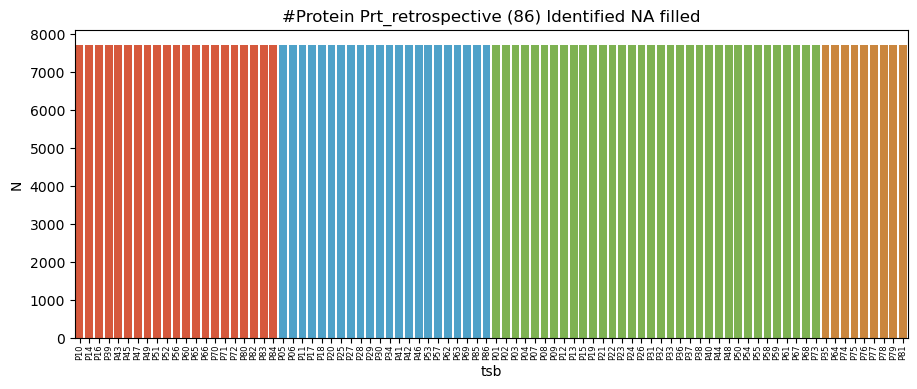

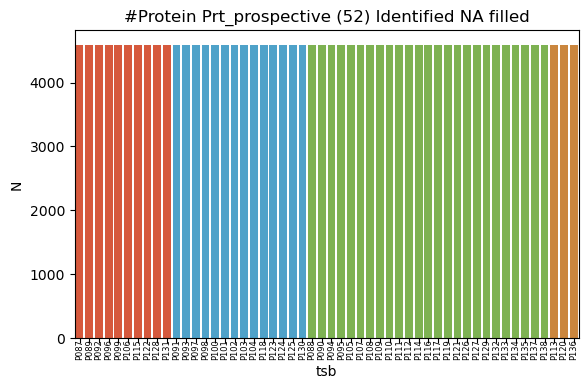

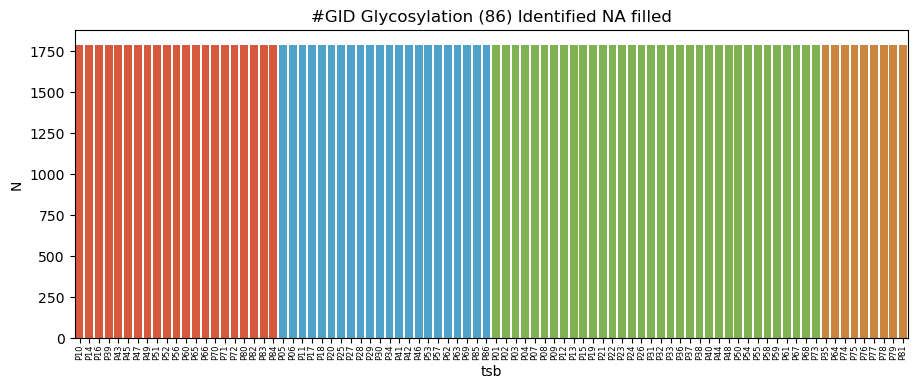

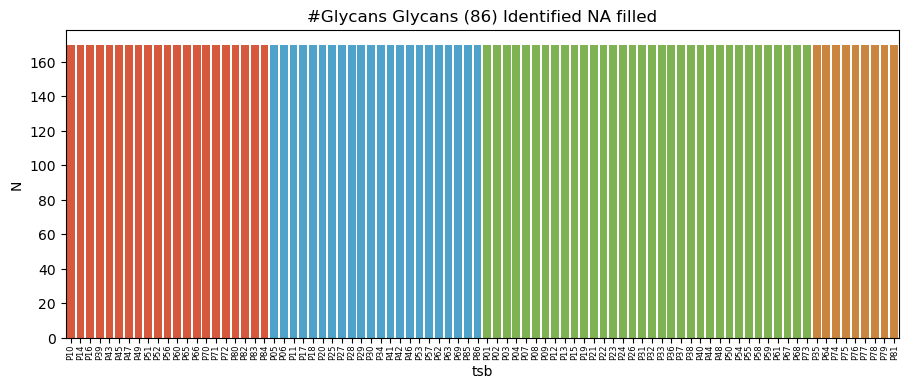

In [463]:
todo = {
    'Prt_retrospective':(mat86,glx86,'Protein'),
    'Prt_prospective':(mat52,glx52,'Protein'),
    'Glycosylation':(matgly,glx86,'GID'),
    'Glycans':(glycan_mat,glx86,'Glycans'),
}

color_map = dict(C1='#F04923',C2='#3BA9DD',C3='#7CC242',pCR='#E18727')

stats = {}
figs = {}
for k, (mat, glx, title) in todo.items():
    print(k, end=': ')
    df = pd.melt(mat.reset_index(), id_vars='id', value_name='N',var_name='tsb')
    la = len(df)
    df = df[~df['N'].isna()]
    lb = len(df)
    print(f"{la} => {lb} ({lb/la:.2%})")
    stat = df.groupby('tsb')[['N']].count().reset_index()
    stat = pd.merge(stat, glx, on='tsb', how='left')
    stat = stat.sort_values(['Group','N'], ascending=[True, False])   
    
    fig, ax = plt.subplots(1,1,figsize=(0.125*len(stat),4))
    sns.barplot(stat, x='tsb',y='N', ax=ax, hue='Group', palette=color_map, dodge=False)
    ax.legend_.remove()
    plt.xticks(rotation=90, ha="center", va='bottom', fontsize=6)
    plt.tick_params(axis="x", pad=12)
    plt.title(f"#{title} {k} ({len(stat)}) Identified NA filled")
    figs[k] = fig
    stats[k] = stat
stats_filled = stats

In [464]:
for k,fig in figs.items():
    out = f'export_big/ID_Identifed_NA_filled.{k}.pdf'
    print(out)
    fig.savefig(out)

export_big/ID_Identifed_NA_filled.Prt_retrospective.pdf
export_big/ID_Identifed_NA_filled.Prt_prospective.pdf
export_big/ID_Identifed_NA_filled.Glycosylation.pdf
export_big/ID_Identifed_NA_filled.Glycans.pdf


In [193]:
# write_excel(stats_filled, 'ID_Identifed_NA_filled.Statistics.xlsx', outputdir='export_big',index=False)

  append #1 Sheet [Prt_retrospective]
  append #2 Sheet [Prt_prospective]
  append #3 Sheet [Glycosylation]
writing 1 .xls @ export_big/ID_Identifed_NA_filled.Statistics.xlsx


### Calc Stat NA rate

In [465]:
stats = {}
for k in stats_filled.keys():
    df_raw = stats_raw[k].rename(columns={'N':'N_raw'})
    df_filled = stats_filled[k].rename(columns={'N':'N_After_filled'})
    df = pd.merge(df_raw, df_filled, how='inner', on=['tsb','Group','set'])
#     df['fill_rate/NA_rate'] = 1 - df['N_raw'] / df['N_filled']
    stats[k] = df
    

In [466]:
stats.keys()

dict_keys(['Prt_retrospective', 'Prt_prospective', 'Glycosylation', 'Glycans'])

In [468]:
stats['Glycans']

,tsb,N_raw,Group,set,N_After_filled
0,P14,121,C1,retrospective,170
1,P80,121,C1,retrospective,170
2,P43,115,C1,retrospective,170
...,...,...,...,...,...
83,P75,104,pCR,retrospective,170
84,P81,104,pCR,retrospective,170
85,P78,98,pCR,retrospective,170


In [469]:
write_excel(stats, 'fig.S2H.S2I.ID_Identifed_Raw_vs_NA_filled.Statistics.xlsx', outputdir='report_c3',index=False)

  append #1 Sheet [Prt_retrospective]
  append #2 Sheet [Prt_prospective]
  append #3 Sheet [Glycosylation]
  append #4 Sheet [Glycans]
writing 1 .xls @ export_big/ID_Identifed_NA_filled.Statistics.xlsx


## Compare Glycoprotein vs total Protein

In [260]:
glx = db.importing('./export_c3/wes_glx.dfx')
glx.columns = ['tsb','Group']
glx

[08/16 13:42:50]reading ./export_c3/wes_glx.dfx


,tsb,Group
0,P72,C1
1,P10,C1
2,P14,C1
...,...,...
83,P78,pCR
84,P76,pCR
85,P79,pCR


In [213]:
des_gly = db.importing('external_data/Glycosylation/washed/desGlycoprotein1.dfx')
des_gly

[08/16 13:23:36]reading external_data/Glycosylation/washed/desGlycoprotein1.dfx


,Protein_Name,GID,H,N,A,F,sPeptide,GlycanComposition,sGlycan,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite
0,CD47,"Q08722:CD47:73:DIYTFDGALNK:1,IBT16[N-term];11,...",5,2,0,0,DIYTFDGALNK,H(5)N(2),5 2 0 0,73,Q08722,3,HighMan,FUC,SIA,NaN,Q08722_CD47,Q08722_CD47:73
1,APMAP,"Q9HDC9:APMAP:160:AGPNGTLFVADAYK:1,IBT16[N-term...",3,3,0,1,AGPNGTLFVADAYK,H(3)N(3)F(1),3 3 0 1,160,Q9HDC9,3,NaN,FUC,NaN,NaN,Q9HDC9_APMAP,Q9HDC9_APMAP:160
2,MFAP4,"P55083:MFAP4:111;87:FNGSVSFFR:1,IBT16[N-term]:...",3,2,0,0,FNGSVSFFR,H(1)N(2),0 1 0 0,111;87,P55083,3,HighMan,FUC,SIA,Bisect,P55083_MFAP4,P55083_MFAP4:111;87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
254,ACE,"P12821:ACE:509:NETHFDAGAK:1,IBT16[N-term];10,I...",9,2,0,0,NETHFDAGAK,H(9)N(2),9 2 0 0,509,P12821,3,HighMan,NaN,NaN,NaN,P12821_ACE,P12821_ACE:509
255,ITA3,"P26006:ITA3:935:VWNSTFIEDYRDFDR:1,IBT16[N-term...",8,2,0,0,VWNSTFIEDYRDFDR,H(8)N(2),8 2 0 0,935,P26006,3,HighMan,NaN,NaN,NaN,P26006_ITA3,P26006_ITA3:935
256,PLGT3,"Q7Z4H8:PLGT3:61:YFYLQAVNSEGQNLTR:1,IBT16[N-ter...",9,2,0,0,YFYLQAVNSEGQNLTR,H(9)N(2),9 2 0 0,61,Q7Z4H8,3,HighMan,NaN,NaN,NaN,Q7Z4H8_PLGT3,Q7Z4H8_PLGT3:61


In [197]:
mat_gly = db.importing('external_data/Glycosylation/washed/matGlycoprotein1.dfx', index_col=0)
mat_gly

[08/16 13:17:19]reading external_data/Glycosylation/washed/matGlycoprotein1.dfx


,P10,P16,P19,P25,P31,P36,P42,P52,P62,P64,P65,P68,P74,P85,P05,P09,P13,P15,P26,P27,P29,P39,P40,P45,P50,...,P41,P48,P49,P55,P61,P70,P73,P77,P79,P83,P01,P04,P07,P12,P14,P18,P20,P24,P38,P46,P59,P63,P76,P80,P86
Protein_Name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CD47,4.441858,3.779819,4.371516,4.048996,3.234434,3.542588,4.097416,4.629300,4.277776,3.886557,3.712699,4.524473,4.133570,4.538775,4.062991,3.761759,4.164687,4.009382,3.188949,5.801257,4.160625,3.433180,3.154056,3.514198,4.467424,...,4.152792,3.606734,4.125667,3.998986,4.699297,3.790648,4.905587,4.235637,3.645527,4.377990,4.002324,3.315825,3.966572,3.740521,4.390171,5.155426,4.278212,4.770528,4.479848,4.701738,3.703450,4.978838,3.459271,4.715326,4.304763
APMAP,0.980364,0.883952,1.018809,1.033549,0.729328,0.894929,1.026400,1.084660,1.022919,0.976259,0.800106,1.115954,1.093445,1.148254,1.132967,0.908379,0.911321,0.818591,0.757842,1.415306,0.972631,0.729582,0.730898,0.693676,0.896096,...,0.914192,0.937314,0.993747,1.121365,1.122648,0.962733,1.178666,1.270963,1.117420,0.980111,0.956066,0.724706,1.031129,0.835977,1.268521,1.226571,0.929988,1.121186,0.929619,1.010970,0.943118,1.189545,0.862723,1.106126,1.045284
MFAP4,115.596894,103.216628,124.580244,108.290633,95.411568,89.997471,120.375427,123.080065,109.740567,121.715541,124.802839,131.736983,114.130006,111.102080,135.939353,91.653153,98.149934,88.888299,77.892195,158.256362,103.201614,89.757937,84.491729,82.730002,107.930846,...,107.699510,112.000306,110.632764,121.717873,145.985178,106.309949,119.882424,121.621700,113.537413,110.481865,101.045897,90.452282,107.359319,95.961221,122.023435,155.575757,116.247406,132.352167,128.563569,127.592357,109.901927,129.191645,101.524351,115.358447,133.432458
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ACE,0.948125,0.905334,1.021342,0.874567,0.869191,0.913245,0.957084,1.147509,0.996376,0.915647,0.859100,1.036365,1.086783,0.958699,1.421277,0.660634,1.003894,0.700911,0.731636,0.986948,1.060836,0.663779,0.566220,0.759796,0.785853,...,1.009790,0.959177,0.939591,0.971430,1.074791,0.843695,1.031934,1.095458,1.089937,1.007734,1.032712,0.884219,1.344123,1.142872,1.176928,1.328039,0.920169,1.003955,1.251361,1.496975,0.978505,0.892061,1.094269,1.586524,1.005421
ITA3,2.027701,1.895685,2.027156,2.033360,1.589058,1.784089,1.952119,2.379879,2.196781,1.921998,1.691838,2.247210,2.107095,2.188300,2.363032,1.863280,1.862410,1.651717,1.494295,2.915245,1.971325,1.451775,1.516244,1.405688,1.843801,...,2.017635,1.893242,1.767837,1.954514,2.169850,1.892982,2.401217,2.642168,2.437683,2.060027,1.992631,1.489115,2.049575,1.780688,2.419868,2.697282,2.110206,2.302707,1.975667,2.309086,1.823140,2.540371,1.696129,2.234850,2.141948
PLGT3,1.046691,0.964266,1.070112,1.036470,0.828224,0.904069,1.025748,1.253081,1.107486,1.042580,0.895170,1.189240,1.078153,1.178421,1.167562,0.892804,0.948398,0.798038,0.721042,1.454144,0.977789,0.705068,0.690881,0.675149,0.899130,...,0.915182,0.938241,1.033259,0.935491,1.214011,0.911107,1.202114,1.448888,1.140477,0.939752,1.049789,0.752446,1.057639,0.928258,1.102002,1.366597,1.071865,1.016390,0.889579,1.040947,0.979479,1.046363,0.984115,1.011711,0.967642


In [214]:
des_gly[des_gly['Protein_Name'].str.contains(';')]

,Protein_Name,GID,H,N,A,F,sPeptide,GlycanComposition,sGlycan,sProPos,Protein_ID,sCharge,HighMannose,Fucose,Sialic Acid,Bisect,sProteinNameID,Glycosite
11,IGHG1;IGG1,"P01857;P0DOX5:IGHG1;IGG1:299;180:EEQYNSTYR:1,I...",3,3,0,1,EEQYNSTYR,H(3)N(2),3 2 0 0,299;180,P01857;P0DOX5,2,HighMan,FUC,SIA,Bisect,P01857;P0DOX5_IGHG1;IGG1,P01857;P0DOX5_IGHG1;IGG1:299;180
29,A1AG2;A1AG1,"P19652;P02763:A1AG2;A1AG1:56:NEEYNK:1,IBT16[N-...",4,3,0,0,NEEYNK,H(4)N(3),4 3 0 0,56,P19652;P02763,2,NaN,FUC,SIA,NaN,P19652;P02763_A1AG2;A1AG1,P19652;P02763_A1AG2;A1AG1:56
37,CO4A;CO4B,"P0C0L5;P0C0L4:CO4A;CO4B:1328:GLNVTLSSTGR:1,IBT...",5,4,2,0,FSDGLESNSSTQFEVK,H(5)N(4)A(2),5 4 2 0,1328,P0C0L5;P0C0L4,3,HighMan,NaN,SIA,NaN,P0C0L5;P0C0L4_CO4A;CO4B,P0C0L5;P0C0L4_CO4A;CO4B:1328
62,IGA2;IGHA2,"P0DOX2;P01877:IGA2;IGHA2:205;320:TPLTANITK:1,I...",4,3,1,1,TPLTANITK,H(3)N(4)F(1),3 4 0 1,205;320,P0DOX2;P01877,3,NaN,FUC,SIA,Bisect,P0DOX2;P01877_IGA2;IGHA2,P0DOX2;P01877_IGA2;IGHA2:205;320
64,SRPK3;SRPK2;SRPK1,Q96SB4;Q9UPE1;P78362:SRPK3;SRPK2;SRPK1:336;412...,4,3,0,0,IADLGNACWVHK,H(4)N(3),4 3 0 0,336;412;671;411;484;378;533;544;500,Q96SB4;Q9UPE1;P78362,3,NaN,NaN,NaN,NaN,Q96SB4;Q9UPE1;P78362_SRPK3;SRPK2;SRPK1,Q96SB4;Q9UPE1;P78362_SRPK3;SRPK2;SRPK1:336;412...
97,HPT;HPTR,P00738;P00739:HPT;HPTR:126;163;184;125:MVSHHNL...,5,4,2,0,MVSHHNLTTGATLINEQWLLTTAK,H(5)N(4)A(2),5 4 2 0,126;163;184;125,P00738;P00739,4,NaN,NaN,SIA,NaN,P00738;P00739_HPT;HPTR,P00738;P00739_HPT;HPTR:126;163;184;125


In [275]:
gly = des_gly[['Protein_Name']].reset_index().copy().rename(columns={'index':'gly_index'})
gly['Gly_Protein_Name_index'] = gly['Protein_Name']
gly['Protein_Name'] = gly['Protein_Name'].str.split(';')
gly = gly.explode('Protein_Name')
gly


,gly_index,Protein_Name,Gly_Protein_Name_index
0,0,CD47,CD47
1,1,APMAP,APMAP
2,2,MFAP4,MFAP4
...,...,...,...
254,254,ACE,ACE
255,255,ITA3,ITA3
256,256,PLGT3,PLGT3


In [276]:
matp = db.importing('export_by2_86_pCR_nonpCR/prt_ori_7717.dfx', index_col=0)
prt = pd.Series(matp.index)
prt[prt=='P0C0L5_C4B_2'] = 'P0C0L5_C4B'
matp.index = prt.values
prt = prt.str.split('_',expand=True,regex=False)
prt[2] = matp.index
prt.columns = ['pid','Protein_Name','prt_index']
prt

[08/16 13:50:19]reading export_by2_86_pCR_nonpCR/prt_ori_7717.dfx


,pid,Protein_Name,prt_index
0,A0A075B6H7,IGKV3-7,A0A075B6H7_IGKV3-7
1,A0A075B6H9,IGLV4-69,A0A075B6H9_IGLV4-69
2,A0A075B6I0,IGLV8-61,A0A075B6I0_IGLV8-61
...,...,...,...
7714,Q9Y6X8,ZHX2,Q9Y6X8_ZHX2
7715,Q9Y6X9,MORC2,Q9Y6X9_MORC2
7716,Q9Y6Y8,SEC23IP,Q9Y6Y8_SEC23IP


In [277]:
x = pd.merge(gly, prt, how='inner',on='Protein_Name')
x

,gly_index,Protein_Name,Gly_Protein_Name_index,pid,prt_index
0,0,CD47,CD47,Q08722,Q08722_CD47
1,1,APMAP,APMAP,Q9HDC9,Q9HDC9_APMAP
2,2,MFAP4,MFAP4,P55083,P55083_MFAP4
...,...,...,...,...,...
86,247,ERCC5,ERCC5,P28715,P28715_ERCC5
87,251,ALDOB,ALDOB,P05062,P05062_ALDOB
88,254,ACE,ACE,P12821,P12821_ACE


In [278]:
x.drop_duplicates('gly_index')

,gly_index,Protein_Name,Gly_Protein_Name_index,pid,prt_index
0,0,CD47,CD47,Q08722,Q08722_CD47
1,1,APMAP,APMAP,Q9HDC9,Q9HDC9_APMAP
2,2,MFAP4,MFAP4,P55083,P55083_MFAP4
...,...,...,...,...,...
86,247,ERCC5,ERCC5,P28715,P28715_ERCC5
87,251,ALDOB,ALDOB,P05062,P05062_ALDOB
88,254,ACE,ACE,P12821,P12821_ACE


In [279]:
x.drop_duplicates('prt_index')

,gly_index,Protein_Name,Gly_Protein_Name_index,pid,prt_index
0,0,CD47,CD47,Q08722,Q08722_CD47
1,1,APMAP,APMAP,Q9HDC9,Q9HDC9_APMAP
2,2,MFAP4,MFAP4,P55083,P55083_MFAP4
...,...,...,...,...,...
86,247,ERCC5,ERCC5,P28715,P28715_ERCC5
87,251,ALDOB,ALDOB,P05062,P05062_ALDOB
88,254,ACE,ACE,P12821,P12821_ACE


In [283]:
_ = x[x['gly_index'].duplicated(keep=False)]
_

,gly_index,Protein_Name,Gly_Protein_Name_index,pid,prt_index
26,64,SRPK2,SRPK3;SRPK2;SRPK1,P78362,P78362_SRPK2
27,64,SRPK1,SRPK3;SRPK2;SRPK1,Q96SB4,Q96SB4_SRPK1


In [284]:
glycoed_parent_prt = matp.loc[x['prt_index'],glx['tsb']]
glycoed_glycoprt = mat_gly.iloc[x['gly_index']].loc[:,glx['tsb']]
glycoed_parent_prt.index.name='Protein_ID_NAME'


In [269]:
glycoed_parent_prt

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,P49,P65,P51,P39,P45,P66,P34,P05,P29,P69,...,P54,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
Protein_ID_NAME,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Q08722_CD47,0.477605,0.452454,-0.314939,0.196421,-0.292215,-0.280187,0.013036,0.027184,-0.171236,-0.090686,-0.045211,-0.036192,-0.108556,-0.031306,-0.227839,0.099249,-0.174066,-0.028659,-0.002652,-0.114851,0.072861,-0.029024,-0.100616,-0.157399,-0.099544,...,-0.218435,-0.006428,-0.079809,0.056006,-0.000303,0.197634,0.002293,-0.045483,0.014610,-0.095359,-0.196260,-0.026110,-0.252456,0.081147,-0.019921,0.089574,-0.025376,0.028536,-0.149238,-0.122321,0.145826,0.274891,-0.155165,-0.025560,-0.143381
Q9HDC9_APMAP,0.034066,0.121089,0.240355,-0.137181,-0.082336,-0.057120,0.277792,0.162226,-0.130478,-0.053970,-0.144284,0.042655,0.013221,0.004615,-0.137391,-0.023718,-0.013579,-0.014338,0.046866,0.046680,-0.145707,0.002350,0.140844,0.031379,0.261292,...,0.032237,-0.075591,-0.089879,0.005767,-0.134153,0.016747,-0.040774,0.021842,-0.051130,0.069856,-0.038577,0.010361,0.001089,0.006734,0.016398,-0.041382,-0.122585,-0.093894,-0.081734,-0.022623,-0.044510,0.036120,0.006691,-0.008872,-0.279225
P55083_MFAP4,-1.077629,-0.148045,-1.179230,-1.321057,-0.857000,-0.832283,0.126021,-0.987396,-0.448203,-0.430437,-0.180156,0.797861,0.447433,-0.596098,-0.939340,-0.303959,0.696161,-0.137956,0.024213,-0.066223,-1.157635,-0.763341,0.290845,-0.248907,-0.307328,...,-0.054109,-0.291869,0.309542,-0.137124,-0.495841,0.165093,-0.752690,0.015052,-0.624558,-0.700349,0.075758,-0.214843,0.191889,-0.630372,0.095253,0.210238,-0.643313,0.808481,0.669589,0.015906,0.454441,0.518149,-0.014242,-0.007784,-1.181548
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P28715_ERCC5,0.083086,-0.090812,0.146495,-0.340490,-0.031085,-0.031257,0.195842,0.250251,-0.106412,0.236010,-0.066147,0.254146,0.185441,0.196628,-0.369779,-0.000350,-0.083402,0.319391,0.199407,0.186147,0.207968,-0.055175,0.014306,0.245676,0.139237,...,-0.048502,-0.108887,0.200343,0.120233,-0.088075,0.119548,0.029390,0.070120,0.135173,0.158763,0.155771,0.237204,0.213363,-0.045282,0.162181,-0.051106,-0.137482,-0.047091,0.124448,0.280517,0.071549,-0.018770,0.047384,0.073224,0.319761
P05062_ALDOB,-0.206587,-0.022250,-0.066885,0.090701,0.061197,0.065760,-0.091897,0.071841,-0.188935,-0.150515,-0.353702,0.100691,-0.068557,-0.502474,-0.307883,-0.319030,-0.075071,1.311653,-0.074134,0.022822,-0.087105,0.169660,0.101390,0.129504,0.000886,...,0.056972,-0.087962,0.001195,-0.190519,0.012751,-0.154251,-0.028692,0.098424,-0.021562,-0.019879,0.075002,0.064197,-0.104909,0.011494,-0.003468,0.057447,0.172108,0.226322,-0.056204,-0.006489,-0.040922,-0.001071,-0.203122,-0.063366,0.937762
P12821_ACE,0.518180,-0.151352,0.103184,0.282169,-0.119156,-0.492611,0.154481,-0.091657,-0.084087,0.389254,-0.023817,-0.163923,-0.327102,-0.552275,-0.008336,-0.045391,-0.157367,-0.253386,0.090628,0.697757,0.068719,0.132656,0.553540,0.688109,0.309839,...,-0.186308,-0.073598,0.075942,-0.039378,-0.201777,-0.253859,-0.164400,0.081484,0.086546,0.163640,-0.230410,0.031320,0.090092,-0.193906,0.031136,-0.189470,0.224730,0.154702,0.578536,-0.298733,-0.228196,-0.174668,0.226038,0.234413,-0.037550


In [265]:
glycoed_glycoprt

,P72,P10,P14,P56,P16,P52,P47,P80,P70,P71,P83,P82,P84,P43,P60,P49,P65,P51,P39,P45,P66,P34,P05,P29,P69,...,P54,P08,P55,P22,P07,P33,P09,P40,P15,P26,P50,P04,P02,P01,P21,P48,P77,P35,P81,P74,P75,P64,P78,P76,P79
Protein_Name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CD47,2.698208,4.441858,4.390171,3.147997,3.779819,4.629300,3.973403,4.715326,3.790648,3.556445,4.377990,3.852469,3.943653,2.588289,3.136186,4.125667,3.712699,3.026366,3.433180,3.514198,3.069779,4.275422,4.062991,4.160625,4.024420,...,4.114719,3.722067,3.998986,4.323588,3.966572,4.489979,3.761759,3.154056,4.009382,3.188949,4.467424,3.315825,3.749330,4.002324,3.674545,3.606734,4.235637,4.178024,5.013313,4.133570,3.569551,3.886557,3.469060,3.459271,3.645527
APMAP,0.598773,0.980364,1.268521,0.749046,0.883952,1.084660,0.692612,1.106126,0.962733,0.841862,0.980111,0.863342,0.959473,0.633083,0.663273,0.993747,0.800106,0.757617,0.729582,0.693676,0.644662,1.104681,1.132967,0.972631,1.041584,...,0.904385,0.919095,1.121365,1.081594,1.031129,1.152527,0.908379,0.730898,0.818591,0.757842,0.896096,0.724706,0.904041,0.956066,0.870461,0.937314,1.270963,0.871457,1.123072,1.093445,0.721766,0.976259,0.823400,0.862723,1.117420
MFAP4,75.028871,115.596894,122.023435,83.447034,103.216628,123.080065,97.960588,115.358447,106.309949,96.987604,110.481865,124.930287,115.425760,68.815367,72.589631,110.632764,124.802839,90.251606,89.757937,82.730002,65.076876,119.973141,135.939353,103.201614,115.109272,...,112.999849,99.345103,121.717873,117.360497,107.359319,136.065295,91.653153,84.491729,88.888299,77.892195,107.930846,90.452282,102.944372,101.045897,104.340091,112.000306,121.621700,112.544124,135.075317,114.130006,99.103862,121.715541,93.747449,101.524351,113.537413
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ERCC5,0.691644,0.934613,0.909989,0.890343,0.869392,1.152893,0.846081,1.018952,0.932779,0.871784,0.923844,1.142658,1.013150,0.667415,0.696242,1.004950,0.921409,0.735325,0.812162,0.676183,0.697855,1.066646,1.131395,0.867308,1.051730,...,1.072240,0.819181,0.992374,0.888905,0.914689,1.011472,0.794579,0.681726,0.825622,0.727904,0.873006,0.730142,1.050322,0.927584,0.875780,0.936349,1.106469,1.026763,1.176525,1.001169,0.799619,0.933832,0.877501,0.789494,0.935803
ALDOB,0.680691,0.941658,0.877960,0.933832,0.876113,1.089541,1.068825,1.020429,0.843939,1.085955,1.036235,1.473385,1.368728,0.699601,0.831650,0.794866,0.977762,0.603792,0.945741,0.728099,0.826839,1.003607,1.392086,1.003002,0.948429,...,0.914590,0.906437,0.905197,1.130134,0.788868,1.047933,0.820756,0.714992,0.989784,0.898764,0.944494,0.920899,1.783604,1.101926,1.233284,0.863406,0.955118,1.129355,0.926158,1.241365,1.075851,0.924377,0.989761,0.799307,0.759662
ACE,1.735032,0.948125,1.176928,0.844933,0.905334,1.147509,0.839568,1.586524,0.843695,0.935697,1.007734,1.064477,1.010456,0.654964,0.698132,0.939591,0.859100,0.767898,0.663779,0.759796,0.647016,1.364350,1.421277,1.060836,1.161890,...,0.923849,0.918198,0.971430,1.022515,1.344123,1.071600,0.660634,0.566220,0.700911,0.731636,0.785853,0.884219,1.048964,1.032712,0.933240,0.959177,1.095458,0.984030,1.008879,1.086783,0.598421,0.915647,1.495868,1.094269,1.089937


In [267]:
INPUTROOT

'export_c3'

In [270]:
db.exporting(glycoed_parent_prt,'mat_GLYxPRT_proteomic_part',outputdir=INPUTROOT)
db.exporting(glycoed_glycoprt,'mat_GLYxPRT_glycosylation_part',outputdir=INPUTROOT)

[08/16 13:46:47] writing 1 file with 89 lines at 
	[PROJECT_ROOT]/export_c3/mat_GLYxPRT_proteomic_part.dfx
[08/16 13:46:47] writing 1 file with 89 lines at 
	[PROJECT_ROOT]/export_c3/mat_GLYxPRT_glycosylation_part.dfx


In [287]:
write_excel(
    {
        'proteomic_part':glycoed_parent_prt,
        'glycosylation_part':glycoed_glycoprt,
        'intersection_id_info':x,
        'duplicated_ids':_,
    }, 
    'GLYxPRT_overlap.xlsx', 
    outputdir='report_reply'
)

  append #1 Sheet [proteomic_part]
  append #2 Sheet [glycosylation_part]
  append #3 Sheet [intersection_id_info]
  append #4 Sheet [duplicated_ids]
writing 1 .xls @ report_reply/GLYxPRT_overlap.xlsx


### focus on marker prt

In [312]:
sig = pd.read_csv('export_c3/fig3_c2_sig_de_glycoprotein.dfx',sep='\t')
sig

,symbol,log2FoldChange,baseMean,t,pvalue,padj,B,stat,abs_log2FC,FC_Ins,median_C2,median_Others
0,THRB,1.120170,6.660870,4.992915,0.000004,0.000131,4.085545,4.992915,1.120170,True,7.373533,6.461160
1,LIN54,1.909846,10.698386,4.966978,0.000004,0.000131,3.989189,4.966978,1.909846,True,11.820454,10.007293
2,FIBG,4.447499,24.367879,4.697449,0.000011,0.000174,3.003211,4.697449,4.447499,True,26.971242,22.767539
...,...,...,...,...,...,...,...,...,...,...,...,...
48,ZN608,3.541452,11.893141,2.913572,0.004691,0.006552,-2.612497,2.913572,3.541452,True,12.445970,10.570795
49,COEA1,2.797909,25.928153,2.770470,0.007033,0.009222,-2.977660,2.770470,2.797909,True,27.527386,24.578644
50,IGHG1;IGG1,7.903318,44.835412,2.749131,0.007463,0.009687,-3.030837,2.749131,7.903318,True,47.926166,40.211929


In [315]:
sel = ['MFAP4','LAMP1','LAMA4']
for i in sel:
    print(i, i in sig['symbol'].values)

MFAP4 True
LAMP1 True
LAMA4 True


In [289]:
print("DONE")


DONE


## WES 补充

In [500]:
HRRm = ["ATM", "BARD1", "BRCA1", "BRCA2", "BRIP1", "CDK12", 
        "CHEK1", "CHEK2", "FANCL", "PALB2", "RAD51B", 
        "RAD51C", "RAD51D", "RAD54L"]

## Others

In [79]:
x = pho.iloc[:20,:]
mask = x.apply(lambda i: pd.isna(i).any(),0)
mask2 = x.apply(lambda i: (i==0).any())
x = x.loc[:,~(mask|mask2)]
x


,Proteins,Positions within proteins,Leading proteins,Protein,Localization prob,PEP,Score,Delta score,Score for localization,Amino acid,Sequence window,Modification window,Peptide window coverage,Phospho (STY) Probabilities,Phospho (STY) Score diffs,Position in peptide,Charge,Mass error [ppm],Potential contaminant,Protein group IDs,Positions,Position,Peptide IDs,Mod. peptide IDs,Best localization evidence ID,Best localization MS/MS ID,Best localization raw file,Best localization scan number,Best score evidence ID,Best score MS/MS ID,Best score raw file,Best score scan number,Best PEP evidence ID,Best PEP MS/MS ID,Best PEP raw file,Best PEP scan number
0,CON__P04258;sp|P02461|CO3A1_HUMAN,1039;1039,CON__P04258;sp|P02461|CO3A1_HUMAN,sp|P02461|CO3A1_HUMAN,1.000000,4.893830e-04,44.158,29.997,44.158,S,RDGAPGAKGDRGENGSPGAPGAPGHPGPPGP;RDGSPGGKGDRGEN...,X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;Phospho (STY);X;...,XXXXXXXXXXXPPPPPPPPPPPPPPPPPPPP,GENGS(1)PGAPGAPGHPGPPGPVGPAGK,GENGS(44.16)PGAPGAPGHPGPPGPVGPAGK,5,3,4.19780,+,8;264,1039;1039,1039,1769,1932,14539,14702,20231011-FangPan-P-PE-4_1,20506,14539,14702,20231011-FangPan-P-PE-4_1,20506,14539,14702,20231011-FangPan-P-PE-4_1,20506
1,CON__P04258,388,CON__P04258,CON__P04258,0.500000,2.981620e-03,41.087,17.915,41.087,S,PQGHAGAPGPPGPPGSNGSPGGKGEMGPAGI,X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;Phospho (STY);X;...,PPPPPPPPPPPPPPPPPPPPPPPXXXXXXXX,GEPGPQGHAGAPGPPGPPGS(0.5)NGS(0.5)PGGK,GEPGPQGHAGAPGPPGPPGS(0)NGS(0)PGGK,20,3,-1.52820,+,8,388,388,1772,1935,14554,14717,20231011-FangPan-P-PE-3_2,32788,14554,14717,20231011-FangPan-P-PE-3_2,32788,14554,14717,20231011-FangPan-P-PE-3_2,32788
2,CON__P04258,391,CON__P04258,CON__P04258,0.500000,2.981620e-03,41.087,17.915,41.087,S,HAGAPGPPGPPGSNGSPGGKGEMGPAGIPGA,X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;...,XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX,GEPGPQGHAGAPGPPGPPGS(0.5)NGS(0.5)PGGK,GEPGPQGHAGAPGPPGPPGS(0)NGS(0)PGGK,23,3,-1.52820,+,8,391,391,1772,1935,14554,14717,20231011-FangPan-P-PE-3_2,32788,14554,14717,20231011-FangPan-P-PE-3_2,32788,14554,14717,20231011-FangPan-P-PE-3_2,32788
3,sp|P04264|K2C1_HUMAN;CON__P04264,21;21,sp|P04264|K2C1_HUMAN,sp|P04264|K2C1_HUMAN,0.999440,4.277150e-127,178.020,155.140,178.020,S,SSRSGYRSGGGFSSGSAGIINYQRRTTSSST,X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;Phospho (STY);X;...,XXXXXXXPPPPPPPPPPPPPPPPPXXXXXXX,SGGGFSSGS(0.999)AGIINYQR,S(-82.2)GGGFS(-39.01)S(-33.61)GS(33.61)AGIINY(...,9,2,0.10580,+,9,21,21,4174,4568,33059,33629,20231011-FangPan-P-PE-2_1,48006,33059,33629,20231011-FangPan-P-PE-2_1,48006,33059,33629,20231011-FangPan-P-PE-2_1,48006
4,sp|P04264|K2C1_HUMAN;CON__P04264,66;66,sp|P04264|K2C1_HUMAN,sp|P04264|K2C1_HUMAN,1.000000,4.529340e-03,102.870,52.068,102.870,S,GGGGSFGAGGGFGSRSLVNLGGSKSISISVA,X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;Phospho (STY);X;...,XXXXXXXXXXXXXXXPPPPPPPPPXXXXXXX,S(1)LVNLGGSK,S(84.81)LVNLGGS(-84.81)K,1,2,0.38860,+,9,66,66,4308,4715,34029,34611,20231011-FangPan-P-PE-2_5,49882,34029,34611,20231011-FangPan-P-PE-2_5,49882,34028,34610,20231011-FangPan-P-PE-2_2,49841
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15,sp|P13647|K2C5_HUMAN;CON__P13647,28;28,sp|P13647|K2C5_HUMAN,sp|P13647|K2C5_HUMAN,0.880221,9.398160e-76,165.160,131.110,134.930,S,GSRSFSTASAITPSVSRTSFTSVSRSGGGGG,X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;Phospho (STY);X;...,XXXPPPPPPPPPPPPPPXXXXXXXXXXXXXX,SFSTASAIT(0.001)PS(0.119)VS(0.88)R,S(-106.72)FS(-107.08)T(-104.36)AS(-72.07)AIT(-...,13,3,1.27770,+,15,28,28,4150,4537,32771,33341,20231011-FangPan-P-PE-1_4,46719,32770,33340,20231011-FangPan-P-PE-1_3,46552,32770,33340,20231011-FangPan-P-PE-1_3,46552
16,sp|P13647|K2C5_HUMAN;CON__P13647,64;64,sp|P13647|K2C5_HUMAN,sp|P13647|K2C5_HUMAN,0.999999,1.707520e-03,105.650,64.250,102.620,S,VSLAGACGVGGYGSRSLYNLGGSKRISISTS,X;X;X;X;X;X;X;X;X;X;X;X;X;X;X;Phospho (STY);X;...,XXXXXXXXXXXXXXXPPPPPPPPPXXXXXXX,S(1)LYNLGGSK,S(59.11)LY(-59.11)NLGGS(-89.99)K,1,2,1.97720,+,15,64,64,4312,4722,34102,34684,20231011-FangPan-P-PE-3_5,5

In [62]:
pho = db.importing('external_info/Phosphorylation/phospho-3rd.xlsx',sheet_name=1,show_all_sheets=True)
pho


[02/05 06:33:18]reading external_info/Phosphorylation/phospho-3rd.xlsx
  Sheets list: ['Quant.spectra', 'phospho']
  Read the 1 / 2 sheet named <phospho>


,File_Name,Scan_No,Exp.MH+,Charge,Q-value,Sequence,Calc.MH+,Mass_Shift(Exp.-Calc.),Raw_Score,Final_Score,Modification,Specificity,Proteins,Positions,Label,Target/Decoy,Miss.Clv.Sites,Avg.Frag.Mass.Shift,Others,Supp_Info,Empty_Separator,ReportIon (114.1277),ReportIon (115.1248),ReportIon (115.1311),ReportIon (116.1281),ReportIon (116.1344),ReportIon (117.1315),ReportIon (117.1378),ReportIon (118.1348),ReportIon (118.1411),ReportIon (119.1382),ReportIon (119.1445),ReportIon (120.1415),ReportIon (120.1479),ReportIon (121.1449),ReportIon (121.1512),ReportIon (122.1482)
0,20231011-FangPan-P-PE-1_1.74572.74572.5.0.dta,74572,3229.704530,5,0.000000,VIHDNFGIVEGLMTTVHAITATQK,3229.702404,0.002126,27.608729,0.000012,"0,IBT-16-N-term;15,Phospho[T];24,IBT-16-K;",3,sp|P04406|G3P_HUMAN/,"162,K,T/",1|0|0|0|,target,0,0.917432,32,NaN,NaN,5597.0,5420.0,8511.1,7420.5,7093.1,7245.5,4881.8,5718.3,8597.0,4926.8,6170.8,7553.7,9645.5,8791.3,5517.5,7996.6
1,20231011-FangPan-P-PE-1_1.79789.79789.3.0.dta,79789,3259.564387,3,0.000000,TPSSYGAGELLDFSLADAVNQEFLTTR,3259.564838,-0.000451,32.597296,0.000021,"0,IBT-16-N-term;3,Phospho[S];",3,sp|P17661|DESM_HUMAN/,"78,R,T/",1|0|0|,target,0,-0.952024,36,NaN,NaN,28174.7,39551.5,45800.6,47882.9,52566.6,44936.0,26941.3,28746.9,46381.2,16362.5,31443.8,44101.7,81535.7,88051.2,12243.3,27935.0
2,20231011-FangPan-P-PE-1_1.66586.66586.3.0.dta,66586,2386.123576,3,0.000000,TFGPPPSLSPGAFSYSSSSR,2386.120518,0.003058,26.887685,0.000025,"0,IBT-16-N-term;9,Phospho[S];",3,sp|P41219|PERI_HUMAN/,"19,R,F/",1|0|0|,target,0,0.476523,32,NaN,NaN,9397.2,14100.3,13606.7,22161.9,17994.0,17780.9,15808.1,10345.9,23977.3,12897.4,18952.1,16594.4,24149.5,27952.1,12342.1,15698.8
3,20231011-FangPan-P-PE-1_1.49151.49151.3.0.dta,49151,3107.470520,3,0.000000,VADAKGDSESEEDEDLEVPVPSR,3107.463742,0.006778,29.224351,0.000025,"0,IBT-16-N-term;5,IBT-16-K;8,Phospho[S];",3,sp|P13861|KAP2_HUMAN/,"70,R,F/",1|0|0|0|,target,1,-0.576007,36,NaN,NaN,20555.1,22766.8,43726.0,36028.6,28657.7,32681.1,22473.0,15946.1,46048.3,27029.9,33779.6,38927.3,29772.9,30311.7,27924.0,32588.4
4,20231011-FangPan-P-PE-1_1.52415.52415.3.0.dta,52415,2721.328386,3,0.000000,QLHLEGASLELSDDDTESK,2721.319996,0.008390,28.279757,0.000033,"0,IBT-16-N-term;12,Phospho[S];19,IBT-16-K;",3,sp|P35580|MYH10_HUMAN/,"1944,R,T/",1|0|0|0|,target,0,2.217945,96,NaN,NaN,37163.2,50561.1,53322.6,68078.3,58837.8,76936.0,51927.5,40624.4,79947.2,80584.2,62141.5,66401.7,68649.8,76226.7,78995.3,52226.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20795,20231011-FangPan-P-PE-6_5.50250.50250.3.3.dta,50250,2951.482036,3,0.009474,GEQGPAGSPGFQGLPGPAGPPGEAGK,2951.463237,0.018799,9.127343,0.272006,"0,IBT-16-N-term;8,Phospho[S];26,IBT-16-K;",3,sp|P02452|CO1A1_HUMAN/,"631,R,P/",1|0|0|0|,target,0,4.419653,100,NaN,NaN,36821.0,33060.0,43441.3,43185.9,38379.5,60611.4,32231.5,38153.2,50848.3,46502.5,44048.3,32415.3,43323.1,46726.8,48525.8,36791.7
20796,20231011-FangPan-P-PE-6_5.51081.51081.3.0.dta,51081,2842.261529,3,0.009474,FSGLQGPPGPPGSPGEQGPSGASGPAGPR,2842.267838,-0.006309,12.565353,0.272852,"2,PhosphoHex[S];",1,sp|P02452|CO1A1_HUMAN/,"1112,G,G/",1|0|,target,0,-1.728226,36,NaN,NaN,29764.2,37646.7,25514.7,31060.8,29490.2,34219.9,30013.3,21870.8,27243.4,24114.5,26210.4,29135.2,36481.0,23662.7,30089.4,29021.7
20797,20231011-FangPan-P-PE-6_5.18256.18256.3.0.dta,18256,1183.644291,3,0.009474,TRLSPPR,1183.643782,0.000509,8.259772,0.277509,"0,IBT-16-N-term;4,Phospho[S];",3,sp|Q96PK6|RBM14_HUMAN/,"578,R,A/",1|0|0|,target,1,-0.609276,32,NaN,NaN,7079.2,10327.6,8646.2,6395.8,8356.0,11116.6,8603.6,8177.8,6386.6,6805.7,7403.9,10103.5,13192.3,6751.7,8830.8,14115.2
20798,20231011-FangPan-P-PE-6_5.75480.75480.3.0.dta,75480,2236.195285,3,0.009907,SLSDFTGPPQLQALK,2236.195866,-0.000581,10.243048,0.277923,"0,IBT-16-N-term;3,Phospho[S];15,IBT-16-K;",3,sp|O95425|SVIL_HUMAN/,"546,R,Y/",1|0|0|0|,target,0,-2.770107,36,NaN,NaN,6124.0,10144.1,2803.

In [ ]:
glx = db.importing('export_by2_86_pCR_nonpCR/wes_glx.dfx')
glx['uid'] = glx['uid'].astype("str")

convert = db.importing('external_info/Glycosylation/报告离子对应样品编号修改.xlsx')
x = convert['编号'].str.split('-',expand=True)
x.columns = ['batch','x1','x2']
convert = pd.concat([convert, x], axis = 1)

convert['uid'] = convert['uid'].fillna(0).astype('int').astype("str")
convert.loc[convert['uid']=="0",'uid'] = 'p'# + convert.loc[convert['uid']=="0",'batch']
convert['ReporterMass'] = convert['ReporterMass'].astype('str')
convert = pd.merge(convert,glx[['Custom_Label','uid','Protein_Cluster','Response']], on ='uid',how="left")
convert['Custom_Label'] = convert['Custom_Label'].fillna('p')
convert


In [ ]:
# cols used to generate PID (Phosphorylation ID)
cols3 = ['Proteins','Positions','Sequence','Mod','Charge']
cols4 = ['Proteins','Positions','Sequence','Mod']
cols3


In [ ]:
# ob = db.importing('external_info/Phosphorylation/Quant.spectra.list')
ob = pho
# filter for only pho-modification
ob = ob[ob['Modification'].str.contains('Phospho').fillna(False)].drop_index()
ob = ob[(ob['Modification'].str.contains(",Phospho[S]",regex=False) | \
        ob['Modification'].str.contains(",Phospho[T]",regex=False) | \
        ob['Modification'].str.contains(",Phospho[Y]",regex=False)).fillna(False)]

i =ob['File_Name'].str.index('_')
assert (i==23).mean() == 1
    
ob['batch'] = ob['File_Name'].str[22:23].astype(int)
ob['repeat'] = ob['File_Name'].str[24:25].astype(int)

res = []
res_len = []

# label pho-modification
for term in ob['Modification']:
    i = term.split(';')
    r = []
    for j in i:
        if "Phospho" in j:
            r.append(j)
    res.append(';'.join(r))
    res_len.append(len(r))
ob['Mod'] = res

ob['Mod_site_number'] = res_len

ob['PID'] = ob[cols3].apply(lambda i:":".join(i.astype(str)), axis=1)
ob = ob.rename(columns=colnames)

# 粗略鉴定量
ob['PID'].un()


In [ ]:
# ob['PID'] = ob[cols4].apply(lambda i:":".join(i.astype(str)), axis=1)



ob['PID'].un()


In [ ]:
ob

In [ ]:
# db.exporting(ob,'pho_ori' ,outputdir='export_big/',index=False)

In [ ]:
# ob = db.importing('pho_ori',frm='export_big/')
# convert['batch'] = convert['batch'].astype(str)
# ob['batch'] = ob['batch'].astype(str)
# ob

In [ ]:

x =ob.groupby(['batch'])[['PID']].describe()
x



In [ ]:

ob.drop_duplicates(['batch','repeat','PID']).groupby(['batch'])[['PID']].describe()


In [ ]:
ob['batch'] = ob['batch'].astype(str)
total.index = total.index.astype(str)
total

In [16]:
# use ob, convert, total, colnames
res = {}
mats = []
mats2 = []
des = []
pools = {}
IDNAME = 'PID'
for g,df in ob.groupby('batch'):
    mp = convert[convert['batch']==g].set_index('ReporterMass')['Custom_Label'].to_dict()
    # 除以每个batch的总蛋白，归一化上样量
    factor = total.loc[g,:]
    normd = df.loc[:,list(mp.keys())].divide(factor)
    # 除以每个pool
    pcol = [k for k,v in mp.items() if v=='p'][0]
    
    pools[g] = normd[pcol].reset_index(drop=True)
    
    pooled_normd = normd.divide(normd[pcol],axis=0)
    df.loc[:,list(mp.keys())] = pooled_normd
    # 取median，groupby  IDNAME , merge repeats and duplicated 捕获
    x = df.groupby([IDNAME])[list(colnames.values())].median().reset_index()
    y = df.loc[:,~df.columns.isin(list(colnames.values()))].drop_duplicates(IDNAME)
    df = pd.merge(y,x,on=IDNAME,how='left')
    
    # rename columns
    df = df.rename(columns = mp)
    
    mat_withpool = df.set_index(IDNAME)[list(mp.values())]
    
    # 去除pool列
    mat_withpool = mat_withpool.loc[:,mat_withpool.columns!='p']
    # 消除重复样品
    mat = mat_withpool.groupby(mat_withpool.columns, axis=1).median()

    # collect
    mats.append(mat)
    mats2.append(mat_withpool)
    res[g] = df
    des.append(df.loc[:,~df.columns.isin(list(mp.values()))])
    
des = pd.concat(des, ignore_index=True)
des = des.drop_duplicates(IDNAME)
mat = pd.concat(mats,axis=1)
mat_withpool = pd.concat(mats2,axis=1)

pool = pd.DataFrame(pools)


des


KeyError: 'PID'

In [ ]:
mat

In [ ]:
x = mat.apply(lambda x:sum(~pd.isna(x)),1)
x

In [ ]:
import seaborn as sns

In [ ]:
sns.histplot(x,)

In [ ]:
PREFIX = 'pho'

db.exporting(total,PREFIX + '_total',outputdir='export_big/',index=True)

# mat2有重复的patient ID，mat没有
db.exporting(mat, PREFIX + '_mat_na',outputdir='export_big/')
db.exporting(mat2, PREFIX + '_mat2_na',outputdir='export_big/')

db.exporting(des,PREFIX + '_mat_id_des',outputdir='export_big/',index=False)

db.exporting(pool, PREFIX + '_pool',outputdir='export_big/',index=False)



In [40]:
ncbi = db.get_the_gene_set_by_tagname('ncbi_gene')
ncbi

[02/01 08:19:14]NCBI_GENE_INFO df['geneid', 'synonyms', 'syn_chr', 'syn_loc', 'symbol', 'symbol_from_nomenclature_authority', 'chr', 'map_loc', 'type_of_gene','description',] loaded. Please set_index on your useful columns for indexing, recommonding 'synonyms' 


/tmp/ipykernel_6436/2248261132.py:1: DtypeWarning: Columns (32,34,38,40,50) have mixed types.Specify dtype option on import or set low_memory=False.
  ncbi = db.get_the_gene_set_by_tagname('ncbi_gene')


,hgnc_id,symbol,name,locus_group,locus_type,status,location,location_sortable,alias_symbol,alias_name,prev_symbol,prev_name,gene_group,gene_group_id,date_approved_reserved,date_symbol_changed,date_name_changed,date_modified,entrez_id,ensembl_gene_id,vega_id,ucsc_id,ena,refseq_accession,ccds_id,...,lsdb,cosmic,omim_id,mirbase,homeodb,snornabase,bioparadigms_slc,orphanet,pseudogene.org,horde_id,merops,imgt,iuphar,kznf_gene_catalog,mamit-trnadb,cd,lncrnadb,enzyme_id,intermediate_filament_db,rna_central_ids,lncipedia,gtrnadb,agr,mane_select,gencc
0,HGNC:5,A1BG,alpha-1-B glycoprotein,protein-coding gene,gene with protein product,Approved,19q13.43,19q13.43,NaN,NaN,NaN,NaN,Immunoglobulin like domain containing,594,1989-06-30,NaN,NaN,2020-09-17,1.0,ENSG00000121410,OTTHUMG00000183507,uc002qsd.5,NaN,NM_130786,CCDS12976,...,NaN,NaN,138670,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I43.950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:5,ENST00000263100.8|NM_130786.4,NaN
1,HGNC:37133,A1BG-AS1,A1BG antisense RNA 1,non-coding RNA,"RNA, long non-coding",Approved,19q13.43,19q13.43,FLJ23569,NaN,NCRNA00181|A1BGAS|A1BG-AS,non-protein coding RNA 181|A1BG antisense RNA ...,Antisense RNAs,1987,2009-07-20,2010-11-25,2012-08-15,2013-06-27,503538.0,ENSG00000268895,OTTHUMG00000183508,uc002qse.3,BC040926,NR_015380,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A1BG-AS1,NaN,HGNC:37133,NaN,NaN
2,HGNC:24086,A1CF,APOBEC1 complementation factor,protein-coding gene,gene with protein product,Approved,10q11.23,10q11.23,ACF|ASP|ACF64|ACF65|APOBEC1CF,NaN,NaN,NaN,RNA binding motif containing,725,2007-11-23,NaN,NaN,2016-10-05,29974.0,ENSG00000148584,OTTHUMG00000018240,uc057tgv.1,AF271790,NM_014576,CCDS73133|CCDS7243|CCDS7242|CCDS7241,...,NaN,NaN,618199,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:24086,ENST00000373997.8|NM_014576.4,NaN
3,HGNC:7,A2M,alpha-2-macroglobulin,protein-coding gene,gene with protein product,Approved,12p13.31,12p13.31,FWP007|S863-7|CPAMD5,NaN,NaN,NaN,Alpha-2-macroglobulin family,2148,1986-01-01,NaN,NaN,2021-04-13,2.0,ENSG00000175899,OTTHUMG00000150267,uc001qvk.2,BX647329|X68728|M11313,NM_000014,CCDS44827,...,LRG_591|http://ftp.ebi.ac.uk/pub/databases/lrg...,NaN,103950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I39.001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:7,ENST00000318602.12|NM_000014.6,HGNC:7
4,HGNC:27057,A2M-AS1,A2M antisense RNA 1,non-coding RNA,"RNA, long non-coding",Approved,12p13.31,12p13.31,NaN,NaN,NaN,A2M antisense RNA 1 (non-protein coding)|A2M a...,Antisense RNAs,1987,2012-06-23,NaN,2018-03-21,2018-03-21,144571.0,ENSG00000245105,OTTHUMG00000168289,uc009zgj.2,NaN,NR_026971,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,A2M-AS1,NaN,HGNC:27057,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43233,HGNC:25820,ZYG11B,"zyg-11 family member B, cell cycle regulator",protein-coding gene,gene with protein product,Approved,1p32.3,01p32.3,FLJ13456,NaN,ZYG11,zyg-11 homolog (C. elegans)|zyg-11 homolog B (...,ZYG11 cell cycle regulator family|Armadillo li...,6|1492,2005-06-06,2005-07-11,2012-12-10,2015-08-26,79699.0,ENSG00000162378,OTTHUMG00000008938,uc001cuj.4,AB051517,NM_024646,CCDS30717,...,NaN,NaN,618673,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:25820,ENST00000294353.7|NM_024646.3,HGNC:25820
43234,HGNC:13200,ZYX,zyxin,protein-coding gene,gene with protein product,Approved,7q34,07q34,NaN,NaN,NaN,NaN,Zyxin family|MicroRNA protein coding host genes,1402|1691,1997-10-16,NaN,NaN,2016-10-05,7791.0,ENSG00000159840,OTTHUMG00000023822,uc003wcx.5,X95735,NM_003461,CCDS5883,...,NaN,NaN,602002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:13200,ENST00000322764.10|NM_003461.5,NaN
43235,HGNC:51695,ZYXP1,zyxin pseudogene 

In [41]:
ag = db.get_the_gene_set_by_tagname('curated_genes')
ag

[02/01 08:19:57] Curated [Hugo_Symbol] of 19173 genes loaded


0           A1BG
1           A1CF
2            A2M
3          A2ML1
4        A3GALT2
          ...   
19168     ZYG11A
19169     ZYG11B
19170        ZYX
19171      ZZEF1
19172       ZZZ3
Name: symbol, Length: 19173, dtype: object

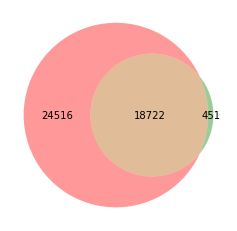

In [42]:
plot_venns(ncbi['symbol'],ag.values)

In [58]:

echo(ag[ag.str.startswith('UGT')])


17761     UGT2A1
17762     UGT2A3
17763     UGT2B4
17764     UGT2B7
17765    UGT2B10
17766    UGT2B11
17767    UGT2B15
17768    UGT2B17
17769    UGT2B28
17770     UGT3A1
17771     UGT3A2
17772       UGT8
Name: symbol, dtype: object

In [43]:
x = set(ag) & set(ncbi['symbol'])


In [45]:
gc = ncbi[ncbi['symbol'].isin(x)].drop_index()
gc

,hgnc_id,symbol,name,locus_group,locus_type,status,location,location_sortable,alias_symbol,alias_name,prev_symbol,prev_name,gene_group,gene_group_id,date_approved_reserved,date_symbol_changed,date_name_changed,date_modified,entrez_id,ensembl_gene_id,vega_id,ucsc_id,ena,refseq_accession,ccds_id,...,lsdb,cosmic,omim_id,mirbase,homeodb,snornabase,bioparadigms_slc,orphanet,pseudogene.org,horde_id,merops,imgt,iuphar,kznf_gene_catalog,mamit-trnadb,cd,lncrnadb,enzyme_id,intermediate_filament_db,rna_central_ids,lncipedia,gtrnadb,agr,mane_select,gencc
0,HGNC:5,A1BG,alpha-1-B glycoprotein,protein-coding gene,gene with protein product,Approved,19q13.43,19q13.43,NaN,NaN,NaN,NaN,Immunoglobulin like domain containing,594,1989-06-30,NaN,NaN,2020-09-17,1.0,ENSG00000121410,OTTHUMG00000183507,uc002qsd.5,NaN,NM_130786,CCDS12976,...,NaN,NaN,138670,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I43.950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:5,ENST00000263100.8|NM_130786.4,NaN
1,HGNC:24086,A1CF,APOBEC1 complementation factor,protein-coding gene,gene with protein product,Approved,10q11.23,10q11.23,ACF|ASP|ACF64|ACF65|APOBEC1CF,NaN,NaN,NaN,RNA binding motif containing,725,2007-11-23,NaN,NaN,2016-10-05,29974.0,ENSG00000148584,OTTHUMG00000018240,uc057tgv.1,AF271790,NM_014576,CCDS73133|CCDS7243|CCDS7242|CCDS7241,...,NaN,NaN,618199,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:24086,ENST00000373997.8|NM_014576.4,NaN
2,HGNC:7,A2M,alpha-2-macroglobulin,protein-coding gene,gene with protein product,Approved,12p13.31,12p13.31,FWP007|S863-7|CPAMD5,NaN,NaN,NaN,Alpha-2-macroglobulin family,2148,1986-01-01,NaN,NaN,2021-04-13,2.0,ENSG00000175899,OTTHUMG00000150267,uc001qvk.2,BX647329|X68728|M11313,NM_000014,CCDS44827,...,LRG_591|http://ftp.ebi.ac.uk/pub/databases/lrg...,NaN,103950,NaN,NaN,NaN,NaN,NaN,NaN,NaN,I39.001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:7,ENST00000318602.12|NM_000014.6,HGNC:7
3,HGNC:23336,A2ML1,alpha-2-macroglobulin like 1,protein-coding gene,gene with protein product,Approved,12p13.31,12p13.31,FLJ25179|p170,NaN,CPAMD9,"C3 and PZP-like, alpha-2-macroglobulin domain ...",Alpha-2-macroglobulin family,2148,2005-07-20,2005-09-01,2016-03-07,2018-04-17,144568.0,ENSG00000166535,OTTHUMG00000128499,uc001quz.6,AK057908,NM_144670,CCDS73439|CCDS8596,...,NaN,NaN,610627,NaN,NaN,NaN,NaN,410627.0,NaN,NaN,I39.007,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:23336,ENST00000299698.12|NM_144670.6,HGNC:23336
4,HGNC:30005,A3GALT2,"alpha 1,3-galactosyltransferase 2",protein-coding gene,gene with protein product,Approved,1p35.1,01p35.1,IGBS3S|IGB3S,iGb3 synthase|isoglobotriaosylceramide synthase,A3GALT2P,"alpha 1,3-galactosyltransferase 2, pseudogene",Glycosyltransferase family 6,429,2005-05-06,2013-03-11,2013-03-11,2018-02-08,127550.0,ENSG00000184389,OTTHUMG00000004125,uc031plq.1,NaN,NM_001080438,CCDS60080,...,NaN,NaN,619850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:30005,ENST00000442999.3|NM_001080438.1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18717,HGNC:32058,ZYG11A,"zyg-11 family member A, cell cycle regulator",protein-coding gene,gene with protein product,Approved,1p32.3,01p32.3,ZYG11,NaN,NaN,zyg-11 homolog A (C. elegans),ZYG11 cell cycle regulator family|Armadillo li...,6|1492,2005-07-11,NaN,2012-12-10,2017-07-14,440590.0,ENSG00000203995,OTTHUMG00000008923,uc001cuk.3,NaN,NM_001004339,CCDS44148|CCDS76166,...,NaN,NaN,618675,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HGNC:32058,ENST00000371528.2|NM_001004339.3,NaN
18718,HGNC:25820,ZYG11B,"zyg-11 family member B, cell cycle regulator",protein-coding gene,gene with protein product,Approved,1p32.3,01p32.3,FLJ13456,NaN,ZYG11,zyg-11 homolog (C. elegans)|zyg-11 homolog B (...,ZYG11 cell cycle regulator family|Armadillo li...,6|1492,2005-06-06,2

In [47]:
db.exporting(gc,'gc_genes_info',outputdir='[A_TSF]/',index=False)
db.exporting(ncbi,'ncbi_genes_info',outputdir='[A_TSF]/',index=False)

[02/01 08:24:35] writing 1 file with 18722 lines at 
	[A_TSF]/gc_genes_info.dfx
[02/01 08:24:35] writing 1 file with 43238 lines at 
	[A_TSF]/ncbi_genes_info.dfx


'[A_TSF]/ncbi_genes_info.dfx'

In [59]:
from notebook.auth import passwd

In [61]:
passwd(algorithm='sha1')

Enter password: ········
Verify password: ········


'sha1:14a1894f1cd2:6d278ff545fbcae98e86e66673aee70370eadb0d'